# NV04 – Phân tích hoàn trả và hoàn tiền

### Hướng dẫn đọc và chạy bản bàn giao — 15/11/2026

**Nội dung hiện hành:** NV04.1–5: phân biệt dòng, đơn và cặp sản phẩm; có kết quả hoàn trả/Refund, đối soát và giới hạn nghiệp vụ.

**Đọc nhanh để trình bày:** **Đơn, dòng returns và khóa liên kết** — ô 1, ID `nv041-01`; **Refund và đối soát tài chính** — ô 25, ID `nv042-01`; **Lý do, quantity và sản phẩm hoàn trả** — ô 50, ID `nv043-01`; **Thời gian và phạm vi cuối kỳ** — ô 75, ID `nv044-01`; **Kết luận hoàn trả và hoàn tiền** — ô 104, ID `nv045-01`. Có thể dùng mục lục của Jupyter/VS Code để đến tiêu đề tương ứng; mọi bảng/hình/kết luận cần thiết đã nằm trong notebook. Chi tiết kiểm toán dài được giữ để truy vết, không cần trình chiếu toàn bộ. Đề xuất liên nghiệp vụ và KPI đánh giá xem [TH01.5](TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb#th01-step4-01).

**Chạy lại:** dùng Python ≥3.11, cài `python -m pip install -r requirements.txt` từ project root; trong VS Code/Jupyter chọn kernel của môi trường đó, rồi **Restart Kernel → Run All**. Chạy NV01→NV06→TH01, không cần biến tạo tay. Mở từ project root hoặc `notebook/04_phan_tich_kinh_doanh/`; các cell tự tìm root qua thư mục cha. Không lưu đè output lịch sử khi chỉ kiểm chứng; chạy trên bản sao ngoài repository nếu cần lưu lượt mới. Chưa chứng nhận cài đặt trên môi trường sạch hoặc mọi phiên bản trong khoảng requirements.

**Đầu vào:** CSV gốc, hai bảng tiền xử lý ở data/processed khi phần phân tích cần, và notebook hàm dùng chung.

**Cách đọc phạm vi:** Returns là bản ghi quan sát, chưa là sự kiện vật lý/settlement; ngày trả khác ngày đặt. Refund vượt Payment là nhóm cần chứng từ, không tự là thất thoát. Không coi vắng returns là hoàn tiền được xác nhận bằng0.

**Lịch sử và kiểm chứng hiện tại:** các phát biểu “chưa triển khai” trong phần nối trước mô tả thời điểm của phần đó; ưu tiên phạm vi hiện hành ở đây. Output/execution_count/metadata cũ được bảo toàn. Các mốc lịch sử cần đối chiếu được lưu trong notebook hàm dùng chung.

---

## NV04.1 – Tổng quan dữ liệu hoàn trả và đối chiếu đơn hàng

**Phạm vi hiện tại (đồng bộ 15/11/2026):** NV04.1–NV04.5 đã có: cấu trúc, số lượng/giá trị, nhóm đơn và thời gian ghi nhận returns, tổng hợp. Nguồn returns/orders/payments/order_items và các giới hạn V03 vẫn được giữ.

**Đơn vị quan sát:** dòng returns, đơn hàng và cặp (order_id, product_id) được phân biệt. Tiền ghi bằng **ĐVT** vì chưa xác minh đồng tiền và quy tắc quyết toán. Tỷ lệ luôn ghi mẫu số. Số tham chiếu chỉ dùng để kiểm chứng, kết quả được tính từ CSV; giữ mọi trạng thái và mọi dòng nguồn.

Trình tự: cấu trúc → quy mô → quan hệ khóa/JOIN → đối chiếu trạng thái → refund ghi nhận → ngày ghi nhận → vấn đề và kết luận → kiểm chứng độc lập. Không tính thực thu, không thay đổi dữ liệu hoặc xuất tệp phụ.


### Đồng bộ với tiền xử lý chung GD2 — 15/11/2026

GD2 đã nghiệm thu tại commit `fdff37f`, hợp đồng `2.3.1.3-v1`; 139/139 là số kiểm thử của lần nghiệm thu GD2, không phải số chạy lại trong notebook này. Tham chiếu `docs/gd2/preprocessing_contract.md`, `docs/gd2/handoff.md` và báo cáo `docs/reviews/bai_toan_1_gd2_step2_20261115.md`.

`orders_common`: 646.945 dòng, khóa order_id, 30 cột; `order_items_common`: 714.669 dòng, khóa item_row_id, 19 cột. Đọc bằng `src.preprocessing.delivery.read_processed` và schema tương ứng; `\N` là NULL, ID là chuỗi và tiền là Decimal. Giữ 16 lần lặp thêm của cặp đơn–sản phẩm và cả hai slot mã. Tổng Payment/Refund ở cấp đơn; không cộng tiền cấp đơn sau JOIN nhiều dòng hàng.

Quy ước chung: Gross = quantity × unit_price; Discount là số tiền giảm dòng hàng; Net = Gross − Discount, chưa trừ Refund. Payment và Refund là giá trị ghi nhận, chưa là quyết toán/thực thu. Không có bản ghi Returns thì refund_amount_observed là NULL, không phải xác nhận hoàn bằng 0. COGS kiểm chứng từ danh mục phải tách khỏi sales.COGS; ĐVT tiền nguồn vẫn chưa xác minh. Các điều kiện/phát hiện nghiệp vụ thiếu chứng từ không được đóng chỉ vì GD2 hoàn tất.

Giữ các ledger raw để đối chứng độc lập, các kiểm tra khóa/JOIN và xử lý riêng theo nghiệp vụ. Chưa thay toàn bộ nguồn bằng view chung. Các kết quả đã lưu giúp xem lại phân tích ngay trong notebook. Các ghi chú “chưa triển khai” theo từng lần nối phần ở bên dưới mô tả lịch sử tại thời điểm đó, không thay thế trạng thái hiện tại ở đầu notebook.

Giữ chi tiết returns, khóa cặp, ngày ghi nhận, lý do và ledger đối chứng. Số 0 kỹ thuật do tổng tập rỗng trong ledger cũ chỉ dùng cùng cờ/số dòng Returns; không ánh xạ thành Refund quan sát bằng 0 của view GD2. Bộ lọc returned và hiện diện Returns là hai phạm vi khác nhau; 80 đơn returned thiếu chi tiết vẫn là vấn đề mở.


In [1]:
import sys, csv, hashlib, math
from pathlib import Path
from decimal import Decimal, InvalidOperation
from collections import Counter, defaultdict
from datetime import datetime
from html.parser import HTMLParser
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sys.dont_write_bytecode = True
get_ipython().run_line_magic("matplotlib", "inline")

import os

import sys

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))
from ham_dung_chung import kiem_chung_nguon, read_notebook, stable_digest, notebook_prefix

from ham_dung_chung import read_notebook as load_notebook_for_audit, snapshot_files
TARGET = ROOT / "notebook/04_phan_tich_kinh_doanh/NV04_phan_tich_hoan_tra_hoan_tien.ipynb"
initial_notebook = load_notebook_for_audit(TARGET)
paths = {k: ROOT / f"data/raw/{k}.csv"
         for k in ["returns", "orders", "payments", "order_items"]}
def sha(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
excluded_parts = {".git", "__pycache__", ".ipynb_checkpoints"}
def protected_snapshot():
    return {p.relative_to(ROOT).as_posix(): sha(p) for p in ROOT.rglob("*")
            if p.is_file() and p != TARGET
            and not (set(p.relative_to(ROOT).parts) & excluded_parts)}
protected_before = protected_snapshot()
source_hashes = {k: sha(p) for k, p in paths.items()}
v03 = kiem_chung_nguon('v03')
v02 = kiem_chung_nguon('v02')
nv03 = read_notebook(ROOT / "notebook/04_phan_tich_kinh_doanh/NV03_phan_tich_don_hang.ipynb")
TOL = Decimal(str(v03["tolerance"]))
ZERO = Decimal("0")
table_count = figure_count = 0
def vn(value, digits=0):
    if value is None or pd.isna(value):
        return "—"
    return format(value, f",.{digits}f").replace(",", "_").replace(".", ",").replace("_", ".")
def pct(n, d):
    return 100 * n / d if d else float("nan")
def show(frame, formats=None):
    global table_count
    table_count += 1
    with pd.option_context("display.max_rows", None, "display.max_columns", None,
                           "display.max_colwidth", None):
        display(frame.style.format(formats or {}, na_rep="—").hide(axis="index"))
def plot_done(fig):
    global figure_count
    figure_count += 1
    fig.tight_layout()
    display(fig)
    plt.close(fig)
def note(text):
    display(Markdown(text))
def read_source(name, columns=None):
    return pd.read_csv(paths[name], dtype="string", keep_default_na=False,
                       encoding="utf-8-sig", usecols=columns, low_memory=False,
                       skip_blank_lines=False, on_bad_lines="error")
returns = read_source("returns")
orders = read_source("orders", ["order_id", "order_date", "order_status"])
payments = read_source("payments", ["order_id", "payment_value"])
items = read_source("order_items", ["order_id", "product_id", "quantity", "unit_price", "discount_amount"])
frames = {"returns": returns, "orders": orders, "payments": payments, "order_items": items}
required = {
    "returns": {"return_id", "order_id", "product_id", "return_date", "return_reason",
                "return_quantity", "refund_amount"},
    "orders": {"order_id", "order_date", "order_status"},
    "payments": {"order_id", "payment_value"},
    "order_items": {"order_id", "product_id", "quantity", "unit_price", "discount_amount"}}
assert all(cols <= set(frames[k].columns) for k, cols in required.items())
source_match = all(source_hashes[k] == v03["sources"][k]["sha256"] for k in paths)
show(pd.DataFrame([{"Nguồn": k, "Dòng đọc": len(f), "Trường đọc": ", ".join(f.columns),
                    "SHA-256 khớp V03": source_hashes[k] == v03["sources"][k]["sha256"]}
                   for k, f in frames.items()]), {"Dòng đọc": lambda x: vn(x)})
note(f"Đã đọc lại CSV; hash bốn nguồn {'khớp' if source_match else 'KHÔNG KHỚP'} V03. "
     f"V02: **{v02['status']}**; V03: **{v03['status']}**. "
     "V03 có phát hiện nghiệp vụ cần làm rõ dù kiểm tra kỹ thuật đạt; không diễn giải thành mọi dữ liệu đúng nghiệp vụ.")

Nguồn,Dòng đọc,Trường đọc,SHA-256 khớp V03
returns,39.939,"return_id, order_id, product_id, return_date, return_reason, return_quantity, refund_amount",True
orders,646.945,"order_id, order_date, order_status",True
payments,646.945,"order_id, payment_value",True
order_items,714.669,"order_id, product_id, quantity, unit_price, discount_amount",True


Đã đọc lại CSV; hash bốn nguồn khớp V03. V02: **ok**; V03: **completed_with_findings**. V03 có phát hiện nghiệp vụ cần làm rõ dù kiểm tra kỹ thuật đạt; không diễn giải thành mọi dữ liệu đúng nghiệp vụ.

### NV04.1.1 – Cấu trúc, ý nghĩa trường và điều kiện sử dụng

Đọc các trường dưới dạng chuỗi để giữ nguyên mã và phần thập phân của tiền; kiểu `string` trong bảng là lựa chọn đọc, không phải kiểu gốc được khai báo trong CSV. Tạo các biến số/ngày riêng, không thay dữ liệu nguồn. NULL được nhận diện bằng chuỗi rỗng hoặc ký hiệu thiếu thường gặp, tách khỏi chuỗi không chuyển được và số không hữu hạn.

Một `return_id` duy nhất chỉ xác định một **bản ghi** trong tệp. Chưa có từ điển dữ liệu để khẳng định đó là một yêu cầu, một sự kiện vật lý hay một khoản hoàn tiền đã quyết toán.


In [2]:
MISSING = {"", "null", "none", "na", "n/a", "nan", "<na>"}
def missing_mask(series):
    return series.str.strip().str.lower().isin(MISSING)
def decimal_value(text):
    if str(text).strip().lower() in MISSING:
        return None
    try:
        return Decimal(str(text))
    except InvalidOperation:
        return None
meaning = {
 "return_id": ("Mã bản ghi; ứng viên khóa đơn nếu không NULL/trùng", "Chắc chắn về tính duy nhất trong tệp; chưa rõ sự kiện nghiệp vụ"),
 "order_id": ("Mã đơn để đối chiếu orders", "Quan hệ được kiểm tra bằng tập khóa"),
 "product_id": ("Mã sản phẩm trong dòng; đối chiếu cặp với order_items", "Chưa biết dòng bán/lô hàng cụ thể khi cặp lặp"),
 "return_date": ("Ngày ghi nhận mang tên return_date", "Định dạng kiểm tra được; chưa xác minh mốc tạo/nhận/duyệt/quyết toán"),
 "return_reason": ("Nhãn lý do được ghi nhận", "Không xác minh nguyên nhân thực tế hay tính đầy đủ của nhãn"),
 "return_quantity": ("Số lượng ghi nhận trên dòng", "Chưa xác minh đơn vị vật lý/quy tắc yêu cầu"),
 "refund_amount": ("Giá trị refund ghi trên dòng, đơn vị ĐVT", "Cộng được về số học; chưa xác minh đã chi tiền")}
schema = pd.DataFrame([{"Trường": c, "Kiểu đọc": str(returns[c].dtype),
                       "NULL": int(missing_mask(returns[c]).sum()),
                       "% NULL / dòng returns": pct(int(missing_mask(returns[c]).sum()), len(returns)),
                       "Phân biệt không NULL": returns.loc[~missing_mask(returns[c]), c].nunique(),
                       "Ý nghĩa sơ bộ": meaning.get(c, ("Chưa xác định", ""))[0],
                       "Mức chắc chắn/giới hạn": meaning.get(c, ("", "Cần từ điển"))[1]}
                      for c in returns.columns])
show(schema, {"NULL": lambda x: vn(x), "Phân biệt không NULL": lambda x: vn(x),
              "% NULL / dòng returns": lambda x: vn(x, 2) + "%"})
numeric_values, numeric_rows = {}, []
for name, columns in {"returns": ["return_quantity", "refund_amount"],
                       "payments": ["payment_value"],
                       "order_items": ["quantity", "unit_price", "discount_amount"]}.items():
    for c in columns:
        s = frames[name][c]
        vals = [decimal_value(x) for x in s]
        numeric_values[(name, c)] = vals
        missing = missing_mask(s)
        finite = [x for x in vals if x is not None and x.is_finite()]
        numeric_rows.append({"Nguồn": name, "Trường": c, "Mẫu số dòng": len(s),
            "NULL": int(missing.sum()), "Sai cú pháp": sum(x is None for x in vals) - int(missing.sum()),
            "Không hữu hạn": sum(x is not None and not x.is_finite() for x in vals),
            "Âm": sum(x < 0 for x in finite), "Bằng 0": sum(x == 0 for x in finite),
            "Không nguyên": sum(x != x.to_integral_value() for x in finite),
            "Min": str(min(finite)) if finite else "—",
            "Max": str(max(finite)) if finite else "—"})
numeric_quality = pd.DataFrame(numeric_rows)
show(numeric_quality)
needed_nulls = pd.DataFrame([{"Nguồn": k, "Trường": c, "NULL": int(missing_mask(f[c]).sum()),
                              "Mẫu số dòng": len(f)}
                             for k, f in frames.items() for c in f.columns])
show(needed_nulls.loc[(needed_nulls["Nguồn"] != "returns")].reset_index(drop=True))
assert numeric_quality[["NULL", "Sai cú pháp", "Không hữu hạn"]].to_numpy().sum() == 0, "Dừng: không cộng thiếu/không hữu hạn."
assert needed_nulls["NULL"].sum() == 0, "Dừng: trường cần dùng có NULL; cần xử lý minh bạch."
refund = pd.Series(numeric_values[("returns", "refund_amount")], index=returns.index, dtype=object)
item_net = pd.Series([q * u - d for q, u, d in zip(
    numeric_values[("order_items", "quantity")], numeric_values[("order_items", "unit_price")],
    numeric_values[("order_items", "discount_amount")])], index=items.index, dtype=object)
payment = pd.Series(numeric_values[("payments", "payment_value")], index=payments.index, dtype=object)
note(f"**Quan sát:** returns có **{vn(len(returns))} dòng × {len(returns.columns)} trường**, "
     f"{vn(int(schema['NULL'].sum()))} ô NULL; "
     f"{vn(int(numeric_quality.loc[numeric_quality['Nguồn'].eq('returns'), ['Âm', 'Bằng 0']].to_numpy().sum()))} "
     "giá trị âm/bằng 0 ở hai trường số. Các trường cần dùng đều chuyển đổi được và hữu hạn. "
     "**Ý nghĩa:** đủ điều kiện tính quy mô và tổng tiền ghi nhận. "
     "**Giới hạn/câu hỏi:** ai định nghĩa bản ghi, đơn vị số lượng và trạng thái quyết toán của refund_amount?")

Trường,Kiểu đọc,NULL,% NULL / dòng returns,Phân biệt không NULL,Ý nghĩa sơ bộ,Mức chắc chắn/giới hạn
return_id,string,0,"0,00%",39.939,Mã bản ghi; ứng viên khóa đơn nếu không NULL/trùng,Chắc chắn về tính duy nhất trong tệp; chưa rõ sự kiện nghiệp vụ
order_id,string,0,"0,00%",36.062,Mã đơn để đối chiếu orders,Quan hệ được kiểm tra bằng tập khóa
product_id,string,0,"0,00%",1.286,Mã sản phẩm trong dòng; đối chiếu cặp với order_items,Chưa biết dòng bán/lô hàng cụ thể khi cặp lặp
return_date,string,0,"0,00%",3.806,Ngày ghi nhận mang tên return_date,Định dạng kiểm tra được; chưa xác minh mốc tạo/nhận/duyệt/quyết toán
return_reason,string,0,"0,00%",5,Nhãn lý do được ghi nhận,Không xác minh nguyên nhân thực tế hay tính đầy đủ của nhãn
return_quantity,string,0,"0,00%",8,Số lượng ghi nhận trên dòng,Chưa xác minh đơn vị vật lý/quy tắc yêu cầu
refund_amount,string,0,"0,00%",39.560,"Giá trị refund ghi trên dòng, đơn vị ĐVT",Cộng được về số học; chưa xác minh đã chi tiền


Nguồn,Trường,Mẫu số dòng,NULL,Sai cú pháp,Không hữu hạn,Âm,Bằng 0,Không nguyên,Min,Max
returns,return_quantity,39939,0,0,0,0,0,0,1,8
returns,refund_amount,39939,0,0,0,0,0,39536,458.81,160937.94
payments,payment_value,646945,0,0,0,0,0,634579,389.74,331570.4
order_items,quantity,714669,0,0,0,0,0,0,1,8
order_items,unit_price,714669,0,0,0,0,0,707500,392.57,43056.0
order_items,discount_amount,714669,0,0,0,0,438353,252656,0.0,35235.47


Nguồn,Trường,NULL,Mẫu số dòng
orders,order_id,0,646945
orders,order_date,0,646945
orders,order_status,0,646945
payments,order_id,0,646945
payments,payment_value,0,646945
order_items,order_id,0,714669
order_items,product_id,0,714669
order_items,quantity,0,714669
order_items,unit_price,0,714669
order_items,discount_amount,0,714669


**Quan sát:** returns có **39.939 dòng × 7 trường**, 0 ô NULL; 0 giá trị âm/bằng 0 ở hai trường số. Các trường cần dùng đều chuyển đổi được và hữu hạn. **Ý nghĩa:** đủ điều kiện tính quy mô và tổng tiền ghi nhận. **Giới hạn/câu hỏi:** ai định nghĩa bản ghi, đơn vị số lượng và trạng thái quyết toán của refund_amount?

### NV04.1.2 – Quy mô và phân bố số dòng returns trên đơn

Mẫu số tỷ lệ có returns là **toàn bộ đơn trong orders**; mẫu số tỷ lệ một/nhiều dòng là **các đơn có returns**. Phân bố dùng đúng số dòng quan sát 1, 2, 3… chứ không gộp thành số lần trả hàng thực tế.

Chỉ xếp hạng theo số dòng, giảm dần; nếu bằng nhau, sắp mã đơn dạng chuỗi tăng dần để kết quả tái lập. Bảng minh họa tối đa 10 đơn, đồng thời công bố tổng số đơn đạt cực đại.


Chỉ tiêu,Giá trị,Mẫu số/đơn vị
Tổng đơn trong orders,646.945,Đơn
Tổng dòng returns,39.939,Dòng
order_id phân biệt trong returns,36.062,Mã đơn (gồm mồ côi nếu có)
Đơn có returns,36.062,"5,574% / toàn bộ đơn"
Đơn không có returns,610.883,"94,426% / toàn bộ đơn"
Dòng returns bình quân/đơn có returns,"1,1075",Dòng/đơn có returns
Đơn có nhiều dòng,3.801,"10,54% / đơn có returns"
Số dòng lớn nhất/đơn; số đơn đồng hạng,3; 76,Dòng/đơn; đơn


Dòng returns/đơn,Số đơn,Dòng returns được bảo toàn,% đơn có returns
1,32.261,32.261,"89,46%"
2,3.725,7.450,"10,33%"
3,76,228,"0,21%"


order_id,Dòng returns
122874,3
128731,3
135132,3
143235,3
145681,3
161383,3
162989,3
165230,3
179217,3
182324,3


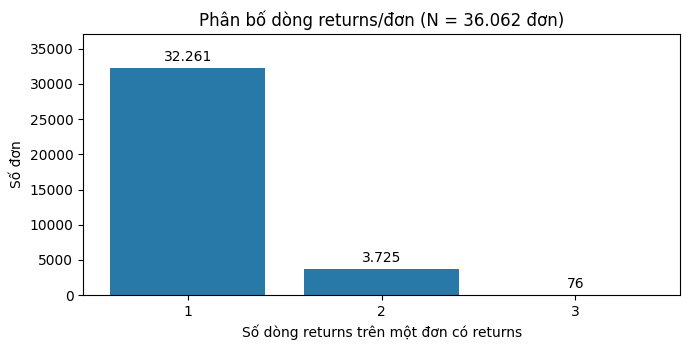

**Quan sát:** 36.062/646.945 đơn (5,574%) xuất hiện trong returns; 32.261 đơn có một dòng; 3.801 đơn có nhiều dòng; tối đa 3 dòng ở 76 đơn. **Nhận xét có căn cứ:** số dòng lớn hơn số đơn, nên đếm dòng như đếm đơn sẽ phóng đại quy mô đơn liên quan. **Giới hạn/câu hỏi:** tỷ lệ này mô tả sự hiện diện trong tệp, chưa phải hoàn trả thành công; các dòng có phải nhiều sản phẩm hay nhiều lần xử lý cùng đơn cần từ điển và nhật ký để xác minh.

In [3]:
return_counts = returns.groupby("order_id", sort=True).size().rename("n_return_rows")
order_ids = set(orders["order_id"])
return_order_ids = set(return_counts.index)
n_orders, n_returns, n_return_orders = len(orders), len(returns), len(return_counts)
orphan_order_ids = return_order_ids - order_ids
n_has = len(return_order_ids & order_ids)
n_without = len(order_ids - return_order_ids)
distribution = return_counts.value_counts().sort_index().rename_axis("Dòng returns/đơn").reset_index(name="Số đơn")
distribution["Dòng returns được bảo toàn"] = distribution["Dòng returns/đơn"] * distribution["Số đơn"]
distribution["% đơn có returns"] = distribution["Số đơn"].map(lambda n: pct(n, n_return_orders))
max_rows = int(return_counts.max())
n_at_max = int(return_counts.eq(max_rows).sum())
scale = pd.DataFrame([
 {"Chỉ tiêu": "Tổng đơn trong orders", "Giá trị": vn(n_orders), "Mẫu số/đơn vị": "Đơn"},
 {"Chỉ tiêu": "Tổng dòng returns", "Giá trị": vn(n_returns), "Mẫu số/đơn vị": "Dòng"},
 {"Chỉ tiêu": "order_id phân biệt trong returns", "Giá trị": vn(n_return_orders), "Mẫu số/đơn vị": "Mã đơn (gồm mồ côi nếu có)"},
 {"Chỉ tiêu": "Đơn có returns", "Giá trị": vn(n_has), "Mẫu số/đơn vị": f"{vn(pct(n_has, n_orders), 3)}% / toàn bộ đơn"},
 {"Chỉ tiêu": "Đơn không có returns", "Giá trị": vn(n_without), "Mẫu số/đơn vị": f"{vn(pct(n_without, n_orders), 3)}% / toàn bộ đơn"},
 {"Chỉ tiêu": "Dòng returns bình quân/đơn có returns", "Giá trị": vn(n_returns / n_return_orders, 4), "Mẫu số/đơn vị": "Dòng/đơn có returns"},
 {"Chỉ tiêu": "Đơn có nhiều dòng", "Giá trị": vn(int(return_counts.gt(1).sum())), "Mẫu số/đơn vị": f"{vn(pct(int(return_counts.gt(1).sum()), n_return_orders), 2)}% / đơn có returns"},
 {"Chỉ tiêu": "Số dòng lớn nhất/đơn; số đơn đồng hạng", "Giá trị": f"{max_rows}; {vn(n_at_max)}", "Mẫu số/đơn vị": "Dòng/đơn; đơn"}])
show(scale)
show(distribution, {"Số đơn": lambda x: vn(x), "Dòng returns được bảo toàn": lambda x: vn(x),
                    "% đơn có returns": lambda x: vn(x, 2) + "%"})
examples = return_counts.reset_index().sort_values(["n_return_rows", "order_id"], ascending=[False, True]).head(10)
show(examples.rename(columns={"n_return_rows": "Dòng returns"}))
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(distribution["Dòng returns/đơn"].astype(str), distribution["Số đơn"], color="#2979a8")
ax.bar_label(bars, labels=[vn(x) for x in distribution["Số đơn"]], padding=3)
ax.set(xlabel="Số dòng returns trên một đơn có returns", ylabel="Số đơn",
       title=f"Phân bố dòng returns/đơn (N = {vn(n_return_orders)} đơn)")
ax.set_ylim(0, distribution["Số đơn"].max() * 1.15)
plot_done(fig)
note(f"**Quan sát:** {vn(n_has)}/{vn(n_orders)} đơn ({vn(pct(n_has, n_orders), 3)}%) xuất hiện trong returns; "
     f"{vn(int(return_counts.eq(1).sum()))} đơn có một dòng; {vn(int(return_counts.gt(1).sum()))} đơn có nhiều dòng; "
     f"tối đa {max_rows} dòng ở {vn(n_at_max)} đơn. "
     "**Nhận xét có căn cứ:** số dòng lớn hơn số đơn, nên đếm dòng như đếm đơn sẽ phóng đại quy mô đơn liên quan. "
     "**Giới hạn/câu hỏi:** tỷ lệ này mô tả sự hiện diện trong tệp, chưa phải hoàn trả thành công; "
     "các dòng có phải nhiều sản phẩm hay nhiều lần xử lý cùng đơn cần từ điển và nhật ký để xác minh.")

### NV04.1.3 – Chứng minh quan hệ khóa trước JOIN

Kiểm tra khóa định danh, dòng trùng hoàn toàn và cặp chi tiết `(order_id, product_id)`. Cặp lặp chưa chứng minh trùng nghiệp vụ; không xóa dòng. Với order_items, số dòng trên cùng cặp cũng được kiểm tra.

Quy trình an toàn: tổng hợp returns về một dòng/đơn, tổng hợp items về Net/đơn, xác minh payments một dòng/đơn, rồi LEFT JOIN từ orders với `validate="one_to_one"`. Quan hệ sản phẩm được đối chiếu giữa **hai bảng đã đếm theo cặp**, không JOIN chi tiết nhiều–nhiều. Net = Σ(quantity × unit_price − discount_amount); chỉ dùng để chứng minh bảo toàn số học, giữ mọi trạng thái.


In [4]:
keys = []
for name, f, cols in [
 ("orders", orders, ["order_id"]), ("returns", returns, ["return_id"]),
 ("payments", payments, ["order_id"]),
 ("returns", returns, ["order_id", "product_id"]),
 ("order_items", items, ["order_id", "product_id"])]:
    keys.append({"Nguồn": name, "Khóa kiểm tra": " + ".join(cols), "Mẫu số dòng": len(f),
        "NULL khóa": int(f[cols].apply(missing_mask).any(axis=1).sum()),
        "Dòng dư do lặp khóa": int(f.duplicated(cols).sum()),
        "Mọi dòng thuộc khóa lặp": int(f.duplicated(cols, keep=False).sum()),
        "Trùng toàn dòng dư": int(f.duplicated().sum()) if name == "returns" else "—"})
key_table = pd.DataFrame(keys)
show(key_table)
orphan_counts = {name: int((~frames[name]["order_id"].isin(order_ids)).sum())
                 for name in ["returns", "order_items", "payments"]}
r_pairs = returns.groupby(["order_id", "product_id"], sort=True).size().rename("return_rows").reset_index()
i_pairs = items.groupby(["order_id", "product_id"], sort=True).size().rename("item_rows").reset_index()
pair_link = r_pairs.merge(i_pairs, on=["order_id", "product_id"], how="left",
                          validate="one_to_one", indicator=True)
pair_orphans = int(pair_link["_merge"].eq("left_only").sum())
repeated_pairs = pair_link.loc[pair_link["return_rows"].gt(1) | pair_link["item_rows"].gt(1)]
show(pd.DataFrame([{"Quan hệ": f"{k} → orders", "Dòng mồ côi": n, "Mẫu số dòng": len(frames[k])}
                   for k, n in orphan_counts.items()] +
                 [{"Quan hệ": "Cặp returns → cặp order_items", "Dòng mồ côi": pair_orphans,
                   "Mẫu số dòng": len(r_pairs)}]))
show(repeated_pairs.drop(columns="_merge").rename(columns={"return_rows": "Dòng returns/cặp", "item_rows": "Dòng items/cặp"}))
assert orders["order_id"].is_unique and payments["order_id"].is_unique
assert returns["return_id"].is_unique and not any(orphan_counts.values()) and pair_orphans == 0
return_by_order = returns[["order_id"]].assign(refund=refund).groupby("order_id", sort=True).agg(
    refund=("refund", "sum"), n_refund_records=("refund", "count"))
return_by_order = return_by_order.join(return_counts)
net_by_order = items[["order_id"]].assign(Net=item_net).groupby("order_id", sort=True)["Net"].sum()
payment_by_order = payments[["order_id"]].assign(Payment=payment)
base_orders = orders.merge(net_by_order, on="order_id", how="left", validate="one_to_one")
base_orders = base_orders.merge(payment_by_order, on="order_id", how="left", validate="one_to_one")
order_ledger = base_orders.merge(return_by_order, on="order_id", how="left", validate="one_to_one")
order_ledger["has_returns"] = order_ledger["n_return_rows"].notna()
order_ledger["n_return_rows"] = order_ledger["n_return_rows"].fillna(0).astype("int64")
# refund của đơn không có dòng vẫn thiếu, không gán thành tiền đã hoàn bằng 0.
net_before = sum(base_orders["Net"], ZERO)
net_after = sum(order_ledger["Net"], ZERO)
show(pd.DataFrame([
 {"Chỉ tiêu bảo toàn": "Đơn", "Trước JOIN": vn(len(base_orders)), "Sau JOIN": vn(len(order_ledger)), "Chênh lệch": vn(len(order_ledger)-len(base_orders))},
 {"Chỉ tiêu bảo toàn": "Net, ĐVT", "Trước JOIN": vn(net_before, 2), "Sau JOIN": vn(net_after, 2), "Chênh lệch": vn(net_after-net_before, 2)},
 {"Chỉ tiêu bảo toàn": "Tổng dòng returns", "Trước JOIN": vn(n_returns), "Sau JOIN": vn(order_ledger["n_return_rows"].sum()), "Chênh lệch": vn(order_ledger["n_return_rows"].sum()-n_returns)}]))
note(f"**Quan sát:** {vn(orphan_counts['returns'])}/{vn(n_returns)} dòng returns mồ côi; "
     f"{vn(int(returns.duplicated().sum()))} dòng trùng hoàn toàn và {vn(int(returns.duplicated('return_id').sum()))} mã return_id lặp. "
     f"Có {vn(int(r_pairs['return_rows'].gt(1).sum()))} cặp returns lặp; "
     f"{vn(int(i_pairs['item_rows'].gt(1).sum()))} cặp items lặp. "
     f"JOIN cấp đơn giữ {vn(len(order_ledger))} đơn và Net {vn(net_after, 2)} ĐVT. "
     "**Ý nghĩa:** quan hệ khóa đủ cho đối chiếu cấp đơn trong bốn tệp. "
     "**Giới hạn/câu hỏi:** cặp đơn–sản phẩm không là khóa duy nhất của dòng; cần khóa dòng bán/lần xử lý để giải thích cặp lặp, chưa có cơ sở khử trùng.")

Nguồn,Khóa kiểm tra,Mẫu số dòng,NULL khóa,Dòng dư do lặp khóa,Mọi dòng thuộc khóa lặp,Trùng toàn dòng dư
orders,order_id,646945,0,0,0,—
returns,return_id,39939,0,0,0,0
payments,order_id,646945,0,0,0,—
returns,order_id + product_id,39939,0,2,4,0
order_items,order_id + product_id,714669,0,16,32,—


Quan hệ,Dòng mồ côi,Mẫu số dòng
returns → orders,0,39939
order_items → orders,0,714669
payments → orders,0,646945
Cặp returns → cặp order_items,0,39937


order_id,product_id,Dòng returns/cặp,Dòng items/cặp
397622,2045,2,2
698128,1009,2,2


Chỉ tiêu bảo toàn,Trước JOIN,Sau JOIN,Chênh lệch
Đơn,646.945,646.945,0
"Net, ĐVT","15.680.869.265,43","15.680.869.265,43","0,00"
Tổng dòng returns,39.939,39.939,0


**Quan sát:** 0/39.939 dòng returns mồ côi; 0 dòng trùng hoàn toàn và 0 mã return_id lặp. Có 2 cặp returns lặp; 16 cặp items lặp. JOIN cấp đơn giữ 646.945 đơn và Net 15.680.869.265,43 ĐVT. **Ý nghĩa:** quan hệ khóa đủ cho đối chiếu cấp đơn trong bốn tệp. **Giới hạn/câu hỏi:** cặp đơn–sản phẩm không là khóa duy nhất của dòng; cần khóa dòng bán/lần xử lý để giải thích cặp lặp, chưa có cơ sở khử trùng.

### NV04.1.4 – Trạng thái đơn và sự hiện diện trong returns

Lập các tập mã thực tế: A = returned ∩ có returns; B = returned ∖ có returns; C = có returns ∖ returned. Không suy giao từ hiệu hai tổng. Bảng trạng thái giữ mọi đơn; tỷ lệ từng hàng có mẫu số là số đơn của chính trạng thái đó.

Đối chiếu với **bảng output đã lưu trong NV03**, không chạy lại hoặc chỉnh NV03. Nhãn trạng thái là ảnh chụp một giá trị/đơn, chưa phải lịch sử chuyển trạng thái.


In [5]:
status = order_ledger.groupby("order_status", sort=True).agg(
    total=("order_id", "size"), with_returns=("has_returns", "sum"),
    return_rows=("n_return_rows", "sum"))
status["without_returns"] = status["total"] - status["with_returns"]
status["pct_within_status"] = 100 * status["with_returns"] / status["total"]
returned_ids = set(orders.loc[orders["order_status"].eq("returned"), "order_id"])
set_A = returned_ids & return_order_ids
set_B = returned_ids - return_order_ids
set_C = return_order_ids - returned_ids
show(status.reset_index()[["order_status", "total", "with_returns", "without_returns",
                          "pct_within_status", "return_rows"]].rename(columns={
 "total": "Tổng đơn", "with_returns": "Đơn có returns", "without_returns": "Đơn không có returns",
 "pct_within_status": "% có returns / đơn cùng trạng thái", "return_rows": "Dòng returns"}),
 {"Tổng đơn": lambda x: vn(x), "Đơn có returns": lambda x: vn(x), "Đơn không có returns": lambda x: vn(x),
  "Dòng returns": lambda x: vn(x), "% có returns / đơn cùng trạng thái": lambda x: vn(x, 3) + "%"})
sets_table = pd.DataFrame([
 {"Tập": "A: returned và có returns", "Số đơn": len(set_A), "Mẫu số": len(returned_ids),
  "% / mẫu số": pct(len(set_A), len(returned_ids))},
 {"Tập": "B: returned không có returns", "Số đơn": len(set_B), "Mẫu số": len(returned_ids),
  "% / mẫu số": pct(len(set_B), len(returned_ids))},
 {"Tập": "C: có returns, không returned", "Số đơn": len(set_C), "Mẫu số": n_return_orders,
  "% / mẫu số": pct(len(set_C), n_return_orders)}])
show(sets_table, {"Số đơn": lambda x: vn(x), "Mẫu số": lambda x: vn(x), "% / mẫu số": lambda x: vn(x, 3) + "%"})
class TableRows(HTMLParser):
    def __init__(self):
        super().__init__()
        self.rows, self.row, self.cell = [], None, None
    def handle_starttag(self, tag, attrs):
        if tag == "tr": self.row = []
        if tag in ("td", "th"): self.cell = []
    def handle_data(self, data):
        if self.cell is not None: self.cell.append(data)
    def handle_endtag(self, tag):
        if tag in ("td", "th") and self.cell is not None:
            if self.row is not None: self.row.append("".join(self.cell).strip())
            self.cell = None
        if tag == "tr" and self.row is not None:
            self.rows.append(self.row)
            self.row = None
def saved_table(headers):
    hits = []
    for cell_index, cell in enumerate(nv03["cells"]):
        for output in cell.get("outputs", []):
            html = output.get("data", {}).get("text/html", "")
            if isinstance(html, list): html = "".join(html)
            parser = TableRows()
            parser.feed(html)
            for j, row in enumerate(parser.rows):
                if set(headers) <= set(row):
                    hits.append((cell_index + 1, row, parser.rows[j+1:]))
    assert len(hits) == 1, f"Không xác định duy nhất bảng NV03: {headers}; số bảng {len(hits)}"
    return hits[0]
nv03_status_cell, headers_status, rows_status = saved_table(["Trạng thái", "CSV hiện tại", "NV02.1 output", "Sai lệch"])
nv03_status = {r[headers_status.index("Trạng thái")]: int(r[headers_status.index("CSV hiện tại")])
               for r in rows_status}
status_compare = status[["total"]].rename(columns={"total": "CSV hiện tại"})
status_compare["NV03 đã lưu"] = pd.Series(nv03_status)
status_compare["Sai lệch"] = status_compare["CSV hiện tại"] - status_compare["NV03 đã lưu"]
show(status_compare.reset_index())
note(f"**Quan sát:** A={vn(len(set_A))}, B={vn(len(set_B))}, C={vn(len(set_C))} đơn. "
     f"Có returns bao phủ {vn(pct(len(set_A), len(returned_ids)), 3)}% nhãn returned; "
     f"còn {vn(len(set_B))} đơn chưa có dòng đối ứng. "
     f"Sáu nhãn và số đơn khớp bảng NV03 tại ô {nv03_status_cell} (đếm từ 1). "
     "**Ý nghĩa:** nhãn returned và sự hiện diện trong returns chưa tương ứng hoàn toàn. "
     "**Giới hạn/câu hỏi:** B chưa chứng minh mất dữ liệu; cần quy tắc tạo dòng, cập nhật nhãn và thời điểm chốt từng bảng.")

order_status,Tổng đơn,Đơn có returns,Đơn không có returns,% có returns / đơn cùng trạng thái,Dòng returns
cancelled,59.462,0,59.462,"0,000%",0
created,7.275,0,7.275,"0,000%",0
delivered,516.716,0,516.716,"0,000%",0
paid,13.577,0,13.577,"0,000%",0
returned,36.142,36.062,80,"99,779%",39.939
shipped,13.773,0,13.773,"0,000%",0


Tập,Số đơn,Mẫu số,% / mẫu số
A: returned và có returns,36.062,36.142,"99,779%"
B: returned không có returns,80,36.142,"0,221%"
"C: có returns, không returned",0,36.062,"0,000%"


order_status,CSV hiện tại,NV03 đã lưu,Sai lệch
cancelled,59462,59462,0
created,7275,7275,0
delivered,516716,516716,0
paid,13577,13577,0
returned,36142,36142,0
shipped,13773,13773,0


**Quan sát:** A=36.062, B=80, C=0 đơn. Có returns bao phủ 99,779% nhãn returned; còn 80 đơn chưa có dòng đối ứng. Sáu nhãn và số đơn khớp bảng NV03 tại ô 6 (đếm từ 1). **Ý nghĩa:** nhãn returned và sự hiện diện trong returns chưa tương ứng hoàn toàn. **Giới hạn/câu hỏi:** B chưa chứng minh mất dữ liệu; cần quy tắc tạo dòng, cập nhật nhãn và thời điểm chốt từng bảng.

### NV04.1.5 – Refund ghi nhận: cấp dòng và cấp đơn

Cộng `refund_amount` bằng Decimal từ chuỗi gốc, không làm tròn giữa các bước. Phân vị nội suy tuyến tính tại vị trí (n−1)×q; bảng tiền hiển thị 2 chữ số thập phân nên các phân vị có thể được làm tròn khi hiển thị.

Bảng thống kê tách **dòng returns** và **đơn có returns**. Đơn không có dòng giữ refund thiếu, không tự gán thành một khoản hoàn bằng 0. Ngưỡng IQR chỉ gắn cờ giá trị đặc biệt để mô tả hồi cứu; không là quy tắc phát hiện sai dữ liệu hay chính sách hoàn tiền.

Kiểm tra tổng Refund/đơn > Payment/đơn + 0,05 ĐVT chỉ xác nhận số trường hợp cần bàn giao NV04.2; không phân tích sâu, không điều chỉnh, không tính Payment − Refund thành thực thu.


In [6]:
def quantile_decimal(values, q):
    values = sorted(values)
    position = Decimal(len(values) - 1) * Decimal(str(q))
    lo = int(position)
    hi = min(lo + 1, len(values) - 1)
    return values[lo] + (values[hi] - values[lo]) * (position - lo)
refund_total = sum(refund, ZERO)
refund_order_total = sum(return_by_order["refund"], ZERO)
refund_stats = []
for label, values in [("Dòng returns", list(refund)),
                      ("Đơn có returns", list(return_by_order["refund"]))]:
    refund_stats.append({"Cấp quan sát": label, "N": len(values), "Tổng (ĐVT)": sum(values, ZERO),
        "Min (ĐVT)": min(values), "Max (ĐVT)": max(values),
        "Mean (ĐVT)": sum(values, ZERO) / len(values),
        "Median (ĐVT)": quantile_decimal(values, .5),
        **{f"P{int(q*100)} (ĐVT)": quantile_decimal(values, q) for q in [.25, .75, .9, .95, .99]}})
refund_statistics = pd.DataFrame(refund_stats)
show(refund_statistics, {c: (lambda x: vn(x, 2)) for c in refund_statistics if c.endswith("(ĐVT)")})
q1, q3 = quantile_decimal(refund, .25), quantile_decimal(refund, .75)
lower, upper = q1 - Decimal("1.5") * (q3 - q1), q3 + Decimal("1.5") * (q3 - q1)
extreme_mask = refund.map(lambda x: x < lower or x > upper)
min_refund, max_refund = min(refund), max(refund)
refund_valid_count = len(refund)
multiple_refund_orders = int(return_by_order["n_refund_records"].gt(1).sum())
affected = order_ledger.loc[order_ledger["has_returns"]].copy()
over_payment = affected["refund"] - affected["Payment"] > TOL
n_over_payment = int(over_payment.sum())
show(pd.DataFrame([
 {"Kiểm tra": "Dòng có refund hữu hạn", "Số lượng": refund_valid_count, "Mẫu số": n_returns},
 {"Kiểm tra": "Dòng thiếu refund", "Số lượng": int(missing_mask(returns["refund_amount"]).sum()), "Mẫu số": n_returns},
 {"Kiểm tra": "Dòng refund âm", "Số lượng": int(refund.lt(0).sum()), "Mẫu số": n_returns},
 {"Kiểm tra": "Dòng refund bằng 0", "Số lượng": int(refund.eq(0).sum()), "Mẫu số": n_returns},
 {"Kiểm tra": "Đơn có nhiều bản ghi refund", "Số lượng": multiple_refund_orders, "Mẫu số": n_return_orders},
 {"Kiểm tra": "Dòng ngoài hàng rào IQR 1,5", "Số lượng": int(extreme_mask.sum()), "Mẫu số": n_returns},
 {"Kiểm tra": "Đơn Refund > Payment + dung sai", "Số lượng": n_over_payment, "Mẫu số": len(affected)}]),
 {"Số lượng": lambda x: vn(x), "Mẫu số": lambda x: vn(x)})
show(returns.loc[refund.eq(min_refund) | refund.eq(max_refund),
                 ["return_id", "order_id", "refund_amount"]].assign(
    refund_amount=refund[refund.eq(min_refund) | refund.eq(max_refund)]).rename(
    columns={"refund_amount": "Refund cực trị (ĐVT)"}), {"Refund cực trị (ĐVT)": lambda x: vn(x, 2)})
nv03_money_cell, money_headers, money_rows = saved_table(["Chỉ tiêu", "Tính từ CSV (ĐVT)", "V02 (ĐVT)", "Sai lệch (ĐVT)"])
nv03_money = {r[money_headers.index("Chỉ tiêu")]:
              Decimal(r[money_headers.index("Tính từ CSV (ĐVT)")].replace(".", "").replace(",", "."))
              for r in money_rows}
money_actual = {
 "gross": sum((q*u for q,u in zip(numeric_values[("order_items","quantity")],
                                 numeric_values[("order_items","unit_price")])), ZERO),
 "discount": sum(numeric_values[("order_items","discount_amount")], ZERO),
 "net": net_before, "payment": sum(payment, ZERO)}
show(pd.DataFrame([{"Chỉ tiêu": k, "CSV (ĐVT)": value, "NV03 đã lưu (ĐVT)": nv03_money[k],
                    "Sai lệch (ĐVT)": value - nv03_money[k]} for k, value in money_actual.items()]),
 {c: lambda x: vn(x, 2) for c in ["CSV (ĐVT)", "NV03 đã lưu (ĐVT)", "Sai lệch (ĐVT)"]})
note(f"**Quan sát:** tổng refund dòng và tổng refund đơn đều **{vn(refund_total, 2)} ĐVT**; "
     f"mean dòng {vn(refund_statistics.iloc[0]['Mean (ĐVT)'], 2)} lớn hơn median "
     f"{vn(refund_statistics.iloc[0]['Median (ĐVT)'], 2)} ĐVT, phù hợp phân bố lệch phải. "
     f"Ngưỡng IQR [{vn(lower, 3)}; {vn(upper, 3)}] ĐVT gắn cờ {vn(int(extreme_mask.sum()))}/{vn(n_returns)} dòng; giữ nguyên tất cả. "
     f"Có {vn(n_over_payment)}/{vn(len(affected))} đơn ({vn(pct(n_over_payment, len(affected)), 2)}%) "
     f"Refund > Payment hơn {vn(TOL, 2)} ĐVT, đối chiếu V03 ở phần kiểm chứng. "
     "**Ý nghĩa:** đủ tính tiền refund đã ghi và đối soát số học với Net/Payment; "
     "**giới hạn/câu hỏi:** chưa có chứng từ, mốc quyết toán, định nghĩa phạm vi tiền/phí/đồng tiền để xác định tiền đã hoàn hoặc thực thu. "
     "Sự chênh lệch chưa chứng minh lỗi; chuyển kiểm tra chi tiết sang NV04.2.")

Cấp quan sát,N,Tổng (ĐVT),Min (ĐVT),Max (ĐVT),Mean (ĐVT),Median (ĐVT),P25 (ĐVT),P75 (ĐVT),P90 (ĐVT),P95 (ĐVT),P99 (ĐVT)
Dòng returns,39939,"510.598.506,55","458,81","160.937,94","12.784,46","7.888,88","3.573,40","16.881,99","30.910,35","42.095,65","66.677,28"
Đơn có returns,36062,"510.598.506,55","478,76","170.631,32","14.158,91","9.201,86","4.368,62","18.868,25","33.028,40","44.139,22","68.941,25"


Kiểm tra,Số lượng,Mẫu số
Dòng có refund hữu hạn,39.939,39.939
Dòng thiếu refund,0,39.939
Dòng refund âm,0,39.939
Dòng refund bằng 0,0,39.939
Đơn có nhiều bản ghi refund,3.801,36.062
"Dòng ngoài hàng rào IQR 1,5",2.778,39.939
Đơn Refund > Payment + dung sai,3.640,36.062


return_id,order_id,Refund cực trị (ĐVT)
RET-029493,466061,"160.937,94"
RET-034774,552625,"458,81"


Chỉ tiêu,CSV (ĐVT),NV03 đã lưu (ĐVT),Sai lệch (ĐVT)
gross,"16.430.476.585,53","16.430.476.585,53","0,00"
discount,"749.607.320,10","749.607.320,10","0,00"
net,"15.680.869.265,43","15.680.869.265,43","0,00"
payment,"15.680.869.265,43","15.680.869.265,43","0,00"


**Quan sát:** tổng refund dòng và tổng refund đơn đều **510.598.506,55 ĐVT**; mean dòng 12.784,46 lớn hơn median 7.888,88 ĐVT, phù hợp phân bố lệch phải. Ngưỡng IQR [-16.389,498; 36.844,882] ĐVT gắn cờ 2.778/39.939 dòng; giữ nguyên tất cả. Có 3.640/36.062 đơn (10,09%) Refund > Payment hơn 0,05 ĐVT, đối chiếu V03 ở phần kiểm chứng. **Ý nghĩa:** đủ tính tiền refund đã ghi và đối soát số học với Net/Payment; **giới hạn/câu hỏi:** chưa có chứng từ, mốc quyết toán, định nghĩa phạm vi tiền/phí/đồng tiền để xác định tiền đã hoàn hoặc thực thu. Sự chênh lệch chưa chứng minh lỗi; chuyển kiểm tra chi tiết sang NV04.2.

### NV04.1.6 – Ngày ghi nhận và phạm vi cuối kỳ

Kiểm tra đúng định dạng ISO `YYYY-MM-DD` và ngày lịch hợp lệ. Khoảng ngày = return_date − order_date, tính **trên từng dòng returns**, không mặc định là thời gian hoàn tiền thực tế hay thời gian của một yêu cầu.

Tổng theo năm và ma trận năm × tháng dựa trên return_date, không dựa trên ngày đặt đơn. Ô tháng ngoài khoảng ngày returns là trống; ô 0 trong khoảng là không có dòng ghi nhận, chưa phải mất dữ liệu. Tháng đầu/cuối có phạm vi ngày quan sát riêng, không diễn giải tổng như các tháng có cùng mức phơi nhiễm.

Kiểm tra tập B theo tháng đặt đơn và cửa sổ **tháng lịch cuối cùng của orders**. Đây là mô tả cuối lịch sử, chưa xác minh thời điểm trích xuất và chưa kết luận nguyên nhân thiếu dòng đối ứng.


Nguồn,Trường,Định dạng,Mẫu số dòng,NULL,Sai định dạng/ngày lịch,Ngày nhỏ nhất,Ngày lớn nhất,Số ngày có dòng
returns,return_date,YYYY-MM-DD,39939,0,0,2012-07-11,2022-12-31,3806
orders,order_date,YYYY-MM-DD,646945,0,0,2012-07-04,2022-12-31,3833


Chỉ tiêu,Giá trị (ngày hoặc dòng theo chỉ tiêu)
Min khoảng ngày ghi nhận,"5,00"
Max khoảng ngày ghi nhận,"31,00"
Mean khoảng ngày ghi nhận,"17,97"
Median khoảng ngày ghi nhận,"18,00"
P95 khoảng ngày ghi nhận,"27,00"
P99 khoảng ngày ghi nhận,"29,00"
Dòng return_date < order_date,"0,00"
Dòng return_date = order_date,"0,00"
Dòng return_date ngoài min–max orders,"0,00"


Năm,T01,T02,T03,T04,T05,T06,T07,T08,T09,T10,T11,T12,Tổng năm
2012,—,—,—,—,—,—,107,393,356,334,300,300,1.790
2013,408,226,340,538,591,553,473,467,417,335,279,306,4.933
2014,449,217,292,548,587,594,511,481,424,349,275,346,5.073
2015,465,199,315,565,628,591,463,433,469,423,307,342,5.200
2016,440,267,347,579,643,628,472,477,426,302,298,297,5.176
2017,393,217,314,513,483,590,528,465,412,347,273,247,4.782
2018,314,187,278,461,527,570,552,455,310,226,182,164,4.226
2019,159,152,169,264,324,277,257,211,238,178,138,128,2.495
2020,155,80,124,262,267,251,205,197,183,137,115,108,2.084
2021,123,83,160,247,234,277,207,179,176,135,114,95,2.030


Khoảng ngày,Dòng returns
5,68
31,78


Cửa sổ theo ngày đặt,Tất cả đơn,Đơn returned,B: returned không returns,% B / returned cùng cửa sổ
Tháng cuối orders: 2022-12,2.400,123,80,"65,04%"
Trước tháng cuối orders,644.545,36.019,0,"0,00%"


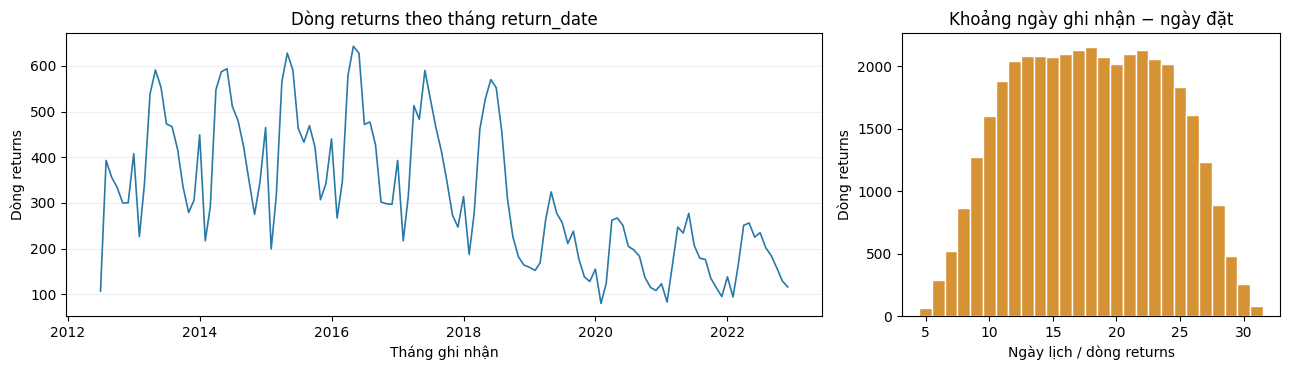

**Quan sát:** return_date từ 11/07/2012 đến 31/12/2022; 126 tháng trong phạm vi lịch. Khoảng ngày từng dòng: min–max 5–31, mean 17,97, median 18 ngày; 0/39.939 dòng có ngày trả trước ngày đặt. Cực đại 31 ngày có 78 dòng, không có chính sách để gọi là quá hạn. Tập B có 80 đơn đặt trong 06/12/2022–31/12/2022, thuộc tháng 2022-12. **Nhận xét có căn cứ:** thiếu dòng đối ứng tập trung cuối lịch sử đặt quan sát; **giới hạn/câu hỏi:** cần metadata chốt/cập nhật để kiểm tra giả thuyết giới hạn theo dõi; không lấy ngày cuối tệp làm ngày trích xuất và không gọi khoảng ngày là thời gian quyết toán hoàn tiền. Biểu đồ tổng tháng chỉ phục vụ khảo sát phạm vi, chưa chứng minh xu hướng hay tính thời vụ.

In [7]:
parsed_dates, date_rows = {}, []
for name, column in [("returns", "return_date"), ("orders", "order_date")]:
    s = frames[name][column]
    lexical_ok = s.str.fullmatch(r"\d{4}-\d{2}-\d{2}").fillna(False)
    parsed = pd.to_datetime(s.where(lexical_ok), format="%Y-%m-%d", errors="coerce")
    parsed_dates[name] = parsed
    date_rows.append({"Nguồn": name, "Trường": column, "Định dạng": "YYYY-MM-DD",
        "Mẫu số dòng": len(s), "NULL": int(missing_mask(s).sum()),
        "Sai định dạng/ngày lịch": int((~missing_mask(s) & parsed.isna()).sum()),
        "Ngày nhỏ nhất": str(parsed.min().date()), "Ngày lớn nhất": str(parsed.max().date()),
        "Số ngày có dòng": parsed.nunique()})
date_quality = pd.DataFrame(date_rows)
show(date_quality)
assert date_quality[["NULL", "Sai định dạng/ngày lịch"]].to_numpy().sum() == 0
orders_dates = orders[["order_id"]].assign(order_date_parsed=parsed_dates["orders"])
return_dates = returns[["return_id", "order_id"]].assign(return_date_parsed=parsed_dates["returns"])
return_dates = return_dates.merge(orders_dates, on="order_id", how="left", validate="many_to_one")
lag = (return_dates["return_date_parsed"] - return_dates["order_date_parsed"]).dt.days
lag_stats = {"Min": int(lag.min()), "Max": int(lag.max()), "Mean": float(lag.mean()),
             "Median": float(lag.median()), "P95": float(lag.quantile(.95)), "P99": float(lag.quantile(.99))}
outside_order_dates = ((parsed_dates["returns"] < parsed_dates["orders"].min()) |
                       (parsed_dates["returns"] > parsed_dates["orders"].max()))
show(pd.DataFrame([{"Chỉ tiêu": k + " khoảng ngày ghi nhận", "Ngày": v} for k,v in lag_stats.items()] +
 [{"Chỉ tiêu": "Dòng return_date < order_date", "Ngày": int(lag.lt(0).sum())},
  {"Chỉ tiêu": "Dòng return_date = order_date", "Ngày": int(lag.eq(0).sum())},
  {"Chỉ tiêu": "Dòng return_date ngoài min–max orders", "Ngày": int(outside_order_dates.sum())}]).rename(
     columns={"Ngày": "Giá trị (ngày hoặc dòng theo chỉ tiêu)"}),
 {"Giá trị (ngày hoặc dòng theo chỉ tiêu)": lambda x: vn(x, 2)})
year_counts = parsed_dates["returns"].dt.year.value_counts().sort_index()
month_counts = parsed_dates["returns"].dt.to_period("M").value_counts().sort_index()
full_months = pd.period_range(month_counts.index.min(), month_counts.index.max(), freq="M")
monthly = month_counts.reindex(full_months, fill_value=0)
month_matrix = pd.DataFrame({"Năm": monthly.index.year, "Tháng": monthly.index.month,
                             "Dòng returns": monthly.to_numpy()}).pivot(index="Năm", columns="Tháng", values="Dòng returns")
month_matrix.columns = [f"T{x:02d}" for x in month_matrix.columns]
month_matrix["Tổng năm"] = month_matrix.sum(axis=1)
show(month_matrix.reset_index(), {c: lambda x: vn(x) for c in month_matrix.columns})
lag_max_count = int(lag.eq(lag.max()).sum())
show(pd.DataFrame([{"Khoảng ngày": int(k), "Dòng returns": int(v)}
                   for k,v in lag.value_counts().sort_index().items()
                   if k in {lag.min(), lag.max()}]),
 {"Dòng returns": lambda x: vn(x)})
missing_detail = orders_dates.merge(orders[["order_id", "order_status"]], on="order_id", validate="one_to_one")
missing_detail["month"] = missing_detail["order_date_parsed"].dt.to_period("M")
missing_detail["is_B"] = missing_detail["order_id"].isin(set_B)
missing_detail["returned"] = missing_detail["order_id"].isin(returned_ids)
missing_months = missing_detail.loc[missing_detail["is_B"], "month"].unique()
tail_month = parsed_dates["orders"].max().to_period("M")
tail = missing_detail["month"].eq(tail_month)
tail_rows = []
for label, mask in [(f"Tháng cuối orders: {tail_month}", tail), ("Trước tháng cuối orders", ~tail)]:
    n = int(mask.sum())
    nr = int((mask & missing_detail["returned"]).sum())
    nb = int((mask & missing_detail["is_B"]).sum())
    tail_rows.append({"Cửa sổ theo ngày đặt": label, "Tất cả đơn": n, "Đơn returned": nr,
                      "B: returned không returns": nb, "% B / returned cùng cửa sổ": pct(nb, nr)})
tail_table = pd.DataFrame(tail_rows)
show(tail_table, {"Tất cả đơn": lambda x: vn(x), "Đơn returned": lambda x: vn(x),
                  "B: returned không returns": lambda x: vn(x),
                  "% B / returned cùng cửa sổ": lambda x: vn(x, 2) + "%"})
missing_range = missing_detail.loc[missing_detail["is_B"], "order_date_parsed"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(monthly.index.to_timestamp(), monthly.to_numpy(), color="#2979a8", linewidth=1.2)
axes[0].set(title="Dòng returns theo tháng return_date", xlabel="Tháng ghi nhận", ylabel="Dòng returns")
axes[0].grid(axis="y", alpha=.2)
axes[1].hist(lag, bins=np.arange(lag.min()-.5, lag.max()+1.5), color="#d69336", edgecolor="white")
axes[1].set(title="Khoảng ngày ghi nhận − ngày đặt", xlabel="Ngày lịch / dòng returns", ylabel="Dòng returns")
plot_done(fig)
note(f"**Quan sát:** return_date từ {parsed_dates['returns'].min():%d/%m/%Y} đến "
     f"{parsed_dates['returns'].max():%d/%m/%Y}; {vn(len(monthly))} tháng trong phạm vi lịch. "
     f"Khoảng ngày từng dòng: min–max {lag.min()}–{lag.max()}, mean {vn(lag.mean(), 2)}, median {vn(lag.median(), 0)} ngày; "
     f"{vn(int(lag.lt(0).sum()))}/{vn(len(lag))} dòng có ngày trả trước ngày đặt. "
     f"Cực đại {lag.max()} ngày có {vn(lag_max_count)} dòng, không có chính sách để gọi là quá hạn. "
     f"Tập B có {vn(len(set_B))} đơn đặt trong {missing_range.min():%d/%m/%Y}–{missing_range.max():%d/%m/%Y}, "
     f"thuộc tháng {', '.join(map(str, sorted(missing_months)))}. "
     "**Nhận xét có căn cứ:** thiếu dòng đối ứng tập trung cuối lịch sử đặt quan sát; "
     "**giới hạn/câu hỏi:** cần metadata chốt/cập nhật để kiểm tra giả thuyết giới hạn theo dõi; "
     "không lấy ngày cuối tệp làm ngày trích xuất và không gọi khoảng ngày là thời gian quyết toán hoàn tiền. "
     "Biểu đồ tổng tháng chỉ phục vụ khảo sát phạm vi, chưa chứng minh xu hướng hay tính thời vụ.")

### NV04.1.7 – Phân loại vấn đề theo bằng chứng

**A** là vi phạm kỹ thuật được kiểm tra trực tiếp; giá trị 0 chỉ có nghĩa không phát hiện trong ràng buộc đã nêu. **B** là hiện tượng quan sát cần đối soát nghiệp vụ, không tự gán thành lỗi. **C** là điều chưa thể xác minh vì thiếu định nghĩa hoặc chứng từ; số lượng chưa xác định không được thay bằng 0.

Các vấn đề B có thể chồng lặp; không cộng số trường hợp thành số đơn lỗi. Giá trị cực trị được giữ nguyên. Mức ưu tiên đối soát không biểu thị mức chắc chắn về nguyên nhân.


In [8]:
technical_specs = [
 ("Khóa orders NULL/lặp", int(missing_mask(orders["order_id"]).sum()+orders.duplicated("order_id").sum()), n_orders, "orders.order_id", "Đếm NULL và dòng dư khóa", "Bổ sung hợp đồng khóa nếu nguồn thay đổi"),
 ("Khóa return_id NULL/lặp", int(missing_mask(returns["return_id"]).sum()+returns.duplicated("return_id").sum()), n_returns, "returns.return_id", "Đếm NULL và dòng dư khóa", "Xác minh định nghĩa bản ghi"),
 ("Returns mồ côi theo đơn", orphan_counts["returns"], n_returns, "returns.order_id → orders", "Tập mã ngoài orders", "Đối chiếu nguồn nếu phát sinh"),
 ("Cặp returns không có trong items", pair_orphans, len(r_pairs), "Cặp đơn–sản phẩm", "LEFT JOIN hai bảng cặp duy nhất", "Cần khóa dòng bán khi cặp lặp"),
 ("Dòng returns trùng toàn bộ", int(returns.duplicated().sum()), n_returns, "Toàn bộ 7 trường returns", "duplicated toàn dòng; không xóa", "Xác minh quy tắc nếu phát sinh"),
 ("Số thiếu/sai cú pháp/không hữu hạn", int(numeric_quality[["NULL", "Sai cú pháp", "Không hữu hạn"]].to_numpy().sum()), int(numeric_quality["Mẫu số dòng"].sum()), "Các trường số cần dùng của 3 nguồn", "Decimal và phân loại riêng", "Không cộng thiếu nếu phát sinh"),
 ("Ngày NULL/không hợp lệ", int(date_quality[["NULL", "Sai định dạng/ngày lịch"]].to_numpy().sum()), len(returns)+len(orders), "return_date; order_date", "ISO và ngày lịch hợp lệ", "Xác minh mốc thời gian"),
 ("Ngày trả ghi nhận trước ngày đặt", int(lag.lt(0).sum()), n_returns, "returns + orders", "Hiệu ngày lịch < 0", "Đối soát nếu xuất hiện"),
 ("Đơn bị nhân bản sau JOIN", abs(len(order_ledger)-len(base_orders)), n_orders, "Bảng tổng hợp cấp đơn", "validate one_to_one; bảo toàn số đơn", "Luôn tổng hợp bảng con trước JOIN")]
technical = pd.DataFrame(technical_specs, columns=["Ràng buộc A", "Vi phạm quan sát", "Mẫu số", "Nguồn", "Kiểm tra", "Hướng tiếp"])
show(technical, {"Vi phạm quan sát": lambda x: vn(x), "Mẫu số": lambda x: vn(x)})
def issue(label, n, denominator, source, check, next_step):
    return {"Hiện tượng B": label, "Số lượng": n, "Mẫu số": denominator,
            "Nguồn và kiểm tra": source + "; " + check,
            "Bằng chứng": "Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh", "Hướng tiếp": next_step}
business_issues = pd.DataFrame([
 issue("Đơn nhiều dòng returns", int(return_counts.gt(1).sum()), n_return_orders, "returns",
       "Đếm dòng/order_id > 1", "NV04.2: phân biệt dòng sản phẩm/lần xử lý; chưa gọi là nhiều yêu cầu"),
 issue("Cặp returns lặp", int(r_pairs["return_rows"].gt(1).sum()), len(r_pairs), "returns",
       "Đếm dòng/cặp > 1; giữ mọi dòng", "Cần khóa chi tiết, không khử trùng theo cặp"),
 issue("Cặp items lặp", int(i_pairs["item_rows"].gt(1).sum()), len(i_pairs), "order_items",
       "Đếm dòng/cặp > 1", "Giữ tổng hợp cấp cặp; cần khóa dòng bán"),
 issue("Returned không có returns (B)", len(set_B), len(returned_ids), "orders + returns",
       "Hiệu hai tập mã", "NV04.2: quy tắc tạo/cập nhật và phạm vi trích xuất"),
 issue("Có returns nhưng không returned (C)", len(set_C), n_return_orders, "orders + returns",
       "Hiệu tập mã theo chiều ngược", "Nếu phát sinh cần đối soát nhãn; chưa tự gọi lỗi"),
 issue("Refund âm", int(refund.lt(0).sum()), n_returns, "returns.refund_amount",
       "Giá trị < 0", "Xác minh nghiệp vụ điều chỉnh nếu xuất hiện"),
 issue("Refund bằng 0", int(refund.eq(0).sum()), n_returns, "returns.refund_amount",
       "Giá trị = 0", "Xác minh phạm vi hoàn trả không hoàn tiền nếu xuất hiện"),
 issue("Refund ngoài hàng rào IQR", int(extreme_mask.sum()), n_returns, "returns.refund_amount",
       f"Ngưỡng dưới {vn(lower,3)}, trên {vn(upper,3)} ĐVT", "Chỉ gắn cờ mô tả; cần chứng từ, không loại bỏ"),
 issue("Refund đơn > Payment + 0,05 ĐVT", n_over_payment, len(affected), "returns tổng hợp + payments",
       "So sánh Decimal từng đơn có returns, không trừ để gọi thực thu", "NV04.2: đối soát phạm vi và chính sách tiền"),
 issue("Khoảng ngày lớn nhất quan sát", lag_max_count, n_returns, "return_date − order_date",
       f"{lag.max()} ngày; không có ngưỡng chính sách", "Cần định nghĩa mốc và chính sách trước khi gọi quá hạn"),
 issue("B tại tháng đặt cuối orders", int((tail & missing_detail["is_B"]).sum()), len(set_B), "orders + tập B",
       f"Tháng {tail_month}; bảng cửa sổ đã ghi thêm mẫu số returned cùng kỳ",
       "Cần metadata chốt; giới hạn theo dõi chỉ là giả thuyết")])
show(business_issues, {"Số lượng": lambda x: vn(x), "Mẫu số": lambda x: vn(x)})
limitations = pd.DataFrame([
 {"Giới hạn C": "Đơn vị bản ghi/sự kiện", "Số lượng xác minh": "Chưa xác định", "Mẫu số": "Không áp dụng",
  "Nguồn/kiểm tra": "7 trường returns; không có khóa yêu cầu/lịch sử xử lý đã định nghĩa",
  "Mức bằng chứng": "Thiếu từ điển nghiệp vụ", "Hướng tiếp": "Xác minh return_id, return_quantity và khóa dòng bán"},
 {"Giới hạn C": "Hoàn tiền thực tế, thực thu", "Số lượng xác minh": "Chưa xác định", "Mẫu số": "Không áp dụng",
  "Nguồn/kiểm tra": "refund_amount, payment_value và Net chỉ được đối chiếu số học",
  "Mức bằng chứng": "Thiếu chứng từ/thời điểm quyết toán/phạm vi tiền", "Hướng tiếp": "NV04.2: định nghĩa tiền và chứng từ; không tự tạo công thức thực thu"},
 {"Giới hạn C": "Ý nghĩa return_date và quá hạn", "Số lượng xác minh": "Chưa xác định", "Mẫu số": "Không áp dụng",
  "Nguồn/kiểm tra": "Có ngày lịch, chưa có timestamp/mốc phê duyệt/hoàn tiền đã xác minh",
  "Mức bằng chứng": "Thiếu định nghĩa mốc và chính sách", "Hướng tiếp": "Xác minh mốc và thời hạn; không suy thời gian quyết toán"},
 {"Giới hạn C": "Nguyên nhân B cuối kỳ", "Số lượng xác minh": "Chưa xác định", "Mẫu số": "Không áp dụng",
  "Nguồn/kiểm tra": "Tập B đối chiếu tháng đặt cuối; không có metadata trích xuất trong bốn CSV",
  "Mức bằng chứng": "Chỉ có tập trung thời gian quan sát", "Hướng tiếp": "Xin lịch chốt/cập nhật và theo dõi sau kỳ trước khi khẳng định cắt phải"},
 {"Giới hạn C": "Đồng tiền và giá trị cực trị đúng nghiệp vụ", "Số lượng xác minh": "Chưa xác định", "Mẫu số": "Không áp dụng",
  "Nguồn/kiểm tra": "Refund hữu hạn; ngưỡng IQR không là chứng từ",
  "Mức bằng chứng": "Thiếu đơn vị tiền/chính sách và đối soát", "Hướng tiếp": "ĐVT là nhãn tạm; cần từ điển, chứng từ; giữ toàn bộ giá trị"}])
show(limitations)
note(f"**Quan sát:** {len(technical)} ràng buộc A, tổng {vn(int(technical['Vi phạm quan sát'].sum()))} lượt vi phạm quan sát; "
     f"{len(business_issues)} mục B và {len(limitations)} mục C. Số mục không là số đơn lỗi. "
     "**Ý nghĩa:** ưu tiên kiểm tra ý nghĩa bản ghi, 80 đơn thiếu đối ứng, chênh lệch Refund/Payment và metadata cuối kỳ. "
     "**Giới hạn/câu hỏi:** tính nhất quán kỹ thuật không thay thế xác minh nghiệp vụ; "
     "đơn vị và quy trình nào làm rõ từng mục trước khi diễn giải tài chính?")

Ràng buộc A,Vi phạm quan sát,Mẫu số,Nguồn,Kiểm tra,Hướng tiếp
Khóa orders NULL/lặp,0,646.945,orders.order_id,Đếm NULL và dòng dư khóa,Bổ sung hợp đồng khóa nếu nguồn thay đổi
Khóa return_id NULL/lặp,0,39.939,returns.return_id,Đếm NULL và dòng dư khóa,Xác minh định nghĩa bản ghi
Returns mồ côi theo đơn,0,39.939,returns.order_id → orders,Tập mã ngoài orders,Đối chiếu nguồn nếu phát sinh
Cặp returns không có trong items,0,39.937,Cặp đơn–sản phẩm,LEFT JOIN hai bảng cặp duy nhất,Cần khóa dòng bán khi cặp lặp
Dòng returns trùng toàn bộ,0,39.939,Toàn bộ 7 trường returns,duplicated toàn dòng; không xóa,Xác minh quy tắc nếu phát sinh
Số thiếu/sai cú pháp/không hữu hạn,0,2.870.830,Các trường số cần dùng của 3 nguồn,Decimal và phân loại riêng,Không cộng thiếu nếu phát sinh
Ngày NULL/không hợp lệ,0,686.884,return_date; order_date,ISO và ngày lịch hợp lệ,Xác minh mốc thời gian
Ngày trả ghi nhận trước ngày đặt,0,39.939,returns + orders,Hiệu ngày lịch < 0,Đối soát nếu xuất hiện
Đơn bị nhân bản sau JOIN,0,646.945,Bảng tổng hợp cấp đơn,validate one_to_one; bảo toàn số đơn,Luôn tổng hợp bảng con trước JOIN


Hiện tượng B,Số lượng,Mẫu số,Nguồn và kiểm tra,Bằng chứng,Hướng tiếp
Đơn nhiều dòng returns,3.801,36.062,returns; Đếm dòng/order_id > 1,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,NV04.2: phân biệt dòng sản phẩm/lần xử lý; chưa gọi là nhiều yêu cầu
Cặp returns lặp,2,39.937,returns; Đếm dòng/cặp > 1; giữ mọi dòng,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,"Cần khóa chi tiết, không khử trùng theo cặp"
Cặp items lặp,16,714.653,order_items; Đếm dòng/cặp > 1,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,Giữ tổng hợp cấp cặp; cần khóa dòng bán
Returned không có returns (B),80,36.142,orders + returns; Hiệu hai tập mã,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,NV04.2: quy tắc tạo/cập nhật và phạm vi trích xuất
Có returns nhưng không returned (C),0,36.062,orders + returns; Hiệu tập mã theo chiều ngược,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,Nếu phát sinh cần đối soát nhãn; chưa tự gọi lỗi
Refund âm,0,39.939,returns.refund_amount; Giá trị < 0,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,Xác minh nghiệp vụ điều chỉnh nếu xuất hiện
Refund bằng 0,0,39.939,returns.refund_amount; Giá trị = 0,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,Xác minh phạm vi hoàn trả không hoàn tiền nếu xuất hiện
Refund ngoài hàng rào IQR,2.778,39.939,"returns.refund_amount; Ngưỡng dưới -16.389,498, trên 36.844,882 ĐVT",Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,"Chỉ gắn cờ mô tả; cần chứng từ, không loại bỏ"
"Refund đơn > Payment + 0,05 ĐVT",3.640,36.062,"returns tổng hợp + payments; So sánh Decimal từng đơn có returns, không trừ để gọi thực thu",Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,NV04.2: đối soát phạm vi và chính sách tiền
Khoảng ngày lớn nhất quan sát,78,39.939,return_date − order_date; 31 ngày; không có ngưỡng chính sách,Đã đếm trong tệp; ý nghĩa/nguyên nhân chưa xác minh,Cần định nghĩa mốc và chính sách trước khi gọi quá hạn


Giới hạn C,Số lượng xác minh,Mẫu số,Nguồn/kiểm tra,Mức bằng chứng,Hướng tiếp
Đơn vị bản ghi/sự kiện,Chưa xác định,Không áp dụng,7 trường returns; không có khóa yêu cầu/lịch sử xử lý đã định nghĩa,Thiếu từ điển nghiệp vụ,"Xác minh return_id, return_quantity và khóa dòng bán"
"Hoàn tiền thực tế, thực thu",Chưa xác định,Không áp dụng,"refund_amount, payment_value và Net chỉ được đối chiếu số học",Thiếu chứng từ/thời điểm quyết toán/phạm vi tiền,NV04.2: định nghĩa tiền và chứng từ; không tự tạo công thức thực thu
Ý nghĩa return_date và quá hạn,Chưa xác định,Không áp dụng,"Có ngày lịch, chưa có timestamp/mốc phê duyệt/hoàn tiền đã xác minh",Thiếu định nghĩa mốc và chính sách,Xác minh mốc và thời hạn; không suy thời gian quyết toán
Nguyên nhân B cuối kỳ,Chưa xác định,Không áp dụng,Tập B đối chiếu tháng đặt cuối; không có metadata trích xuất trong bốn CSV,Chỉ có tập trung thời gian quan sát,Xin lịch chốt/cập nhật và theo dõi sau kỳ trước khi khẳng định cắt phải
Đồng tiền và giá trị cực trị đúng nghiệp vụ,Chưa xác định,Không áp dụng,Refund hữu hạn; ngưỡng IQR không là chứng từ,Thiếu đơn vị tiền/chính sách và đối soát,"ĐVT là nhãn tạm; cần từ điển, chứng từ; giữ toàn bộ giá trị"


**Quan sát:** 9 ràng buộc A, tổng 0 lượt vi phạm quan sát; 11 mục B và 5 mục C. Số mục không là số đơn lỗi. **Ý nghĩa:** ưu tiên kiểm tra ý nghĩa bản ghi, 80 đơn thiếu đối ứng, chênh lệch Refund/Payment và metadata cuối kỳ. **Giới hạn/câu hỏi:** tính nhất quán kỹ thuật không thay thế xác minh nghiệp vụ; đơn vị và quy trình nào làm rõ từng mục trước khi diễn giải tài chính?

### Kết luận nghiệp vụ NV04.1 và bàn giao

Các kết luận dưới đây chỉ tổng hợp chỉ tiêu đã tính ở trên. “Đã xác minh” nghĩa là kiểm tra được trong nguồn quan sát; giả thuyết về quy trình vẫn phải có tài liệu hoặc chứng từ. Không đề xuất thay đổi chính sách đổi trả.


In [9]:
note(f"""
1. **Quy mô đã quan sát:** {vn(n_returns)} bản ghi trên {vn(n_return_orders)} đơn, bằng {vn(pct(n_has,n_orders),3)}% tổng {vn(n_orders)} đơn. Dòng chứa mã đơn, sản phẩm, số lượng, nhãn lý do, ngày và tiền; cấu trúc hỗ trợ mô tả cấp dòng nhưng chưa xác định số yêu cầu hay sự kiện vật lý.
2. **Quan hệ đã kiểm tra:** không có returns mồ côi; return_id duy nhất. {vn(int(return_counts.gt(1).sum()))} đơn có nhiều dòng và {vn(int(r_pairs["return_rows"].gt(1).sum()))} cặp returns lặp nên phải tổng hợp trước JOIN. Quy trình hiện tại bảo toàn đơn và Net; đủ cơ sở kỹ thuật để đối chiếu tiếp.
3. **Trạng thái chưa tương ứng hoàn toàn:** {vn(len(set_A))} đơn returned có returns, {vn(len(set_B))} returned chưa có returns; {vn(len(set_C))} đơn có returns thuộc nhãn khác. Đây là chênh lệch hiện diện, chưa chứng minh thiếu dữ liệu nghiệp vụ.
4. **Tiền ghi nhận tính được:** tổng refund {vn(refund_total,2)} ĐVT khớp giữa cấp dòng và cấp đơn, giữ toàn bộ giá trị. {vn(n_over_payment)} đơn vượt Payment hơn {vn(TOL,2)} ĐVT cần đối soát ở NV04.2. Payment và Net khớp số học không chứng minh quyết toán; thiếu định nghĩa, chứng từ và thời điểm tiền vào/ra nên chưa xác định thực thu, không dùng Payment − Refund để đặt tên doanh thu.
5. **Thời gian chỉ mô tả:** khoảng ngày ghi nhận so với ngày đặt {lag.min()}–{lag.max()} ngày, median {vn(lag.median())}. Toàn bộ {vn(len(set_B))} đơn B nằm ở tháng đặt {tail_month}; phù hợp đặt câu hỏi về phạm vi theo dõi cuối kỳ nhưng chưa chứng minh nguyên nhân.
6. **Bàn giao NV04.2, chưa triển khai:** cần định nghĩa return_id/return_date/refund_amount; đối soát {vn(len(set_B))} đơn B, {vn(n_over_payment)} đơn Refund vượt Payment, khóa chi tiết lặp, các giá trị đặc biệt và metadata chốt/cập nhật. Chưa xác minh hoàn trả thành công, tiền đã hoàn hoặc quá hạn; chưa có bằng chứng về nguyên nhân.
""")


1. **Quy mô đã quan sát:** 39.939 bản ghi trên 36.062 đơn, bằng 5,574% tổng 646.945 đơn. Dòng chứa mã đơn, sản phẩm, số lượng, nhãn lý do, ngày và tiền; cấu trúc hỗ trợ mô tả cấp dòng nhưng chưa xác định số yêu cầu hay sự kiện vật lý.
2. **Quan hệ đã kiểm tra:** không có returns mồ côi; return_id duy nhất. 3.801 đơn có nhiều dòng và 2 cặp returns lặp nên phải tổng hợp trước JOIN. Quy trình hiện tại bảo toàn đơn và Net; đủ cơ sở kỹ thuật để đối chiếu tiếp.
3. **Trạng thái chưa tương ứng hoàn toàn:** 36.062 đơn returned có returns, 80 returned chưa có returns; 0 đơn có returns thuộc nhãn khác. Đây là chênh lệch hiện diện, chưa chứng minh thiếu dữ liệu nghiệp vụ.
4. **Tiền ghi nhận tính được:** tổng refund 510.598.506,55 ĐVT khớp giữa cấp dòng và cấp đơn, giữ toàn bộ giá trị. 3.640 đơn vượt Payment hơn 0,05 ĐVT cần đối soát ở NV04.2. Payment và Net khớp số học không chứng minh quyết toán; thiếu định nghĩa, chứng từ và thời điểm tiền vào/ra nên chưa xác định thực thu, không dùng Payment − Refund để đặt tên doanh thu.
5. **Thời gian chỉ mô tả:** khoảng ngày ghi nhận so với ngày đặt 5–31 ngày, median 18. Toàn bộ 80 đơn B nằm ở tháng đặt 2022-12; phù hợp đặt câu hỏi về phạm vi theo dõi cuối kỳ nhưng chưa chứng minh nguyên nhân.
6. **Bàn giao NV04.2, chưa triển khai:** cần định nghĩa return_id/return_date/refund_amount; đối soát 80 đơn B, 3.640 đơn Refund vượt Payment, khóa chi tiết lặp, các giá trị đặc biệt và metadata chốt/cập nhật. Chưa xác minh hoàn trả thành công, tiền đã hoàn hoặc quá hạn; chưa có bằng chứng về nguyên nhân.


### Kiểm chứng độc lập – quét CSV bằng cấu trúc Python

Đọc lại nguồn bằng csv.DictReader, Counter, dict/set, Decimal và datetime; không dùng kết quả groupby/JOIN của Pandas để tạo đối chứng. So sánh **từng đơn, từng cặp, từng tháng và từng trạng thái**, không chỉ tổng toàn kỳ. Kiểm tra cấu trúc mỗi dòng CSV để phát hiện sai số trường.

Mẫu nhỏ riêng kiểm tra hai rủi ro: một đơn có nhiều dòng returns và một đơn returned chưa có dòng. Đây là dữ liệu tổng hợp trong bộ nhớ, không tạo tệp phụ và không thêm vào dữ liệu thật.


In [10]:
def csv_rows(name):
    with paths[name].open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream, strict=True)
        assert len(reader.fieldnames) == len(set(reader.fieldnames))
        for row in reader:
            assert None not in row and None not in row.values(), f"Sai cấu trúc CSV: {name}, dòng {reader.line_num}"
            yield row
ind_orders, ind_status, ind_dates = {}, Counter(), {}
ind_rows = Counter()
for row in csv_rows("orders"):
    key = row["order_id"]
    assert key and key not in ind_orders
    date = datetime.strptime(row["order_date"], "%Y-%m-%d").date()
    assert date.isoformat() == row["order_date"]
    ind_orders[key] = row["order_status"]
    ind_dates[key] = date
    ind_status[row["order_status"]] += 1
    ind_rows["orders"] += 1
ind_return_ids, ind_counts, ind_refund, ind_pair_counts = set(), Counter(), defaultdict(Decimal), Counter()
ind_months, ind_years, ind_lags, ind_refund_values = Counter(), Counter(), [], []
ind_date_values, ind_orphan_rows = [], Counter()
ind_numeric_quality = Counter()
for row in csv_rows("returns"):
    assert row["return_id"] and row["return_id"] not in ind_return_ids
    ind_return_ids.add(row["return_id"])
    key = row["order_id"]
    amount, quantity = Decimal(row["refund_amount"]), Decimal(row["return_quantity"])
    assert amount.is_finite() and quantity.is_finite()
    ind_numeric_quality["refund_negative"] += amount < 0
    ind_numeric_quality["refund_zero"] += amount == 0
    ind_numeric_quality["quantity_nonpositive"] += quantity <= 0
    ind_numeric_quality["quantity_fractional"] += quantity != quantity.to_integral_value()
    ind_counts[key] += 1
    ind_refund[key] += amount
    ind_pair_counts[(key, row["product_id"])] += 1
    date = datetime.strptime(row["return_date"], "%Y-%m-%d").date()
    assert date.isoformat() == row["return_date"]
    ind_date_values.append(date)
    ind_months[row["return_date"][:7]] += 1
    ind_years[date.year] += 1
    ind_refund_values.append(amount)
    if key in ind_dates:
        ind_lags.append((date - ind_dates[key]).days)
    else:
        ind_orphan_rows["returns"] += 1
    ind_rows["returns"] += 1
ind_net, ind_gross, ind_discount, ind_item_pairs = defaultdict(Decimal), ZERO, ZERO, Counter()
for row in csv_rows("order_items"):
    key = row["order_id"]
    q, price, discount = (Decimal(row[c]) for c in ["quantity", "unit_price", "discount_amount"])
    assert all(v.is_finite() for v in [q, price, discount])
    ind_net[key] += q * price - discount
    ind_gross += q * price
    ind_discount += discount
    ind_item_pairs[(key, row["product_id"])] += 1
    ind_orphan_rows["order_items"] += key not in ind_orders
    ind_rows["order_items"] += 1
ind_payments = {}
for row in csv_rows("payments"):
    key = row["order_id"]
    assert key not in ind_payments
    amount = Decimal(row["payment_value"])
    assert amount.is_finite()
    ind_payments[key] = amount
    ind_orphan_rows["payments"] += key not in ind_orders
    ind_rows["payments"] += 1
ind_returned_ids = {key for key, status_name in ind_orders.items() if status_name == "returned"}
ind_A = ind_returned_ids & set(ind_counts)
ind_B = ind_returned_ids - set(ind_counts)
ind_C = set(ind_counts) - ind_returned_ids
ind_status_presence = Counter((status_name, key in ind_counts) for key,status_name in ind_orders.items())
ind_distribution = Counter(ind_counts.values())
ind_over_payment = {key for key in ind_counts if ind_refund[key] - ind_payments[key] > TOL}
ind_quantiles = statistics.quantiles(ind_refund_values, n=100, method="inclusive")
ind_extremes = sum(x < lower or x > upper for x in ind_refund_values)
show(pd.DataFrame([{"Đối chứng CSV": key, "Dòng": count, "Phương pháp": "csv + dict/Counter + Decimal; không dùng groupby"}
                   for key,count in ind_rows.items()]), {"Dòng": lambda x: vn(x)})
note("Đã tạo xong đối chứng độc lập trong bộ nhớ. Bảng kiểm chứng cuối sẽ so sánh toàn bộ giá trị theo khóa, công thức và mẫu số; chưa coi việc quét thành công là mọi kiểm tra đã đạt.")

Đối chứng CSV,Dòng,Phương pháp
orders,646.945,csv + dict/Counter + Decimal; không dùng groupby
returns,39.939,csv + dict/Counter + Decimal; không dùng groupby
order_items,714.669,csv + dict/Counter + Decimal; không dùng groupby
payments,646.945,csv + dict/Counter + Decimal; không dùng groupby


Đã tạo xong đối chứng độc lập trong bộ nhớ. Bảng kiểm chứng cuối sẽ so sánh toàn bộ giá trị theo khóa, công thức và mẫu số; chưa coi việc quét thành công là mọi kiểm tra đã đạt.

In [11]:
def aggregate_returns(frame):
    return frame.groupby("order_id", sort=True).agg(
        n_return_rows=("refund", "size"), refund=("refund", "sum"))
sample_orders = pd.DataFrame({
    "order_id": ["A", "B", "C"], "order_status": ["returned", "returned", "delivered"],
    "Net": [Decimal("100"), Decimal("200"), Decimal("300")]})
sample_returns = pd.DataFrame({
    "order_id": ["A", "A"], "refund": [Decimal("20"), Decimal("30")]})
sample_agg = aggregate_returns(sample_returns)
sample_safe = sample_orders.merge(sample_agg, on="order_id", how="left", validate="one_to_one")
# Phép ghép sai chỉ minh họa trên mẫu tổng hợp nhỏ, không dùng vào dữ liệu thật.
sample_unsafe = sample_orders.merge(sample_returns, on="order_id", how="left")
sample_expected = {"A": (2, Decimal("50")), "B": (0, None), "C": (0, None)}
sample_actual = {row.order_id: (0 if pd.isna(row.n_return_rows) else int(row.n_return_rows),
                              None if pd.isna(row.refund) else row.refund)
                 for row in sample_safe.itertuples(index=False)}
sample_returned = {row.order_id for row in sample_orders.itertuples(index=False)
                   if row.order_status == "returned"}
sample_present = set(sample_returns["order_id"])
fixture_checks = [
 sample_actual == sample_expected,
 len(sample_safe) == 3 and sum(sample_safe["Net"], ZERO) == Decimal("600"),
 sum(sample_agg["refund"], ZERO) == sum(sample_returns["refund"], ZERO) == Decimal("50"),
 sample_returned - sample_present == {"B"},
 sample_returned & sample_present == {"A"},
 len(sample_unsafe) == 4 and sum(sample_unsafe["Net"], ZERO) == Decimal("700")]
show(sample_safe.rename(columns={"n_return_rows": "Dòng returns", "refund": "Refund ghi nhận (ĐVT)"}),
 {"Net": lambda x: vn(x, 2), "Refund ghi nhận (ĐVT)": lambda x: vn(x, 2)})
show(pd.DataFrame([
 {"Cách JOIN trên mẫu": "Tổng hợp trước JOIN", "Dòng": len(sample_safe), "Tổng Net (ĐVT)": sum(sample_safe["Net"], ZERO)},
 {"Cách JOIN trên mẫu": "Ghép trực tiếp chi tiết (minh họa sai)", "Dòng": len(sample_unsafe), "Tổng Net (ĐVT)": sum(sample_unsafe["Net"], ZERO)}]),
 {"Tổng Net (ĐVT)": lambda x: vn(x, 2)})
note("**Kết quả mẫu:** JOIN trực tiếp làm Net từ 600 thành 700 ĐVT; JOIN sau tổng hợp giữ 3 đơn và 600 ĐVT, đồng thời giữ đơn B returned chưa có returns. "
     "**Ý nghĩa:** mẫu kiểm tra được lỗi nhân bản và chênh lệch tập hợp, không suy rộng nguyên nhân nghiệp vụ từ dữ liệu tổng hợp. "
     "**Câu hỏi tiếp:** cần quy tắc sự kiện/khóa nào trước khi diễn giải nhiều dòng thành nhiều lần hoàn trả?")

order_id,order_status,Net,Dòng returns,Refund ghi nhận (ĐVT)
A,returned,"100,00",2.000000,"50,00"
B,returned,"200,00",—,—
C,delivered,"300,00",—,—


Cách JOIN trên mẫu,Dòng,Tổng Net (ĐVT)
Tổng hợp trước JOIN,3,"600,00"
Ghép trực tiếp chi tiết (minh họa sai),4,"700,00"


**Kết quả mẫu:** JOIN trực tiếp làm Net từ 600 thành 700 ĐVT; JOIN sau tổng hợp giữ 3 đơn và 600 ĐVT, đồng thời giữ đơn B returned chưa có returns. **Ý nghĩa:** mẫu kiểm tra được lỗi nhân bản và chênh lệch tập hợp, không suy rộng nguyên nhân nghiệp vụ từ dữ liệu tổng hợp. **Câu hỏi tiếp:** cần quy tắc sự kiện/khóa nào trước khi diễn giải nhiều dòng thành nhiều lần hoàn trả?

### Kiểm chứng cuối – đạt, không đạt và không áp dụng

Mỗi kiểm tra áp dụng được đánh giá bằng dữ liệu tính lại. Đối chiếu tiền với V02/V03 dùng dung sai 0,05 ĐVT; bảo toàn nội bộ bằng Decimal yêu cầu **khớp chính xác**. Tỷ lệ dùng mẫu số ghi ngay trong các bảng.

Các mục chưa đủ dữ liệu về quyết toán, định nghĩa sự kiện, chính sách và nguyên nhân cuối kỳ được ghi **không áp dụng**, tách khỏi số đạt. Kiểm tra “không phát hiện lỗi kỹ thuật” không đồng nghĩa với kết luận mọi quy trình đúng.


In [12]:
checks = []
def check(label, condition, reason="Áp dụng; kiểm tra trực tiếp"):
    checks.append({"Kiểm chứng": label, "Trạng thái": "Đạt" if bool(condition) else "Không đạt",
                   "Bằng chứng/lý do": reason})
def na(label, reason):
    checks.append({"Kiểm chứng": label, "Trạng thái": "Không áp dụng", "Bằng chứng/lý do": reason})
check("Hash bốn CSV khớp nguồn V03", source_match)
check("V02/V03 tính từ CSV đều đạt kiểm chứng kỹ thuật", v02["status"] == "ok" and all(v02["checks"].values()) and all(v03["checks"].values()),
      "V03 completed_with_findings: không bỏ qua phát hiện nghiệp vụ")
check("Đủ trường cần dùng và cấu trúc CSV độc lập hợp lệ", all(required[k] <= set(frames[k]) for k in required) and all(ind_rows[k] == len(frames[k]) for k in frames))
check("Returns: số dòng/7 trường khớp CSV độc lập và V03", n_returns == ind_rows["returns"] == v03["metrics"]["returns_rows"] and len(returns.columns) == 7)
check("Orders: tổng khớp CSV độc lập và V02/V03", n_orders == ind_rows["orders"] == v02["metrics"]["orders_rows"] == v03["metrics"]["orders_rows"])
check("order_id orders và return_id không NULL, duy nhất", orders["order_id"].is_unique and returns["return_id"].is_unique and
      not missing_mask(orders["order_id"]).any() and not missing_mask(returns["return_id"]).any())
check("NULL toàn bộ trường cần dùng được thống kê; hiện không có", int(needed_nulls["NULL"].sum()) == 0)
check("Số lượng NULL/sai cú pháp/không hữu hạn được kiểm tra", numeric_quality[["NULL","Sai cú pháp","Không hữu hạn"]].to_numpy().sum() == 0)
check("Refund âm/0 và số lượng không dương/không nguyên khớp đối chứng", int(refund.lt(0).sum()) == ind_numeric_quality["refund_negative"] and
      int(refund.eq(0).sum()) == ind_numeric_quality["refund_zero"] and
      sum(x <= 0 for x in numeric_values[("returns","return_quantity")]) == ind_numeric_quality["quantity_nonpositive"] and
      sum(x != x.to_integral_value() for x in numeric_values[("returns","return_quantity")]) == ind_numeric_quality["quantity_fractional"])
check("Từng mã đơn và số dòng returns khớp Counter độc lập", return_counts.to_dict() == dict(ind_counts))
check("Số đơn phân biệt khớp CSV độc lập và V03", n_return_orders == len(ind_counts) == v03["metrics"]["return_orders"])
check("Orphan returns/items/payments được đếm độc lập; hiện không có", all(orphan_counts[k] == ind_orphan_rows[k] == 0 for k in orphan_counts))
check("Trùng dòng/mã returns không có; cặp lặp vẫn được giữ", not returns.duplicated().any() and not returns.duplicated("return_id").any() and n_returns == sum(ind_pair_counts.values()))
check("Từng cặp returns khớp Counter độc lập", r_pairs.set_index(["order_id","product_id"])["return_rows"].to_dict() == dict(ind_pair_counts))
check("Từng cặp items khớp Counter độc lập", i_pairs.set_index(["order_id","product_id"])["item_rows"].to_dict() == dict(ind_item_pairs))
check("Cặp returns có đối ứng; JOIN cặp không nhân bản", pair_orphans == len(set(ind_pair_counts)-set(ind_item_pairs)) == 0 and len(pair_link) == len(r_pairs))
check("Cặp returns và items lặp khớp V03", int(r_pairs["return_rows"].gt(1).sum()) == v03["metrics"]["repeated_return_pairs"] and
      int(items.duplicated(["order_id","product_id"]).sum()) == v03["metrics"]["duplicate_item_pairs_excess"])
check("JOIN cấp đơn bảo toàn từng mã và không nhân bản", len(order_ledger) == n_orders and order_ledger["order_id"].is_unique and set(order_ledger["order_id"]) == set(ind_orders))
check("Từng Net cấp đơn khớp đối chứng độc lập", base_orders.set_index("order_id")["Net"].to_dict() == dict(ind_net))
check("Từng Payment cấp đơn khớp đối chứng độc lập", base_orders.set_index("order_id")["Payment"].to_dict() == ind_payments)
check("JOIN returns bảo toàn Net chính xác", net_before == net_after == sum(ind_net.values(), ZERO))
check("Gross/Discount/Net/Payment khớp NV03 và V02", all(
      abs(value-nv03_money[k]) <= TOL and abs(value-Decimal(str(v02["metrics"][k]))) <= TOL
      for k,value in money_actual.items()))
check("Gross/Discount/Net/Payment toàn kỳ khớp Decimal độc lập", money_actual == {
      "gross": ind_gross, "discount": ind_discount, "net": sum(ind_net.values(),ZERO),
      "payment": sum(ind_payments.values(),ZERO)})
check("Có/không returns phân hoạch đầy đủ đơn", n_has+n_without == n_orders and
      n_has == int(order_ledger["has_returns"].sum()) and n_without == int((~order_ledger["has_returns"]).sum()))
check("Phân bố số dòng/đơn khớp Counter và bảo toàn số đơn/dòng", distribution.set_index("Dòng returns/đơn")["Số đơn"].to_dict() == dict(ind_distribution) and
      int(distribution["Số đơn"].sum()) == n_return_orders and int(distribution["Dòng returns được bảo toàn"].sum()) == n_returns)
check("Một/nhiều dòng, số đơn cực đại và mean dùng đúng mẫu số", int(return_counts.eq(1).sum())+int(return_counts.gt(1).sum()) == n_return_orders and
      int(return_counts.gt(1).sum()) == v03["metrics"]["orders_with_multiple_returns"] and
      max_rows == max(ind_counts.values()) and n_at_max == sum(x == max_rows for x in ind_counts.values()) and
      math.isclose(n_returns/n_return_orders, statistics.mean(ind_counts.values())))
check("Trạng thái từng đơn và từng tổng khớp CSV độc lập", orders.set_index("order_id")["order_status"].to_dict() == ind_orders and
      status["total"].to_dict() == dict(ind_status))
check("Tổng trạng thái khớp NV03 đã lưu; không mâu thuẫn nền", status["total"].to_dict() == nv03_status and int(status["total"].sum()) == n_orders)
check("Từng ô trạng thái × hiện diện khớp Counter độc lập", all(
      int(status.loc[s,"with_returns"]) == ind_status_presence[(s,True)] and
      int(status.loc[s,"without_returns"]) == ind_status_presence[(s,False)] for s in status.index))
check("Tập A/B/C bằng đối chứng set độc lập", set_A == ind_A and set_B == ind_B and set_C == ind_C)
check("Tập hợp không suy từ hiệu tổng; bảo toàn tập và dòng theo trạng thái", set_A.isdisjoint(set_B) and set_A|set_B == returned_ids and
      set_A.isdisjoint(set_C) and set_A|set_C == return_order_ids and int(status["return_rows"].sum()) == n_returns)
check("Đơn returned chưa có returns và chiều ngược khớp V03", len(set_B) == v03["metrics"]["returned_orders_without_returns"] and len(set_C) == v03["metrics"]["returns_on_nonreturned_status"])
check("Tỷ lệ toàn bộ đơn và tỷ lệ trong trạng thái đúng mẫu số", math.isclose(pct(n_has,n_orders)+pct(n_without,n_orders),100) and
      np.allclose(status["pct_within_status"].to_numpy(),[100*ind_status_presence[(s,True)]/ind_status[s] for s in status.index]) and
      np.allclose(distribution["% đơn có returns"],100*distribution["Số đơn"]/n_return_orders))
check("Từng tổng Refund cấp đơn khớp Decimal độc lập", return_by_order["refund"].to_dict() == dict(ind_refund))
check("Refund tổng dòng = tổng đơn chính xác, khớp V03 trong dung sai", refund_total == refund_order_total == sum(ind_refund_values,ZERO) == sum(ind_refund.values(),ZERO) and
      abs(refund_total-Decimal(str(v03["metrics"]["refund"]))) <= TOL)
check("Refund đơn không có dòng vẫn thiếu; không cộng trùng", order_ledger.loc[~order_ledger["has_returns"],"refund"].isna().all() and
      sum(order_ledger.loc[order_ledger["has_returns"],"refund"],ZERO) == refund_total)
check("Số đơn có nhiều bản ghi refund đúng Counter", multiple_refund_orders == sum(n>1 for n in ind_counts.values()))
check("Min/max/mean/median/phân vị refund cấp dòng đúng statistics độc lập", min_refund == min(ind_refund_values) and
      max_refund == max(ind_refund_values) and quantile_decimal(refund,.5) == statistics.median(ind_refund_values) and
      refund_total/len(refund) == statistics.mean(ind_refund_values) and
      all(quantile_decimal(refund,q) == ind_quantiles[int(q*100)-1] for q in [.25,.75,.9,.95,.99]))
check("Phân vị refund cấp đơn đúng statistics độc lập", all(
      quantile_decimal(list(return_by_order["refund"]),q) == statistics.quantiles(list(ind_refund.values()),n=100,method="inclusive")[int(q*100)-1]
      for q in [.25,.5,.75,.9,.95,.99]))
check("Ngưỡng IQR và số dòng đặc biệt khớp độc lập, không loại dòng", q1 == ind_quantiles[24] and q3 == ind_quantiles[74] and
      int(extreme_mask.sum()) == ind_extremes and len(refund) == n_returns)
check("Refund đơn vượt Payment: đúng từng mã, dung sai và V03", set(affected.loc[over_payment,"order_id"]) == ind_over_payment and
      n_over_payment == v03["metrics"]["refund_orders_above_payment"])
check("Ngày đúng ISO, không NULL/không hợp lệ; min/max khớp độc lập", date_quality[["NULL","Sai định dạng/ngày lịch"]].to_numpy().sum() == 0 and
      parsed_dates["returns"].min().date() == min(ind_date_values) and parsed_dates["returns"].max().date() == max(ind_date_values))
check("Khoảng ngày từng dòng khớp datetime độc lập", lag.tolist() == ind_lags and len(lag) == n_returns and
      sum(ind_lags) == v03["metrics"]["lag_sum_days"])
check("Âm/0/cực đại khoảng ngày kiểm tra đủ, không áp ngưỡng chính sách", int(lag.lt(0).sum()) == sum(x<0 for x in ind_lags) == v03["metrics"]["return_before_order"] and
      int(lag.eq(0).sum()) == sum(x==0 for x in ind_lags) and lag_max_count == sum(x == max(ind_lags) for x in ind_lags))
check("Theo năm/tháng khớp Counter và bảo toàn dòng", year_counts.to_dict() == dict(ind_years) and
      {str(k):int(v) for k,v in month_counts.items()} == dict(ind_months) and int(monthly.sum()) == n_returns and
      int(month_matrix["Tổng năm"].sum()) == n_returns)
ind_tail_B = {key for key in ind_B if str(ind_dates[key])[:7] == str(tail_month)}
ind_tail_returned = {key for key in ind_returned_ids if str(ind_dates[key])[:7] == str(tail_month)}
check("Cuối kỳ: B và mẫu số returned đúng đối chứng ngày đặt độc lập", int(tail_table.iloc[0]["B: returned không returns"]) == len(ind_tail_B) and
      int(tail_table.iloc[0]["Đơn returned"]) == len(ind_tail_returned) and
      math.isclose(float(tail_table.iloc[0]["% B / returned cùng cửa sổ"]),pct(len(ind_tail_B),len(ind_tail_returned))))
check("Mẫu nhỏ: nhiều returns/đơn, returned thiếu dòng, không nhân Net", all(fixture_checks), "6 điều kiện trên mẫu độc lập trong bộ nhớ, gồm minh họa JOIN sai")
check("Giữ nguyên mọi tệp ngoài notebook (SHA-256)", protected_before == protected_snapshot(),
      f"{len(protected_before)} tệp, gồm raw/NV01–03/V01–09 và tài liệu untracked")
na("Số yêu cầu/sự kiện hoàn trả vật lý", "Chưa có định nghĩa return_id và khóa sự kiện; dòng không mặc định là yêu cầu")
na("Tiền thực hoàn/quyết toán/thực thu", "Chưa có định nghĩa phạm vi tiền và chứng từ/mốc quyết toán; không tính Payment − Refund")
na("Thời gian hoàn tiền thực tế và quá hạn", "Chưa xác minh ý nghĩa return_date; chưa có chính sách thời hạn")
na("Nguyên nhân 80 đơn returned chưa có returns", "Thiếu metadata chốt/cập nhật và lịch sử xử lý; tập trung cuối kỳ chưa chứng minh cắt phải")
na("Giá trị cực trị hoặc Refund > Payment là lỗi nghiệp vụ", "Ngưỡng mô tả và chênh lệch số học chưa thay thế chứng từ/chính sách; bàn giao NV04.2")
validation = pd.DataFrame(checks)
verification_counts = {
 "passed": int(validation["Trạng thái"].eq("Đạt").sum()),
 "failed": int(validation["Trạng thái"].eq("Không đạt").sum()),
 "not_applicable": int(validation["Trạng thái"].eq("Không áp dụng").sum())}
show(validation)
show(pd.DataFrame([{"Đạt": verification_counts["passed"], "Không đạt": verification_counts["failed"],
                    "Không áp dụng": verification_counts["not_applicable"],
                    "Bảng kết quả trong notebook": table_count + 1, "Hình biểu đồ": figure_count}]))
note(f"**Kết quả kiểm chứng:** {verification_counts['passed']} đạt, {verification_counts['failed']} không đạt, "
     f"{verification_counts['not_applicable']} không áp dụng (lý do tách riêng, không tính là đạt). "
     "**Phạm vi:** số học, khóa, quan hệ và đối chứng dữ liệu quan sát; chưa xác minh quy trình/quyết toán. "
     "**Câu hỏi tiếp:** cần tài liệu và chứng từ nêu ở các mục C trước khi giải thích nghiệp vụ sâu hơn.")
assert verification_counts["failed"] == 0, "Có kiểm chứng không đạt: xem bảng, không coi Run All thành công."

Kiểm chứng,Trạng thái,Bằng chứng/lý do
Hash bốn CSV khớp nguồn V03,Đạt,Áp dụng; kiểm tra trực tiếp
V02/V03 tính từ CSV đều đạt kiểm chứng kỹ thuật,Đạt,V03 completed_with_findings: không bỏ qua phát hiện nghiệp vụ
Đủ trường cần dùng và cấu trúc CSV độc lập hợp lệ,Đạt,Áp dụng; kiểm tra trực tiếp
Returns: số dòng/7 trường khớp CSV độc lập và V03,Đạt,Áp dụng; kiểm tra trực tiếp
Orders: tổng khớp CSV độc lập và V02/V03,Đạt,Áp dụng; kiểm tra trực tiếp
"order_id orders và return_id không NULL, duy nhất",Đạt,Áp dụng; kiểm tra trực tiếp
NULL toàn bộ trường cần dùng được thống kê; hiện không có,Đạt,Áp dụng; kiểm tra trực tiếp
Số lượng NULL/sai cú pháp/không hữu hạn được kiểm tra,Đạt,Áp dụng; kiểm tra trực tiếp
Refund âm/0 và số lượng không dương/không nguyên khớp đối chứng,Đạt,Áp dụng; kiểm tra trực tiếp
Từng mã đơn và số dòng returns khớp Counter độc lập,Đạt,Áp dụng; kiểm tra trực tiếp


Đạt,Không đạt,Không áp dụng,Bảng kết quả trong notebook,Hình biểu đồ
48,0,5,31,2


**Kết quả kiểm chứng:** 48 đạt, 0 không đạt, 5 không áp dụng (lý do tách riêng, không tính là đạt). **Phạm vi:** số học, khóa, quan hệ và đối chứng dữ liệu quan sát; chưa xác minh quy trình/quyết toán. **Câu hỏi tiếp:** cần tài liệu và chứng từ nêu ở các mục C trước khi giải thích nghiệp vụ sâu hơn.

### Kết thúc NV04.1

Kết quả được giữ trực tiếp trong notebook. Các kiểm chứng không áp dụng vẫn là giới hạn mở, không được diễn giải thành đạt. Thông tin hai lượt Run All trên kernel mới được ghi trong metadata `execution_validation` sau khi thực thi thực tế; output hiện tại là lượt chạy cuối.

Phạm vi hoàn thành dừng tại NV04.1. Các câu hỏi bàn giao chỉ là hướng kiểm tra tiếp, chưa triển khai NV04.2 hoặc các phần sau.


## NV04.2 – Phân tích giá trị hoàn tiền và đối soát tài chính

Phần này nối tiếp NV04.1; giữ nguyên 24 ô trước, cả code, Markdown và output. Chỉ phân tích **giá trị ghi nhận**, không coi refund_amount là tiền đã chuyển trả hay payment_value là tiền thực thu. Tiền dùng ĐVT, chưa xác minh đồng tiền/chính sách quyết toán.

Nguồn: bốn CSV đã kiểm tra ở NV04.1 và định nghĩa V02/V03. Tái sử dụng các biến Decimal, đối chứng csv/dict và khóa đã xác minh; đọc lại header và hash trước khi dùng. Không sửa tiền, không loại đơn vượt Payment, không cắt tỷ lệ về 100%, không phân tích nguyên nhân/lý do hoặc phân khúc sản phẩm.

### NV04.2.1 – Bảng đối soát một dòng/đơn

GrossOrder = Σ(quantity × unit_price); DiscountOrder = Σ(discount_amount), **không nhân giảm giá với quantity**; NetOrder = GrossOrder − DiscountOrder. Payments và returns được tổng hợp riêng trước JOIN one_to_one từ orders. Dùng 0 cho refund_total của đơn không có returns chỉ là tổng rỗng trong tệp; has_return=False vẫn phân biệt rõ, không chứng minh không hoàn tiền ngoài nguồn.

return_quantity_total cộng số lượng được ghi nhận, chỉ dùng đối chiếu số học; chưa xác minh đơn vị vật lý đồng nhất giữa các sản phẩm nên không diễn giải thành khối lượng hàng hóa.


In [13]:
table_start042, figure_start042 = table_count, figure_count
prefix_sha042 = notebook_prefix(initial_notebook['cells'][:24])
def prefix_hash042():
    n = load_notebook_for_audit(TARGET)
    return notebook_prefix(n["cells"][:24])
def fmt_money042(frame):
    return {col: (lambda x: vn(x, 2)) for col in frame.columns if "(ĐVT)" in str(col)
            and not any(isinstance(value,str) for value in frame[col])}
def finite042(value):
    return isinstance(value, Decimal) and value.is_finite()
def ratio042(a, b):
    return a / b if finite042(a) and finite042(b) and a >= 0 and b > 0 else None
def mean042(values):
    values = [x for x in values if x is not None]
    return sum(values, ZERO) / len(values) if values else None
def q042(values, q):
    return quantile_decimal(list(values), q) if len(values) else None
headers042 = {}
for name, path in paths.items():
    with path.open(encoding="utf-8-sig", newline="") as stream:
        headers042[name] = next(csv.reader(stream))
hashes042 = {name: sha(path) for name,path in paths.items()}
assert hashes042 == source_hashes and prefix_hash042() == prefix_sha042
show(pd.DataFrame([{"Nguồn": k, "Trường thực tế": ", ".join(v),
                    "Hash khớp NV04.1/V03": hashes042[k] == source_hashes[k] == v03["sources"][k]["sha256"]}
                   for k,v in headers042.items()]))
item_lines042 = items[["order_id", "product_id"]].assign(
    quantity=numeric_values[("order_items","quantity")],
    gross=[q*p for q,p in zip(numeric_values[("order_items","quantity")],
                             numeric_values[("order_items","unit_price")])],
    discount=numeric_values[("order_items","discount_amount")])
item_order042 = item_lines042.groupby("order_id", sort=True).agg(
    GrossOrder=("gross","sum"), DiscountOrder=("discount","sum"),
    item_line_count=("product_id","size"))
item_order042["NetOrder"] = item_order042["GrossOrder"] - item_order042["DiscountOrder"]
payment_order042 = payments[["order_id"]].assign(payment_value=payment).groupby("order_id",sort=True)["payment_value"].sum()
return_lines042 = returns[["return_id","order_id","product_id","return_date"]].assign(
    refund=refund, return_quantity=numeric_values[("returns","return_quantity")])
return_order042 = return_lines042.groupby("order_id",sort=True).agg(
    return_line_count=("return_id","size"), refund_total=("refund","sum"),
    return_quantity_total=("return_quantity","sum"),
    first_return_date=("return_date","min"), last_return_date=("return_date","max"))
ledger042 = orders.merge(item_order042,on="order_id",how="left",validate="one_to_one")
ledger042 = ledger042.merge(payment_order042,on="order_id",how="left",validate="one_to_one")
ledger042 = ledger042.merge(return_order042,on="order_id",how="left",validate="one_to_one")
ledger042["has_return"] = ledger042["return_line_count"].notna()
ledger042["return_line_count"] = ledger042["return_line_count"].fillna(0).astype("int64")
for name in ["refund_total","return_quantity_total"]:
    ledger042[name] = [x if h else ZERO for x,h in zip(ledger042[name],ledger042["has_return"])]
assert ledger042[["GrossOrder","DiscountOrder","NetOrder","payment_value"]].notna().all().all()
has042 = ledger042.loc[ledger042["has_return"]].copy()
totals042 = {k: sum(ledger042[k],ZERO) for k in ["GrossOrder","DiscountOrder","NetOrder","payment_value","refund_total"]}
show(pd.DataFrame([{"Chỉ tiêu": k, "Tổng (ĐVT)": v} for k,v in totals042.items()]), {"Tổng (ĐVT)": lambda x: vn(x,2)})
show(ledger042.sort_values("order_id").head(5)[["order_id","order_date","order_status","GrossOrder",
    "DiscountOrder","NetOrder","payment_value","has_return","return_line_count","refund_total","return_quantity_total"]].rename(
    columns={k:k+" (ĐVT)" for k in ["GrossOrder","DiscountOrder","NetOrder","payment_value","refund_total"]}),
 {k+" (ĐVT)":lambda x:vn(x,2) for k in ["GrossOrder","DiscountOrder","NetOrder","payment_value","refund_total"]})
note(f"**Quan sát:** bảng có {vn(len(ledger042))} đơn duy nhất, {vn(len(has042))} có returns, "
     f"{vn(int((~ledger042['has_return']).sum()))} không có returns; Net và Payment đều {vn(totals042['NetOrder'],2)} ĐVT, "
     f"Refund {vn(totals042['refund_total'],2)} ĐVT. "
     "**Ý nghĩa đối soát:** mỗi giá trị đơn chỉ xuất hiện một lần; năm dòng minh họa không thay tổng toàn bộ nguồn. "
     "**Giới hạn/câu hỏi:** tổng rỗng bằng 0 không xác minh hoàn tiền ngoài tệp; cần định nghĩa tiền và chứng từ quyết toán.")

Nguồn,Trường thực tế,Hash khớp NV04.1/V03
returns,"return_id, order_id, product_id, return_date, return_reason, return_quantity, refund_amount",True
orders,"order_id, order_date, customer_id, zip, order_status, payment_method, device_type, order_source",True
payments,"order_id, payment_method, payment_value, installments",True
order_items,"order_id, product_id, quantity, unit_price, discount_amount, promo_id, promo_id_2",True


Chỉ tiêu,Tổng (ĐVT)
GrossOrder,"16.430.476.585,53"
DiscountOrder,"749.607.320,10"
NetOrder,"15.680.869.265,43"
payment_value,"15.680.869.265,43"
refund_total,"510.598.506,55"


order_id,order_date,order_status,GrossOrder (ĐVT),DiscountOrder (ĐVT),NetOrder (ĐVT),payment_value (ĐVT),has_return,return_line_count,refund_total (ĐVT),return_quantity_total
1,2012-07-04,delivered,"7.967,54","0,00","7.967,54","7.967,54",False,0,"0,00",0
10,2012-07-06,delivered,"19.886,85","0,00","19.886,85","19.886,85",False,0,"0,00",0
100,2012-07-04,delivered,"8.995,77","0,00","8.995,77","8.995,77",False,0,"0,00",0
10000,2012-08-12,delivered,"716,82","0,00","716,82","716,82",False,0,"0,00",0
100000,2013-07-24,delivered,"5.648,43","0,00","5.648,43","5.648,43",False,0,"0,00",0


**Quan sát:** bảng có 646.945 đơn duy nhất, 36.062 có returns, 610.883 không có returns; Net và Payment đều 15.680.869.265,43 ĐVT, Refund 510.598.506,55 ĐVT. **Ý nghĩa đối soát:** mỗi giá trị đơn chỉ xuất hiện một lần; năm dòng minh họa không thay tổng toàn bộ nguồn. **Giới hạn/câu hỏi:** tổng rỗng bằng 0 không xác minh hoàn tiền ngoài tệp; cần định nghĩa tiền và chứng từ quyết toán.

### NV04.2.2 – Cơ cấu Refund: cấp dòng và cấp đơn

Tách tổng toàn bộ, bình quân/dòng và bình quân/đơn có returns. Độ lệch chuẩn mẫu (ddof=1) và IQR mô tả độ phân tán; không dùng làm bằng chứng lỗi hoặc tổn thất. Phân vị nội suy tuyến tính như NV04.1; tính chính xác trước khi định dạng hiển thị.

Các khoảng ĐVT cố định: [0; 5.000), [5.000; 10.000), [10.000; 20.000), [20.000; 50.000), [50.000; +∞). Ranh giới có mục đích đọc quy mô, không là chính sách nghiệp vụ; có nhóm riêng cho âm/không hợp lệ. Top 10 chọn theo Refund/đơn giảm dần, bằng nhau xếp order_id chuỗi tăng dần; chỉ hiển thị mã và chỉ tiêu cần thiết.


In [14]:
def stats042(label, values):
    values = list(values)
    return {"Cấp quan sát":label,"N":len(values),"Tổng (ĐVT)":sum(values,ZERO),
        "Mean (ĐVT)":mean042(values),"Median (ĐVT)":q042(values,.5),
        "Min (ĐVT)":min(values),"Max (ĐVT)":max(values),
        "Std mẫu (ĐVT)":statistics.stdev(values),
        "IQR (ĐVT)":q042(values,.75)-q042(values,.25),
        **{f"P{int(q*100)} (ĐVT)":q042(values,q) for q in [.25,.75,.90,.95,.99]}}
stats_refund042 = pd.DataFrame([stats042("Dòng returns",refund),stats042("Đơn có returns",has042["refund_total"])])
show(stats_refund042,fmt_money042(stats_refund042))
value_labels042 = ["Âm","[0; 5.000)","[5.000; 10.000)","[10.000; 20.000)","[20.000; 50.000)","[50.000; +∞)","Không hợp lệ"]
def value_bucket042(value):
    if not finite042(value): return "Không hợp lệ"
    if value < 0: return "Âm"
    for edge,label in zip([Decimal("5000"),Decimal("10000"),Decimal("20000"),Decimal("50000")],value_labels042[1:5]):
        if value < edge:return label
    return "[50.000; +∞)"
value_rows042 = []
for label, values in [("Dòng returns",list(refund)),("Đơn có returns",list(has042["refund_total"]))]:
    for bucket in value_labels042:
        selected = [x for x in values if value_bucket042(x)==bucket]
        value_rows042.append({"Cấp":label,"Khoảng Refund (ĐVT)":bucket,"Số quan sát":len(selected),
            "% trong cấp":pct(len(selected),len(values)),"Tổng Refund (ĐVT)":sum((x for x in selected if finite042(x)),ZERO)})
value_distribution042 = pd.DataFrame(value_rows042)
show(value_distribution042,{**fmt_money042(value_distribution042),"% trong cấp":lambda x:vn(x,2)+"%"})
top_refund042 = has042.sort_values(["refund_total","order_id"],ascending=[False,True]).head(10)
show(top_refund042[["order_id","return_line_count","refund_total","payment_value"]].rename(
    columns={"refund_total":"Refund/đơn (ĐVT)","payment_value":"Payment (ĐVT)"}),
 {"Refund/đơn (ĐVT)":lambda x:vn(x,2),"Payment (ĐVT)":lambda x:vn(x,2)})
note(f"**Quan sát:** mean Refund/dòng {vn(stats_refund042.iloc[0]['Mean (ĐVT)'],2)} và mean Refund/đơn "
     f"{vn(stats_refund042.iloc[1]['Mean (ĐVT)'],2)} ĐVT là hai mẫu số khác nhau; tổng đều "
     f"{vn(totals042['refund_total'],2)} ĐVT. Std mẫu cấp đơn {vn(stats_refund042.iloc[1]['Std mẫu (ĐVT)'],2)} ĐVT; "
     f"median {vn(stats_refund042.iloc[1]['Median (ĐVT)'],2)} ĐVT. "
     "**Ý nghĩa đối soát:** một đơn nhiều dòng làm thay đổi bình quân/đơn so với bình quân/dòng. "
     "**Giới hạn/câu hỏi:** giá trị lớn là mức ghi nhận cao, chưa là lỗi/tổn thất; cần đối chiếu phạm vi tiền từng trường hợp.")

Cấp quan sát,N,Tổng (ĐVT),Mean (ĐVT),Median (ĐVT),Min (ĐVT),Max (ĐVT),Std mẫu (ĐVT),IQR (ĐVT),P25 (ĐVT),P75 (ĐVT),P90 (ĐVT),P95 (ĐVT),P99 (ĐVT)
Dòng returns,39939,"510.598.506,55","12.784,46","7.888,88","458,81","160.937,94","14.092,15","13.308,60","3.573,40","16.881,99","30.910,35","42.095,65","66.677,28"
Đơn có returns,36062,"510.598.506,55","14.158,91","9.201,86","478,76","170.631,32","14.603,77","14.499,62","4.368,62","18.868,25","33.028,40","44.139,22","68.941,25"


Cấp,Khoảng Refund (ĐVT),Số quan sát,% trong cấp,Tổng Refund (ĐVT)
Dòng returns,Âm,0,"0,00%","0,00"
Dòng returns,[0; 5.000),14304,"35,81%","38.482.722,83"
Dòng returns,[5.000; 10.000),9116,"22,82%","66.802.215,09"
Dòng returns,[10.000; 20.000),8460,"21,18%","119.109.430,86"
Dòng returns,[20.000; 50.000),6830,"17,10%","206.749.376,99"
Dòng returns,[50.000; +∞),1229,"3,08%","79.454.760,78"
Dòng returns,Không hợp lệ,0,"0,00%","0,00"
Đơn có returns,Âm,0,"0,00%","0,00"
Đơn có returns,[0; 5.000),10453,"28,99%","30.238.201,20"
Đơn có returns,[5.000; 10.000),8823,"24,47%","64.558.557,26"


order_id,return_line_count,Refund/đơn (ĐVT),Payment (ĐVT)
277786,3,"170.631,32","183.462,88"
466061,1,"160.937,94","170.321,92"
625528,1,"140.451,45","159.488,00"
593209,1,"138.122,19","158.093,74"
744745,1,"133.531,20","181.741,44"
443196,2,"130.105,79","159.598,18"
647837,1,"128.159,74","159.727,92"
745990,1,"126.634,41","159.707,28"
737113,1,"125.419,46","136.568,00"
31610,1,"123.446,27","129.178,00"


**Quan sát:** mean Refund/dòng 12.784,46 và mean Refund/đơn 14.158,91 ĐVT là hai mẫu số khác nhau; tổng đều 510.598.506,55 ĐVT. Std mẫu cấp đơn 14.603,77 ĐVT; median 9.201,86 ĐVT. **Ý nghĩa đối soát:** một đơn nhiều dòng làm thay đổi bình quân/đơn so với bình quân/dòng. **Giới hạn/câu hỏi:** giá trị lớn là mức ghi nhận cao, chưa là lỗi/tổn thất; cần đối chiếu phạm vi tiền từng trường hợp.

### NV04.2.3 – Refund so với Payment, phân loại đủ và không chồng lấn

Difference = RefundRecorded − PaymentRecorded; tỷ lệ chỉ có nghĩa số học khi Refund hữu hạn, không âm và Payment hữu hạn, **dương**. Mẫu số thiếu, 0 hoặc âm được giữ ở D, không ép thành tỷ lệ 0.

A: Difference < −0,05; B: |Difference| ≤ 0,05; C: Difference > 0,05; D: không đủ điều kiện. Dấu bằng ở ±0,05 thuộc B. Phân loại bằng Decimal chưa làm tròn. A/B/C chỉ mô tả thấp hơn/xấp xỉ/cao hơn về **giá trị ghi nhận**, không gọi là hoàn tiền một phần/toàn bộ thành công.

Nhóm tỷ lệ dùng các khoảng [0%;25%), [25%;50%), [50%;75%), [75%;100%), {100%}, (100%;110%], (110%;125%], (125%;150%], (150%;+∞). Số đơn tỷ lệ >100% có thể khác số đơn C nếu chênh lệch dương không quá dung sai.


Nhóm,Diễn giải,Số đơn,% / đơn có returns,Payment (ĐVT),Refund (ĐVT),Difference tổng (ĐVT),Mean tỷ lệ (%),Median tỷ lệ (%)
A,Thấp hơn Payment quá dung sai,32422,"89,906%","819.724.038,13","461.859.262,82","-357.864.775,31","60,635","60,674"
B,Xấp xỉ Payment trong dung sai,0,"0,000%","0,00","0,00",—,—,—
C,Cao hơn Payment quá dung sai,3640,"10,094%","44.430.433,22","48.739.243,73","4.308.810,51","110,348","109,599"
D,Không thể so sánh,0,"0,000%","0,00","0,00",—,—,—


Khoảng Refund/Payment,Số đơn,% / đơn có returns
[0%;25%),3747,"10,390%"
[25%;50%),8848,"24,536%"
[50%;75%),8432,"23,382%"
[75%;100%),11395,"31,598%"
100%,0,"0,000%"
(100%;110%],1899,"5,266%"
(110%;125%],1741,"4,828%"
(125%;150%],0,"0,000%"
(150%;+∞),0,"0,000%"
Không hợp lệ,0,"0,000%"


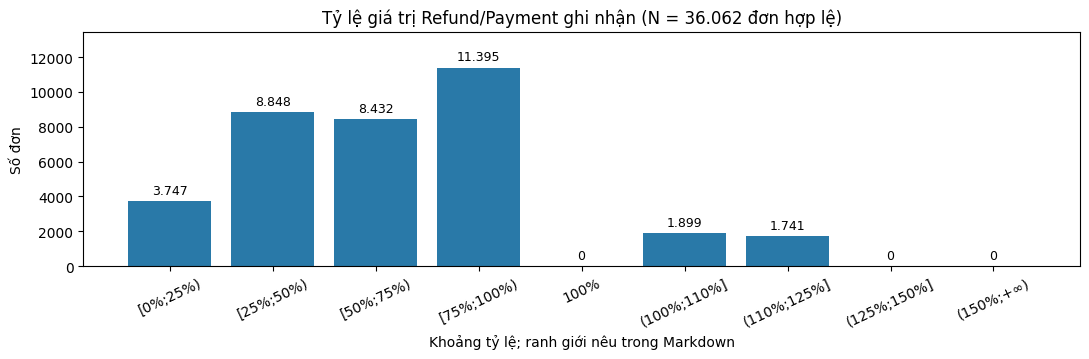

**Quan sát:** A=32.422, B=0, C=3.640, D=0 đơn; 3.640 đơn có tỷ lệ >100% trên 36.062 mẫu số hợp lệ. **Ý nghĩa đối soát:** nhóm C là danh sách giá trị cần kiểm tra; bảng giữ cả nhóm rỗng, tổng và mẫu số. **Giới hạn/câu hỏi:** ngưỡng số học không thay thế chính sách; phạm vi Refund và Payment có cùng cơ sở ghi nhận và quyết toán không?

In [15]:
def classify042(refund_value, payment_value, tol=TOL):
    r = ratio042(refund_value,payment_value)
    if r is None: return "D",None,None
    d = refund_value-payment_value
    return ("C" if d > tol else "A" if d < -tol else "B"),d,r
classified042 = [classify042(r,p) for r,p in zip(has042["refund_total"],has042["payment_value"])]
has042["group"] = [v[0] for v in classified042]
has042["Difference"] = [v[1] for v in classified042]
has042["RefundToPaymentRatio"] = [v[2] for v in classified042]
group_labels042 = {"A":"Thấp hơn Payment quá dung sai","B":"Xấp xỉ Payment trong dung sai",
                   "C":"Cao hơn Payment quá dung sai","D":"Không thể so sánh"}
group_rows042=[]
for group,label in group_labels042.items():
    part=has042.loc[has042["group"].eq(group)]
    ratios=list(part["RefundToPaymentRatio"].dropna())
    group_rows042.append({"Nhóm":group,"Diễn giải":label,"Số đơn":len(part),"% / đơn có returns":pct(len(part),len(has042)),
       "Payment (ĐVT)":sum(part["payment_value"],ZERO),"Refund (ĐVT)":sum(part["refund_total"],ZERO),
       "Difference tổng (ĐVT)":sum(part["Difference"].dropna(),ZERO) if len(part) else None,
       "Mean tỷ lệ (%)":100*mean042(ratios) if ratios else None,
       "Median tỷ lệ (%)":100*q042(ratios,.5) if ratios else None})
groups042=pd.DataFrame(group_rows042)
show(groups042,{**fmt_money042(groups042),"% / đơn có returns":lambda x:vn(x,3)+"%",
                "Mean tỷ lệ (%)":lambda x:vn(x,3),"Median tỷ lệ (%)":lambda x:vn(x,3)})
ratio_labels042=["[0%;25%)","[25%;50%)","[50%;75%)","[75%;100%)","100%","(100%;110%]","(110%;125%]","(125%;150%]","(150%;+∞)","Không hợp lệ"]
def ratio_bucket042(x):
    if x is None or not finite042(x):return "Không hợp lệ"
    for edge,label in zip([Decimal(".25"),Decimal(".5"),Decimal(".75"),Decimal("1")],ratio_labels042[:4]):
        if x<edge:return label
    if x==1:return "100%"
    for edge,label in zip([Decimal("1.10"),Decimal("1.25"),Decimal("1.5")],ratio_labels042[5:8]):
        if x<=edge:return label
    return "(150%;+∞)"
ratio_counter042=Counter(ratio_bucket042(x) for x in has042["RefundToPaymentRatio"])
ratio_distribution042=pd.DataFrame([{"Khoảng Refund/Payment":k,"Số đơn":ratio_counter042[k],
     "% / đơn có returns":pct(ratio_counter042[k],len(has042))} for k in ratio_labels042])
show(ratio_distribution042,{"% / đơn có returns":lambda x:vn(x,3)+"%"})
valid_ratios042=list(has042["RefundToPaymentRatio"].dropna())
strict_above100042=sum(x>1 for x in valid_ratios042)
fig,ax=plt.subplots(figsize=(11,3.7))
bars=ax.bar(ratio_labels042[:-1],[ratio_counter042[k] for k in ratio_labels042[:-1]],color="#2979a8")
ax.bar_label(bars,labels=[vn(ratio_counter042[k]) for k in ratio_labels042[:-1]],padding=3,fontsize=9)
ax.tick_params(axis="x",rotation=25)
ax.set(title=f"Tỷ lệ giá trị Refund/Payment ghi nhận (N = {vn(len(valid_ratios042))} đơn hợp lệ)",
       xlabel="Khoảng tỷ lệ; ranh giới nêu trong Markdown",ylabel="Số đơn")
ax.set_ylim(0,max(ratio_counter042.values())*1.18)
plot_done(fig)
note(f"**Quan sát:** A={vn(int(groups042.iloc[0]['Số đơn']))}, B={vn(int(groups042.iloc[1]['Số đơn']))}, "
     f"C={vn(int(groups042.iloc[2]['Số đơn']))}, D={vn(int(groups042.iloc[3]['Số đơn']))} đơn; "
     f"{vn(strict_above100042)} đơn có tỷ lệ >100% trên {vn(len(valid_ratios042))} mẫu số hợp lệ. "
     "**Ý nghĩa đối soát:** nhóm C là danh sách giá trị cần kiểm tra; bảng giữ cả nhóm rỗng, tổng và mẫu số. "
     "**Giới hạn/câu hỏi:** ngưỡng số học không thay thế chính sách; phạm vi Refund và Payment có cùng cơ sở ghi nhận và quyết toán không?")

### NV04.2.4 – Đặc điểm nhóm vượt Payment hơn 0,05 ĐVT

Chỉ cộng phần vượt dương của C; không bù trừ với Difference âm của A. Đối chiếu C với các đơn có returns đủ điều kiện thuộc A/B; D được báo riêng. Các tỷ lệ một/nhiều dòng có mẫu số nhóm tương ứng.

Các ví dụ: 5 đơn Difference lớn nhất và 5 đơn nhỏ nhất trong C, xử lý đồng hạng bằng order_id chuỗi tăng dần. Kiểm tra số dòng returns và số dòng items mô tả liên hệ, không chứng minh nguyên nhân. Khoảng phần vượt: (0,05;1), [1;100), [100;1.000), [1.000;5.000), [5.000;+∞) ĐVT; ranh giới chỉ phục vụ đọc độ lớn.


Chỉ tiêu,Giá trị,Đơn vị/mẫu số
Đơn C,3.640,Đơn
Tỷ trọng C / đơn có returns,"10,094",% / đơn có returns
Tỷ trọng C / mọi đơn,"0,563",% / mọi đơn
Tổng Payment C,"44.430.433,22",ĐVT
Tổng Refund C,"48.739.243,73",ĐVT
Tổng phần vượt dương C,"4.308.810,51",ĐVT
Mean phần vượt/đơn C,"1.183,74",ĐVT
Median phần vượt/đơn C,"584,16",ĐVT
Min phần vượt C,"0,08",ĐVT
Max phần vượt C,"17.624,41",ĐVT


Nhóm,Số đơn,Đơn nhiều dòng returns,% nhiều returns / nhóm,Đơn nhiều dòng items,% nhiều items / nhóm,Median Refund (ĐVT),Mean tỷ lệ (%)
C: vượt,3640,216,"5,93%",216,"5,93%","7.918,65","110,348"
A/B: không vượt,32422,3585,"11,06%",3592,"11,08%","9.372,75","60,635"


Dòng returns/đơn,A,B,C,D,% C / cùng số dòng
1,28837,0,3424,0,"10,613%"
2,3513,0,212,0,"5,691%"
3,72,0,4,0,"5,263%"


order_id,order_date,return_line_count,item_line_count,Payment (ĐVT),Refund (ĐVT),Phần vượt (ĐVT),Refund/Payment,Tiêu chí chọn
641678,2018-12-12,1,1,"77.077,95","94.702,36","17.624,41","122,866%",5 phần vượt lớn nhất
768303,2021-06-28,1,1,"77.850,59","94.221,47","16.370,88","121,029%",5 phần vượt lớn nhất
787784,2022-01-01,1,1,"90.797,47","105.373,06","14.575,59","116,053%",5 phần vượt lớn nhất
446386,2016-11-19,1,1,"59.826,96","74.066,79","14.239,83","123,802%",5 phần vượt lớn nhất
238896,2014-12-15,1,1,"58.301,06","71.845,82","13.544,76","123,232%",5 phần vượt lớn nhất
350024,2015-12-28,1,1,"3.903,46","3.903,54","0,08","100,002%",5 phần vượt nhỏ nhất
472592,2017-03-23,1,1,"2.723,05","2.723,17","0,12","100,004%",5 phần vượt nhỏ nhất
119753,2013-09-30,1,1,"2.607,16","2.607,49","0,33","100,013%",5 phần vượt nhỏ nhất
254274,2015-02-24,1,1,"583,16","583,53","0,37","100,063%",5 phần vượt nhỏ nhất
326228,2015-09-25,2,2,"4.343,03","4.343,42","0,39","100,009%",5 phần vượt nhỏ nhất


Khoảng phần vượt (ĐVT),Số đơn,% / C,Tổng phần vượt (ĐVT)
"(0,05;1)",7,"0,192%","2,42"
[1;100),409,"11,236%","21.011,07"
[100;1.000),1989,"54,643%","882.349,05"
[1.000;5.000),1101,"30,247%","2.397.628,32"
[5.000;+∞),134,"3,681%","1.007.819,65"


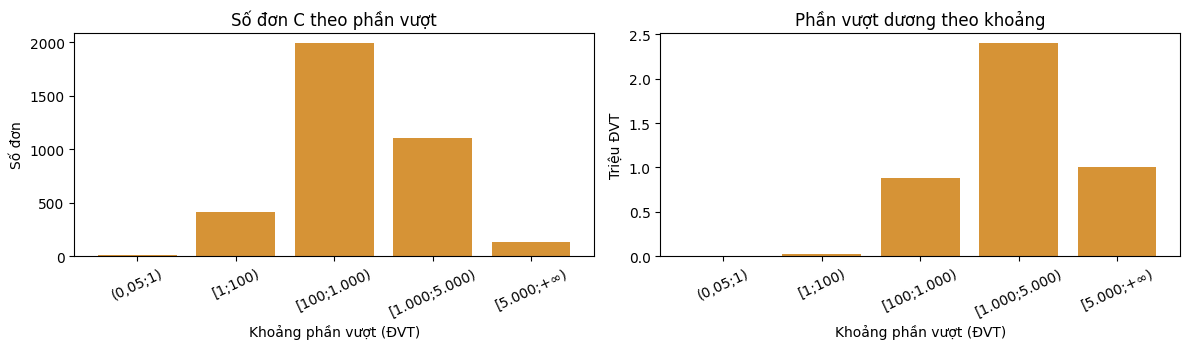

**Quan sát:** 3.640 đơn C, tổng phần vượt dương 4.308.810,51 ĐVT; min–max 0,08–17.624,41 ĐVT; median 584,16 ĐVT. Top 1% C chọn ceil(0,01×N)=37 đơn, chiếm 9,13% tổng phần vượt. Nhiều dòng returns: C 5,93%, A/B 11,06%; nhiều dòng items: C 5,93%, A/B 11,08%. **Ý nghĩa đối soát:** vừa có mức vượt nhỏ vừa có mức lớn; cần tách số đơn khỏi giá trị vượt và kiểm tra cấu trúc dòng. **Giới hạn/câu hỏi:** đây là khác biệt mô tả, chưa xác định nguyên nhân hay tổn thất; quy tắc ghi nhận nào giải thích từng mức?

In [16]:
over042=has042.loc[has042["group"].eq("C")].copy()
nonover042=has042.loc[has042["group"].isin(["A","B"])].copy()
over_total042=sum(over042["Difference"],ZERO)
over_summary042=pd.DataFrame([
 {"Chỉ tiêu":"Đơn C","Giá trị":vn(len(over042)),"Đơn vị/mẫu số":"Đơn"},
 {"Chỉ tiêu":"Tỷ trọng C / đơn có returns","Giá trị":vn(pct(len(over042),len(has042)),3),"Đơn vị/mẫu số":"% / đơn có returns"},
 {"Chỉ tiêu":"Tỷ trọng C / mọi đơn","Giá trị":vn(pct(len(over042),len(ledger042)),3),"Đơn vị/mẫu số":"% / mọi đơn"},
 *[{"Chỉ tiêu":label,"Giá trị":vn(value,2),"Đơn vị/mẫu số":"ĐVT"} for label,value in [
  ("Tổng Payment C",sum(over042["payment_value"],ZERO)),("Tổng Refund C",sum(over042["refund_total"],ZERO)),
  ("Tổng phần vượt dương C",over_total042),("Mean phần vượt/đơn C",mean042(over042["Difference"])),
  ("Median phần vượt/đơn C",q042(over042["Difference"],.5)),("Min phần vượt C",min(over042["Difference"])),
  ("Max phần vượt C",max(over042["Difference"])),("P90 phần vượt C",q042(over042["Difference"],.9)),
  ("P95 phần vượt C",q042(over042["Difference"],.95)),("P99 phần vượt C",q042(over042["Difference"],.99))]],
 *[{"Chỉ tiêu":label,"Giá trị":vn(100*value,3),"Đơn vị/mẫu số":"% / Payment từng đơn C"} for label,value in [
  ("Mean tỷ lệ C",mean042(over042["RefundToPaymentRatio"])),("Median tỷ lệ C",q042(over042["RefundToPaymentRatio"],.5)),
  ("Min tỷ lệ C",min(over042["RefundToPaymentRatio"])),("Max tỷ lệ C",max(over042["RefundToPaymentRatio"]))]]])
show(over_summary042)
comparison_rows042=[]
for label,part in [("C: vượt",over042),("A/B: không vượt",nonover042)]:
    comparison_rows042.append({"Nhóm":label,"Số đơn":len(part),
      "Đơn nhiều dòng returns":int(part["return_line_count"].gt(1).sum()),
      "% nhiều returns / nhóm":pct(int(part["return_line_count"].gt(1).sum()),len(part)),
      "Đơn nhiều dòng items":int(part["item_line_count"].gt(1).sum()),
      "% nhiều items / nhóm":pct(int(part["item_line_count"].gt(1).sum()),len(part)),
      "Median Refund (ĐVT)":q042(part["refund_total"],.5),
      "Mean tỷ lệ (%)":100*mean042(part["RefundToPaymentRatio"])})
comparison042=pd.DataFrame(comparison_rows042)
show(comparison042,{**fmt_money042(comparison042),"% nhiều returns / nhóm":lambda x:vn(x,2)+"%",
                    "% nhiều items / nhóm":lambda x:vn(x,2)+"%","Mean tỷ lệ (%)":lambda x:vn(x,3)})
line_comparison042=pd.crosstab(has042["return_line_count"],has042["group"]).reindex(columns=["A","B","C","D"],fill_value=0)
line_comparison042["% C / cùng số dòng"]=100*line_comparison042["C"]/line_comparison042.sum(axis=1)
show(line_comparison042.reset_index().rename(columns={"return_line_count":"Dòng returns/đơn"}),
 {"% C / cùng số dòng":lambda x:vn(x,3)+"%"})
example_cols042=["order_id","order_date","return_line_count","item_line_count","payment_value","refund_total","Difference","RefundToPaymentRatio"]
example_large042=over042.sort_values(["Difference","order_id"],ascending=[False,True]).head(5)[example_cols042].assign(Tiêu_chí="5 phần vượt lớn nhất")
example_small042=over042.sort_values(["Difference","order_id"],ascending=[True,True]).head(5)[example_cols042].assign(Tiêu_chí="5 phần vượt nhỏ nhất")
examples042=pd.concat([example_large042,example_small042],ignore_index=True).rename(columns={
 "payment_value":"Payment (ĐVT)","refund_total":"Refund (ĐVT)","Difference":"Phần vượt (ĐVT)",
 "RefundToPaymentRatio":"Refund/Payment","Tiêu_chí":"Tiêu chí chọn"})
show(examples042,{**fmt_money042(examples042),"Refund/Payment":lambda x:vn(x*100,3)+"%"})
excess_labels042=["(0,05;1)","[1;100)","[100;1.000)","[1.000;5.000)","[5.000;+∞)"]
def excess_bucket042(x):
    for edge,label in zip([Decimal("1"),Decimal("100"),Decimal("1000"),Decimal("5000")],excess_labels042[:-1]):
        if x<edge:return label
    return excess_labels042[-1]
excess_buckets042=over042["Difference"].map(excess_bucket042)
excess_dist042=pd.DataFrame([{"Khoảng phần vượt (ĐVT)":label,"Số đơn":int(excess_buckets042.eq(label).sum()),
 "% / C":pct(int(excess_buckets042.eq(label).sum()),len(over042)),
 "Tổng phần vượt (ĐVT)":sum(over042.loc[excess_buckets042.eq(label),"Difference"],ZERO)}
 for label in excess_labels042])
show(excess_dist042,{**fmt_money042(excess_dist042),"% / C":lambda x:vn(x,3)+"%"})
fig,axes=plt.subplots(1,2,figsize=(12,3.6))
for ax,col,title in zip(axes,["Số đơn","Tổng phần vượt (ĐVT)"],["Số đơn C theo phần vượt","Phần vượt dương theo khoảng"]):
    values=excess_dist042[col].map(float)
    if col.endswith("(ĐVT)"):values=values/1e6
    ax.bar(excess_labels042,values,color="#d69336")
    ax.tick_params(axis="x",rotation=25)
    ax.set(title=title,xlabel="Khoảng phần vượt (ĐVT)",ylabel="Triệu ĐVT" if col.endswith("(ĐVT)") else "Số đơn")
plot_done(fig)
sorted_excess042=over042.sort_values(["Difference","order_id"],ascending=[False,True])
top_excess_n042=math.ceil(len(over042)*.01)
top_excess_total042=sum(sorted_excess042.head(top_excess_n042)["Difference"],ZERO)
note(f"**Quan sát:** {vn(len(over042))} đơn C, tổng phần vượt dương {vn(over_total042,2)} ĐVT; "
     f"min–max {vn(min(over042['Difference']),2)}–{vn(max(over042['Difference']),2)} ĐVT; "
     f"median {vn(q042(over042['Difference'],.5),2)} ĐVT. Top 1% C chọn ceil(0,01×N)={top_excess_n042} đơn, "
     f"chiếm {vn(100*top_excess_total042/over_total042,2)}% tổng phần vượt. "
     f"Nhiều dòng returns: C {vn(comparison042.iloc[0]['% nhiều returns / nhóm'],2)}%, "
     f"A/B {vn(comparison042.iloc[1]['% nhiều returns / nhóm'],2)}%; "
     f"nhiều dòng items: C {vn(comparison042.iloc[0]['% nhiều items / nhóm'],2)}%, "
     f"A/B {vn(comparison042.iloc[1]['% nhiều items / nhóm'],2)}%. "
     "**Ý nghĩa đối soát:** vừa có mức vượt nhỏ vừa có mức lớn; cần tách số đơn khỏi giá trị vượt và kiểm tra cấu trúc dòng. "
     "**Giới hạn/câu hỏi:** đây là khác biệt mô tả, chưa xác định nguyên nhân hay tổn thất; quy tắc ghi nhận nào giải thích từng mức?")

#### Đặc điểm thời gian của nhóm C

Theo **năm đặt đơn**, đếm C và đơn có returns trong cùng năm, kèm tỷ trọng và phần vượt dương. Theo **năm return_date**, cộng các dòng và Refund thực sự ghi ở từng năm; mã đơn có thể xuất hiện ở nhiều năm nên không cộng khách/đơn phân biệt giữa các năm.

Không gán toàn bộ phần vượt cấp đơn vào từng dòng returns hoặc nhân bản tiền qua nhiều ngày. Năm 2012 chỉ có một phần lịch sử; các bảng là mô tả phạm vi, không đo hiệu suất hay nguyên nhân thay đổi.


In [17]:
time_work042=has042.assign(order_year=has042["order_date"].str[:4])
time_rows042=[]
for year,part in time_work042.groupby("order_year",sort=True):
    part_c=part.loc[part["group"].eq("C")]
    time_rows042.append({"Năm đặt":year,"Đơn có returns":len(part),"Đơn C":len(part_c),
     "% C / đơn có returns cùng năm":pct(len(part_c),len(part)),
     "Refund C (ĐVT)":sum(part_c["refund_total"],ZERO),"Phần vượt C (ĐVT)":sum(part_c["Difference"],ZERO)})
order_year042=pd.DataFrame(time_rows042)
show(order_year042,{**fmt_money042(order_year042),"% C / đơn có returns cùng năm":lambda x:vn(x,3)+"%"})
return_time042=return_lines042.assign(return_year=return_lines042["return_date"].str[:4],
                                     is_C=return_lines042["order_id"].isin(set(over042["order_id"])))
return_year_rows042=[]
for year,part in return_time042.groupby("return_year",sort=True):
    selected=part.loc[part["is_C"]]
    return_year_rows042.append({"Năm return_date":year,"Dòng returns":len(part),"Dòng thuộc đơn C":len(selected),
     "Đơn C phân biệt trong năm":selected["order_id"].nunique(),
     "Refund mọi dòng (ĐVT)":sum(part["refund"],ZERO),"Refund dòng thuộc C (ĐVT)":sum(selected["refund"],ZERO)})
return_year042=pd.DataFrame(return_year_rows042)
show(return_year042,fmt_money042(return_year042))
note(f"**Quan sát:** C có mặt ở {int(order_year042['Đơn C'].gt(0).sum())}/{len(order_year042)} năm đặt có returns; "
     f"năm có tỷ trọng C cao nhất là {order_year042.loc[order_year042['% C / đơn có returns cùng năm'].idxmax(),'Năm đặt']}. "
     f"Tổng phần vượt theo năm đặt vẫn {vn(sum(order_year042['Phần vượt C (ĐVT)'],ZERO),2)} ĐVT. "
     "**Ý nghĩa đối soát:** kiểm tra được vấn đề có trải qua nhiều giai đoạn; tổng Refund theo return_date không lặp tiền theo đơn. "
     "**Giới hạn/câu hỏi:** không suy nguyên nhân từ năm ghi nhận; cần thời điểm cập nhật và chính sách tiền để kiểm tra sự khác biệt.")

Năm đặt,Đơn có returns,Đơn C,% C / đơn có returns cùng năm,Refund C (ĐVT),Phần vượt C (ĐVT)
2012,1819,0,"0,000%","0,00","0,00"
2013,4323,511,"11,820%","5.789.567,69","506.995,46"
2014,4484,469,"10,459%","5.678.644,79","500.878,69"
2015,4621,517,"11,188%","6.801.118,74","586.187,78"
2016,4655,464,"9,968%","6.019.787,99","544.637,92"
2017,4247,473,"11,137%","6.406.165,50","579.261,81"
2018,3803,358,"9,414%","5.290.638,49","476.486,73"
2019,2300,255,"11,087%","3.383.242,59","283.429,42"
2020,1950,193,"9,897%","2.889.849,94","253.058,87"
2021,1918,220,"11,470%","3.777.995,40","353.776,03"


Năm return_date,Dòng returns,Dòng thuộc đơn C,Đơn C phân biệt trong năm,Refund mọi dòng (ĐVT),Refund dòng thuộc C (ĐVT)
2012,1790,0,0,"21.122.057,99","0,00"
2013,4933,433,408,"52.335.590,49","4.838.853,13"
2014,5073,516,476,"57.928.041,21","5.683.368,91"
2015,5200,583,551,"60.792.331,98","7.163.506,45"
2016,5176,458,436,"66.237.094,66","5.541.315,51"
2017,4782,525,494,"59.752.530,03","6.703.089,07"
2018,4226,422,405,"56.725.369,68","5.763.254,73"
2019,2495,264,255,"35.316.106,33","3.226.346,88"
2020,2084,209,197,"32.430.506,37","3.048.036,16"
2021,2030,223,208,"32.246.641,98","3.535.373,13"


**Quan sát:** C có mặt ở 10/11 năm đặt có returns; năm có tỷ trọng C cao nhất là 2013. Tổng phần vượt theo năm đặt vẫn 4.308.810,51 ĐVT. **Ý nghĩa đối soát:** kiểm tra được vấn đề có trải qua nhiều giai đoạn; tổng Refund theo return_date không lặp tiền theo đơn. **Giới hạn/câu hỏi:** không suy nguyên nhân từ năm ghi nhận; cần thời điểm cập nhật và chính sách tiền để kiểm tra sự khác biệt.

### NV04.2.5 – Đối chiếu cặp đơn–sản phẩm, giữ nguyên các cặp lặp

Kiểm tra lại số dòng/cặp ở mỗi bảng trước JOIN. Tổng hợp riêng về (order_id, product_id): lượng mua ghi nhận, GrossPurchased, DiscountPurchased, NetPurchased; lượng trả ghi nhận, RefundPair và số dòng. JOIN one_to_one giữa bảng cặp; không ghép hai bảng chi tiết.

Kiểm tra lượng trả ≤ lượng mua theo đúng cùng mã sản phẩm; tổng số lượng giữa nhiều sản phẩm chỉ là đối chứng số học. So RefundPair với **toàn bộ giá trị mua của cặp**, không gọi đó là giá trị tương ứng phần thực trả. DiscountPurchased là tổng giảm giá dòng theo V02, không nhân quantity và không tự phân bổ giảm giá của đơn hoặc lô trả. Cặp nhiều mức giá chưa xác định được lô/dòng thực trả.

Đối chiếu đại số khi Payment=Net: Difference = DiscountOrder − (GrossOrder − RefundRecorded). Công thức này giải thích sự đồng tồn tại về số học, **chưa xác định vì sao** dữ liệu được ghi như vậy hoặc hoàn tiền đúng chính sách.


In [18]:
return_pair042=return_lines042.groupby(["order_id","product_id"],sort=True).agg(
    returned_quantity=("return_quantity","sum"),RefundPair=("refund","sum"),return_pair_lines=("return_id","size"))
item_pair042=item_lines042.groupby(["order_id","product_id"],sort=True).agg(
    purchased_quantity=("quantity","sum"),GrossPurchased=("gross","sum"),
    DiscountPurchased=("discount","sum"),item_pair_lines=("quantity","size"))
item_pair042["NetPurchased"]=item_pair042["GrossPurchased"]-item_pair042["DiscountPurchased"]
price_counts042=items[["order_id","product_id"]].assign(
    price=numeric_values[("order_items","unit_price")]).groupby(["order_id","product_id"],sort=True)["price"].nunique()
item_pair042=item_pair042.join(price_counts042.rename("price_count"),validate="one_to_one")
repeat_pair_counts042={"returns":int(return_pair042["return_pair_lines"].gt(1).sum()),
                       "order_items":int(item_pair042["item_pair_lines"].gt(1).sum())}
show(pd.DataFrame([{"Nguồn":name,"Số cặp":len(f),"Cặp lặp":repeat_pair_counts042[name],
 "Dòng gốc bảo toàn":int(f[col].sum())} for name,f,col in [
 ("returns",return_pair042,"return_pair_lines"),("order_items",item_pair042,"item_pair_lines")]]))
pairs042=return_pair042.reset_index().merge(item_pair042.reset_index(),
    on=["order_id","product_id"],how="left",validate="one_to_one",indicator=True)
pair_orphan042=pairs042["_merge"].ne("both")
pairs042["quantity_excess"]=pairs042["returned_quantity"]-pairs042["purchased_quantity"]
pairs042["refund_above_gross"]=pairs042["RefundPair"]-pairs042["GrossPurchased"]>TOL
pairs042["refund_above_net"]=pairs042["RefundPair"]-pairs042["NetPurchased"]>TOL
pairs042["is_C"]=pairs042["order_id"].isin(set(over042["order_id"]))
pair_checks042=pd.DataFrame([
 {"Kiểm tra":label,"Cặp liên quan":int(mask.sum()),"Mẫu số cặp":len(pairs042),
  "Đơn phân biệt":pairs042.loc[mask,"order_id"].nunique(),
  "Trong đó đơn C":pairs042.loc[mask & pairs042["is_C"],"order_id"].nunique(),
  "Refund các cặp liên quan (ĐVT)":sum(pairs042.loc[mask,"RefundPair"],ZERO)}
 for label,mask in [
 ("Cặp không liên kết được",pair_orphan042),("Lượng trả > lượng mua",pairs042["quantity_excess"].gt(0)),
 ("RefundPair > GrossPurchased + dung sai",pairs042["refund_above_gross"]),
 ("RefundPair > NetPurchased + dung sai",pairs042["refund_above_net"]),
 ("Cặp trả có nhiều mức giá mua",pairs042["price_count"].gt(1))]])
show(pair_checks042,fmt_money042(pair_checks042))
ambiguous_pairs042=pairs042.loc[pairs042["return_pair_lines"].gt(1)|pairs042["item_pair_lines"].gt(1)]
show(ambiguous_pairs042[["order_id","product_id","return_pair_lines","item_pair_lines","price_count",
      "returned_quantity","purchased_quantity","RefundPair","GrossPurchased","DiscountPurchased","NetPurchased"]].head(10).rename(
  columns={k:k+" (ĐVT)" for k in ["RefundPair","GrossPurchased","DiscountPurchased","NetPurchased"]}),
 {k+" (ĐVT)":lambda x:vn(x,2) for k in ["RefundPair","GrossPurchased","DiscountPurchased","NetPurchased"]})
algebra042=over042["DiscountOrder"]-(over042["GrossOrder"]-over042["refund_total"])
c_with_net_pair042=set(pairs042.loc[pairs042["is_C"] & pairs042["refund_above_net"],"order_id"])
show(pd.DataFrame([
 {"Kiểm tra trong C": "Payment = Net chính xác", "Số đơn": int((over042["payment_value"]==over042["NetOrder"]).sum()),"Mẫu số":len(over042)},
 {"Kiểm tra trong C": "Refund không vượt GrossOrder quá dung sai", "Số đơn":int((over042["refund_total"]-over042["GrossOrder"]<=TOL).sum()),"Mẫu số":len(over042)},
 {"Kiểm tra trong C": "Ít nhất một cặp RefundPair > NetPurchased + dung sai","Số đơn":len(c_with_net_pair042),"Mẫu số":len(over042)},
 {"Kiểm tra trong C": "Difference = Discount − (Gross − Refund) chính xác","Số đơn":int((algebra042==over042["Difference"]).sum()),"Mẫu số":len(over042)}]))
note(f"**Quan sát:** {repeat_pair_counts042['returns']} cặp returns lặp và {repeat_pair_counts042['order_items']} cặp items lặp; "
     f"{int(pair_orphan042.sum())} cặp mồ côi; {int(pairs042['quantity_excess'].gt(0).sum())} cặp lượng trả vượt lượng mua; "
     f"{int(pairs042['refund_above_gross'].sum())} cặp Refund vượt GrossPurchased và "
     f"{vn(int(pairs042['refund_above_net'].sum()))} cặp vượt NetPurchased hơn {vn(TOL,2)} ĐVT. "
     f"Có {vn(len(c_with_net_pair042))}/{vn(len(over042))} đơn C chứa ít nhất một cặp vượt NetPurchased. "
     "**Ý nghĩa đối soát:** cặp sản phẩm giúp khoanh vùng chênh lệch về giá trị trước/sau giảm giá mà không nhân bản dòng. "
     "**Giới hạn/câu hỏi:** đẳng thức đại số không chứng minh nguyên nhân, chính sách hay lô trả; "
     "cần quy tắc hoàn theo giá trước/sau giảm và phạm vi phí/quyết toán. Không coi các khả năng này là lời giải thích đã xác minh.")

Nguồn,Số cặp,Cặp lặp,Dòng gốc bảo toàn
returns,39937,2,39939
order_items,714653,16,714669


Kiểm tra,Cặp liên quan,Mẫu số cặp,Đơn phân biệt,Trong đó đơn C,Refund các cặp liên quan (ĐVT)
Cặp không liên kết được,0,39937,0,0,"0,00"
Lượng trả > lượng mua,0,39937,0,0,"0,00"
RefundPair > GrossPurchased + dung sai,0,39937,0,0,"0,00"
RefundPair > NetPurchased + dung sai,4423,39937,4267,3640,"51.482.378,04"
Cặp trả có nhiều mức giá mua,2,39937,2,0,"61.813,04"


order_id,product_id,return_pair_lines,item_pair_lines,price_count,returned_quantity,purchased_quantity,RefundPair (ĐVT),GrossPurchased (ĐVT),DiscountPurchased (ĐVT),NetPurchased (ĐVT)
397622,2045,2,2,2,11,14,"57.690,97","78.577,88","0,00","78.577,88"
698128,1009,2,2,2,4,5,"4.122,07","5.403,65","1.080,73","4.322,92"


Kiểm tra trong C,Số đơn,Mẫu số
Payment = Net chính xác,3640,3640
Refund không vượt GrossOrder quá dung sai,3640,3640
Ít nhất một cặp RefundPair > NetPurchased + dung sai,3640,3640
Difference = Discount − (Gross − Refund) chính xác,3640,3640


**Quan sát:** 2 cặp returns lặp và 16 cặp items lặp; 0 cặp mồ côi; 0 cặp lượng trả vượt lượng mua; 0 cặp Refund vượt GrossPurchased và 4.423 cặp vượt NetPurchased hơn 0,05 ĐVT. Có 3.640/3.640 đơn C chứa ít nhất một cặp vượt NetPurchased. **Ý nghĩa đối soát:** cặp sản phẩm giúp khoanh vùng chênh lệch về giá trị trước/sau giảm giá mà không nhân bản dòng. **Giới hạn/câu hỏi:** đẳng thức đại số không chứng minh nguyên nhân, chính sách hay lô trả; cần quy tắc hoàn theo giá trước/sau giảm và phạm vi phí/quyết toán. Không coi các khả năng này là lời giải thích đã xác minh.

### NV04.2.6 – Tỷ trọng Refund trong ba phạm vi giá trị ghi nhận

Tách A: mọi đơn; B: đơn có returns; C: nhãn returned (kể cả đơn chưa có returns). Tổng Refund của đơn không có dòng là tổng rỗng 0 trong nguồn; không chứng minh không có khoản hoàn ngoài nguồn.

**Tỷ lệ từ tổng** = ΣRefund/ΣPayment (hoặc ΣRefund/ΣNet). **Mean tỷ lệ cấp đơn** = trung bình không trọng số Refund_i/Payment_i trên các đơn có returns hợp lệ trong chính phạm vi đó. Cột mẫu số phân biệt rõ hai chỉ tiêu; tỷ lệ từ tổng là bình quân có trọng số Payment khi đủ điều kiện, không phải mean không trọng số.

Không tính Payment − Refund làm chỉ tiêu kinh doanh; không suy doanh thu, thực thu, dòng tiền hoặc lợi nhuận từ các tổng ghi nhận.


In [19]:
scope_rows042=[]
scope_ids042={}
for key,label,mask in [
 ("A","A: mọi đơn",pd.Series(True,index=ledger042.index)),
 ("B","B: có returns",ledger042["has_return"]),
 ("C","C: nhãn returned",ledger042["order_status"].eq("returned"))]:
    part=ledger042.loc[mask]
    scope_ids042[key]=set(part["order_id"])
    net=sum(part["NetOrder"],ZERO);pay=sum(part["payment_value"],ZERO);ref=sum(part["refund_total"],ZERO)
    selected=has042.loc[has042["order_id"].isin(scope_ids042[key])]
    values=list(selected["RefundToPaymentRatio"].dropna())
    scope_rows042.append({"Phạm vi":label,"Số đơn":len(part),"Đơn có dòng refund":int(part["has_return"].sum()),
       "Net (ĐVT)":net,"Payment (ĐVT)":pay,"Refund ghi nhận (ĐVT)":ref,
       "ΣRefund/ΣPayment (%)":100*ratio042(ref,pay),"ΣRefund/ΣNet (%)":100*ratio042(ref,net),
       "Mean tỷ lệ đơn có returns (%)":100*mean042(values),"Mẫu số mean tỷ lệ":len(values)})
scopes042=pd.DataFrame(scope_rows042)
show(scopes042,{**fmt_money042(scopes042),
               **{k:lambda x:vn(x,4) for k in ["ΣRefund/ΣPayment (%)","ΣRefund/ΣNet (%)","Mean tỷ lệ đơn có returns (%)"]}})
note(f"**Quan sát:** ΣRefund/ΣPayment toàn bộ đơn {vn(scopes042.iloc[0]['ΣRefund/ΣPayment (%)'],4)}%; "
     f"chỉ đơn có returns {vn(scopes042.iloc[1]['ΣRefund/ΣPayment (%)'],4)}%; "
     f"nhãn returned {vn(scopes042.iloc[2]['ΣRefund/ΣPayment (%)'],4)}%. "
     f"Mean tỷ lệ không trọng số trong mẫu có returns là {vn(scopes042.iloc[1]['Mean tỷ lệ đơn có returns (%)'],4)}%. "
     "**Ý nghĩa đối soát:** mẫu số thay đổi dù tổng Refund có thể bằng nhau; 80 đơn returned thiếu dòng vẫn thuộc mẫu số trạng thái. "
     "**Giới hạn/câu hỏi:** các tỷ trọng chỉ đo giá trị ghi nhận trong nguồn, chưa là tỷ lệ tiền thực hoàn hay doanh thu; cần xác minh định nghĩa và độ đầy đủ các bảng.")

Phạm vi,Số đơn,Đơn có dòng refund,Net (ĐVT),Payment (ĐVT),Refund ghi nhận (ĐVT),ΣRefund/ΣPayment (%),ΣRefund/ΣNet (%),Mean tỷ lệ đơn có returns (%),Mẫu số mean tỷ lệ
A: mọi đơn,646945,36062,"15.680.869.265,43","15.680.869.265,43","510.598.506,55","3,2562","3,2562","65,6526",36062
B: có returns,36062,36062,"864.154.471,35","864.154.471,35","510.598.506,55","59,0865","59,0865","65,6526",36062
C: nhãn returned,36142,36062,"865.938.715,59","865.938.715,59","510.598.506,55","58,9647","58,9647","65,6526",36062


**Quan sát:** ΣRefund/ΣPayment toàn bộ đơn 3,2562%; chỉ đơn có returns 59,0865%; nhãn returned 58,9647%. Mean tỷ lệ không trọng số trong mẫu có returns là 65,6526%. **Ý nghĩa đối soát:** mẫu số thay đổi dù tổng Refund có thể bằng nhau; 80 đơn returned thiếu dòng vẫn thuộc mẫu số trạng thái. **Giới hạn/câu hỏi:** các tỷ trọng chỉ đo giá trị ghi nhận trong nguồn, chưa là tỷ lệ tiền thực hoàn hay doanh thu; cần xác minh định nghĩa và độ đầy đủ các bảng.

### NV04.2.7 – Mức tập trung Refund và phân biệt hai cách xếp hạng

Top 1%, 5%, 10% được lấy trên **số đơn có returns**, số phần tử = ceil(p×N); xếp Refund/đơn giảm dần, đồng hạng dùng order_id chuỗi tăng dần. Các top lồng nhau, không cộng tỷ trọng giữa các hàng.

So sánh thêm tổng và median Refund theo số dòng returns/đơn. Hai danh sách top 10 theo Refund tuyệt đối và theo Refund/Payment có thể khác nhau; tỷ lệ lớn trên đơn giá trị nhỏ không đồng nghĩa Refund tuyệt đối lớn. Đường tích lũy chỉ mô tả độ tập trung, không biểu diễn tổn thất hay quy trách nhiệm cho khách/sản phẩm.


Top theo số đơn (%),Số đơn (ceil),Refund top (ĐVT),% / tổng Refund
1.000000,361,"29.817.328,26","5,840%"
5.000000,1804,"107.678.743,67","21,089%"
10.000000,3607,"176.289.039,86","34,526%"


Dòng returns/đơn,Số đơn,Refund (ĐVT),Median Refund/đơn (ĐVT),% / tổng Refund
1,32261,"464.817.281,43","9.419,72","91,034%"
2,3725,"43.864.036,88","7.565,53","8,591%"
3,76,"1.917.188,24","17.953,54","0,375%"


order_id,Refund (ĐVT),Payment (ĐVT),Tỷ lệ Refund/Payment (%),return_line_count
133350,"565,96","452,88","124,969",1
238757,"1.938,32","1.551,14","124,961",1
339584,"16.418,84","13.139,73","124,956",1
555151,"3.147,38","2.519,04","124,944",1
238256,"2.862,28","2.290,88","124,942",1
642099,"7.040,00","5.636,19","124,907",1
640431,"761,13","609,38","124,902",1
342502,"3.554,06","2.845,65","124,894",1
695094,"32.793,25","26.261,95","124,870",1
786594,"11.427,99","9.151,98","124,869",1


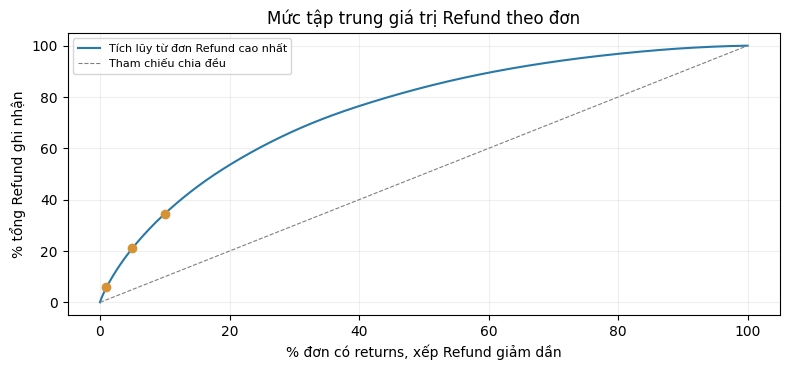

**Quan sát:** top 1% (361 đơn) giữ 5,840% Refund; top 10% giữ 34,526%. Hai top 10 theo Refund tuyệt đối và tỷ lệ có 0 mã đơn trùng nhau. **Ý nghĩa đối soát:** chọn hồ sơ theo số tiền hoặc theo tỷ lệ là hai tiêu chí khác nhau. **Giới hạn/câu hỏi:** đây là tập trung giá trị ghi nhận, chưa phải tổn thất hay hiệu quả khách hàng; chứng từ của các đơn đầu bảng có xác nhận cùng phạm vi tiền không?

In [20]:
ranked_refund042=has042.sort_values(["refund_total","order_id"],ascending=[False,True])
concentration_rows042=[]
for fraction in [.01,.05,.10]:
    count=math.ceil(Decimal(str(fraction))*len(has042))
    part=ranked_refund042.head(count)
    amount=sum(part["refund_total"],ZERO)
    concentration_rows042.append({"Top theo số đơn (%)":100*fraction,"Số đơn (ceil)":count,
      "Refund top (ĐVT)":amount,"% / tổng Refund":100*amount/totals042["refund_total"]})
concentration042=pd.DataFrame(concentration_rows042)
show(concentration042,{**fmt_money042(concentration042),"% / tổng Refund":lambda x:vn(x,3)+"%"})
line_value_rows042=[]
for lines,part in has042.groupby("return_line_count",sort=True):
    line_value_rows042.append({"Dòng returns/đơn":int(lines),"Số đơn":len(part),
      "Refund (ĐVT)":sum(part["refund_total"],ZERO),"Median Refund/đơn (ĐVT)":q042(part["refund_total"],.5),
      "% / tổng Refund":100*sum(part["refund_total"],ZERO)/totals042["refund_total"]})
line_values042=pd.DataFrame(line_value_rows042)
show(line_values042,{**fmt_money042(line_values042),"% / tổng Refund":lambda x:vn(x,3)+"%"})
top_ratio042=has042.loc[has042["RefundToPaymentRatio"].notna()].sort_values(
    ["RefundToPaymentRatio","order_id"],ascending=[False,True]).head(10)
show(top_ratio042[["order_id","refund_total","payment_value","RefundToPaymentRatio","return_line_count"]].rename(
    columns={"refund_total":"Refund (ĐVT)","payment_value":"Payment (ĐVT)","RefundToPaymentRatio":"Tỷ lệ Refund/Payment (%)"}),
 {"Refund (ĐVT)":lambda x:vn(x,2),"Payment (ĐVT)":lambda x:vn(x,2),"Tỷ lệ Refund/Payment (%)":lambda x:vn(100*x,3)})
top_overlap042=set(top_refund042["order_id"]) & set(top_ratio042["order_id"])
cumulative_refund042=np.cumsum([float(x) for x in ranked_refund042["refund_total"]])/float(totals042["refund_total"])*100
fig,ax=plt.subplots(figsize=(8,3.8))
ax.plot(np.arange(1,len(has042)+1)/len(has042)*100,cumulative_refund042,color="#2979a8",label="Tích lũy từ đơn Refund cao nhất")
ax.plot([0,100],[0,100],"--",color="grey",linewidth=.8,label="Tham chiếu chia đều")
for row in concentration042.to_dict("records"):
    ax.scatter(row["Số đơn (ceil)"]/len(has042)*100,float(row["% / tổng Refund"]),color="#d69336",zorder=3)
ax.set(xlabel="% đơn có returns, xếp Refund giảm dần",ylabel="% tổng Refund ghi nhận",
       title="Mức tập trung giá trị Refund theo đơn")
ax.legend(fontsize=8);ax.grid(alpha=.2)
plot_done(fig)
note(f"**Quan sát:** top 1% ({int(concentration042.iloc[0]['Số đơn (ceil)'])} đơn) giữ "
     f"{vn(concentration042.iloc[0]['% / tổng Refund'],3)}% Refund; top 10% giữ "
     f"{vn(concentration042.iloc[2]['% / tổng Refund'],3)}%. "
     f"Hai top 10 theo Refund tuyệt đối và tỷ lệ có {len(top_overlap042)} mã đơn trùng nhau. "
     "**Ý nghĩa đối soát:** chọn hồ sơ theo số tiền hoặc theo tỷ lệ là hai tiêu chí khác nhau. "
     "**Giới hạn/câu hỏi:** đây là tập trung giá trị ghi nhận, chưa phải tổn thất hay hiệu quả khách hàng; "
     "chứng từ của các đơn đầu bảng có xác nhận cùng phạm vi tiền không?")

### NV04.2.8 – Danh mục vấn đề cần xác minh, có nguồn truy ngược

A chỉ ghi vi phạm kỹ thuật có ràng buộc kiểm tra được; không có vi phạm thì số trường hợp bằng 0. B là hiện tượng cần đối soát nghiệp vụ, chưa là lỗi tài chính. C thiếu định nghĩa/chứng từ, số lượng hoặc tiền chưa biết giữ trống thay vì gán 0.

Các hàng có thể chồng lặp, không cộng số đơn hoặc tiền giữa các vấn đề. “Giá trị liên quan” luôn đi kèm loại giá trị, không mặc định là phần vượt hoặc tổn thất.


In [21]:
issues042=pd.DataFrame([
 {"Mã":"A01","Nhóm":"A","Hiện tượng":"Nhân bản đơn/Net/Payment sau JOIN",
  "Số trường hợp":abs(len(ledger042)-len(orders)),"Đơn vị/mẫu số":f"Đơn / {vn(len(orders))} đơn",
  "Giá trị liên quan (ĐVT)":abs(totals042["NetOrder"]-net_before),"Loại giá trị":"Sai lệch Net; Payment kiểm chứng riêng",
  "Nguồn/kiểm tra":"ledger042, totals042; one_to_one và bảo toàn tổng",
  "Bằng chứng":"Ràng buộc kỹ thuật đã kiểm tra; hiện không phát hiện vi phạm",
  "Giới hạn":"Không chứng minh mọi nghiệp vụ đúng","Câu hỏi/hướng tiếp":"Giữ hợp đồng khóa khi có dữ liệu mới"},
 {"Mã":"A02","Nhóm":"A","Hiện tượng":"Cặp returns không có trong items",
  "Số trường hợp":int(pair_orphan042.sum()),"Đơn vị/mẫu số":f"Cặp / {vn(len(pairs042))} cặp",
  "Giá trị liên quan (ĐVT)":sum(pairs042.loc[pair_orphan042,"RefundPair"],ZERO),"Loại giá trị":"Refund cặp không liên kết",
  "Nguồn/kiểm tra":"pairs042; kiểm tra indicator của JOIN one_to_one",
  "Bằng chứng":"Khóa liên kết đã kiểm tra; hiện không phát hiện vi phạm",
  "Giới hạn":"Cặp không xác định được lô trả","Câu hỏi/hướng tiếp":"Cần khóa dòng bán/lần xử lý"},
 {"Mã":"B01","Nhóm":"B","Hiện tượng":"Refund đơn > Payment hơn dung sai",
  "Số trường hợp":len(over042),"Đơn vị/mẫu số":f"Đơn / {vn(len(has042))} đơn có returns",
  "Giá trị liên quan (ĐVT)":sum(over042["refund_total"],ZERO),"Loại giá trị":"Refund của C, không phải phần vượt",
  "Nguồn/kiểm tra":"over042; Difference > TOL; phần vượt ở over_summary042",
  "Bằng chứng":"Chênh lệch số học đã xác minh; nguyên nhân chưa xác định",
  "Giới hạn":"Chưa có chính sách Refund ≤ Payment","Câu hỏi/hướng tiếp":"Đối soát chứng từ, phạm vi tiền, thời điểm và chính sách giá/giảm giá"},
 {"Mã":"B02","Nhóm":"B","Hiện tượng":"RefundPair > NetPurchased hơn dung sai",
  "Số trường hợp":int(pairs042["refund_above_net"].sum()),"Đơn vị/mẫu số":f"Cặp / {vn(len(pairs042))} cặp",
  "Giá trị liên quan (ĐVT)":sum(pairs042.loc[pairs042["refund_above_net"],"RefundPair"],ZERO),"Loại giá trị":"Refund các cặp được gắn cờ",
  "Nguồn/kiểm tra":"pairs042; RefundPair − (GrossPurchased − DiscountPurchased) > TOL",
  "Bằng chứng":"Chênh lệch ghi nhận theo cặp","Giới hạn":"So với toàn bộ cặp mua, không phân bổ giảm giá cho phần trả",
  "Câu hỏi/hướng tiếp":"Xác minh quy tắc giá/giảm giá; chỉ chuyển câu hỏi dòng hàng sang NV04.3"},
 {"Mã":"B03","Nhóm":"B","Hiện tượng":"Cặp trả có nhiều mức giá mua",
  "Số trường hợp":int(pairs042["price_count"].gt(1).sum()),"Đơn vị/mẫu số":f"Cặp / {vn(len(pairs042))} cặp",
  "Giá trị liên quan (ĐVT)":sum(pairs042.loc[pairs042["price_count"].gt(1),"RefundPair"],ZERO),"Loại giá trị":"Refund cặp chưa xác định dòng/lô trả",
  "Nguồn/kiểm tra":"items.unit_price Decimal; price_counts042, pairs042",
  "Bằng chứng":"Nhiều giá mua trong cùng cặp được đếm trực tiếp","Giới hạn":"Chưa có khóa dòng trả–dòng bán",
  "Câu hỏi/hướng tiếp":"Cần quy tắc xác định lô, không khử trùng hoặc áp giá bình quân thành giá thực tế"},
 {"Mã":"B04","Nhóm":"B","Hiện tượng":"Returned nhưng không có returns",
  "Số trường hợp":len(set_B),"Đơn vị/mẫu số":f"Đơn / {vn(len(returned_ids))} đơn returned",
  "Giá trị liên quan (ĐVT)":sum(ledger042.loc[ledger042["order_id"].isin(set_B),"payment_value"],ZERO),
  "Loại giá trị":"Payment của nhóm thiếu đối ứng, không phải Refund bị thiếu",
  "Nguồn/kiểm tra":"Tập B NV04.1; ledger042 và scopes042",
  "Bằng chứng":"Thiếu đối ứng trong nguồn đã xác minh","Giới hạn":"Không chứng minh mất dữ liệu; Refund thực tế chưa biết",
  "Câu hỏi/hướng tiếp":"NV04.4: thời điểm chốt/cập nhật và định nghĩa nhãn; chưa triển khai"},
 {"Mã":"C01","Nhóm":"C","Hiện tượng":"Chưa xác minh tiền đã hoàn/thực thu",
  "Số trường hợp":None,"Đơn vị/mẫu số":"Chưa xác định",
  "Giá trị liên quan (ĐVT)":None,"Loại giá trị":"Không tính được từ nguồn hiện tại",
  "Nguồn/kiểm tra":"headers042; chỉ có refund_amount và payment_value, thiếu chứng từ quyết toán",
  "Bằng chứng":"Thiếu định nghĩa và nguồn xác minh","Giới hạn":"Không gọi Payment − Refund là thực thu",
  "Câu hỏi/hướng tiếp":"Cần chứng từ quyết toán, thời điểm và đồng tiền"},
 {"Mã":"C02","Nhóm":"C","Hiện tượng":"Chưa xác định nguyên nhân Refund vượt Payment",
  "Số trường hợp":None,"Đơn vị/mẫu số":"Chưa xác định nguyên nhân trên nhóm C",
  "Giá trị liên quan (ĐVT)":None,"Loại giá trị":"Không tính tác động thực tế",
  "Nguồn/kiểm tra":"algebra042 và pairs042 chỉ kiểm tra số học",
  "Bằng chứng":"Giả thuyết chưa xác minh","Giới hạn":"Giá trước/sau giảm, phí và thời điểm chỉ là câu hỏi",
  "Câu hỏi/hướng tiếp":"Xác minh chính sách hoàn, phạm vi phí và quy trình ghi nhận với chứng từ"}])
show(issues042,{"Giá trị liên quan (ĐVT)":lambda x:vn(x,2),"Số trường hợp":lambda x:vn(x)})
note(f"**Quan sát:** {int(issues042['Nhóm'].eq('A').sum())} mục kỹ thuật không phát hiện vi phạm, "
     f"{int(issues042['Nhóm'].eq('B').sum())} hiện tượng B và {int(issues042['Nhóm'].eq('C').sum())} giới hạn C; "
     "đây là số mục, không là số đơn lỗi. "
     "**Ý nghĩa đối soát:** mỗi phát hiện có bảng/biến truy ngược và loại tiền riêng. "
     "**Giới hạn/câu hỏi:** chưa có chính sách xác nhận Refund không được vượt Payment, nên ưu tiên xác minh không đồng nghĩa kết luận sai; cần chứng từ nào cho từng mục?")

Mã,Nhóm,Hiện tượng,Số trường hợp,Đơn vị/mẫu số,Giá trị liên quan (ĐVT),Loại giá trị,Nguồn/kiểm tra,Bằng chứng,Giới hạn,Câu hỏi/hướng tiếp
A01,A,Nhân bản đơn/Net/Payment sau JOIN,0,Đơn / 646.945 đơn,"0,00",Sai lệch Net; Payment kiểm chứng riêng,"ledger042, totals042; one_to_one và bảo toàn tổng",Ràng buộc kỹ thuật đã kiểm tra; hiện không phát hiện vi phạm,Không chứng minh mọi nghiệp vụ đúng,Giữ hợp đồng khóa khi có dữ liệu mới
A02,A,Cặp returns không có trong items,0,Cặp / 39.937 cặp,"0,00",Refund cặp không liên kết,pairs042; kiểm tra indicator của JOIN one_to_one,Khóa liên kết đã kiểm tra; hiện không phát hiện vi phạm,Cặp không xác định được lô trả,Cần khóa dòng bán/lần xử lý
B01,B,Refund đơn > Payment hơn dung sai,3.640,Đơn / 36.062 đơn có returns,"48.739.243,73","Refund của C, không phải phần vượt",over042; Difference > TOL; phần vượt ở over_summary042,Chênh lệch số học đã xác minh; nguyên nhân chưa xác định,Chưa có chính sách Refund ≤ Payment,"Đối soát chứng từ, phạm vi tiền, thời điểm và chính sách giá/giảm giá"
B02,B,RefundPair > NetPurchased hơn dung sai,4.423,Cặp / 39.937 cặp,"51.482.378,04",Refund các cặp được gắn cờ,pairs042; RefundPair − (GrossPurchased − DiscountPurchased) > TOL,Chênh lệch ghi nhận theo cặp,"So với toàn bộ cặp mua, không phân bổ giảm giá cho phần trả",Xác minh quy tắc giá/giảm giá; chỉ chuyển câu hỏi dòng hàng sang NV04.3
B03,B,Cặp trả có nhiều mức giá mua,2,Cặp / 39.937 cặp,"61.813,04",Refund cặp chưa xác định dòng/lô trả,"items.unit_price Decimal; price_counts042, pairs042",Nhiều giá mua trong cùng cặp được đếm trực tiếp,Chưa có khóa dòng trả–dòng bán,"Cần quy tắc xác định lô, không khử trùng hoặc áp giá bình quân thành giá thực tế"
B04,B,Returned nhưng không có returns,80,Đơn / 36.142 đơn returned,"1.784.244,24","Payment của nhóm thiếu đối ứng, không phải Refund bị thiếu",Tập B NV04.1; ledger042 và scopes042,Thiếu đối ứng trong nguồn đã xác minh,Không chứng minh mất dữ liệu; Refund thực tế chưa biết,NV04.4: thời điểm chốt/cập nhật và định nghĩa nhãn; chưa triển khai
C01,C,Chưa xác minh tiền đã hoàn/thực thu,—,Chưa xác định,—,Không tính được từ nguồn hiện tại,"headers042; chỉ có refund_amount và payment_value, thiếu chứng từ quyết toán",Thiếu định nghĩa và nguồn xác minh,Không gọi Payment − Refund là thực thu,"Cần chứng từ quyết toán, thời điểm và đồng tiền"
C02,C,Chưa xác định nguyên nhân Refund vượt Payment,—,Chưa xác định nguyên nhân trên nhóm C,—,Không tính tác động thực tế,algebra042 và pairs042 chỉ kiểm tra số học,Giả thuyết chưa xác minh,"Giá trước/sau giảm, phí và thời điểm chỉ là câu hỏi","Xác minh chính sách hoàn, phạm vi phí và quy trình ghi nhận với chứng từ"


**Quan sát:** 2 mục kỹ thuật không phát hiện vi phạm, 4 hiện tượng B và 2 giới hạn C; đây là số mục, không là số đơn lỗi. **Ý nghĩa đối soát:** mỗi phát hiện có bảng/biến truy ngược và loại tiền riêng. **Giới hạn/câu hỏi:** chưa có chính sách xác nhận Refund không được vượt Payment, nên ưu tiên xác minh không đồng nghĩa kết luận sai; cần chứng từ nào cho từng mục?

### Đối chứng độc lập và bộ ví dụ biên

Kế thừa dict/Counter/Decimal đã **quét lại CSV độc lập** ở NV04.1; bổ sung quét items/returns để kiểm tra từng cặp và Gross/Discount của đơn có returns. Phân loại độc lập theo hiệu Decimal, tỷ lệ đối chiếu bằng Fraction rồi chuyển Decimal để so sánh trong sai số biểu diễn 10⁻²⁰ (không phải dung sai phân nhóm tiền).

Mẫu trong bộ nhớ gồm đơn hai dòng returns, đơn thấp hơn/bằng/vượt Payment, đơn không có returns, cặp lặp cả hai phía, mẫu số 0/thiếu/âm, và các hiệu đúng ±0,05 hoặc sát bên ngoài. Kết quả mong đợi viết độc lập; không tạo tệp và không nhập mẫu vào số liệu thật.


In [22]:
from fractions import Fraction
from bisect import bisect_right
ind_item_order042=defaultdict(lambda:[ZERO,ZERO,0])
ind_pair042={key:[ZERO,ZERO,ZERO,ZERO,ZERO,0,0] for key in ind_pair_counts}
for row in csv_rows("order_items"):
    oid=row["order_id"];key=(oid,row["product_id"])
    if oid in ind_counts:
        q,p,d=(Decimal(row[name]) for name in ["quantity","unit_price","discount_amount"])
        acc=ind_item_order042[oid];acc[0]+=q*p;acc[1]+=d;acc[2]+=1
        if key in ind_pair042:
            acc=ind_pair042[key];acc[0]+=q;acc[1]+=q*p;acc[2]+=d;acc[5]+=1
ind_return_year042=defaultdict(lambda:[0,ZERO,0,ZERO,set()])
for row in csv_rows("returns"):
    year=row["return_date"][:4]
    yearly=ind_return_year042[year];yearly[0]+=1;yearly[1]+=Decimal(row["refund_amount"])
    if row["order_id"] in ind_over_payment:
        yearly[2]+=1;yearly[3]+=Decimal(row["refund_amount"]);yearly[4].add(row["order_id"])
    key=(row["order_id"],row["product_id"])
    acc=ind_pair042[key];acc[3]+=Decimal(row["return_quantity"]);acc[4]+=Decimal(row["refund_amount"]);acc[6]+=1
ind_groups042={};ind_ratios042={};ind_diffs042={}
for oid,amount in ind_refund.items():
    pay=ind_payments.get(oid)
    if pay is None or not pay.is_finite() or pay<=0 or not amount.is_finite() or amount<0:
        ind_groups042[oid]="D";continue
    diff=amount-pay
    ind_diffs042[oid]=diff
    ind_groups042[oid]="A" if diff < -TOL else "C" if diff > TOL else "B"
    f=Fraction(amount)/Fraction(pay)
    ind_ratios042[oid]=Decimal(f.numerator)/Decimal(f.denominator)
ind_c042={oid for oid,g in ind_groups042.items() if g=="C"}
ind_group_counts042=Counter(ind_groups042.values())
ind_excess042=sum((ind_diffs042[oid] for oid in ind_c042),ZERO)
ind_rank042=sorted(ind_refund,key=lambda oid:(-ind_refund[oid],oid))
ind_top042={}
for percent in [1,5,10]:
    size=(len(ind_refund)*percent+99)//100
    ids=ind_rank042[:size]
    ind_top042[percent]=(size,sum((ind_refund[oid] for oid in ids),ZERO),ids)
ind_ratio_counts042=Counter()
for oid,value in ind_ratios042.items():
    f=Fraction(ind_refund[oid])/Fraction(ind_payments[oid])
    if f==1:label="100%"
    elif f<1:
        pos=bisect_right([Fraction(1,4),Fraction(1,2),Fraction(3,4)],f)
        label=ratio_labels042[pos]
    elif f<=Fraction(11,10):label="(100%;110%]"
    elif f<=Fraction(5,4):label="(110%;125%]"
    elif f<=Fraction(3,2):label="(125%;150%]"
    else:label="(150%;+∞)"
    ind_ratio_counts042[label]+=1
ind_value_counts042={}
for level,values in [("Dòng returns",ind_refund_values),("Đơn có returns",list(ind_refund.values()))]:
    counts=Counter()
    for value in values:
        label="Âm" if value<0 else value_labels042[1+bisect_right([Decimal("5000"),Decimal("10000"),Decimal("20000"),Decimal("50000")],value)]
        counts[label]+=1
    ind_value_counts042[level]=counts
fixture_order042=pd.DataFrame({"order_id":["L","E","G","N","BPLUS","BMINUS","OUTPLUS","OUTMINUS","ZERO","MISS","NEG"],
    "Payment":[Decimal(x) if x is not None else None for x in ["100","100","100","100","100","100","100","100","0",None,"-1"]],
    "Gross":[Decimal("120")]*11,"Discount":[Decimal("20")]*11})
fixture_return042=pd.DataFrame({"order_id":["L","L","E","G","BPLUS","BMINUS","OUTPLUS","OUTMINUS","ZERO","MISS","NEG"],
    "product_id":["P","P","P","P","P","P","P","P","P","P","P"],
    "refund":[Decimal(x) for x in ["20","30","100","120","100.05","99.95","100.0501","99.9499","1","1","1"]],
    "quantity":[Decimal("1")]*11})
fixture_agg042=fixture_return042.groupby("order_id").agg(refund=("refund","sum"),lines=("refund","size"))
fixture_ledger042=fixture_order042.merge(fixture_agg042,on="order_id",how="left",validate="one_to_one")
fixture_result042={row.order_id:classify042(row.refund,row.Payment)[0] for row in fixture_ledger042.itertuples(index=False) if pd.notna(row.refund)}
fixture_expected042={"L":"A","E":"B","G":"C","BPLUS":"B","BMINUS":"B","OUTPLUS":"C","OUTMINUS":"A","ZERO":"D","MISS":"D","NEG":"D"}
fixture_items042=pd.DataFrame({"order_id":["L","L"],"product_id":["P","P"],
    "quantity":[Decimal("1"),Decimal("2")],"price":[Decimal("10"),Decimal("20")],
    "discount":[Decimal("2"),Decimal("3")]})
fixture_items042["gross"]=fixture_items042["quantity"]*fixture_items042["price"]
fixture_ip042=fixture_items042.groupby(["order_id","product_id"])[["quantity","gross","discount"]].sum()
fixture_rp042=fixture_return042.loc[fixture_return042["order_id"].eq("L")].groupby(["order_id","product_id"])[["quantity","refund"]].sum()
fixture_pair042=fixture_rp042.join(fixture_ip042,lsuffix="_return",rsuffix="_buy",validate="one_to_one")
fixture_flags042={
 "Phân loại biên và mẫu số":fixture_result042==fixture_expected042,
 "Đơn hai returns":fixture_agg042.loc["L","lines"]==2 and fixture_agg042.loc["L","refund"]==Decimal("50"),
 "Không returns vẫn thiếu":pd.isna(fixture_ledger042.loc[fixture_ledger042["order_id"].eq("N"),"refund"].iloc[0]),
 "JOIN bảo toàn đơn và Gross/Discount":len(fixture_ledger042)==len(fixture_order042) and sum(fixture_ledger042["Gross"],ZERO)==sum(fixture_order042["Gross"],ZERO),
 "Cặp lặp tổng hợp không tích số dòng":len(fixture_pair042)==1 and fixture_pair042.iloc[0]["refund"]==Decimal("50") and fixture_pair042.iloc[0]["quantity_buy"]==Decimal("3"),
 "Giảm giá dòng không nhân số lượng":fixture_pair042.iloc[0]["gross"]-fixture_pair042.iloc[0]["discount"]==Decimal("45"),
 "Không phân nhóm sau làm tròn":fixture_result042["OUTPLUS"]=="C" and fixture_result042["BPLUS"]=="B",
 "Vượt dương không triệt tiêu âm":sum((r-p for r,p in [(Decimal("50"),Decimal("100")),(Decimal("120"),Decimal("100"))] if r-p>TOL),ZERO)==Decimal("20")}
show(pd.DataFrame([{"Đơn mẫu":oid,"Kết quả":fixture_result042[oid],"Mong đợi":group}
                   for oid,group in fixture_expected042.items()]))
show(pd.DataFrame([{"Kiểm thử mẫu":label,"Đạt":bool(value)} for label,value in fixture_flags042.items()]))
note("**Đối chứng:** đã dựng nhóm, tỷ lệ, phần vượt và top từ dict/CSV, không dùng groupby để tạo kết quả mong đợi. "
     "**Ý nghĩa:** mẫu biên tách 0,0500 khỏi 0,0501 ĐVT và cho thấy giảm giá dòng không được nhân quantity. "
     "**Giới hạn/câu hỏi:** mẫu kiểm tra công thức, chưa xác minh chính sách tài chính; các kiểm chứng tổng hợp được đánh giá ở bảng cuối.")

Đơn mẫu,Kết quả,Mong đợi
L,A,A
E,B,B
G,C,C
BPLUS,B,B
BMINUS,B,B
OUTPLUS,C,C
OUTMINUS,A,A
ZERO,D,D
MISS,D,D
NEG,D,D


Kiểm thử mẫu,Đạt
Phân loại biên và mẫu số,True
Đơn hai returns,True
Không returns vẫn thiếu,True
JOIN bảo toàn đơn và Gross/Discount,True
Cặp lặp tổng hợp không tích số dòng,True
Giảm giá dòng không nhân số lượng,True
Không phân nhóm sau làm tròn,True
Vượt dương không triệt tiêu âm,True


**Đối chứng:** đã dựng nhóm, tỷ lệ, phần vượt và top từ dict/CSV, không dùng groupby để tạo kết quả mong đợi. **Ý nghĩa:** mẫu biên tách 0,0500 khỏi 0,0501 ĐVT và cho thấy giảm giá dòng không được nhân quantity. **Giới hạn/câu hỏi:** mẫu kiểm tra công thức, chưa xác minh chính sách tài chính; các kiểm chứng tổng hợp được đánh giá ở bảng cuối.

### Kết luận NV04.2

Các đoạn dưới tổng hợp chỉ tiêu đã tính; phần tài chính vẫn giới hạn ở giá trị ghi nhận. NV04.3/NV04.4 chỉ nhận câu hỏi, chưa được triển khai.


In [23]:
note(f"""
Tổng Refund ghi nhận là **{vn(totals042["refund_total"],2)} ĐVT** trên {vn(len(refund))} dòng và {vn(len(has042))} đơn. Bình quân/dòng {vn(stats_refund042.iloc[0]["Mean (ĐVT)"],2)} khác bình quân/đơn {vn(stats_refund042.iloc[1]["Mean (ĐVT)"],2)} ĐVT; top 10% đơn ({int(concentration042.iloc[2]["Số đơn (ceil)"])} đơn) chiếm {vn(concentration042.iloc[2]["% / tổng Refund"],3)}%. Đây là tập trung giá trị ghi nhận, chưa phản ánh tổn thất.

Đối soát cấp đơn giữ nguyên Net và Payment **{vn(totals042["NetOrder"],2)} ĐVT**, với A={vn(int(groups042.iloc[0]["Số đơn"]))}, B={vn(int(groups042.iloc[1]["Số đơn"]))}, C={vn(len(over042))}, D={vn(int(groups042.iloc[3]["Số đơn"]))}. Nhóm C chiếm {vn(pct(len(over042),len(has042)),3)}% đơn có returns; phần vượt dương **{vn(over_total042,2)} ĐVT**, median {vn(q042(over042["Difference"],.5),2)}, max {vn(max(over042["Difference"]),2)} ĐVT. Top 1% C ({top_excess_n042} đơn) giữ {vn(100*top_excess_total042/over_total042,2)}% phần vượt. Các bảng số dòng và thời gian mô tả đặc điểm của nhóm, chưa xác định quan hệ nhân quả.

Đối chiếu cặp đơn–sản phẩm không thấy sản phẩm ngoài đơn hay lượng trả vượt lượng mua; {vn(int(pairs042["refund_above_net"].sum()))} cặp Refund vượt NetPurchased và {vn(int(pairs042["refund_above_gross"].sum()))} cặp vượt GrossPurchased hơn dung sai. Đẳng thức Difference = Discount − (Gross − Refund) làm rõ vì sao **Payment=Net không buộc Refund≤Payment về số học**. Nguyên nhân nghiệp vụ vẫn chưa xác định: hoàn theo giá trước/sau giảm, phạm vi phí hoặc thời điểm ghi nhận chỉ là giả thuyết cần chứng từ, không phải kết luận. Cặp lặp/nhiều giá chưa cho biết dòng hoặc lô thực trả.

NV04.2 giữ nhất quán số nền NV01–NV03 và làm rõ phạm vi/mẫu số Refund; chưa xác minh doanh thu thuần, thực thu, tiền thực hoàn, quyết toán hay lợi nhuận. NV04.3 cần định nghĩa khóa dòng/lô, ý nghĩa lý do và giá/giảm giá khi trả; NV04.4 cần metadata chốt/cập nhật, mốc hoàn và chứng từ quyết toán. Chưa tính nguyên nhân theo sản phẩm hoặc thời gian xử lý ở hai phần này.
""")


Tổng Refund ghi nhận là **510.598.506,55 ĐVT** trên 39.939 dòng và 36.062 đơn. Bình quân/dòng 12.784,46 khác bình quân/đơn 14.158,91 ĐVT; top 10% đơn (3607 đơn) chiếm 34,526%. Đây là tập trung giá trị ghi nhận, chưa phản ánh tổn thất.

Đối soát cấp đơn giữ nguyên Net và Payment **15.680.869.265,43 ĐVT**, với A=32.422, B=0, C=3.640, D=0. Nhóm C chiếm 10,094% đơn có returns; phần vượt dương **4.308.810,51 ĐVT**, median 584,16, max 17.624,41 ĐVT. Top 1% C (37 đơn) giữ 9,13% phần vượt. Các bảng số dòng và thời gian mô tả đặc điểm của nhóm, chưa xác định quan hệ nhân quả.

Đối chiếu cặp đơn–sản phẩm không thấy sản phẩm ngoài đơn hay lượng trả vượt lượng mua; 4.423 cặp Refund vượt NetPurchased và 0 cặp vượt GrossPurchased hơn dung sai. Đẳng thức Difference = Discount − (Gross − Refund) làm rõ vì sao **Payment=Net không buộc Refund≤Payment về số học**. Nguyên nhân nghiệp vụ vẫn chưa xác định: hoàn theo giá trước/sau giảm, phạm vi phí hoặc thời điểm ghi nhận chỉ là giả thuyết cần chứng từ, không phải kết luận. Cặp lặp/nhiều giá chưa cho biết dòng hoặc lô thực trả.

NV04.2 giữ nhất quán số nền NV01–NV03 và làm rõ phạm vi/mẫu số Refund; chưa xác minh doanh thu thuần, thực thu, tiền thực hoàn, quyết toán hay lợi nhuận. NV04.3 cần định nghĩa khóa dòng/lô, ý nghĩa lý do và giá/giảm giá khi trả; NV04.4 cần metadata chốt/cập nhật, mốc hoàn và chứng từ quyết toán. Chưa tính nguyên nhân theo sản phẩm hoặc thời gian xử lý ở hai phần này.


### Kiểm chứng NV04.2

Đối chiếu tổng, từng khóa, công thức và mẫu số với NV04.1, V02/V03 và dict/CSV độc lập. Phân loại tiền dùng Decimal chính xác với dung sai 0,05 ĐVT; không dùng giá trị hiển thị đã làm tròn. Tỷ lệ và thống kê phân tán có dung sai biểu diễn rất nhỏ, tách khỏi dung sai tiền.

Giữ nguyên 24 ô NV04.1 bằng SHA-256 của toàn bộ cấu trúc cell, gồm output; hai lượt Run All còn đối chiếu output thực thi cũ theo nội dung, bỏ qua ID ngẫu nhiên của bảng Styler. Các mục không áp dụng/không chạy được tách khỏi số đạt.


In [24]:
checks042=[]
def check042(label,condition,reason="Áp dụng; tính trên nguồn quan sát"):
    checks042.append({"Kiểm chứng NV04.2":label,"Trạng thái":"Đạt" if bool(condition) else "Không đạt","Bằng chứng/lý do":reason})
def na042(label,reason):
    checks042.append({"Kiểm chứng NV04.2":label,"Trạng thái":"Không áp dụng","Bằng chứng/lý do":reason})
def close042(a,b,eps=Decimal("1e-20")):
    return a is not None and b is not None and abs(a-b)<=eps
ledger_index042=ledger042.set_index("order_id")
has_index042=has042.set_index("order_id")
native_summary042={}
for group in group_labels042:
    ids=[oid for oid,g in ind_groups042.items() if g==group]
    native_summary042[group]=(len(ids),sum((ind_payments[oid] for oid in ids),ZERO),
      sum((ind_refund[oid] for oid in ids),ZERO),sum((ind_diffs042[oid] for oid in ids if oid in ind_diffs042),ZERO))
check042("Orders/returns/đơn có returns khớp CSV và V02/V03",len(ledger042)==ind_rows["orders"]==v02["metrics"]["orders_rows"] and
    len(return_lines042)==ind_rows["returns"]==v03["metrics"]["returns_rows"] and len(has042)==len(ind_refund)==v03["metrics"]["return_orders"])
check042("JOIN duy nhất, đủ tập order_id, phân hoạch có/không returns",ledger042["order_id"].is_unique and set(ledger042["order_id"])==set(ind_orders) and
    int(ledger042["has_return"].sum())+int((~ledger042["has_return"]).sum())==len(ind_orders))
check042("Net trước/sau JOIN bảo toàn chính xác và khớp V02 trong dung sai",totals042["NetOrder"]==net_before==net_after==sum(ind_net.values(),ZERO) and
    abs(totals042["NetOrder"]-Decimal(str(v02["metrics"]["net"])))<=TOL)
check042("Payment trước/sau JOIN bảo toàn chính xác và khớp V02",totals042["payment_value"]==sum(payment,ZERO)==sum(ind_payments.values(),ZERO) and
    abs(totals042["payment_value"]-Decimal(str(v02["metrics"]["payment"])))<=TOL)
check042("Refund dòng = đơn = NV04.1 chính xác, khớp V03 trong dung sai",totals042["refund_total"]==sum(refund,ZERO)==sum(ind_refund.values(),ZERO)==refund_total and
    abs(totals042["refund_total"]-Decimal(str(v03["metrics"]["refund"])))<=TOL)
check042("Từng Net và Payment cấp đơn khớp dict độc lập",ledger_index042["NetOrder"].to_dict()==dict(ind_net) and ledger_index042["payment_value"].to_dict()==ind_payments)
ind_quantity_order042=defaultdict(Decimal)
for (oid,pid),value in ind_pair042.items():ind_quantity_order042[oid]+=value[3]
check042("Tổng lượng trả ghi nhận cấp đơn khớp tổng cặp độc lập",has_index042["return_quantity_total"].to_dict()==dict(ind_quantity_order042))
check042("Từng Refund và số dòng cấp đơn khớp dict/Counter độc lập",has_index042["refund_total"].to_dict()==dict(ind_refund) and has_index042["return_line_count"].to_dict()==dict(ind_counts))
check042("Gross/Discount tổng khớp nguồn độc lập; không nhân giảm giá theo quantity",totals042["GrossOrder"]==ind_gross and totals042["DiscountOrder"]==ind_discount and
    totals042["GrossOrder"]-totals042["DiscountOrder"]==totals042["NetOrder"])
check042("Gross/Discount/số dòng items của từng đơn có returns khớp quét mới",all(
    has_index042.loc[oid,"GrossOrder"]==vals[0] and has_index042.loc[oid,"DiscountOrder"]==vals[1] and
    has_index042.loc[oid,"item_line_count"]==vals[2] for oid,vals in ind_item_order042.items()))
check042("Đơn không returns dùng tổng rỗng 0 và has_return=False đúng tập",set(ledger042.loc[~ledger042["has_return"],"order_id"])==set(ind_orders)-set(ind_refund) and
    all(x==ZERO for x in ledger042.loc[~ledger042["has_return"],"refund_total"]))
check042("Net = Gross − Discount từng đơn chính xác",all(n==g-d for n,g,d in zip(ledger042["NetOrder"],ledger042["GrossOrder"],ledger042["DiscountOrder"])))
check042("Các trường tiền cần dùng hữu hạn; Payment dương và không NULL",all(finite042(x) for name in ["GrossOrder","DiscountOrder","NetOrder","payment_value","refund_total"] for x in ledger042[name]) and
    all(x>0 for x in ledger042["payment_value"]))
check042("Stats cấp dòng/đơn: mean/median/min/max/std/phân vị độc lập",all(
    close042(row["Mean (ĐVT)"],statistics.mean(vals)) and row["Median (ĐVT)"]==statistics.median(vals) and
    row["Min (ĐVT)"]==min(vals) and row["Max (ĐVT)"]==max(vals) and
    close042(row["Std mẫu (ĐVT)"],statistics.stdev(vals)) and
    all(row[f"P{p} (ĐVT)"]==statistics.quantiles(vals,n=100,method="inclusive")[p-1] for p in [25,75,90,95,99])
    for row,vals in zip(stats_refund042.to_dict("records"),[ind_refund_values,list(ind_refund.values())])))
check042("Các nhóm giá trị Refund đúng biên, số dòng/đơn và bảo toàn tiền",all(
    int(row["Số quan sát"])==ind_value_counts042[row["Cấp"]][row["Khoảng Refund (ĐVT)"]]
    for row in value_distribution042.to_dict("records")) and all(
    int(value_distribution042.loc[value_distribution042["Cấp"].eq(level),"Số quan sát"].sum())==size and
    sum(value_distribution042.loc[value_distribution042["Cấp"].eq(level),"Tổng Refund (ĐVT)"],ZERO)==totals042["refund_total"]
    for level,size in [("Dòng returns",len(refund)),("Đơn có returns",len(has042))]))
check042("A/B/C/D từng đơn khớp phân loại Decimal độc lập",has_index042["group"].to_dict()==ind_groups042)
check042("A/B/C/D phân loại hết không chồng lấn, giữ D riêng",len(has042)==sum(ind_group_counts042.values())==int(groups042["Số đơn"].sum()) and
    has042["group"].isin(group_labels042).all() and has042["order_id"].is_unique)
check042("Payment/Refund/Difference tổng từng nhóm khớp dict độc lập",all(
    (int(row["Số đơn"]),row["Payment (ĐVT)"],row["Refund (ĐVT)"])==native_summary042[row["Nhóm"]][:3] and
    (row["Difference tổng (ĐVT)"]==native_summary042[row["Nhóm"]][3] if row["Số đơn"] else pd.isna(row["Difference tổng (ĐVT)"]))
    for row in groups042.to_dict("records")))
check042("Từng Difference đúng hiệu, không dùng số hiển thị đã làm tròn",has_index042["Difference"].to_dict()==ind_diffs042 and
    all(g==("C" if d>TOL else "A" if d < -TOL else "B") for g,d in zip(has042["group"],has042["Difference"])))
check042("Từng tỷ lệ Refund/Payment khớp Fraction độc lập",all(
    close042(has_index042.loc[oid,"RefundToPaymentRatio"],value) for oid,value in ind_ratios042.items()))
check042("Mean/median tỷ lệ từng nhóm đúng mẫu đơn hợp lệ",all(
    close042(row["Mean tỷ lệ (%)"]/100,statistics.mean(values)) and
    close042(row["Median tỷ lệ (%)"]/100,statistics.median(values))
    for row in groups042.to_dict("records") if row["Số đơn"]
    for values in [[ind_ratios042[oid] for oid,g in ind_groups042.items() if g==row["Nhóm"]]]))
check042("Khoảng tỷ lệ và số đơn >100% đúng Fraction; không cắt ngưỡng",all(
    int(row["Số đơn"])==ind_ratio_counts042[row["Khoảng Refund/Payment"]] for row in ratio_distribution042.to_dict("records")) and
    strict_above100042==sum(Fraction(ind_refund[k])>Fraction(ind_payments[k]) for k in ind_ratios042))
check042("C đúng từng mã và mốc V03/NV04.1",set(over042["order_id"])==ind_c042==ind_over_payment and
    len(over042)==n_over_payment==v03["metrics"]["refund_orders_above_payment"])
check042("Tổng phần vượt dương không bù trừ phần âm",over_total042==ind_excess042 and all(x>TOL for x in over042["Difference"]) and
    over_total042==sum((d for d in ind_diffs042.values() if d>TOL),ZERO))
ind_over_values042=[ind_diffs042[oid] for oid in ind_c042]
check042("Phần vượt min/max/mean/median/P90/P95/P99 khớp độc lập",min(over042["Difference"])==min(ind_over_values042) and
    max(over042["Difference"])==max(ind_over_values042) and close042(mean042(over042["Difference"]),statistics.mean(ind_over_values042)) and
    all(q042(over042["Difference"],q)==statistics.quantiles(ind_over_values042,n=100,method="inclusive")[int(q*100)-1] for q in [.5,.9,.95,.99]))
check042("Bảng phân bố phần vượt bảo toàn số đơn và giá trị",int(excess_dist042["Số đơn"].sum())==len(ind_c042) and
    sum(excess_dist042["Tổng phần vượt (ĐVT)"],ZERO)==ind_excess042)
check042("Top phần vượt 1% đúng ceil, số đơn và tổng",top_excess_n042==(len(ind_c042)+99)//100 and
    top_excess_total042==sum(sorted(ind_over_values042,reverse=True)[:top_excess_n042],ZERO))
check042("Nhiều dòng returns/items trong C và A/B khớp dict độc lập",all(
    int(row["Số đơn"])==len(ids) and int(row["Đơn nhiều dòng returns"])==sum(ind_counts[oid]>1 for oid in ids) and
    int(row["Đơn nhiều dòng items"])==sum(ind_item_order042[oid][2]>1 for oid in ids)
    for row,ids in zip(comparison042.to_dict("records"),[ind_c042,set(ind_counts)-ind_c042])))
check042("Ví dụ cực trị đúng tiêu chí, giới hạn 10 đơn không in toàn nhóm",len(examples042)==10 and
    list(example_large042["order_id"])==sorted(ind_c042,key=lambda oid:(-ind_diffs042[oid],oid))[:5] and
    list(example_small042["order_id"])==sorted(ind_c042,key=lambda oid:(ind_diffs042[oid],oid))[:5])
ind_order_year042=Counter(str(ind_dates[oid].year) for oid in ind_counts)
ind_c_year042=Counter(str(ind_dates[oid].year) for oid in ind_c042)
check042("Theo năm đặt: C/mẫu số đúng dict ngày độc lập, bảo toàn phần vượt",all(
    int(row["Đơn có returns"])==ind_order_year042[row["Năm đặt"]] and int(row["Đơn C"])==ind_c_year042[row["Năm đặt"]] and
    row["Phần vượt C (ĐVT)"]==sum((ind_diffs042[oid] for oid in ind_c042 if str(ind_dates[oid].year)==row["Năm đặt"]),ZERO)
    for row in order_year042.to_dict("records")) and sum(order_year042["Phần vượt C (ĐVT)"],ZERO)==ind_excess042)
check042("Từng năm return_date khớp số dòng/Refund/mã C từ CSV độc lập",all(
    [int(row["Dòng returns"]),row["Refund mọi dòng (ĐVT)"],int(row["Dòng thuộc đơn C"]),row["Refund dòng thuộc C (ĐVT)"],int(row["Đơn C phân biệt trong năm"])]==
    [ind_return_year042[row["Năm return_date"]][0],ind_return_year042[row["Năm return_date"]][1],ind_return_year042[row["Năm return_date"]][2],ind_return_year042[row["Năm return_date"]][3],len(ind_return_year042[row["Năm return_date"]][4])]
    for row in return_year042.to_dict("records")))
check042("Theo return_date chỉ cộng tiền dòng, không nhân tiền đơn theo ngày",int(return_year042["Dòng returns"].sum())==len(refund) and
    sum(return_year042["Refund mọi dòng (ĐVT)"],ZERO)==totals042["refund_total"] and
    sum(return_year042["Refund dòng thuộc C (ĐVT)"],ZERO)==sum((ind_refund[k] for k in ind_c042),ZERO))
check042("Lặp cặp được kiểm tra lại, khớp NV04.1/V03",repeat_pair_counts042["returns"]==v03["metrics"]["repeated_return_pairs"] and
    int((item_pair042["item_pair_lines"]-1).sum())==v03["metrics"]["duplicate_item_pairs_excess"] and
    repeat_pair_counts042["order_items"]==int(i_pairs["item_rows"].gt(1).sum()))
check042("JOIN cặp one_to_one bảo toàn số cặp, dòng và Refund",len(pairs042)==len(ind_pair042) and
    not pairs042.duplicated(["order_id","product_id"]).any() and int(pairs042["return_pair_lines"].sum())==len(refund) and
    sum(pairs042["RefundPair"],ZERO)==totals042["refund_total"])
check042("Từng lượng/Gross/Discount/Refund cặp khớp quét CSV độc lập",all(
    [row.purchased_quantity,row.GrossPurchased,row.DiscountPurchased,row.returned_quantity,row.RefundPair,row.item_pair_lines,row.return_pair_lines]
    ==ind_pair042[(row.order_id,row.product_id)] for row in pairs042.itertuples(index=False)))
check042("Khóa cặp hợp lệ, lượng mua/trả dương và nguyên theo đơn vị ghi nhận",not pair_orphan042.any() and all(
    q>0 and q==q.to_integral_value() for col in ["purchased_quantity","returned_quantity"] for q in pairs042[col]))
ind_pair_qty_over042={key for key,v in ind_pair042.items() if v[3]>v[0]}
ind_pair_gross_over042={key for key,v in ind_pair042.items() if v[4]-v[1]>TOL}
ind_pair_net_over042={key for key,v in ind_pair042.items() if v[4]-(v[1]-v[2])>TOL}
check042("Cặp lượng trả vượt/Gross/Net vượt đúng từng khóa độc lập",set(map(tuple,pairs042.loc[pairs042["quantity_excess"].gt(0),["order_id","product_id"]].to_numpy()))==ind_pair_qty_over042 and
    set(map(tuple,pairs042.loc[pairs042["refund_above_gross"],["order_id","product_id"]].to_numpy()))==ind_pair_gross_over042 and
    set(map(tuple,pairs042.loc[pairs042["refund_above_net"],["order_id","product_id"]].to_numpy()))==ind_pair_net_over042)
check042("Cặp gắn cờ khớp V03, không suy thành lỗi",len(ind_pair_qty_over042)==v03["metrics"]["over_return_pairs"] and
    len(ind_pair_gross_over042)==v03["metrics"]["refund_above_gross_purchased"] and
    len(ind_pair_net_over042)==v03["metrics"]["refund_above_net_purchased"])
check042("Giao với C lấy tập đơn thật, không suy từ tổng cặp",c_with_net_pair042=={oid for oid,pid in ind_pair_net_over042 if oid in ind_c042})
check042("Đẳng thức Difference từ Gross/Discount đúng chính xác",all(
    d==disc-(gross-r) for d,disc,gross,r in zip(over042["Difference"],over042["DiscountOrder"],over042["GrossOrder"],over042["refund_total"])) and
    all(has_index042.loc[k,"NetOrder"]==ind_payments[k] for k in ind_counts))
check042("Ba phạm vi đúng tập đơn, gồm B thiếu đối ứng trong returned",scope_ids042["A"]==set(ind_orders) and scope_ids042["B"]==set(ind_counts) and
    scope_ids042["C"]==ind_returned_ids and scope_ids042["C"]-scope_ids042["B"]==ind_B)
check042("Từng tổng tiền trong ba phạm vi khớp dict độc lập",all(
    row["Số đơn"]==len(ids) and row["Payment (ĐVT)"]==sum((ind_payments[k] for k in ids),ZERO) and
    row["Net (ĐVT)"]==sum((ind_net[k] for k in ids),ZERO) and
    row["Refund ghi nhận (ĐVT)"]==sum((ind_refund.get(k,ZERO) for k in ids),ZERO)
    for row,ids in zip(scopes042.to_dict("records"),[scope_ids042[k] for k in ["A","B","C"]])))
check042("Tỷ lệ tổng và mean tỷ lệ cấp đơn có công thức/mẫu số riêng",all(
    close042(row["ΣRefund/ΣPayment (%)"],100*row["Refund ghi nhận (ĐVT)"]/row["Payment (ĐVT)"]) and
    close042(row["ΣRefund/ΣNet (%)"],100*row["Refund ghi nhận (ĐVT)"]/row["Net (ĐVT)"]) and
    row["Mẫu số mean tỷ lệ"]==len([k for k in ids if k in ind_ratios042]) and
    close042(row["Mean tỷ lệ đơn có returns (%)"]/100,statistics.mean([ind_ratios042[k] for k in ids if k in ind_ratios042]))
    for row,ids in zip(scopes042.to_dict("records"),[scope_ids042[k] for k in ["A","B","C"]])))
check042("Top 1/5/10% đúng ceil trên số đơn và tiền, không dùng số dòng",all(
    int(row["Số đơn (ceil)"])==ind_top042[int(row["Top theo số đơn (%)"])][0] and
    row["Refund top (ĐVT)"]==ind_top042[int(row["Top theo số đơn (%)"])][1]
    for row in concentration042.to_dict("records")))
check042("Top Refund và tỷ lệ đúng thứ tự, đồng hạng theo mã",list(top_refund042["order_id"])==ind_rank042[:10] and
    list(top_ratio042["order_id"])==sorted(ind_ratios042,key=lambda oid:(-ind_ratios042[oid],oid))[:10])
check042("Refund theo số dòng/đơn bảo toàn số đơn và tiền",int(line_values042["Số đơn"].sum())==len(ind_refund) and
    sum(line_values042["Refund (ĐVT)"],ZERO)==sum(ind_refund.values(),ZERO))
check042("Các tỷ trọng đúng mẫu số nêu trong bảng",math.isclose(float(groups042["% / đơn có returns"].sum()),100) and
    all(close042(row["% / tổng Refund"],100*row["Refund top (ĐVT)"]/totals042["refund_total"]) for row in concentration042.to_dict("records")) and
    math.isclose(float(line_values042["% / tổng Refund"].sum()),100))
check042("Bộ ví dụ độc lập đủ trường hợp biên và bảo toàn JOIN",all(fixture_flags042.values()),f"{len(fixture_flags042)} điều kiện, gồm ±0,05; 0,0501; hai dòng/cặp lặp/không returns/mẫu số sai")
check042("Giữ nguyên cả 24 ô NV04.1 và output đã lưu",prefix_hash042()==prefix_sha042,"SHA-256 của nội dung nguồn và ID các ô")
check042("NV04.1 vẫn 48 đạt, 0 không đạt và 5 không áp dụng",verification_counts=={"passed":48,"failed":0,"not_applicable":5})
check042("Mọi tệp ngoài notebook giữ nguyên SHA-256",protected_before==protected_snapshot(),f"{len(protected_before)} tệp, gồm raw/NV01–03/V01–09 và tài liệu untracked")
check042("Vấn đề có mã duy nhất, nguồn/kiểm tra/giới hạn/câu hỏi và loại tiền",issues042["Mã"].is_unique and
    issues042[["Nguồn/kiểm tra","Bằng chứng","Giới hạn","Câu hỏi/hướng tiếp","Loại giá trị"]].notna().all().all() and
    "over042" in issues042.loc[issues042["Mã"].eq("B01"),"Nguồn/kiểm tra"].iloc[0])
na042("Tiền thực hoàn/thực thu/quyết toán/lợi nhuận","Thiếu chứng từ, thời điểm và định nghĩa phạm vi tiền; không lập công thức thực thu")
na042("Nhóm C là lỗi chính sách hoặc tổn thất thực tế","Chưa xác minh giới hạn Refund ≤ Payment; chênh lệch số học không là bằng chứng sai tài chính")
na042("Giá/giảm giá thực của phần hàng trả và lô thực trả","Chưa có khóa dòng bán–dòng trả/quy tắc phân bổ; chỉ so với tổng giá trị mua của cặp")
na042("Nguyên nhân và thời điểm thực tế hoàn tiền","Ngày/lý do/chốt dữ liệu chưa được xác minh; các giả thuyết cần chứng từ, không suy nhân quả")
validation042=pd.DataFrame(checks042)
verification_counts042={"passed":int(validation042["Trạng thái"].eq("Đạt").sum()),
 "failed":int(validation042["Trạng thái"].eq("Không đạt").sum()),
 "not_applicable":int(validation042["Trạng thái"].eq("Không áp dụng").sum()),"unable_to_run":0}
show(validation042)
show(pd.DataFrame([{"Phạm vi":"NV04.1","Đạt":verification_counts["passed"],"Không đạt":verification_counts["failed"],"Không áp dụng":verification_counts["not_applicable"],"Không chạy được":0},
 {"Phạm vi":"NV04.2","Đạt":verification_counts042["passed"],"Không đạt":verification_counts042["failed"],
  "Không áp dụng":verification_counts042["not_applicable"],"Không chạy được":verification_counts042["unable_to_run"]}]))
note(f"**Kiểm chứng:** NV04.2 có {verification_counts042['passed']} đạt, {verification_counts042['failed']} không đạt, "
     f"{verification_counts042['not_applicable']} không áp dụng, {verification_counts042['unable_to_run']} không chạy được. "
     "NV04.1 được thực thi lại và giữ nguyên output đã lưu. "
     "**Giới hạn:** các kiểm tra đạt xác nhận số học/khóa/phạm vi; không thay các mục chưa đủ chứng từ thành đạt. "
     "**Câu hỏi tiếp:** bổ sung định nghĩa và chứng từ ở các mục C trước khi diễn giải tài chính thực tế.")
assert verification_counts042["failed"]==0, "Có kiểm chứng NV04.2 không đạt, cần xem bảng."

Kiểm chứng NV04.2,Trạng thái,Bằng chứng/lý do
Orders/returns/đơn có returns khớp CSV và V02/V03,Đạt,Áp dụng; tính trên nguồn quan sát
"JOIN duy nhất, đủ tập order_id, phân hoạch có/không returns",Đạt,Áp dụng; tính trên nguồn quan sát
Net trước/sau JOIN bảo toàn chính xác và khớp V02 trong dung sai,Đạt,Áp dụng; tính trên nguồn quan sát
Payment trước/sau JOIN bảo toàn chính xác và khớp V02,Đạt,Áp dụng; tính trên nguồn quan sát
"Refund dòng = đơn = NV04.1 chính xác, khớp V03 trong dung sai",Đạt,Áp dụng; tính trên nguồn quan sát
Từng Net và Payment cấp đơn khớp dict độc lập,Đạt,Áp dụng; tính trên nguồn quan sát
Tổng lượng trả ghi nhận cấp đơn khớp tổng cặp độc lập,Đạt,Áp dụng; tính trên nguồn quan sát
Từng Refund và số dòng cấp đơn khớp dict/Counter độc lập,Đạt,Áp dụng; tính trên nguồn quan sát
Gross/Discount tổng khớp nguồn độc lập; không nhân giảm giá theo quantity,Đạt,Áp dụng; tính trên nguồn quan sát
Gross/Discount/số dòng items của từng đơn có returns khớp quét mới,Đạt,Áp dụng; tính trên nguồn quan sát


Phạm vi,Đạt,Không đạt,Không áp dụng,Không chạy được
NV04.1,48,0,5,0
NV04.2,52,0,4,0


**Kiểm chứng:** NV04.2 có 52 đạt, 0 không đạt, 4 không áp dụng, 0 không chạy được. NV04.1 được thực thi lại và giữ nguyên output đã lưu. **Giới hạn:** các kiểm tra đạt xác nhận số học/khóa/phạm vi; không thay các mục chưa đủ chứng từ thành đạt. **Câu hỏi tiếp:** bổ sung định nghĩa và chứng từ ở các mục C trước khi diễn giải tài chính thực tế.

### Kết thúc phạm vi NV04.2

Hai lượt Run All thực tế, số ô thực thi, kiểm chứng và đối chiếu output NV04.1 được ghi trong metadata `nv042_run_all` và `execution_validation`. Output 24 ô đầu được giữ nguyên; output phần mới là lượt chạy cuối.

Dừng ở NV04.2. Các câu hỏi NV04.3/NV04.4 là bàn giao nghiên cứu, chưa triển khai, chưa sửa tiền hoặc chính sách.


## NV04.3 – Phân tích đặc điểm và lý do hoàn trả

Phần bổ sung tiếp nối NV04.1–NV04.2; giữ nguyên 49 ô trước, gồm code, Markdown và output. Chỉ phân tích mô tả nhãn lý do, số lượng, sản phẩm, danh mục và liên hệ với Refund ghi nhận. Không triển khai NV04.4–NV04.5.

Tái sử dụng `returns`, `items`, các giá trị Decimal, bảng cặp và tập đơn C của NV04.2; đọc thêm `products.csv` dưới dạng chuỗi để giữ nhãn nguồn. CSV không khai báo kiểu: kiểu đọc và kiểu biến dẫn xuất được trình bày riêng. Mọi trạng thái đơn và mọi dòng nguồn đều được giữ; không sửa nhãn, không điền dữ liệu thiếu.

Các tỷ số dùng toàn bộ phạm vi đơn–sản phẩm quan sát trong hai tệp, không chọn riêng đơn có returns ở mẫu số mua. Đây là **tỷ số quan sát được**, chưa phải tỷ lệ hoàn hàng chính thức: chưa xác minh cửa sổ theo dõi đồng nhất, đơn vị vật lý, nhập lại kho hay quyết toán. Tiền dùng ĐVT; ngưỡng đối soát dùng Decimal nguyên độ chính xác với dung sai NV04.2, chỉ làm tròn khi hiển thị.

In [25]:
table_start043, figure_start043 = table_count, figure_count
prefix_sha043 = notebook_prefix(initial_notebook['cells'][:49])
def prefix_hash043():
    saved = load_notebook_for_audit(TARGET)
    return notebook_prefix(saved["cells"][:49])
assert prefix_hash043() == prefix_sha043
products_path043 = ROOT / "data/raw/products.csv"
products_hash043 = sha(products_path043)
products043 = pd.read_csv(products_path043, dtype="string", keep_default_na=False,
    encoding="utf-8-sig", skip_blank_lines=False, on_bad_lines="error", low_memory=False)
assert {"product_id", "product_name", "category"} <= set(products043)
schema043 = pd.DataFrame([{"Nguồn": name, "Trường": col, "Kiểu đọc": str(frame[col].dtype),
    "Thiếu/NULL quy ước": int(missing_mask(frame[col]).sum()),
    "Mẫu số dòng": len(frame), "Phân biệt nhãn gốc": frame[col].nunique(dropna=False)}
    for name,frame,cols in [("returns",returns,list(returns)),
        ("order_items",items,list(items)), ("products",products043,["product_id","product_name","category"])]
    for col in cols])
show(schema043)
rq043 = pd.Series(numeric_values[("returns","return_quantity")],index=returns.index,dtype=object)
iq043 = pd.Series(numeric_values[("order_items","quantity")],index=items.index,dtype=object)
quality043 = numeric_quality.loc[(numeric_quality["Nguồn"].eq("returns") &
    numeric_quality["Trường"].isin(["return_quantity","refund_amount"])) |
    (numeric_quality["Nguồn"].eq("order_items") & numeric_quality["Trường"].eq("quantity"))].copy()
show(quality043)
assert quality043[["NULL","Sai cú pháp","Không hữu hạn","Âm","Bằng 0"]].to_numpy().sum() == 0
assert all(q > 0 and q == q.to_integral_value() for q in list(rq043) + list(iq043))
assert not missing_mask(products043["product_id"]).any() and products043["product_id"].is_unique
assert not missing_mask(products043["category"]).any()
missing_product043 = set(returns["product_id"]) - set(products043["product_id"])
missing_item_product043 = set(items["product_id"]) - set(products043["product_id"])
assert not missing_product043 and not missing_item_product043
assert not pair_orphan042.any()
lines043 = returns[["return_id","order_id","product_id","return_reason"]].assign(quantity=rq043,refund=refund)
lines043 = lines043.merge(products043[["product_id","product_name","category"]],
    on="product_id",how="left",validate="many_to_one",sort=False)
purchase043 = item_pair042.reset_index().merge(products043[["product_id","product_name","category"]],
    on="product_id",how="left",validate="many_to_one",sort=False)
assert len(lines043) == len(returns) and lines043["return_id"].is_unique
assert len(purchase043) == len(item_pair042)
assert sum(lines043["refund"],ZERO) == refund_total
small_cut043 = 30
note(f"**Quan sát/bằng chứng:** {vn(len(products043))} mã sản phẩm duy nhất; "
    f"{len(missing_product043)} mã returns và {len(missing_item_product043)} mã mua thiếu đối ứng; "
    f"{int(pair_orphan042.sum())} cặp trả thiếu cặp mua. Số lượng mua/trả đều dương, nguyên và hữu hạn. "
    "**Ý nghĩa:** có thể cộng theo đơn vị ghi nhận và ghép nhiều–một với products; mua được tổng hợp một dòng/cặp trước khi đối chiếu. "
    "**Giới hạn:** số nguyên không chứng minh cùng đơn vị vật lý; không nối trực tiếp hai bảng chi tiết. "
    "**Câu hỏi tiếp:** xác nhận từ điển đơn vị, lịch sử danh mục và phạm vi quan sát trước khi dùng tỷ số làm KPI.")

Nguồn,Trường,Kiểu đọc,Thiếu/NULL quy ước,Mẫu số dòng,Phân biệt nhãn gốc
returns,return_id,string,0,39939,39939
returns,order_id,string,0,39939,36062
returns,product_id,string,0,39939,1286
returns,return_date,string,0,39939,3806
returns,return_reason,string,0,39939,5
returns,return_quantity,string,0,39939,8
returns,refund_amount,string,0,39939,39560
order_items,order_id,string,0,714669,646945
order_items,product_id,string,0,714669,1598
order_items,quantity,string,0,714669,8


Nguồn,Trường,Mẫu số dòng,NULL,Sai cú pháp,Không hữu hạn,Âm,Bằng 0,Không nguyên,Min,Max
returns,return_quantity,39939,0,0,0,0,0,0,1,8
returns,refund_amount,39939,0,0,0,0,0,39536,458.81,160937.94
order_items,quantity,714669,0,0,0,0,0,0,1,8


**Quan sát/bằng chứng:** 2.412 mã sản phẩm duy nhất; 0 mã returns và 0 mã mua thiếu đối ứng; 0 cặp trả thiếu cặp mua. Số lượng mua/trả đều dương, nguyên và hữu hạn. **Ý nghĩa:** có thể cộng theo đơn vị ghi nhận và ghép nhiều–một với products; mua được tổng hợp một dòng/cặp trước khi đối chiếu. **Giới hạn:** số nguyên không chứng minh cùng đơn vị vật lý; không nối trực tiếp hai bảng chi tiết. **Câu hỏi tiếp:** xác nhận từ điển đơn vị, lịch sử danh mục và phạm vi quan sát trước khi dùng tỷ số làm KPI.

### NV04.3.1 – Khảo sát lý do hoàn trả

Giữ nguyên `return_reason`. Kiểm tra riêng NULL thật, chuỗi rỗng, chỉ có khoảng trắng và ký hiệu thiếu quy ước. Phép `strip().casefold()` chỉ là đối chiếu nhãn, không dùng để gom nhóm hay ghi đè nguồn. Bảng dùng mẫu số tỷ trọng là toàn bộ dòng returns; số đơn/cặp phân biệt theo lý do có thể giao nhau.

Lý do nguồn,Dòng returns,Đơn phân biệt,Lượng trả ghi nhận,Refund (ĐVT),Cặp phân biệt,% / toàn bộ dòng returns,Nhãn gốc (repr)
wrong_size,13967,13489,38042,"176.687.200,75",13966,"34,971",'wrong_size'
defective,8020,7856,22274,"103.599.143,26",8020,"20,081",'defective'
not_as_described,7035,6913,19358,"90.653.190,78",7035,"17,614",'not_as_described'
changed_mind,6931,6839,19144,"89.721.759,00",6931,"17,354",'changed_mind'
late_delivery,3986,3941,10768,"49.937.212,76",3986,"9,980",'late_delivery'


Số lý do/đơn,Số đơn,% / đơn có returns
1,33123,"91,850"
2,2902,"8,047"
3,37,"0,103"


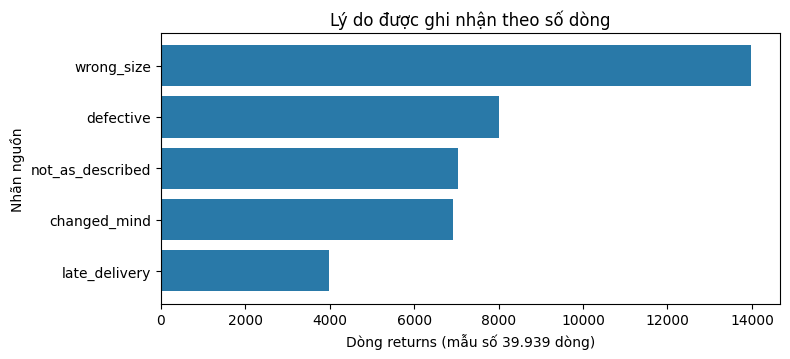

**Quan sát/bằng chứng:** {'NULL thật': 0, 'Chuỗi rỗng': 0, 'Chỉ khoảng trắng': 0, 'Thiếu theo quy ước': 0, 'Khác sau strip': 0, 'Nhãn gốc phân biệt': 5, 'Nhãn sau strip/casefold': 5}; `wrong_size` dẫn đầu số dòng (13.967, 34,97%) và `wrong_size` dẫn đầu số đơn (13.489). Có 2.939 đơn nhiều lý do; tổng số đơn theo lý do là 39.038, trong khi hợp tập chỉ 36.062 đơn. **Ý nghĩa:** ưu tiên kiểm tra hồ sơ của nhãn phổ biến; không cộng số đơn của các lý do để suy tổng. **Giới hạn:** các nhãn là thông tin ghi nhận, chưa kiểm chứng trách nhiệm hoặc nguyên nhân. **Câu hỏi tiếp:** nhãn do khách hàng hay nhân viên nhập, có cho phép chọn nhiều nhãn cho cùng hồ sơ không?

In [26]:
reason_raw043 = returns["return_reason"]
reason_normal043 = reason_raw043.str.strip().str.casefold()
reason_audit043 = {"NULL thật": int(reason_raw043.isna().sum()),
    "Chuỗi rỗng": int(reason_raw043.eq("").sum()),
    "Chỉ khoảng trắng": int((reason_raw043.ne("") & reason_raw043.str.strip().eq("")).sum()),
    "Thiếu theo quy ước": int(missing_mask(reason_raw043).sum()),
    "Khác sau strip": int(reason_raw043.ne(reason_raw043.str.strip()).sum()),
    "Nhãn gốc phân biệt": reason_raw043.nunique(dropna=False),
    "Nhãn sau strip/casefold": reason_normal043.nunique(dropna=False)}
reason043 = lines043.groupby("return_reason",dropna=False,sort=True).agg(
    rows=("return_id","size"),orders=("order_id","nunique"),quantity=("quantity","sum"),refund=("refund","sum"))
reason043["pairs"] = lines043.drop_duplicates(["return_reason","order_id","product_id"]).groupby("return_reason",dropna=False).size()
reason043["row_pct"] = 100 * reason043["rows"] / len(returns)
reason043 = reason043.sort_values(["rows","return_reason"],ascending=[False,True])
reason_table043 = reason043.reset_index().assign(nhan_goc=lambda f:f["return_reason"].map(repr)).rename(columns={
    "return_reason":"Lý do nguồn","nhan_goc":"Nhãn gốc (repr)","rows":"Dòng returns","orders":"Đơn phân biệt",
    "pairs":"Cặp phân biệt","quantity":"Lượng trả ghi nhận","refund":"Refund (ĐVT)","row_pct":"% / toàn bộ dòng returns"})
show(reason_table043,{"Refund (ĐVT)":lambda x:vn(x,2),"% / toàn bộ dòng returns":lambda x:vn(x,3)})
reason_per_order043 = lines043.groupby("order_id")["return_reason"].nunique(dropna=False)
reason_overlap043 = reason_per_order043.value_counts().sort_index().rename_axis("Số lý do/đơn").reset_index(name="Số đơn")
reason_overlap043["% / đơn có returns"] = 100 * reason_overlap043["Số đơn"] / n_return_orders
show(reason_overlap043,{"% / đơn có returns":lambda x:vn(x,3)})
fig,ax=plt.subplots(figsize=(8,3.7))
ax.barh(reason043.index[::-1],reason043["rows"].iloc[::-1],color="#2979a8")
ax.set(xlabel=f"Dòng returns (mẫu số {vn(len(returns))} dòng)",ylabel="Nhãn nguồn",title="Lý do được ghi nhận theo số dòng")
plot_done(fig)
top_reason_rows043 = reason043.index[0]
top_reason_orders043 = reason043.sort_values(["orders","return_reason"],ascending=[False,True]).index[0]
note(f"**Quan sát/bằng chứng:** {reason_audit043}; "
    f"`{top_reason_rows043}` dẫn đầu số dòng ({vn(reason043.loc[top_reason_rows043,'rows'])}, "
    f"{vn(reason043.loc[top_reason_rows043,'row_pct'],2)}%) và `{top_reason_orders043}` dẫn đầu số đơn "
    f"({vn(reason043.loc[top_reason_orders043,'orders'])}). "
    f"Có {vn(int(reason_per_order043.gt(1).sum()))} đơn nhiều lý do; tổng số đơn theo lý do là "
    f"{vn(reason043['orders'].sum())}, trong khi hợp tập chỉ {vn(n_return_orders)} đơn. "
    "**Ý nghĩa:** ưu tiên kiểm tra hồ sơ của nhãn phổ biến; không cộng số đơn của các lý do để suy tổng. "
    "**Giới hạn:** các nhãn là thông tin ghi nhận, chưa kiểm chứng trách nhiệm hoặc nguyên nhân. "
    "**Câu hỏi tiếp:** nhãn do khách hàng hay nhân viên nhập, có cho phép chọn nhiều nhãn cho cùng hồ sơ không?")
assert reason043["rows"].sum()==len(returns) and sum(reason043["refund"],ZERO)==refund_total
assert reason_overlap043["Số đơn"].sum()==n_return_orders

### NV04.3.2 – Số lượng hoàn trả ở cấp dòng và cấp đơn

Số lượng dẫn xuất dùng Decimal sau kiểm tra hợp lệ. Phân vị nội suy tuyến tính theo vị trí `(N−1)×p`; độ lệch chuẩn mẫu có `ddof=1`. Phân bố hiển thị riêng số lượng trên dòng, số dòng/đơn và tổng lượng/đơn, không gọi số dòng là số lần hoàn hàng. Tổng lượng chỉ là số lượng **ghi nhận**, chưa xác nhận nhập lại kho.

Cấp,N,Tổng,Min,Max,Mean,Median,Std mẫu,P25,P75,P90,P95,P99
Lượng/dòng returns,39939,109586,1,8,"2,7438","2,0000","1,8283","1,0000","4,0000","6,0000","6,0000","8,0000"
Tổng lượng/đơn có returns,36062,109586,1,18,"3,0388","2,0000","2,1139","1,0000","4,0000","6,0000","7,0000","9,0000"


Cấp,Giá trị,Số quan sát,Mẫu số quan sát,% / mẫu số,Giá trị × số quan sát
Lượng/dòng returns,1,13581,39939,"34,004",13581
Lượng/dòng returns,2,8633,39939,"21,615",17266
Lượng/dòng returns,3,6050,39939,"15,148",18150
Lượng/dòng returns,4,4464,39939,"11,177",17856
Lượng/dòng returns,5,3127,39939,"7,829",15635
Lượng/dòng returns,6,2126,39939,"5,323",12756
Lượng/dòng returns,7,1322,39939,"3,310",9254
Lượng/dòng returns,8,636,39939,"1,592",5088
Dòng/đơn có returns,1,32261,36062,"89,460",32261
Dòng/đơn có returns,2,3725,36062,"10,329",7450


Nhóm lượng/dòng,Dòng returns,% / toàn bộ dòng,Lượng ghi nhận
Bằng 1,13581,"34,004",13581
Bằng 2,8633,"21,615",17266
Lớn hơn 2,17725,"44,380",78739


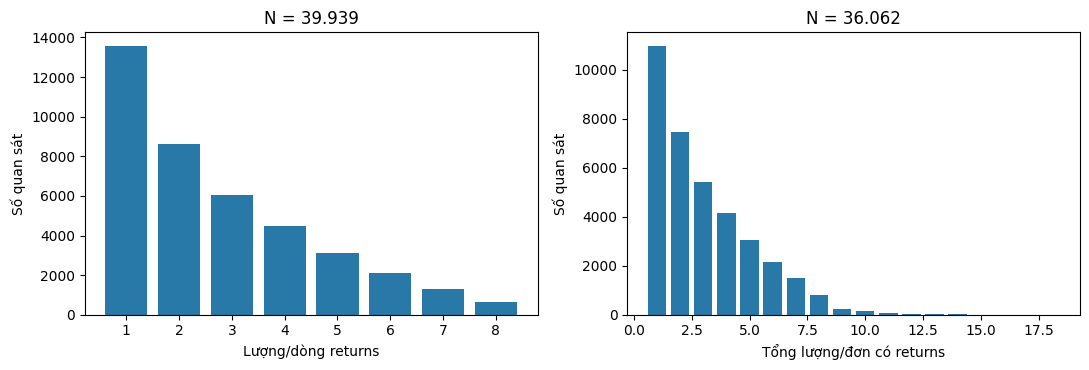

**Quan sát/bằng chứng:** 39.939 dòng, 36.062 đơn, 39.937 cặp, nhưng 109.586 đơn vị trả ghi nhận. Mean/median là 2,7438/2 trên dòng và 3,0388/2 trên đơn; max dòng 8, max đơn 18. **Ý nghĩa:** khối lượng ghi nhận cho xử lý khác số hồ sơ/đơn, nên cần các chỉ tiêu riêng. **Giới hạn:** chưa có trạng thái nhận hàng và đơn vị vật lý. **Câu hỏi tiếp:** một dòng có phải cùng lô/đợt xử lý và lượng ghi nhận có trùng lượng thực nhận không?

In [27]:
quantity_order043 = lines043.groupby("order_id").agg(rows=("return_id","size"),quantity=("quantity","sum"))
quantity_stats043 = pd.DataFrame([{"Cấp":label,"N":len(vals),"Tổng":sum(vals,ZERO),
    "Min":min(vals),"Max":max(vals),"Mean":statistics.mean(vals),"Median":statistics.median(vals),
    "Std mẫu":statistics.stdev(vals),
    **{f"P{int(q*100)}":q042(vals,q) for q in [.25,.75,.9,.95,.99]}}
    for label,vals in [("Lượng/dòng returns",list(rq043)),("Tổng lượng/đơn có returns",list(quantity_order043["quantity"]))]])
show(quantity_stats043,{c:lambda x:vn(x,4) for c in ["Mean","Median","Std mẫu","P25","P75","P90","P95","P99"]})
quantity_dist_records043=[]
for label,values in [("Lượng/dòng returns",rq043),("Dòng/đơn có returns",quantity_order043["rows"]),
                     ("Tổng lượng/đơn có returns",quantity_order043["quantity"])]:
    for value,count in sorted(Counter(values).items()):
        quantity_dist_records043.append({"Cấp":label,"Giá trị":value,"Số quan sát":count,
            "Mẫu số quan sát":len(values),"% / mẫu số":100*count/len(values),"Giá trị × số quan sát":value*count})
quantity_dist043=pd.DataFrame(quantity_dist_records043)
show(quantity_dist043,{"% / mẫu số":lambda x:vn(x,3)})
quantity_groups043=pd.DataFrame([{"Nhóm lượng/dòng":label,"Dòng returns":int(mask.sum()),
    "% / toàn bộ dòng":pct(int(mask.sum()),len(returns)),"Lượng ghi nhận":sum(rq043[mask],ZERO)}
    for label,mask in [("Bằng 1",rq043.eq(1)),("Bằng 2",rq043.eq(2)),("Lớn hơn 2",rq043.gt(2))]])
show(quantity_groups043,{"% / toàn bộ dòng":lambda x:vn(x,3)})
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
for ax,label in zip(axes,["Lượng/dòng returns","Tổng lượng/đơn có returns"]):
    data=quantity_dist043.loc[quantity_dist043["Cấp"].eq(label)]
    ax.bar(data["Giá trị"].map(int),data["Số quan sát"],color="#2979a8")
    ax.set(xlabel=label,ylabel="Số quan sát",title=f"N = {vn(data['Số quan sát'].sum())}")
plot_done(fig)
note(f"**Quan sát/bằng chứng:** {vn(len(returns))} dòng, {vn(n_return_orders)} đơn, "
    f"{vn(len(return_pair042))} cặp, nhưng {vn(sum(rq043,ZERO))} đơn vị trả ghi nhận. "
    f"Mean/median là {vn(statistics.mean(rq043),4)}/{vn(statistics.median(rq043),0)} trên dòng và "
    f"{vn(statistics.mean(quantity_order043['quantity']),4)}/{vn(statistics.median(quantity_order043['quantity']),0)} trên đơn; "
    f"max dòng {vn(max(rq043))}, max đơn {vn(max(quantity_order043['quantity']))}. "
    "**Ý nghĩa:** khối lượng ghi nhận cho xử lý khác số hồ sơ/đơn, nên cần các chỉ tiêu riêng. "
    "**Giới hạn:** chưa có trạng thái nhận hàng và đơn vị vật lý. "
    "**Câu hỏi tiếp:** một dòng có phải cùng lô/đợt xử lý và lượng ghi nhận có trùng lượng thực nhận không?")
assert sum(quantity_order043["quantity"],ZERO)==sum(rq043,ZERO)==sum(quantity_groups043["Lượng ghi nhận"],ZERO)

### NV04.3.3 – Sản phẩm: ba cách xếp hạng và quy mô mua

Đã xác minh `product_id` duy nhất, các mã có đối ứng và cặp trả nằm trong cặp mua. Tái sử dụng bảng mua đã tổng hợp theo `(order_id, product_id)`; sau đó tổng hợp mua và trả riêng theo sản phẩm, nối một–một. Không nối hai bảng chi tiết nhiều–nhiều.

Top 5 cho từng tiêu chí; đồng hạng sắp mã dạng chuỗi tăng dần, không coi top 5 là mọi sản phẩm đồng hạng. Bảng hiển thị tử số, mẫu số và tỷ số quan sát được. Cảnh báo mẫu nhỏ khi dưới 30 cặp mua hoặc dưới 30 dòng trả là quy tắc đọc mô tả, không phải kiểm định thống kê. Chưa xác minh khác biệt đơn vị vật lý giữa các sản phẩm; tổng lượng được hiểu theo đơn vị ghi nhận của nguồn.

In [28]:
return_product043=lines043.groupby("product_id",sort=True).agg(rows=("return_id","size"),
    orders=("order_id","nunique"),quantity=("quantity","sum"),refund=("refund","sum"))
return_product043["pairs"]=lines043.drop_duplicates(["order_id","product_id"]).groupby("product_id").size()
buy_product043=purchase043.groupby("product_id").agg(buy_orders=("order_id","nunique"),
    buy_pairs=("order_id","size"),buy_quantity=("purchased_quantity","sum"))
product043=return_product043.merge(buy_product043,on="product_id",how="left",validate="one_to_one")
product043=product043.reset_index().merge(products043[["product_id","product_name","category"]],
    on="product_id",how="left",validate="one_to_one")
product043["pair_pct"]=100*product043["pairs"]/product043["buy_pairs"]
product043["qty_pct"]=[100*q/b for q,b in zip(product043["quantity"],product043["buy_quantity"])]
product043["small"]=(product043["buy_pairs"]<small_cut043)|(product043["rows"]<small_cut043)
top_product_parts043=[]
for criterion,label in [("orders","Số đơn có returns"),("quantity","Lượng trả ghi nhận"),("refund","Tổng Refund ghi nhận")]:
    part=product043.sort_values([criterion,"product_id"],ascending=[False,True]).head(5).copy()
    part.insert(0,"Tiêu chí top",label);part.insert(1,"Hạng",range(1,len(part)+1))
    top_product_parts043.append(part)
top_product043=pd.concat(top_product_parts043,ignore_index=True)
product_labels043={"product_id":"Mã sản phẩm","product_name":"Tên nguồn","category":"Danh mục nguồn",
    "rows":"Dòng trả","orders":"Đơn có returns","pairs":"Cặp có returns","quantity":"Lượng trả",
    "refund":"Refund (ĐVT)","buy_orders":"Đơn mua","buy_pairs":"Cặp mua (mẫu số)","buy_quantity":"Lượng mua (mẫu số)",
    "pair_pct":"% cặp trả / cặp mua quan sát","qty_pct":"% lượng trả / mua ghi nhận","small":"Mẫu nhỏ"}
show(top_product043.rename(columns=product_labels043),{"Refund (ĐVT)":lambda x:vn(x,2),
    "% cặp trả / cặp mua quan sát":lambda x:vn(x,3),"% lượng trả / mua ghi nhận":lambda x:vn(x,3)})
leader_orders043=top_product_parts043[0].iloc[0];leader_refund043=top_product_parts043[2].iloc[0]
note(f"**Quan sát/bằng chứng:** {vn(len(product043))} sản phẩm có returns; "
    f"{leader_orders043['product_name']} (mã {leader_orders043['product_id']}) dẫn đầu số đơn "
    f"({vn(leader_orders043['orders'])}/{vn(leader_orders043['buy_orders'])} đơn mua; "
    f"{vn(leader_orders043['pair_pct'],3)}% cặp), lượng trả {vn(leader_orders043['quantity'])}; "
    f"{leader_refund043['product_name']} (mã {leader_refund043['product_id']}) dẫn đầu Refund "
    f"({vn(leader_refund043['refund'],2)} ĐVT). "
    "**Ý nghĩa:** danh sách cần kiểm tra thay đổi theo số đơn, lượng hoặc tiền; phải đọc cùng lượng mua. "
    f"Có {vn(int(product043['small'].sum()))} sản phẩm chạm ít nhất một ngưỡng mẫu nhỏ. "
    "**Giới hạn:** chưa thể quy chênh lệch cho chất lượng hoặc chỉ cho quy mô bán; không cộng đơn phân biệt giữa sản phẩm. "
    "**Câu hỏi tiếp:** đơn vị, mức giá, cơ cấu hàng và cửa sổ quan sát có giải thích thứ hạng khác nhau không?")
assert product043["rows"].sum()==len(returns) and sum(product043["refund"],ZERO)==refund_total

Tiêu chí top,Hạng,Mã sản phẩm,Dòng trả,Đơn có returns,Lượng trả,Refund (ĐVT),Cặp có returns,Đơn mua,Cặp mua (mẫu số),Lượng mua (mẫu số),Tên nguồn,Danh mục nguồn,% cặp trả / cặp mua quan sát,% lượng trả / mua ghi nhận,Mẫu nhỏ
Số đơn có returns,1,792,619,619,1732,"1.198.785,24",619,10160,10160,45726,HanoiStreet RP-80,Outdoor,"6,093","3,788",False
Số đơn có returns,2,791,582,582,1577,"1.074.580,85",582,10139,10139,45986,HanoiStreet RP-79,Outdoor,"5,740","3,429",False
Số đơn có returns,3,604,441,441,1169,"6.113.477,47",441,8115,8115,36515,SaigonFlex UC-69,Streetwear,"5,434","3,201",False
Số đơn có returns,4,2045,422,421,1089,"5.245.163,41",421,7924,7924,35844,UrbanVN UE-05,Streetwear,"5,313","3,038",False
Số đơn có returns,5,487,415,415,1129,"12.241.878,26",415,7418,7418,33277,SaigonFlex UM-92,Streetwear,"5,594","3,393",False
Lượng trả ghi nhận,1,792,619,619,1732,"1.198.785,24",619,10160,10160,45726,HanoiStreet RP-80,Outdoor,"6,093","3,788",False
Lượng trả ghi nhận,2,791,582,582,1577,"1.074.580,85",582,10139,10139,45986,HanoiStreet RP-79,Outdoor,"5,740","3,429",False
Lượng trả ghi nhận,3,604,441,441,1169,"6.113.477,47",441,8115,8115,36515,SaigonFlex UC-69,Streetwear,"5,434","3,201",False
Lượng trả ghi nhận,4,2332,402,402,1139,"5.687.513,09",402,7276,7276,32821,VietMotion UE-06,Streetwear,"5,525","3,470",False
Lượng trả ghi nhận,5,487,415,415,1129,"12.241.878,26",415,7418,7418,33277,SaigonFlex UM-92,Streetwear,"5,594","3,393",False


**Quan sát/bằng chứng:** 1.286 sản phẩm có returns; HanoiStreet RP-80 (mã 792) dẫn đầu số đơn (619/10.160 đơn mua; 6,093% cặp), lượng trả 1.732; SaigonFlex UM-92 (mã 487) dẫn đầu Refund (12.241.878,26 ĐVT). **Ý nghĩa:** danh sách cần kiểm tra thay đổi theo số đơn, lượng hoặc tiền; phải đọc cùng lượng mua. Có 973 sản phẩm chạm ít nhất một ngưỡng mẫu nhỏ. **Giới hạn:** chưa thể quy chênh lệch cho chất lượng hoặc chỉ cho quy mô bán; không cộng đơn phân biệt giữa sản phẩm. **Câu hỏi tiếp:** đơn vị, mức giá, cơ cấu hàng và cửa sổ quan sát có giải thích thứ hạng khác nhau không?

### NV04.3.4 – Danh mục: quy mô tuyệt đối và tỷ số quan sát

Mỗi danh mục có số sản phẩm có returns, dòng, đơn phân biệt, cặp và lượng trả/Refund. Mẫu số mua là **mọi cặp mua thuộc danh mục trong toàn bộ order_items**, gồm đơn không returns. Tỷ số cặp = cặp có returns/cặp mua; tỷ số lượng = tổng lượng trả ghi nhận/tổng lượng mua ghi nhận. Không tính mean của tỷ số sản phẩm để thay tỷ số tổng.

Mỗi tử số trả đã có đối ứng mua; không lọc ngày hay trạng thái riêng cho hai phía. Phạm vi là ảnh chụp dữ liệu đang có, không phải một cohort có thời gian theo dõi hoàn chỉnh. Cảnh báo mẫu nhỏ giữ cùng ngưỡng 30. Các đơn có thể chứa nhiều danh mục, nên không cộng số đơn giữa danh mục để suy tổng đơn.

Danh mục nguồn,Sản phẩm có returns,Dòng trả,Đơn có returns,Lượng trả,Refund (ĐVT),Cặp có returns,Cặp mua (mẫu số),Đơn mua,Lượng mua (mẫu số),% cặp trả / cặp mua quan sát,% lượng trả / mua ghi nhận,Mẫu nhỏ
Casual,82,1294,1272,3499,"14.027.094,37",1294,23991,23600,107469,"5,394","3,256",False
GenZ,99,2126,2120,5869,"11.145.648,17",2125,37154,37054,166848,"5,719","3,518",False
Outdoor,392,14720,11293,40417,"78.717.514,88",14720,259981,200454,1170000,"5,662","3,454",False
Streetwear,713,21799,21596,59801,"406.708.249,13",21798,393527,389543,1768826,"5,539","3,381",False


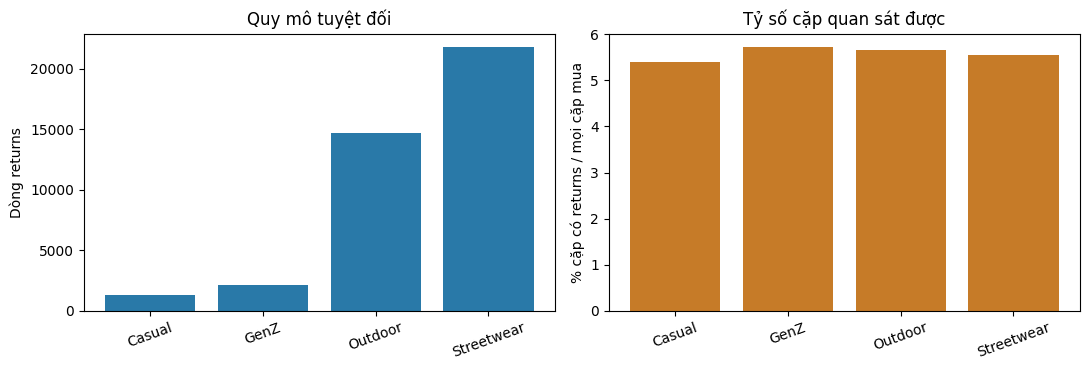

**Quan sát/bằng chứng:** Streetwear nhiều dòng nhất (21.799) trên 393.527 cặp mua, tỷ số cặp 5,539%; GenZ có tỷ số cặp cao nhất (2.125/37.154, 5,719%). Không danh mục nào chạm ngưỡng mẫu nhỏ: 0 nhóm. **Ý nghĩa:** số tuyệt đối lớn đi cùng quy mô bán lớn; thứ hạng thay đổi khi xét mẫu số, nên chưa thể nói chỉ do bán nhiều. **Giới hạn:** tỷ số mô tả chưa xác nhận tỷ lệ lỗi, tỷ lệ hoàn thành hay chất lượng. **Câu hỏi tiếp:** danh mục nguồn có phản ánh đúng thời điểm mua và các nhóm có thời gian theo dõi tương đương không?

In [29]:
category043=lines043.groupby("category").agg(products=("product_id","nunique"),rows=("return_id","size"),
    orders=("order_id","nunique"),quantity=("quantity","sum"),refund=("refund","sum"))
category043["pairs"]=lines043.drop_duplicates(["order_id","product_id"]).groupby("category").size()
category_buy043=purchase043.groupby("category").agg(buy_pairs=("order_id","size"),
    buy_orders=("order_id","nunique"),buy_quantity=("purchased_quantity","sum"))
category043=category043.join(category_buy043,validate="one_to_one")
category043["pair_pct"]=100*category043["pairs"]/category043["buy_pairs"]
category043["qty_pct"]=[100*q/b for q,b in zip(category043["quantity"],category043["buy_quantity"])]
category043["small"]=(category043["buy_pairs"]<small_cut043)|(category043["rows"]<small_cut043)
show(category043.reset_index().rename(columns={**product_labels043,"products":"Sản phẩm có returns"}),
    {"Refund (ĐVT)":lambda x:vn(x,2),"% cặp trả / cặp mua quan sát":lambda x:vn(x,3),
     "% lượng trả / mua ghi nhận":lambda x:vn(x,3)})
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
axes[0].bar(category043.index,category043["rows"],color="#2979a8")
axes[0].set(title="Quy mô tuyệt đối",ylabel="Dòng returns")
axes[1].bar(category043.index,category043["pair_pct"],color="#c67b28")
axes[1].set(title="Tỷ số cặp quan sát được",ylabel="% cặp có returns / mọi cặp mua")
for ax in axes:ax.tick_params(axis="x",rotation=20)
plot_done(fig)
category_absolute043=category043["rows"].idxmax();category_relative043=category043["pair_pct"].idxmax()
note(f"**Quan sát/bằng chứng:** {category_absolute043} nhiều dòng nhất "
    f"({vn(category043.loc[category_absolute043,'rows'])}) trên "
    f"{vn(category043.loc[category_absolute043,'buy_pairs'])} cặp mua, tỷ số cặp "
    f"{vn(category043.loc[category_absolute043,'pair_pct'],3)}%; "
    f"{category_relative043} có tỷ số cặp cao nhất "
    f"({vn(category043.loc[category_relative043,'pairs'])}/{vn(category043.loc[category_relative043,'buy_pairs'])}, "
    f"{vn(category043.loc[category_relative043,'pair_pct'],3)}%). "
    f"Không danh mục nào chạm ngưỡng mẫu nhỏ: {int(category043['small'].sum())} nhóm. "
    "**Ý nghĩa:** số tuyệt đối lớn đi cùng quy mô bán lớn; thứ hạng thay đổi khi xét mẫu số, nên chưa thể nói chỉ do bán nhiều. "
    "**Giới hạn:** tỷ số mô tả chưa xác nhận tỷ lệ lỗi, tỷ lệ hoàn thành hay chất lượng. "
    "**Câu hỏi tiếp:** danh mục nguồn có phản ánh đúng thời điểm mua và các nhóm có thời gian theo dõi tương đương không?")
assert category043["rows"].sum()==len(returns) and category043["buy_pairs"].sum()==len(item_pair042)
assert sum(category043["quantity"],ZERO)==sum(rq043,ZERO)

### NV04.3.5 – Lý do × danh mục

Bảng chéo đếm dòng; bảng tổ hợp bổ sung đơn phân biệt và tổng lượng, tỷ trọng lý do **trong từng danh mục**. Mẫu số luôn là dòng returns của danh mục, không phải mọi đơn đã mua. Số đơn của các tổ hợp có thể giao nhau. Biểu đồ thể hiện tỷ trọng có ghi con số; khác biệt là liên hệ mô tả, chưa là ảnh hưởng của danh mục lên lý do.

Danh mục nguồn,changed_mind,defective,late_delivery,not_as_described,wrong_size
Casual,228,262,121,229,454
GenZ,349,429,240,375,733
Outdoor,2524,2999,1466,2577,5154
Streetwear,3830,4330,2159,3854,7626


Danh mục nguồn,Lý do nguồn,Dòng returns,Đơn phân biệt (có giao nhau),Lượng ghi nhận,Mẫu số dòng returns danh mục,% lý do trong danh mục,Mẫu nhỏ
Streetwear,wrong_size,7626,7602,20744,21799,"34,983",False
Outdoor,wrong_size,5154,4726,13957,14720,"35,014",False
Streetwear,defective,4330,4323,12028,21799,"19,863",False
Streetwear,not_as_described,3854,3849,10696,21799,"17,680",False
Streetwear,changed_mind,3830,3827,10526,21799,"17,570",False
Outdoor,defective,2999,2852,8351,14720,"20,374",False
Outdoor,not_as_described,2577,2472,7061,14720,"17,507",False
Outdoor,changed_mind,2524,2444,7071,14720,"17,147",False
Streetwear,late_delivery,2159,2156,5807,21799,"9,904",False
Outdoor,late_delivery,1466,1427,3977,14720,"9,959",False


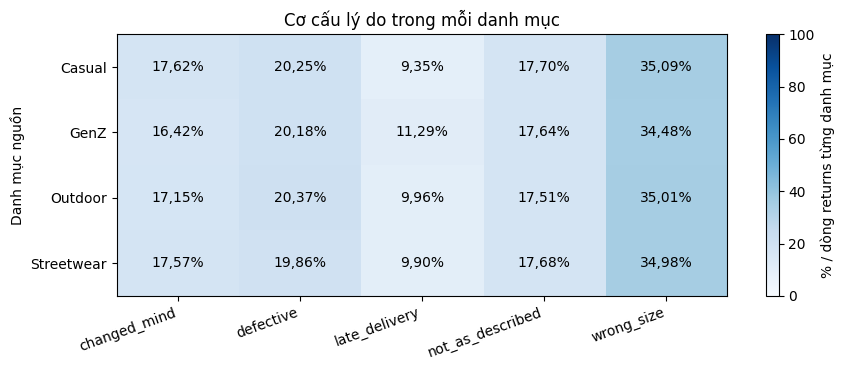

**Quan sát/bằng chứng:** tổ hợp lớn nhất là Streetwear × `wrong_size`: 7.626 dòng, 7.602 đơn, 34,98% dòng returns của danh mục. Nhãn `wrong_size` đứng đầu cả 4 danh mục; tỷ trọng từ 34,48% đến 35,09%. **Ý nghĩa:** có thể ưu tiên kiểm tra hồ sơ theo tổ hợp có nhiều dòng và xem hướng dẫn chọn nhãn. **Giới hạn:** cơ cấu trong returns không cho xác suất hoàn trả của mọi đơn; đơn không returns không được gán lý do. **Câu hỏi tiếp:** quy tắc nhập nhãn và độ đầy đủ mô tả có đồng nhất giữa danh mục không?

In [30]:
reason_category_counts043=pd.crosstab(lines043["category"],lines043["return_reason"],dropna=False)
reason_category_pct043=reason_category_counts043.div(category043["rows"],axis=0)*100
show(reason_category_counts043.rename_axis("Danh mục nguồn").reset_index())
reason_category043=lines043.groupby(["category","return_reason"],dropna=False).agg(
    rows=("return_id","size"),orders=("order_id","nunique"),quantity=("quantity","sum")).reset_index()
reason_category043["denominator"]=reason_category043["category"].map(category043["rows"])
reason_category043["pct"]=100*reason_category043["rows"]/reason_category043["denominator"]
reason_category043["small"]=reason_category043["rows"]<small_cut043
reason_category043=reason_category043.sort_values(["rows","category","return_reason"],ascending=[False,True,True])
show(reason_category043.rename(columns={"category":"Danh mục nguồn","return_reason":"Lý do nguồn",
    "rows":"Dòng returns","orders":"Đơn phân biệt (có giao nhau)","quantity":"Lượng ghi nhận",
    "denominator":"Mẫu số dòng returns danh mục","pct":"% lý do trong danh mục","small":"Mẫu nhỏ"}),
    {"% lý do trong danh mục":lambda x:vn(x,3)})
fig,ax=plt.subplots(figsize=(9,3.8))
im=ax.imshow(reason_category_pct043.to_numpy(),cmap="Blues",vmin=0,vmax=100,aspect="auto")
ax.set_xticks(range(len(reason_category_pct043.columns)),reason_category_pct043.columns,rotation=20,ha="right")
ax.set_yticks(range(len(reason_category_pct043)),reason_category_pct043.index)
for row in range(len(reason_category_pct043)):
    for col in range(len(reason_category_pct043.columns)):
        ax.text(col,row,vn(reason_category_pct043.iloc[row,col],2)+"%",ha="center",va="center")
fig.colorbar(im,ax=ax,label="% / dòng returns từng danh mục")
ax.set(title="Cơ cấu lý do trong mỗi danh mục",ylabel="Danh mục nguồn")
plot_done(fig)
largest_combo043=reason_category043.iloc[0]
wrong_pct043=reason_category_pct043["wrong_size"]
note(f"**Quan sát/bằng chứng:** tổ hợp lớn nhất là {largest_combo043['category']} × "
    f"`{largest_combo043['return_reason']}`: {vn(largest_combo043['rows'])} dòng, "
    f"{vn(largest_combo043['orders'])} đơn, {vn(largest_combo043['pct'],2)}% dòng returns của danh mục. "
    f"Nhãn `wrong_size` đứng đầu cả {len(category043)} danh mục; tỷ trọng từ "
    f"{vn(wrong_pct043.min(),2)}% đến {vn(wrong_pct043.max(),2)}%. "
    "**Ý nghĩa:** có thể ưu tiên kiểm tra hồ sơ theo tổ hợp có nhiều dòng và xem hướng dẫn chọn nhãn. "
    "**Giới hạn:** cơ cấu trong returns không cho xác suất hoàn trả của mọi đơn; đơn không returns không được gán lý do. "
    "**Câu hỏi tiếp:** quy tắc nhập nhãn và độ đầy đủ mô tả có đồng nhất giữa danh mục không?")
assert reason_category_counts043.to_numpy().sum()==len(returns)
assert np.allclose(reason_category_pct043.sum(axis=1),100)

### NV04.3.6 – Refund theo lý do và liên hệ với nhóm vượt Payment

Refund được cộng từ chính dòng returns theo nhãn của dòng, không gán tổng tiền của một đơn cho từng lý do. Phân biệt tổng tiền, mean/median trên dòng và Refund trên đơn vị trả ghi nhận. Chỉ tiêu cuối là tỷ số hai tổng cùng tập dòng, không phải giá bán hay mean của các tỷ số dòng; chưa coi đó là Refund thực chi.

In [31]:
refund_reason043=lines043.groupby("return_reason",dropna=False).agg(rows=("return_id","size"),
    orders=("order_id","nunique"),total=("refund","sum"),quantity=("quantity","sum"))
for col,quant in [("median",.5),("p25",.25),("p75",.75),("p90",.9),("p95",.95),("p99",.99)]:
    refund_reason043[col]=lines043.groupby("return_reason",dropna=False)["refund"].apply(lambda s:q042(list(s),quant))
refund_reason043["mean"]=[a/int(n) for a,n in zip(refund_reason043["total"],refund_reason043["rows"])]
refund_reason043["per_unit"]=[a/q for a,q in zip(refund_reason043["total"],refund_reason043["quantity"])]
refund_reason043=refund_reason043.sort_values(["total","return_reason"],ascending=[False,True])
refund_labels043={"return_reason":"Lý do nguồn","rows":"Dòng returns","orders":"Đơn phân biệt","quantity":"Lượng ghi nhận",
    "total":"Tổng Refund (ĐVT)","mean":"Mean/dòng (ĐVT)","median":"Median/dòng (ĐVT)",
    "p25":"P25/dòng (ĐVT)","p75":"P75/dòng (ĐVT)","p90":"P90/dòng (ĐVT)",
    "p95":"P95/dòng (ĐVT)","p99":"P99/dòng (ĐVT)","per_unit":"Refund/đơn vị ghi nhận (ĐVT)"}
refund_table043=refund_reason043.reset_index().rename(columns=refund_labels043)
show(refund_table043,{col:lambda x:vn(x,2) for col in refund_table043 if "(ĐVT)" in col})
top_refund_reason043=refund_reason043["total"].idxmax();top_mean_reason043=refund_reason043["mean"].idxmax()
note(f"**Quan sát/bằng chứng:** `{top_refund_reason043}` có tổng Refund lớn nhất "
    f"({vn(refund_reason043.loc[top_refund_reason043,'total'],2)} ĐVT), nhưng mean/dòng lớn nhất thuộc "
    f"`{top_mean_reason043}` ({vn(refund_reason043.loc[top_mean_reason043,'mean'],2)} ĐVT). "
    f"Mean/dòng giữa các lý do nằm trong [{vn(min(refund_reason043['mean']),2)}; "
    f"{vn(max(refund_reason043['mean']),2)}] ĐVT; bảng còn cho thấy median và các phân vị khác mean. "
    "**Ý nghĩa:** khối lượng hồ sơ và mức tiền trên dòng tạo hai thứ hạng cần đọc riêng. "
    "**Giới hạn:** chưa điều chỉnh cơ cấu giá, sản phẩm hay lượng, không suy rằng nhãn gây ra mức hoàn tiền. "
    "**Câu hỏi tiếp:** cùng sản phẩm/lượng và quy tắc hoàn tiền, chênh lệch mô tả có còn tương tự không?")
assert sum(refund_reason043["total"],ZERO)==refund_total

Lý do nguồn,Dòng returns,Đơn phân biệt,Tổng Refund (ĐVT),Lượng ghi nhận,Median/dòng (ĐVT),P25/dòng (ĐVT),P75/dòng (ĐVT),P90/dòng (ĐVT),P95/dòng (ĐVT),P99/dòng (ĐVT),Mean/dòng (ĐVT),Refund/đơn vị ghi nhận (ĐVT)
wrong_size,13967,13489,"176.687.200,75",38042,"7.852,26","3.546,60","16.740,00","30.525,26","41.497,68","65.612,23","12.650,33","4.644,53"
defective,8020,7856,"103.599.143,26",22274,"7.812,58","3.615,66","16.949,78","31.251,60","42.755,86","67.400,84","12.917,60","4.651,12"
not_as_described,7035,6913,"90.653.190,78",19358,"7.940,94","3.568,50","17.050,48","30.965,72","42.581,47","66.341,41","12.886,03","4.682,98"
changed_mind,6931,6839,"89.721.759,00",19144,"8.013,41","3.604,22","16.990,78","31.093,30","42.934,28","69.384,52","12.944,99","4.686,68"
late_delivery,3986,3941,"49.937.212,76",10768,"7.698,46","3.519,46","16.411,03","30.699,54","40.680,75","64.217,64","12.528,15","4.637,56"


**Quan sát/bằng chứng:** `wrong_size` có tổng Refund lớn nhất (176.687.200,75 ĐVT), nhưng mean/dòng lớn nhất thuộc `changed_mind` (12.944,99 ĐVT). Mean/dòng giữa các lý do nằm trong [12.528,15; 12.944,99] ĐVT; bảng còn cho thấy median và các phân vị khác mean. **Ý nghĩa:** khối lượng hồ sơ và mức tiền trên dòng tạo hai thứ hạng cần đọc riêng. **Giới hạn:** chưa điều chỉnh cơ cấu giá, sản phẩm hay lượng, không suy rằng nhãn gây ra mức hoàn tiền. **Câu hỏi tiếp:** cùng sản phẩm/lượng và quy tắc hoàn tiền, chênh lệch mô tả có còn tương tự không?

#### Đối chiếu lý do trong nhóm C và nhóm có returns ngoài C

Dùng đúng tập C của NV04.2: tổng Refund đơn − Payment **lớn hơn** dung sai 0,05 ĐVT, không làm tròn để phân loại. Đối chứng là đơn có returns ngoài C; xác minh nhóm D (Payment không hợp lệ) bằng 0 trước khi gọi đối chứng là “không vượt”. Không dùng đơn không returns để suy lý do.

Bảng có hai đơn vị phân tích riêng: tỷ trọng dòng lý do trên mọi dòng returns của nhóm; tỷ trọng đơn có lý do trên mọi đơn có returns của nhóm. Đơn nhiều lý do làm tổng tỷ trọng đơn có thể vượt 100%; cột chênh lệch dùng điểm phần trăm, không trộn đơn với dòng.

In [32]:
c_ids043=set(over042["order_id"])
assert not has042["group"].eq("D").any()
lines043["is_C"]=lines043["order_id"].isin(c_ids043)
group_scale043=lines043.groupby("is_C").agg(rows=("return_id","size"),orders=("order_id","nunique"))
multi_by_group043={flag:int(reason_per_order043.loc[reason_per_order043.index.isin(
    set(lines043.loc[lines043["is_C"].eq(flag),"order_id"]))].gt(1).sum()) for flag in [True,False]}
group_scale043["Đơn nhiều lý do"]=[multi_by_group043[flag] for flag in group_scale043.index]
show(group_scale043.reset_index().assign(is_C=lambda f:f["is_C"].map({True:"C: vượt",False:"Ngoài C: không vượt"})).rename(
    columns={"is_C":"Nhóm đơn có returns","rows":"Mẫu số dòng","orders":"Mẫu số đơn"}))
reason_group_records043=[]
for reason in reason043.index:
    rec={"Lý do nguồn":reason}
    for flag,label in [(True,"C"),(False,"Không vượt")]:
        block=lines043.loc[lines043["is_C"].eq(flag)&lines043["return_reason"].eq(reason)]
        rec[f"Dòng {label}"]=len(block);rec[f"Đơn {label}"]=block["order_id"].nunique()
        rec[f"Mẫu số dòng {label}"]=int(group_scale043.loc[flag,"rows"])
        rec[f"Mẫu số đơn {label}"]=int(group_scale043.loc[flag,"orders"])
        rec[f"% dòng {label}"]=pct(rec[f"Dòng {label}"],rec[f"Mẫu số dòng {label}"])
        rec[f"% đơn có lý do {label}"]=pct(rec[f"Đơn {label}"],rec[f"Mẫu số đơn {label}"])
    rec["Chênh % dòng C − không vượt (đpt)"]=rec["% dòng C"]-rec["% dòng Không vượt"]
    rec["Chênh % đơn C − không vượt (đpt)"]=rec["% đơn có lý do C"]-rec["% đơn có lý do Không vượt"]
    reason_group_records043.append(rec)
reason_group043=pd.DataFrame(reason_group_records043)
show(reason_group043,{col:lambda x:vn(x,3) for col in reason_group043 if "%" in col})
largest_gap043=reason_group043.loc[reason_group043["Chênh % dòng C − không vượt (đpt)"].abs().idxmax()]
note(f"**Quan sát/bằng chứng:** C có {vn(len(c_ids043))} đơn/{vn(group_scale043.loc[True,'rows'])} dòng, "
    f"ngoài C có {vn(group_scale043.loc[False,'orders'])} đơn/{vn(group_scale043.loc[False,'rows'])} dòng; "
    f"đơn nhiều lý do lần lượt {vn(multi_by_group043[True])} và {vn(multi_by_group043[False])}. "
    f"Chênh tỷ trọng dòng lớn nhất theo trị tuyệt đối ở `{largest_gap043['Lý do nguồn']}`: "
    f"{vn(largest_gap043['Chênh % dòng C − không vượt (đpt)'],3)} điểm phần trăm. "
    "**Ý nghĩa:** cơ cấu lý do là đầu mối chọn hồ sơ đối soát, không thay phép so sánh tiền ở cấp đơn. "
    "**Giới hạn:** chưa kiểm định hay kiểm soát cơ cấu sản phẩm/giá/lượng; không chứng minh lý do khiến Refund vượt Payment. "
    "**Câu hỏi tiếp:** chứng từ và quy tắc hoàn tiền của các đơn C có đặc điểm gì, ngoài nhãn đang ghi nhận?")
assert c_ids043==ind_c042 and len(c_ids043)==v03["metrics"]["refund_orders_above_payment"]

Nhóm đơn có returns,Mẫu số dòng,Mẫu số đơn,Đơn nhiều lý do
Ngoài C: không vượt,36079,32422,2767
C: vượt,3860,3640,172


Lý do nguồn,Dòng C,Đơn C,Mẫu số dòng C,Mẫu số đơn C,% dòng C,% đơn có lý do C,Dòng Không vượt,Đơn Không vượt,Mẫu số dòng Không vượt,Mẫu số đơn Không vượt,% dòng Không vượt,% đơn có lý do Không vượt,Chênh % dòng C − không vượt (đpt),Chênh % đơn C − không vượt (đpt)
wrong_size,1335,1308,3860,3640,"34,585","35,934",12632,12181,36079,32422,"35,012","37,570","-0,427","-1,636"
defective,767,764,3860,3640,"19,870","20,989",7253,7092,36079,32422,"20,103","21,874","-0,233","-0,885"
not_as_described,677,670,3860,3640,"17,539","18,407",6358,6243,36079,32422,"17,622","19,255","-0,084","-0,849"
changed_mind,671,665,3860,3640,"17,383","18,269",6260,6174,36079,32422,"17,351","19,043","0,033","-0,773"
late_delivery,410,407,3860,3640,"10,622","11,181",3576,3534,36079,32422,"9,912","10,900","0,710","0,281"


**Quan sát/bằng chứng:** C có 3.640 đơn/3.860 dòng, ngoài C có 32.422 đơn/36.079 dòng; đơn nhiều lý do lần lượt 172 và 2.767. Chênh tỷ trọng dòng lớn nhất theo trị tuyệt đối ở `late_delivery`: 0,710 điểm phần trăm. **Ý nghĩa:** cơ cấu lý do là đầu mối chọn hồ sơ đối soát, không thay phép so sánh tiền ở cấp đơn. **Giới hạn:** chưa kiểm định hay kiểm soát cơ cấu sản phẩm/giá/lượng; không chứng minh lý do khiến Refund vượt Payment. **Câu hỏi tiếp:** chứng từ và quy tắc hoàn tiền của các đơn C có đặc điểm gì, ngoài nhãn đang ghi nhận?

### NV04.3.7 – Bất thường, cực trị và giới hạn

Phân biệt A: vi phạm kỹ thuật có ràng buộc và bằng chứng; B: hiện tượng nghiệp vụ cần làm rõ; C: định nghĩa/độ phủ dữ liệu chưa đủ. Cặp lặp không được xem là vi phạm khóa nếu chưa có ràng buộc duy nhất theo cặp. So lượng và tiền bằng bảng cặp đã cộng hết mọi dòng ở cả hai phía; Refund vượt Gross/Net là đối chiếu số học, chưa là tổn thất.

Gắn cờ giá trị cực đoan theo hàng rào trên `Q3 + 1,5×IQR` của tổng Refund/sản phẩm và tổng Refund/danh mục; không xóa bản ghi và không mặc định có lỗi. Danh mục chỉ có bốn nhóm nên quy tắc IQR có sức diễn giải hạn chế; luôn đối chiếu thêm cực đại theo từng chỉ tiêu. Nhóm mẫu nhỏ dùng ngưỡng mô tả 30 đã công bố.

In [33]:
extreme_info043=[]
for label,frame in [("Sản phẩm",product043),("Danh mục",category043.reset_index())]:
    values=list(frame["refund"]);q1x=q042(values,.25);q3x=q042(values,.75);fence=q3x+Decimal("1.5")*(q3x-q1x)
    mask=frame["refund"]>fence
    extreme_info043.append({"Cấp":label,"Mẫu số nhóm":len(frame),"Q1 Refund (ĐVT)":q1x,
        "Q3 Refund (ĐVT)":q3x,"Ngưỡng trên (ĐVT)":fence,"Nhóm vượt ngưỡng":int(mask.sum()),
        "Nhóm mẫu nhỏ":int(frame["small"].sum()),"Max dòng trả":int(frame["rows"].max()),
        "Max lượng trả":max(frame["quantity"]),"Max Refund (ĐVT)":max(values)})
extreme_summary043=pd.DataFrame(extreme_info043)
show(extreme_summary043,{c:lambda x:vn(x,2) for c in extreme_summary043 if "(ĐVT)" in c})
technical_bad043 = int(not products043["product_id"].is_unique)+len(missing_product043)+len(missing_item_product043)+int(pair_orphan042.sum())
issues043=pd.DataFrame([
    {"Loại":"A","Vấn đề":"Khóa products và tồn tại mã/cặp", "Bằng chứng":f"{technical_bad043} vi phạm kỹ thuật trên các kiểm tra đã nêu",
     "Nguồn/kiểm tra":"products043; missing_product043; missing_item_product043; pair_orphan042", "Giới hạn/câu hỏi":"Không suy mọi quy tắc nghiệp vụ đều đúng; cần khóa dòng bán–trả."},
    {"Loại":"B","Vấn đề":"Cặp lặp trong returns/order_items", "Bằng chứng":f"{repeat_pair_counts042['returns']} / {repeat_pair_counts042['order_items']} cặp; mọi dòng được giữ",
     "Nguồn/kiểm tra":"return_pair042 / item_pair042; tổng hợp trước JOIN", "Giới hạn/câu hỏi":"Cặp không được khai báo duy nhất; nhiều đợt xử lý hay nhiều dòng mua?"},
    {"Loại":"B","Vấn đề":"Lượng trả vượt lượng mua cùng cặp", "Bằng chứng":f"{int(pairs042['quantity_excess'].gt(0).sum())} / {len(pairs042)} cặp",
     "Nguồn/kiểm tra":"pairs042: returned_quantity − purchased_quantity > 0", "Giới hạn/câu hỏi":"Tổng lượng không xác nhận nhập lại kho; cần đơn vị và sự kiện thực tế."},
    {"Loại":"B","Vấn đề":"Refund vượt Gross / Net cùng cặp", "Bằng chứng":f"{int(pairs042['refund_above_gross'].sum())} / {int(pairs042['refund_above_net'].sum())} cặp (dung sai {TOL} ĐVT)",
     "Nguồn/kiểm tra":"pairs042; Decimal; Gross=Σq×giá, Net=Gross−Σgiảm giá dòng", "Giới hạn/câu hỏi":"Chênh lệch số học; cần quy tắc tiền và phân bổ giảm giá, chưa kết luận lỗi chính sách."},
    {"Loại":"B","Vấn đề":"Đơn C: Refund vượt Payment", "Bằng chứng":f"{len(c_ids043)} / {n_return_orders} đơn có returns",
     "Nguồn/kiểm tra":"over042; reason_group043", "Giới hạn/câu hỏi":"Không đồng nhất chênh lệch với tổn thất; cần chứng từ quyết toán."},
    {"Loại":"C","Vấn đề":"Nhãn thiếu, khoảng trắng và biến thể", "Bằng chứng":str(reason_audit043),
     "Nguồn/kiểm tra":"return_reason nguồn; strip/casefold chỉ dùng đối chiếu", "Giới hạn/câu hỏi":"Không có nhãn lỗi cú pháp hiện tại không chứng minh lý do đúng thực tế; ai nhập nhãn?"},
    {"Loại":"C","Vấn đề":"Mẫu nhỏ và tổng Refund cực đoan", "Bằng chứng":f"{int(product043['small'].sum())} sản phẩm mẫu nhỏ; {extreme_info043[0]['Nhóm vượt ngưỡng']} sản phẩm và {extreme_info043[1]['Nhóm vượt ngưỡng']} danh mục vượt hàng rào IQR",
     "Nguồn/kiểm tra":"product043; category043; extreme_summary043", "Giới hạn/câu hỏi":"Ngưỡng mô tả không là kiểm định; quy mô mua, giá và lượng có liên quan thế nào?"},
    {"Loại":"C","Vấn đề":"Định nghĩa và độ phủ", "Bằng chứng":"Không có trạng thái thực nhận/chi tiền, khóa dòng bán–trả, lịch sử category, cửa sổ theo dõi chuẩn trong các bảng dùng",
     "Nguồn/kiểm tra":"schema043; dữ liệu đọc trong NV04.1–NV04.3", "Giới hạn/câu hỏi":"Bổ sung từ điển và chứng từ; chưa suy chất lượng, nguyên nhân hay tổn thất thực tế."}])
show(issues043)
note(f"**Quan sát/bằng chứng:** chưa phát hiện vi phạm kỹ thuật trong tập ràng buộc đã kiểm tra ({technical_bad043}); "
    f"{repeat_pair_counts042['returns']} cặp trả lặp, {repeat_pair_counts042['order_items']} cặp mua lặp, "
    f"{vn(int(pairs042['refund_above_net'].sum()))} cặp vượt Net vẫn giữ nguyên. "
    "**Ý nghĩa:** tách sự kiện cần chứng từ khỏi kiểm tra kỹ thuật để chọn đúng hướng xử lý. "
    "**Giới hạn:** số lớn và cờ IQR không tự chứng minh sai dữ liệu; không xóa hoặc sửa dòng. "
    "**Câu hỏi tiếp:** ràng buộc nào được nghiệp vụ cam kết và cần tài liệu nào để chuyển một hiện tượng B/C thành kết luận đã xác minh?")

Cấp,Mẫu số nhóm,Q1 Refund (ĐVT),Q3 Refund (ĐVT),Ngưỡng trên (ĐVT),Nhóm vượt ngưỡng,Nhóm mẫu nhỏ,Max dòng trả,Max lượng trả,Max Refund (ĐVT)
Sản phẩm,1286,"33.658,96","332.696,52","781.252,88",158,973,619,1732,"12.241.878,26"
Danh mục,4,"13.306.732,82","160.715.198,44","381.827.896,88",1,0,21799,59801,"406.708.249,13"


Loại,Vấn đề,Bằng chứng,Nguồn/kiểm tra,Giới hạn/câu hỏi
A,Khóa products và tồn tại mã/cặp,0 vi phạm kỹ thuật trên các kiểm tra đã nêu,products043; missing_product043; missing_item_product043; pair_orphan042,Không suy mọi quy tắc nghiệp vụ đều đúng; cần khóa dòng bán–trả.
B,Cặp lặp trong returns/order_items,2 / 16 cặp; mọi dòng được giữ,return_pair042 / item_pair042; tổng hợp trước JOIN,Cặp không được khai báo duy nhất; nhiều đợt xử lý hay nhiều dòng mua?
B,Lượng trả vượt lượng mua cùng cặp,0 / 39937 cặp,pairs042: returned_quantity − purchased_quantity > 0,Tổng lượng không xác nhận nhập lại kho; cần đơn vị và sự kiện thực tế.
B,Refund vượt Gross / Net cùng cặp,0 / 4423 cặp (dung sai 0.05 ĐVT),"pairs042; Decimal; Gross=Σq×giá, Net=Gross−Σgiảm giá dòng","Chênh lệch số học; cần quy tắc tiền và phân bổ giảm giá, chưa kết luận lỗi chính sách."
B,Đơn C: Refund vượt Payment,3640 / 36062 đơn có returns,over042; reason_group043,Không đồng nhất chênh lệch với tổn thất; cần chứng từ quyết toán.
C,"Nhãn thiếu, khoảng trắng và biến thể","{'NULL thật': 0, 'Chuỗi rỗng': 0, 'Chỉ khoảng trắng': 0, 'Thiếu theo quy ước': 0, 'Khác sau strip': 0, 'Nhãn gốc phân biệt': 5, 'Nhãn sau strip/casefold': 5}",return_reason nguồn; strip/casefold chỉ dùng đối chiếu,Không có nhãn lỗi cú pháp hiện tại không chứng minh lý do đúng thực tế; ai nhập nhãn?
C,Mẫu nhỏ và tổng Refund cực đoan,973 sản phẩm mẫu nhỏ; 158 sản phẩm và 1 danh mục vượt hàng rào IQR,product043; category043; extreme_summary043,"Ngưỡng mô tả không là kiểm định; quy mô mua, giá và lượng có liên quan thế nào?"
C,Định nghĩa và độ phủ,"Không có trạng thái thực nhận/chi tiền, khóa dòng bán–trả, lịch sử category, cửa sổ theo dõi chuẩn trong các bảng dùng",schema043; dữ liệu đọc trong NV04.1–NV04.3,"Bổ sung từ điển và chứng từ; chưa suy chất lượng, nguyên nhân hay tổn thất thực tế."


**Quan sát/bằng chứng:** chưa phát hiện vi phạm kỹ thuật trong tập ràng buộc đã kiểm tra (0); 2 cặp trả lặp, 16 cặp mua lặp, 4.423 cặp vượt Net vẫn giữ nguyên. **Ý nghĩa:** tách sự kiện cần chứng từ khỏi kiểm tra kỹ thuật để chọn đúng hướng xử lý. **Giới hạn:** số lớn và cờ IQR không tự chứng minh sai dữ liệu; không xóa hoặc sửa dòng. **Câu hỏi tiếp:** ràng buộc nào được nghiệp vụ cam kết và cần tài liệu nào để chuyển một hiện tượng B/C thành kết luận đã xác minh?

### Đối chứng độc lập – sáu tình huống và quét lại CSV

Bộ ví dụ nhỏ được tạo hoàn toàn trong bộ nhớ, không thêm vào bảng nguồn: một đơn hai lý do; sản phẩm/cặp có nhiều dòng mua; cặp nhiều dòng returns; đơn mua hai sản phẩm chỉ trả một; hai danh mục khác quy mô; một đơn vượt Payment. Kết quả mong đợi được ghi trực tiếp, độc lập với phép tổng hợp. Thêm ví dụ thực tế chỉ in mã và số tổng hợp để truy vết, không xuất toàn bộ chi tiết.

Quét CSV lại bằng `csv.DictReader`, `Counter`, tập và Decimal để đối chiếu mọi sản phẩm, danh mục, lý do và tổ hợp. Không dùng các bảng groupby làm kết quả mong đợi.

In [34]:
fixture_items043=pd.DataFrame([
    ["O1","P1","A",2],["O1","P1","A",3],["O1","P2","B",1],
    ["O2","P1","A",10],["O2","P2","B",1],["O3","P2","B",1]],
    columns=["order_id","product_id","category","quantity"])
fixture_returns043=pd.DataFrame([
    ["R1","O1","P1","r1",1,20],["R2","O1","P1","r2",2,40],["R3","O2","P1","r1",1,120]],
    columns=["return_id","order_id","product_id","reason","quantity","refund"])
fixture_ip043=fixture_items043.groupby(["order_id","product_id"]).agg(buy_quantity=("quantity","sum"),category=("category","first"))
fixture_rp043=fixture_returns043.groupby(["order_id","product_id"]).agg(return_quantity=("quantity","sum"),refund=("refund","sum"))
fixture_join043=fixture_rp043.join(fixture_ip043,validate="one_to_one")
fixture_category043=fixture_items043.groupby("category")["quantity"].sum()
fixture_reason_orders043=fixture_returns043.groupby("reason")["order_id"].nunique()
fixture_pay043={"O1":Decimal("100"),"O2":Decimal("100"),"O3":Decimal("100")}
fixture_refund043=fixture_returns043.groupby("order_id")["refund"].sum().to_dict()
fixture_c043={oid for oid,amount in fixture_refund043.items() if Decimal(int(amount))-fixture_pay043[oid]>TOL}
fixture_flags043={
    "Một đơn có hai lý do; cộng đơn lý do gây trùng":fixture_returns043.loc[fixture_returns043.order_id.eq("O1"),"reason"].nunique()==2 and fixture_reason_orders043.sum()==3 and fixture_returns043.order_id.nunique()==2,
    "Sản phẩm/cặp nhiều dòng mua được cộng đủ":fixture_items043.loc[fixture_items043.product_id.eq("P1"),"quantity"].sum()==15 and fixture_ip043.loc[("O1","P1"),"buy_quantity"]==5,
    "Cặp nhiều returns; JOIN không nhân tiền/lượng":len(fixture_join043)==2 and fixture_join043.loc[("O1","P1"),"refund"]==60 and fixture_join043.loc[("O1","P1"),"return_quantity"]==3 and fixture_join043["refund"].sum()==180,
    "Mua hai sản phẩm chỉ trả một; không gán reason cho P2":set(fixture_items043.loc[fixture_items043.order_id.eq("O1"),"product_id"])=={"P1","P2"} and set(fixture_returns043.loc[fixture_returns043.order_id.eq("O1"),"product_id"])=={"P1"},
    "Hai danh mục khác quy mô; mẫu số gồm không returns":fixture_category043.to_dict()=={"A":15,"B":3} and fixture_items043.drop_duplicates(["order_id","product_id"]).groupby("category").size().to_dict()=={"A":2,"B":3} and len(fixture_rp043)==2,
    "Đơn Refund vượt Payment dùng tiền cấp đơn":fixture_c043=={"O2"} and fixture_refund043=={"O1":60,"O2":120}}
show(pd.DataFrame([{"Ví dụ độc lập":label,"Đạt":bool(ok)} for label,ok in fixture_flags043.items()]))
real_multi_reason043=sorted(reason_per_order043.index[reason_per_order043.gt(1)])[0]
real_multi_buy043=sorted(item_pair042.index[item_pair042["item_pair_lines"].gt(1)])[0]
real_multi_return043=sorted(return_pair042.index[return_pair042["return_pair_lines"].gt(1)])[0]
buy_product_count043=item_pair042.reset_index().groupby("order_id").size()
return_product_count043=return_pair042.reset_index().groupby("order_id").size()
real_one_return043=sorted(oid for oid,n in return_product_count043.items() if n==1 and buy_product_count043[oid]>1)[0]
real_c043=sorted(c_ids043)[0]
real_examples043=pd.DataFrame([
    {"Tình huống":"Đơn nhiều lý do","Mã":real_multi_reason043,"Bằng chứng":"; ".join(sorted(set(lines043.loc[lines043.order_id.eq(real_multi_reason043),"return_reason"])))},
    {"Tình huống":"Cặp nhiều dòng mua","Mã":str(real_multi_buy043),"Bằng chứng":f"{item_pair042.loc[real_multi_buy043,'item_pair_lines']} dòng; tổng lượng {item_pair042.loc[real_multi_buy043,'purchased_quantity']}"},
    {"Tình huống":"Cặp nhiều dòng returns","Mã":str(real_multi_return043),"Bằng chứng":f"{return_pair042.loc[real_multi_return043,'return_pair_lines']} dòng; lượng {return_pair042.loc[real_multi_return043,'returned_quantity']}; Refund {return_pair042.loc[real_multi_return043,'RefundPair']} ĐVT"},
    {"Tình huống":"Mua nhiều sản phẩm chỉ trả một","Mã":real_one_return043,"Bằng chứng":f"{buy_product_count043[real_one_return043]} sản phẩm mua; 1 sản phẩm có returns"},
    {"Tình huống":"Hai danh mục khác quy mô","Mã":"; ".join(category043.index[[0,-1]]),"Bằng chứng":"; ".join(f"{cat}: {category043.loc[cat,'buy_pairs']} cặp mua" for cat in category043.index[[0,-1]])},
    {"Tình huống":"Đơn C","Mã":real_c043,"Bằng chứng":f"Refund {ind_refund[real_c043]} − Payment {ind_payments[real_c043]} = {ind_refund[real_c043]-ind_payments[real_c043]} ĐVT > {TOL}"}])
show(real_examples043)
def acc043():
    return {"rows":0,"orders":set(),"pairs":set(),"quantity":ZERO,"refund":ZERO,"products":set(),"values":[]}
def add043(acc,row):
    acc["rows"]+=1;acc["orders"].add(row["order_id"]);acc["pairs"].add((row["order_id"],row["product_id"]))
    acc["quantity"]+=Decimal(row["return_quantity"]);acc["refund"]+=Decimal(row["refund_amount"])
    acc["products"].add(row["product_id"]);acc["values"].append(Decimal(row["refund_amount"]))
ind_products043={}
with products_path043.open(encoding="utf-8-sig",newline="") as stream:
    for row in csv.DictReader(stream):
        assert row["product_id"] not in ind_products043
        ind_products043[row["product_id"]]=row
ind_reason043=defaultdict(acc043);ind_product043=defaultdict(acc043);ind_category043=defaultdict(acc043)
ind_combo043=defaultdict(acc043);ind_group_reason043=defaultdict(acc043);ind_order_reasons043=defaultdict(set)
ind_quantity_order043=defaultdict(Decimal);ind_quantity_rows043=[]
for row in csv_rows("returns"):
    pid=row["product_id"];reason=row["return_reason"];cat=ind_products043[pid]["category"]
    for mapping,key in [(ind_reason043,reason),(ind_product043,pid),(ind_category043,cat),
        (ind_combo043,(cat,reason)),(ind_group_reason043,(row["order_id"] in ind_c042,reason))]:add043(mapping[key],row)
    ind_order_reasons043[row["order_id"]].add(reason)
    ind_quantity_order043[row["order_id"]]+=Decimal(row["return_quantity"])
    ind_quantity_rows043.append(Decimal(row["return_quantity"]))
ind_buy_product043=defaultdict(lambda:{"orders":set(),"pairs":set(),"quantity":ZERO})
ind_buy_category043=defaultdict(lambda:{"orders":set(),"pairs":set(),"quantity":ZERO})
for row in csv_rows("order_items"):
    pid=row["product_id"];cat=ind_products043[pid]["category"]
    for mapping,key in [(ind_buy_product043,pid),(ind_buy_category043,cat)]:
        acc=mapping[key];acc["orders"].add(row["order_id"]);acc["pairs"].add((row["order_id"],pid));acc["quantity"]+=Decimal(row["quantity"])
note("**Quan sát/bằng chứng:** sáu ví dụ tổng hợp có kết quả mong đợi cố định, kèm sáu dòng truy vết thực tế. "
    "**Ý nghĩa:** kiểm tra đúng đơn vị và mẫu số khi có nhiều lý do, nhiều dòng mua/trả. "
    "**Giới hạn:** ví dụ xác minh công thức, không chứng minh chính sách; đối chứng toàn bộ khóa được đánh giá ở bảng sau. "
    "**Câu hỏi tiếp:** có thể bổ sung mã sự kiện và chứng từ để truy vết từ cặp về đúng dòng bán không?")

Ví dụ độc lập,Đạt
Một đơn có hai lý do; cộng đơn lý do gây trùng,True
Sản phẩm/cặp nhiều dòng mua được cộng đủ,True
Cặp nhiều returns; JOIN không nhân tiền/lượng,True
Mua hai sản phẩm chỉ trả một; không gán reason cho P2,True
Hai danh mục khác quy mô; mẫu số gồm không returns,True
Đơn Refund vượt Payment dùng tiền cấp đơn,True


Tình huống,Mã,Bằng chứng
Đơn nhiều lý do,100158,defective; wrong_size
Cặp nhiều dòng mua,"('113379', '786')",2 dòng; tổng lượng 7
Cặp nhiều dòng returns,"('397622', '2045')",2 dòng; lượng 11; Refund 57690.97 ĐVT
Mua nhiều sản phẩm chỉ trả một,831927,2 sản phẩm mua; 1 sản phẩm có returns
Hai danh mục khác quy mô,Casual; Streetwear,Casual: 23991 cặp mua; Streetwear: 393527 cặp mua
Đơn C,103873,Refund 6424.47 − Payment 6367.6 = 56.87 ĐVT > 0.05


**Quan sát/bằng chứng:** sáu ví dụ tổng hợp có kết quả mong đợi cố định, kèm sáu dòng truy vết thực tế. **Ý nghĩa:** kiểm tra đúng đơn vị và mẫu số khi có nhiều lý do, nhiều dòng mua/trả. **Giới hạn:** ví dụ xác minh công thức, không chứng minh chính sách; đối chứng toàn bộ khóa được đánh giá ở bảng sau. **Câu hỏi tiếp:** có thể bổ sung mã sự kiện và chứng từ để truy vết từ cặp về đúng dòng bán không?

### Kiểm chứng NV04.3

Đối chiếu tổng, từng nhóm và mọi khóa với lần đọc CSV độc lập. Mốc lịch sử chỉ là kỳ vọng kiểm chứng, không dùng tạo kết quả. Kiểm tra riêng giữ nguyên 49 ô/output và SHA-256 mọi tệp ngoài notebook, gồm raw, NV01–NV03, V01–V09 và tài liệu untracked. Hai lượt Run All và so output cũ được bộ chạy bên ngoài ghi vào metadata `nv043_run_all`; kết quả dưới đây không tự nhận là đã có hai lượt trước khi chúng hoàn tất.

In [35]:
checks043=[]
def check043(label,condition,detail="Đối chiếu trực tiếp hoặc CSV độc lập"):
    checks043.append({"Kiểm chứng":label,"Trạng thái":"Đạt" if bool(condition) else "Không đạt","Bằng chứng/giới hạn":detail})
def na043(label,detail):
    checks043.append({"Kiểm chứng":label,"Trạng thái":"Không áp dụng","Bằng chứng/giới hạn":detail})
def same_agg043(frame,oracle,key_col=None):
    records=frame.reset_index().to_dict("records") if key_col is None else frame.to_dict("records")
    key_col=key_col or frame.index.name
    return len(records)==len(oracle) and all(
        [row["rows"],row["orders"],row["pairs"],row["quantity"],row["refund"]]==
        [a["rows"],len(a["orders"]),len(a["pairs"]),a["quantity"],a["refund"]]
        for row in records for a in [oracle[row[key_col]]])
check043("Dòng returns giữ nguyên 39.939",len(returns)==39939==len(ind_quantity_rows043))
check043("Đơn có returns giữ nguyên 36.062",n_return_orders==36062==len(ind_order_reasons043))
check043("Refund giữ nguyên 510.598.506,55 ĐVT",refund_total==Decimal("510598506.55")==sum(a["refund"] for a in ind_reason043.values()))
check043("Kiểu/NULL/số lượng được kiểm tra; không loại dòng",quality043[["NULL","Sai cú pháp","Không hữu hạn","Âm","Bằng 0"]].to_numpy().sum()==0 and quality043.loc[quality043["Trường"].isin(["return_quantity","quantity"]),"Không nguyên"].sum()==0 and len(lines043)==len(returns))
check043("Nhãn nguồn được giữ, khảo sát thiếu và biến thể",reason_raw043.equals(returns["return_reason"]) and set(reason043.index)==set(ind_reason043) and reason_audit043["Thiếu theo quy ước"]==0 and reason_audit043["Nhãn gốc phân biệt"]==reason_audit043["Nhãn sau strip/casefold"])
check043("Mọi chỉ tiêu từng lý do khớp CSV độc lập",same_agg043(reason043,ind_reason043))
check043("Tổng dòng/Refund/lượng theo lý do bảo toàn",reason043["rows"].sum()==len(returns) and sum(reason043["refund"],ZERO)==refund_total and sum(reason043["quantity"],ZERO)==sum(rq043,ZERO))
check043("Từng tỷ trọng lý do dùng toàn bộ dòng returns",all(math.isclose(row.rows/len(returns)*100,row.row_pct) for row in reason043.itertuples()))
check043("Từng đơn nhiều lý do đúng tập độc lập",reason_per_order043.to_dict()=={k:len(v) for k,v in ind_order_reasons043.items()})
check043("Không cộng đơn giao nhau để suy tổng",set().union(*(a["orders"] for a in ind_reason043.values()))==set(return_counts.index) and reason043["orders"].sum()==sum(len(v) for v in ind_order_reasons043.values()))
check043("Phân bố số lý do/đơn khớp Counter",dict(zip(reason_overlap043["Số lý do/đơn"],reason_overlap043["Số đơn"]))==dict(Counter(map(len,ind_order_reasons043.values()))))
check043("Từng lượng/đơn và tổng lượng khớp CSV",quantity_order043["quantity"].to_dict()==dict(ind_quantity_order043) and sum(rq043,ZERO)==sum(ind_quantity_order043.values(),ZERO))
check043("Min/max/mean/median/std và phân vị lượng đúng hai cấp",all(
    row["N"]==len(vals) and row["Min"]==min(vals) and row["Max"]==max(vals) and row["Tổng"]==sum(vals,ZERO) and
    row["Mean"]==statistics.mean(vals) and row["Median"]==statistics.median(vals) and row["Std mẫu"]==statistics.stdev(vals) and
    all(row[f"P{p}"]==statistics.quantiles(vals,n=100,method="inclusive")[p-1] for p in [25,75,90,95,99])
    for row,vals in zip(quantity_stats043.to_dict("records"),[ind_quantity_rows043,list(ind_quantity_order043.values())])))
check043("Ba phân bố lượng/dòng/đơn đúng từng tần số",all(
    dict(zip(quantity_dist043.loc[quantity_dist043["Cấp"].eq(label),"Giá trị"],quantity_dist043.loc[quantity_dist043["Cấp"].eq(label),"Số quan sát"]))==dict(Counter(values))
    for label,values in [("Lượng/dòng returns",ind_quantity_rows043),("Dòng/đơn có returns",ind_counts.values()),("Tổng lượng/đơn có returns",ind_quantity_order043.values())]))
check043("Nhóm lượng 1/2/>2 bảo toàn dòng và lượng",quantity_groups043["Dòng returns"].sum()==len(returns) and sum(quantity_groups043["Lượng ghi nhận"],ZERO)==sum(rq043,ZERO))
check043("products có khóa duy nhất, mã trả/mua đều tồn tại",products043["product_id"].is_unique and not missing_product043 and not missing_item_product043 and len(ind_products043)==len(products043))
check043("JOIN products nhiều–một bảo toàn dòng, mã và Refund",len(lines043)==len(returns) and set(lines043["return_id"])==set(returns["return_id"]) and sum(lines043["refund"],ZERO)==refund_total)
check043("Cặp trả tồn tại; JOIN mua đã tổng hợp không nhân bản",not pair_orphan042.any() and len(purchase043)==len(item_pair042) and not purchase043.duplicated(["order_id","product_id"]).any())
check043("Cặp lặp returns = 2 và items = 16 vẫn giữ nguyên",repeat_pair_counts042=={"returns":2,"order_items":16} and sum(return_pair042["return_pair_lines"])==len(returns) and sum(item_pair042["item_pair_lines"])==len(items))
check043("Từng sản phẩm: dòng/đơn/cặp/lượng/Refund đúng",same_agg043(product043,ind_product043,"product_id"))
check043("Từng sản phẩm: mẫu số mua gồm mọi đơn đúng",all([r.buy_orders,r.buy_pairs,r.buy_quantity]==[len(a["orders"]),len(a["pairs"]),a["quantity"]] for r in product043.itertuples() for a in [ind_buy_product043[r.product_id]]))
check043("Tỷ số sản phẩm đúng tử/mẫu cùng phạm vi",all(math.isclose(r.pair_pct,100*len(a["pairs"])/len(b["pairs"])) and r.qty_pct==100*a["quantity"]/b["quantity"] and a["pairs"]<=b["pairs"] for r in product043.itertuples() for a,b in [(ind_product043[r.product_id],ind_buy_product043[r.product_id])]))
check043("Ba top sản phẩm đúng thứ tự độc lập",all(list(part["product_id"])==sorted(ind_product043,key=lambda pid:(-value(ind_product043[pid]),pid))[:5] for part,value in zip(top_product_parts043,[lambda a:len(a["orders"]),lambda a:a["quantity"],lambda a:a["refund"]])))
check043("Không cộng đơn sản phẩm thành đơn toàn kỳ",set().union(*(a["orders"] for a in ind_product043.values()))==set(ind_counts))
check043("Từng danh mục: dòng/đơn/cặp/lượng/Refund đúng",same_agg043(category043,ind_category043))
check043("Số sản phẩm có returns từng danh mục đúng",all(r.products==len(ind_category043[r.Index]["products"]) for r in category043.itertuples()))
check043("Từng danh mục: mẫu số mua và tỷ số đúng",all([r.buy_orders,r.buy_pairs,r.buy_quantity]==[len(b["orders"]),len(b["pairs"]),b["quantity"]] and math.isclose(r.pair_pct,100*len(a["pairs"])/len(b["pairs"])) and r.qty_pct==100*a["quantity"]/b["quantity"] and a["pairs"]<=b["pairs"] for r in category043.itertuples() for a,b in [(ind_category043[r.Index],ind_buy_category043[r.Index])]))
check043("Tổng theo danh mục bảo toàn dòng/cặp/lượng/Refund",category043["rows"].sum()==len(returns) and category043["pairs"].sum()==len(return_pair042) and sum(category043["quantity"],ZERO)==sum(rq043,ZERO) and sum(category043["refund"],ZERO)==refund_total)
check043("Mẫu số mua danh mục bảo toàn toàn bộ items",category043["buy_pairs"].sum()==len(item_pair042) and sum(category043["buy_quantity"],ZERO)==sum(iq043,ZERO))
check043("Cảnh báo mẫu nhỏ đúng ngưỡng mô tả",all(r.small==(r.buy_pairs<30 or r.rows<30) for r in product043.itertuples()) and all(r.small==(r.buy_pairs<30 or r.rows<30) for r in category043.itertuples()))
check043("Mọi tổ hợp lý do × danh mục đúng CSV",all([r.rows,r.orders,r.quantity]==[a["rows"],len(a["orders"]),a["quantity"]] and r.denominator==ind_category043[r.category]["rows"] and math.isclose(r.pct,100*a["rows"]/r.denominator) for r in reason_category043.itertuples() for a in [ind_combo043[(r.category,r.return_reason)]]))
check043("Bảng chéo đếm dòng đầy đủ, tổng tỷ trọng mỗi danh mục 100%",reason_category_counts043.to_numpy().sum()==len(returns) and np.allclose(reason_category_pct043.sum(axis=1),100))
check043("Mọi lý do: tổng/mean/median/phân vị/Refund trên lượng đúng",all(
    r.total==a["refund"] and r.rows==a["rows"] and r.orders==len(a["orders"]) and r.quantity==a["quantity"] and
    r.mean==statistics.mean(a["values"]) and r.median==statistics.median(a["values"]) and r.per_unit==a["refund"]/a["quantity"] and
    all(getattr(r,f"p{p}")==statistics.quantiles(a["values"],n=100,method="inclusive")[p-1] for p in [25,75,90,95,99])
    for r in refund_reason043.itertuples() for a in [ind_reason043[r.Index]]))
check043("Refund lý do không nhân bản do JOIN hay tiền đơn",sum(refund_reason043["total"],ZERO)==sum(reason043["refund"],ZERO)==refund_total and lines043.set_index("return_id")["refund"].to_dict()==dict(zip(returns["return_id"],refund)))
check043("C đúng từng mã NV04.2 và 3.640 đơn",c_ids043==ind_c042==set(over042["order_id"]) and len(c_ids043)==3640)
check043("Không vượt chỉ gồm A/B; không âm thầm gộp nhóm D",set(has042.loc[~has042.order_id.isin(c_ids043),"group"])<={"A","B"} and not has042["group"].eq("D").any())
check043("Lý do hai nhóm: dòng/đơn/mẫu số/tỷ trọng đúng",all(
    row[f"Dòng {label}"]==a["rows"] and row[f"Đơn {label}"]==len(a["orders"]) and
    row[f"Mẫu số dòng {label}"]==sum(v["rows"] for (f,_),v in ind_group_reason043.items() if f==flag) and
    row[f"Mẫu số đơn {label}"]==len(ind_c042 if flag else set(ind_counts)-ind_c042) and
    math.isclose(row[f"% dòng {label}"],100*a["rows"]/row[f"Mẫu số dòng {label}"]) and
    math.isclose(row[f"% đơn có lý do {label}"],100*len(a["orders"])/row[f"Mẫu số đơn {label}"])
    for row in reason_group043.to_dict("records") for flag,label in [(True,"C"),(False,"Không vượt")] for a in [ind_group_reason043[(flag,row["Lý do nguồn"])]]))
check043("Giao lý do hai nhóm đúng tập đơn độc lập",all(multi_by_group043[flag]==sum(len(reasons)>1 for oid,reasons in ind_order_reasons043.items() if (oid in ind_c042)==flag) for flag in [True,False]))
check043("Hai nhóm bảo toàn dòng/đơn; chênh lệch dùng điểm phần trăm",group_scale043["rows"].sum()==len(returns) and group_scale043["orders"].sum()==n_return_orders and all(math.isclose(row["Chênh % dòng C − không vượt (đpt)"],row["% dòng C"]-row["% dòng Không vượt"]) and math.isclose(row["Chênh % đơn C − không vượt (đpt)"],row["% đơn có lý do C"]-row["% đơn có lý do Không vượt"]) for row in reason_group043.to_dict("records")))
check043("So lượng trả/mua đúng từng cặp; cờ tiền đúng CSV độc lập",set(map(tuple,pairs042.loc[pairs042.quantity_excess.gt(0),["order_id","product_id"]].to_numpy()))==ind_pair_qty_over042 and set(map(tuple,pairs042.loc[pairs042.refund_above_gross,["order_id","product_id"]].to_numpy()))==ind_pair_gross_over042 and set(map(tuple,pairs042.loc[pairs042.refund_above_net,["order_id","product_id"]].to_numpy()))==ind_pair_net_over042)
check043("4.423 cặp vượt Net khớp mốc trước",len(ind_pair_net_over042)==4423)
check043("Phân loại C dùng Decimal gốc, không dùng tiền đã làm tròn",c_ids043=={oid for oid in ind_refund if ind_refund[oid]-ind_payments[oid]>TOL} and TOL==Decimal("0.05"))
for label,ok in fixture_flags043.items():check043("Ví dụ: "+label,ok,"Kết quả kỳ vọng cố định; dữ liệu tổng hợp trong bộ nhớ")
check043("Sáu ví dụ thực tế có mã và bằng chứng",len(real_examples043)==6 and real_examples043.notna().all().all())
check043("Nhãn chỉ xuất phát từ returns, không suy cho đơn khác",set(lines043["order_id"])==set(ind_counts) and set(reason043.index)==set(ind_reason043))
check043("Vấn đề tách A/B/C, có nguồn và câu hỏi",set(issues043["Loại"])=={"A","B","C"} and issues043.notna().all().all())
check043("Giữ nguyên 49 ô NV04.1–NV04.2 và output",prefix_hash043()==prefix_sha043,"SHA-256 của nội dung nguồn và ID các ô")
check043("NV04.1 vẫn 48 đạt, 0 lỗi, 5 không áp dụng",verification_counts=={"passed":48,"failed":0,"not_applicable":5})
check043("NV04.2 vẫn 52 đạt, 0 lỗi, 4 không áp dụng",verification_counts042=={"passed":52,"failed":0,"not_applicable":4,"unable_to_run":0})
check043("Mọi tệp ngoài notebook giữ nguyên hash",protected_before==protected_snapshot() and sha(products_path043)==products_hash043,"Gồm raw, NV01–03, V01–V09, tài liệu untracked; không stage/commit/push")
na043("Kiểm chứng nguyên nhân/ảnh hưởng nhân quả của lý do hay danh mục","Không có thiết kế nghiên cứu, chứng từ và biến kiểm soát; chỉ mô tả liên hệ.")
na043("Tỷ lệ lỗi/chất lượng và tỷ lệ hoàn thành chính thức","Chưa xác nhận đơn vị, cửa sổ theo dõi, trạng thái và từ điển KPI.")
na043("Tiền thực chi, tổn thất hay lợi nhuận thực tế","Thiếu chứng từ quyết toán, phí, trạng thái thực hoàn; Refund là giá trị ghi nhận.")
na043("Lượng vật lý thực nhập kho và dòng bán cụ thể","Thiếu sự kiện nhập kho và khóa dòng bán–trả; chỉ so tổng cùng cặp.")
validation043=pd.DataFrame(checks043)
verification_counts043={"passed":int(validation043["Trạng thái"].eq("Đạt").sum()),"failed":int(validation043["Trạng thái"].eq("Không đạt").sum()),"not_applicable":int(validation043["Trạng thái"].eq("Không áp dụng").sum()),"unable_to_run":0}
show(validation043)
show(pd.DataFrame([{"Phạm vi":label,"Đạt":counts["passed"],"Không đạt":counts["failed"],"Không áp dụng":counts["not_applicable"],"Không chạy được":counts.get("unable_to_run",0)} for label,counts in [("NV04.1",verification_counts),("NV04.2",verification_counts042),("NV04.3",verification_counts043)]]))
note(f"**Kiểm chứng:** NV04.3 có {verification_counts043['passed']} đạt, {verification_counts043['failed']} không đạt, "
    f"{verification_counts043['not_applicable']} không áp dụng, {verification_counts043['unable_to_run']} không chạy được. "
    "Các mục không áp dụng không được tính là đạt. Kiểm tra số học và khóa không xác minh nguyên nhân thực tế. "
    "**Câu hỏi tiếp:** bổ sung bằng chứng cho các giới hạn đã ghi; không mở rộng triển khai trong notebook này.")
assert verification_counts043["failed"]==0, "Có kiểm chứng NV04.3 không đạt."

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
Dòng returns giữ nguyên 39.939,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
Đơn có returns giữ nguyên 36.062,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
"Refund giữ nguyên 510.598.506,55 ĐVT",Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
Kiểu/NULL/số lượng được kiểm tra; không loại dòng,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
"Nhãn nguồn được giữ, khảo sát thiếu và biến thể",Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
Mọi chỉ tiêu từng lý do khớp CSV độc lập,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
Tổng dòng/Refund/lượng theo lý do bảo toàn,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
Từng tỷ trọng lý do dùng toàn bộ dòng returns,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
Từng đơn nhiều lý do đúng tập độc lập,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập
Không cộng đơn giao nhau để suy tổng,Đạt,Đối chiếu trực tiếp hoặc CSV độc lập


Phạm vi,Đạt,Không đạt,Không áp dụng,Không chạy được
NV04.1,48,0,5,0
NV04.2,52,0,4,0
NV04.3,55,0,4,0


**Kiểm chứng:** NV04.3 có 55 đạt, 0 không đạt, 4 không áp dụng, 0 không chạy được. Các mục không áp dụng không được tính là đạt. Kiểm tra số học và khóa không xác minh nguyên nhân thực tế. **Câu hỏi tiếp:** bổ sung bằng chứng cho các giới hạn đã ghi; không mở rộng triển khai trong notebook này.

### Kết luận NV04.3 và đầu vào nghiên cứu tiếp

Kết luận dưới đây chỉ thuộc NV04.3, chưa là kết luận cuối cùng của NV04. Các số liệu tính từ bảng phân tích ở trên; danh sách hồ sơ cần xác minh được giữ trong bộ nhớ và bảng vấn đề, không xuất tệp phụ.

In [36]:
note(f"""
`wrong_size` phổ biến nhất cả theo dòng ({vn(reason043.loc['wrong_size','rows'])}, {vn(reason043.loc['wrong_size','row_pct'],2)}% / toàn bộ dòng returns) và đơn ({vn(reason043.loc['wrong_size','orders'])}); tiếp theo theo dòng là `defective`, `not_as_described`, `changed_mind`, `late_delivery`. Có {vn(int(reason_per_order043.gt(1).sum()))} đơn nhiều lý do, nên không cộng đơn phân biệt theo lý do. {vn(len(returns))} dòng ở {vn(n_return_orders)} đơn và {vn(len(return_pair042))} cặp tương ứng {vn(sum(rq043,ZERO))} đơn vị trả ghi nhận; mean/median lượng trên dòng là {vn(statistics.mean(rq043),4)}/{vn(statistics.median(rq043))}, trên đơn là {vn(statistics.mean(quantity_order043['quantity']),4)}/{vn(statistics.median(quantity_order043['quantity']))}. Chưa xác minh đây là lượng thực nhập kho.

{leader_orders043['product_name']} dẫn đầu số đơn và lượng trả; {leader_refund043['product_name']} dẫn đầu Refund. {category_absolute043} có quy mô dòng trả lớn nhất, còn {category_relative043} có tỷ số cặp trả/mua cao nhất ({vn(category043.loc[category_relative043,'pair_pct'],3)}%, so với {vn(category043.loc[category_absolute043,'pair_pct'],3)}% ở {category_absolute043}). Quy mô bán làm thay đổi cách đọc số tuyệt đối; dữ liệu mô tả chưa tách được ảnh hưởng của giá, lượng, cơ cấu và thời gian theo dõi. `wrong_size` đứng đầu trong cả bốn danh mục; tỷ trọng tính trên dòng returns từng danh mục không phải xác suất hoàn trả của mọi đơn.

`{top_refund_reason043}` có tổng Refund lớn nhất, trong khi `{top_mean_reason043}` có mean/dòng cao nhất. Trong {vn(len(c_ids043))} đơn C, cơ cấu lý do theo dòng khác nhóm không vượt nhiều nhất ở `{largest_gap043['Lý do nguồn']}` ({vn(largest_gap043['Chênh % dòng C − không vượt (đpt)'],3)} điểm phần trăm); đây chỉ là liên hệ mô tả. {vn(int(pairs042['refund_above_net'].sum()))} cặp vượt Net là đối chiếu số học; {repeat_pair_counts042['returns']} cặp trả lặp và {repeat_pair_counts042['order_items']} cặp mua lặp vẫn được giữ, mọi phép ghép đã kiểm soát cấp khóa.

NV04.3 cung cấp cho NV04.4 các bảng lý do/sản phẩm/danh mục có tử số–mẫu số, tập đơn nhiều lý do, tập C, cờ cực trị và danh mục câu hỏi kèm nguồn truy vết. Cần bổ sung từ điển nhãn, đơn vị, khóa dòng bán–trả, cửa sổ theo dõi và chứng từ để xác minh. Chưa kết luận nguyên nhân, chất lượng kém, lỗi chính sách hay tổn thất thực tế; chưa triển khai NV04.4–NV04.5. **Kiểm chứng NV04.3:** {verification_counts043['passed']} đạt, {verification_counts043['failed']} không đạt, {verification_counts043['not_applicable']} không áp dụng, {verification_counts043['unable_to_run']} không chạy được. Phần bổ sung hiện có {table_count-table_start043} bảng và {figure_count-figure_start043} hình; toàn notebook {table_count} bảng và {figure_count} hình.
""")


`wrong_size` phổ biến nhất cả theo dòng (13.967, 34,97% / toàn bộ dòng returns) và đơn (13.489); tiếp theo theo dòng là `defective`, `not_as_described`, `changed_mind`, `late_delivery`. Có 2.939 đơn nhiều lý do, nên không cộng đơn phân biệt theo lý do. 39.939 dòng ở 36.062 đơn và 39.937 cặp tương ứng 109.586 đơn vị trả ghi nhận; mean/median lượng trên dòng là 2,7438/2, trên đơn là 3,0388/2. Chưa xác minh đây là lượng thực nhập kho.

HanoiStreet RP-80 dẫn đầu số đơn và lượng trả; SaigonFlex UM-92 dẫn đầu Refund. Streetwear có quy mô dòng trả lớn nhất, còn GenZ có tỷ số cặp trả/mua cao nhất (5,719%, so với 5,539% ở Streetwear). Quy mô bán làm thay đổi cách đọc số tuyệt đối; dữ liệu mô tả chưa tách được ảnh hưởng của giá, lượng, cơ cấu và thời gian theo dõi. `wrong_size` đứng đầu trong cả bốn danh mục; tỷ trọng tính trên dòng returns từng danh mục không phải xác suất hoàn trả của mọi đơn.

`wrong_size` có tổng Refund lớn nhất, trong khi `changed_mind` có mean/dòng cao nhất. Trong 3.640 đơn C, cơ cấu lý do theo dòng khác nhóm không vượt nhiều nhất ở `late_delivery` (0,710 điểm phần trăm); đây chỉ là liên hệ mô tả. 4.423 cặp vượt Net là đối chiếu số học; 2 cặp trả lặp và 16 cặp mua lặp vẫn được giữ, mọi phép ghép đã kiểm soát cấp khóa.

NV04.3 cung cấp cho NV04.4 các bảng lý do/sản phẩm/danh mục có tử số–mẫu số, tập đơn nhiều lý do, tập C, cờ cực trị và danh mục câu hỏi kèm nguồn truy vết. Cần bổ sung từ điển nhãn, đơn vị, khóa dòng bán–trả, cửa sổ theo dõi và chứng từ để xác minh. Chưa kết luận nguyên nhân, chất lượng kém, lỗi chính sách hay tổn thất thực tế; chưa triển khai NV04.4–NV04.5. **Kiểm chứng NV04.3:** 55 đạt, 0 không đạt, 4 không áp dụng, 0 không chạy được. Phần bổ sung hiện có 20 bảng và 4 hình; toàn notebook 79 bảng và 9 hình.


### Kết thúc phạm vi NV04.3

Hai lượt Run All trên kernel Jupyter mới, số ô thực thi, số bảng/hình, kết quả kiểm chứng và so sánh output cũ được lưu sau khi chạy xong tại metadata `nv043_run_all` và `nv043_execution_validation`. 49 ô đầu được bảo toàn; output các ô NV04.3 là lượt chạy cuối. Mỗi hình nhiều trục được tính là một hình. “Bảng” là một lần gọi `show`, gồm cả bảng kiểm chứng/ví dụ; output Markdown không tính là bảng.

Dừng tại NV04.3; không stage, commit hay push; không sửa dữ liệu hoặc các notebook/module khác.

## NV04.4 – Phân tích hoàn trả theo thời gian và các nhóm nghiệp vụ
### NV04.4.1 – Đơn vị phân tích, hai trục thời gian và khóa ghép

Chỉ bổ sung NV04.4, giữ nguyên 74 ô NV04.1–NV04.3 và output. Tái sử dụng sổ đơn `ledger042`, tổng Refund/Net bằng Decimal, bảng returns đã kiểm tra và các đối chứng trước; đọc thêm thuộc tính đơn, khách hàng, địa bàn và phương thức trong payments để kiểm tra quan hệ thực tế. Không sửa, xóa hoặc điền bản ghi nguồn; không triển khai NV04.5.

**Hướng A – thời điểm ghi nhận:** dùng `returns.return_date`, đếm dòng returns và cộng Refund của từng dòng. Đơn phân biệt trong kỳ có thể xuất hiện lại ở kỳ khác; không cộng số đơn từng tháng/năm để suy tổng đơn toàn kỳ.

**Hướng B – nhóm đơn đặt:** dùng `orders.order_date`, mỗi đơn thuộc đúng một kỳ. **Tỷ lệ đơn đặt trong kỳ có bản ghi returns quan sát được** = số đơn đặt trong kỳ có ít nhất một dòng returns / mọi đơn đặt trong kỳ, giữ tất cả trạng thái. Đây chưa là xác suất hoàn trả thực sự, tỷ lệ cuối cùng sau đủ theo dõi hoặc tỷ lệ hoàn trả thành công.

Tổng hợp returns một dòng/đơn trước khi nối; nối thuộc tính đơn một–một, ZIP và khách hàng nhiều–một sau khi xác minh khóa. Dùng ZIP của đơn để lấy city/region; acquisition_channel là thuộc tính khách hàng, không phải nguồn được xác minh tạo ra từng đơn. Net/Refund là giá trị ghi nhận, đơn vị ĐVT; tỷ số hai tổng không phải mean của các tỷ số đơn. Các tỷ lệ chỉ làm tròn lúc hiển thị.

In [37]:
table_start044,figure_start044=table_count,figure_count
prefix_sha044 = notebook_prefix(initial_notebook['cells'][:74])
def prefix_hash044():
    saved=load_notebook_for_audit(TARGET)
    return notebook_prefix(saved["cells"][:74])
assert prefix_hash044()==prefix_sha044
new_paths044={name:ROOT/f"data/raw/{name}.csv" for name in ["orders","payments","customers","geography","returns"]}
hashes044={name:sha(path) for name,path in new_paths044.items()}
def read044(name,cols):
    return pd.read_csv(new_paths044[name],dtype="string",keep_default_na=False,encoding="utf-8-sig",
        usecols=cols,low_memory=False,skip_blank_lines=False,on_bad_lines="error")
order_attrs044=read044("orders",["order_id","order_date","order_status","customer_id","zip","payment_method","device_type"])
customer044=read044("customers",["customer_id","zip","acquisition_channel"])
geo044=read044("geography",["zip","city","region"])
payment_attrs044=read044("payments",["order_id","payment_method"])
schema044=pd.DataFrame([{"Nguồn":name,"Mẫu số dòng":len(frame),"Trường đọc thực tế":", ".join(frame.columns),
    "Kiểu đọc":"string (CSV không khai báo kiểu)","Ô thiếu theo quy ước":sum(int(missing_mask(frame[c]).sum()) for c in frame)}
    for name,frame in [("orders",order_attrs044),("payments",payment_attrs044),("customers",customer044),("geography",geo044),("returns",returns)]])
def show044(title,frame,formats=None):
    note("**"+title+"**")
    show(frame,formats)
show044("Cấu trúc nguồn NV04.4 — toàn bộ dòng trong từng CSV, nhãn nguồn giữ nguyên",schema044)
assert schema044["Ô thiếu theo quy ước"].sum()==0
assert order_attrs044.order_id.is_unique and customer044.customer_id.is_unique and geo044.zip.is_unique and payment_attrs044.order_id.is_unique
orphan044={"Khách của đơn":len(set(order_attrs044.customer_id)-set(customer044.customer_id)),
    "ZIP của đơn":len(set(order_attrs044.zip)-set(geo044.zip)),
    "Payment của đơn":len(set(order_attrs044.order_id)-set(payment_attrs044.order_id))}
assert not any(orphan044.values())
method_audit044=order_attrs044[["order_id","payment_method"]].merge(payment_attrs044,on="order_id",how="left",validate="one_to_one",suffixes=("_order","_payment"))
method_mismatch044=int(method_audit044.payment_method_order.ne(method_audit044.payment_method_payment).sum())
assert method_mismatch044==0
order044=ledger042[["order_id","has_return","NetOrder","refund_total","first_return_date"]].merge(
    order_attrs044,on="order_id",how="left",validate="one_to_one")
join_audit044=[]
def audit_join044(label,frame):
    join_audit044.append({"Phép ghép":label,"Dòng đơn":len(frame),"Mã đơn phân biệt":frame.order_id.nunique(),
        "Net (ĐVT)":sum(frame.NetOrder,ZERO),"Refund (ĐVT)":sum(frame.refund_total,ZERO)})
audit_join044("Sổ đơn + thuộc tính orders: một–một",order044)
order044=order044.merge(geo044,on="zip",how="left",validate="many_to_one")
audit_join044("Đơn → geography bằng orders.zip: nhiều–một",order044)
order044=order044.merge(customer044.rename(columns={"zip":"customer_zip"}),on="customer_id",how="left",validate="many_to_one")
audit_join044("Đơn → customers bằng customer_id: nhiều–một",order044)
assert order044[["city","region","acquisition_channel","payment_method","device_type"]].notna().all().all()
show044("Bảo toàn qua JOIN — toàn kỳ, mỗi dòng là một đơn",pd.DataFrame(join_audit044),
    {"Net (ĐVT)":lambda x:vn(x,2),"Refund (ĐVT)":lambda x:vn(x,2)})
assert all(row["Dòng đơn"]==len(orders) and row["Mã đơn phân biệt"]==len(orders) and
    row["Net (ĐVT)"]==totals042["NetOrder"] and row["Refund (ĐVT)"]==refund_total for row in join_audit044)
assert order044.order_date.str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
order044["order_day"]=pd.to_datetime(order044.order_date,format="%Y-%m-%d",errors="coerce")
assert order044.order_day.notna().all()
order044["order_year"]=order044.order_day.dt.year
order044["order_month"]=order044.order_day.dt.strftime("%Y-%m")
order044["cod_group"]=np.where(order044.payment_method.eq("cod"),"COD","non-COD")
order044["status_returned"]=order044.order_status.eq("returned")
order044["first_day"]=pd.to_datetime(order044.first_return_date,format="%Y-%m-%d",errors="coerce")
order044["first_lag"]=(order044.first_day-order044.order_day).dt.days
end_order044=order044.order_day.max()
end_return044=parsed_dates["returns"].max()
extraction_timestamp044=None
sensitivity_days044=31
order044["calendar_days_to_end"]=(end_order044-order044.order_day).dt.days
order044["eligible31"]=order044.calendar_days_to_end.ge(sensitivity_days044)
order044["recent"]=~order044.eligible31
age_edges044=[-1,4,14,30,60,float("inf")]
age_labels044=["0–4 ngày","5–14 ngày","15–30 ngày","31–60 ngày","Từ 61 ngày"]
order044["age_band"]=pd.cut(order044.calendar_days_to_end,age_edges044,labels=age_labels044).astype("string")
line044=returns[["return_id","order_id","return_date"]].assign(refund=refund,quantity=rq043)
line044["return_day"]=parsed_dates["returns"]
line044=line044.merge(order044[["order_id","order_day","order_year","order_month"]],on="order_id",how="left",validate="many_to_one")
line044["return_year"]=line044.return_day.dt.year
line044["return_month"]=line044.return_day.dt.strftime("%Y-%m")
line044["lag_days"]=(line044.return_day-line044.order_day).dt.days
min_group044=100
labels044={"order_year":"Năm đặt","order_month":"Tháng đặt","payment_method":"Phương thức nguồn",
    "cod_group":"Nhóm phương thức","device_type":"Thiết bị nguồn","region":"Region nguồn","city":"City nguồn",
    "acquisition_channel":"Kênh thuộc tính khách","age_band":"Ngày lịch tới mốc cuối orders","eligible31":"Có ít nhất 31 ngày lịch",
    "n":"Tổng đơn (mẫu số)","has":"Đơn có returns","without":"Đơn không có returns","rate":"Tỷ lệ đơn có returns quan sát (%)",
    "net":"Tổng Net (ĐVT)","refund":"Tổng Refund (ĐVT)","refund_net":"ΣRefund/ΣNet (%)",
    "mean_refund":"Refund/đơn có returns (ĐVT)","first_lag_mean":"Mean ngày tới return đầu tiên (ngày)",
    "returned":"Đơn nhãn returned","returned_pct":"% nhãn returned / tổng đơn","recent":"Đơn dưới 31 ngày lịch",
    "recent_pct":"% đơn dưới 31 ngày lịch","small":"Mẫu số dưới 100 đơn"}
def summarize044(frame,keys):
    result=frame.groupby(keys,dropna=False,observed=True,sort=True).agg(n=("order_id","size"),has=("has_return","sum"),
        net=("NetOrder","sum"),refund=("refund_total","sum"),returned=("status_returned","sum"),
        recent=("recent","sum"),first_lag_mean=("first_lag","mean"))
    result["without"]=result.n-result.has
    result["rate"]=100*result.has/result.n
    result["refund_net"]=[100*r/n if n>0 else None for r,n in zip(result.refund,result.net)]
    result["mean_refund"]=[r/int(n) if n else None for r,n in zip(result.refund,result.has)]
    result["returned_pct"]=100*result.returned/result.n
    result["recent_pct"]=100*result.recent/result.n
    result["small"]=result.n.lt(min_group044)
    return result
def view044(title,frame,cols=None):
    data=frame.reset_index()
    if cols is not None:data=data[[c for c in data if c in frame.index.names]+cols]
    data=data.rename(columns=labels044)
    formats={c:(lambda x:vn(x,3)) for c in data if "%" in str(c) or "(ngày)" in str(c)}
    formats.update({c:(lambda x:vn(x,2)) for c in data if "(ĐVT)" in str(c)})
    show044(title,data,formats)
group_cols044=["n","has","without","rate","net","refund","refund_net","mean_refund","small"]
note(f"**Quan sát/bằng chứng:** {vn(len(order044))} đơn duy nhất, các mã khách/ZIP/payment có đối ứng ({orphan044}); "
    f"{method_mismatch044} khác biệt phương thức orders–payments; "
    f"{vn(int(order044.zip.ne(order044.customer_zip).sum()))} đơn có ZIP khác ZIP khách hiện có. "
    "**Ý nghĩa:** có thể so nhóm theo thuộc tính đơn và nối khách/địa bàn mà không nhân tiền hay số đơn. "
    "**Giới hạn:** ZIP trùng nhau trong mẫu không xác minh ý nghĩa giao/đặt hay lịch sử cư trú; luôn dùng orders.zip. "
    "**Câu hỏi tiếp:** xác nhận nghĩa các thuộc tính, ngày cập nhật và phạm vi theo dõi; ngưỡng 100 là cảnh báo mẫu mô tả, không là kiểm định.")

**Cấu trúc nguồn NV04.4 — toàn bộ dòng trong từng CSV, nhãn nguồn giữ nguyên**

Nguồn,Mẫu số dòng,Trường đọc thực tế,Kiểu đọc,Ô thiếu theo quy ước
orders,646945,"order_id, order_date, customer_id, zip, order_status, payment_method, device_type",string (CSV không khai báo kiểu),0
payments,646945,"order_id, payment_method",string (CSV không khai báo kiểu),0
customers,121930,"customer_id, zip, acquisition_channel",string (CSV không khai báo kiểu),0
geography,39948,"zip, city, region",string (CSV không khai báo kiểu),0
returns,39939,"return_id, order_id, product_id, return_date, return_reason, return_quantity, refund_amount",string (CSV không khai báo kiểu),0


**Bảo toàn qua JOIN — toàn kỳ, mỗi dòng là một đơn**

Phép ghép,Dòng đơn,Mã đơn phân biệt,Net (ĐVT),Refund (ĐVT)
Sổ đơn + thuộc tính orders: một–một,646945,646945,"15.680.869.265,43","510.598.506,55"
Đơn → geography bằng orders.zip: nhiều–một,646945,646945,"15.680.869.265,43","510.598.506,55"
Đơn → customers bằng customer_id: nhiều–một,646945,646945,"15.680.869.265,43","510.598.506,55"


**Quan sát/bằng chứng:** 646.945 đơn duy nhất, các mã khách/ZIP/payment có đối ứng ({'Khách của đơn': 0, 'ZIP của đơn': 0, 'Payment của đơn': 0}); 0 khác biệt phương thức orders–payments; 0 đơn có ZIP khác ZIP khách hiện có. **Ý nghĩa:** có thể so nhóm theo thuộc tính đơn và nối khách/địa bàn mà không nhân tiền hay số đơn. **Giới hạn:** ZIP trùng nhau trong mẫu không xác minh ý nghĩa giao/đặt hay lịch sử cư trú; luôn dùng orders.zip. **Câu hỏi tiếp:** xác nhận nghĩa các thuộc tính, ngày cập nhật và phạm vi theo dõi; ngưỡng 100 là cảnh báo mẫu mô tả, không là kiểm định.

### NV04.4.2 – Dòng returns và Refund theo return_date

Theo năm, cộng tiền/lượng của dòng, đếm riêng dòng và đơn phân biệt. Theo tháng, tính biến động so tháng liền trước chỉ khi cả hai tháng nằm bên trong phạm vi lịch quan sát và đều có ít nhất 30 dòng; hai tháng biên không dùng như tháng đã đầy đủ. Điều kiện này chỉ tránh so phạm vi thiếu rõ ràng, không chứng minh độ phủ dữ liệu hoàn chỉnh. Năm 2012 bắt đầu tháng 07; năm 2022 chạm mốc cuối tệp, chưa có ngày trích xuất được xác minh.

Bảng tháng chọn 12 tháng gần nhất cùng 5 tháng có trị tuyệt đối biến động Refund lớn nhất đủ điều kiện; bảng đầy đủ vẫn nằm trong bộ nhớ. Refund ở đây là tiền ghi nhận theo dòng, không là dòng tiền thực chuyển.

**Returns theo năm return_date — toàn kỳ; đơn có thể giao nhau giữa năm**

Năm return_date,Dòng returns (N),Đơn phân biệt trong kỳ,Lượng trả ghi nhận,Refund (ĐVT),Mean Refund/dòng (ĐVT),Median Refund/dòng (ĐVT),% / tổng Refund toàn kỳ,Phạm vi
2012,1790,1564,4818,"21.122.057,99","11.800,03","6.438,85","4,14",Từ tháng 07; năm thiếu phạm vi
2013,4933,4327,13526,"52.335.590,49","10.609,28","6.172,85","10,25",Trong phạm vi lịch quan sát
2014,5073,4473,14043,"57.928.041,21","11.418,89","6.667,57","11,35",Trong phạm vi lịch quan sát
2015,5200,4657,14266,"60.792.331,98","11.690,83","6.934,24","11,91",Trong phạm vi lịch quan sát
2016,5176,4684,14418,"66.237.094,66","12.796,97","8.127,56","12,97",Trong phạm vi lịch quan sát
2017,4782,4324,13200,"59.752.530,03","12.495,30","7.950,99","11,70",Trong phạm vi lịch quan sát
2018,4226,3893,11452,"56.725.369,68","13.422,95","8.624,88","11,11",Trong phạm vi lịch quan sát
2019,2495,2317,6887,"35.316.106,33","14.154,75","9.062,61","6,92",Trong phạm vi lịch quan sát
2020,2084,1961,5630,"32.430.506,37","15.561,66","10.095,78","6,35",Trong phạm vi lịch quan sát
2021,2030,1920,5531,"32.246.641,98","15.885,05","9.898,76","6,32",Trong phạm vi lịch quan sát


**Returns theo tháng return_date — 12 tháng cuối và 5 biến động Refund lớn nhất đủ điều kiện; mẫu số biến động là tháng trước**

Tháng return_date,Dòng returns (N),Đơn phân biệt trong kỳ,Refund (ĐVT),Mean Refund/dòng (ĐVT),% thay đổi dòng so tháng trước,% thay đổi Refund so tháng trước
2013-04,538,487,"6.080.560,22","11.302,16","58,24","82,03"
2020-03,124,114,"2.064.187,33","16.646,67","55,00","71,93"
2020-04,262,250,"4.263.235,98","16.271,89","111,29","106,53"
2021-03,160,152,"2.496.252,34","15.601,58","92,77","78,82"
2022-01,138,127,"1.758.361,11","12.741,75","45,26","37,23"
2022-02,94,88,"1.443.893,77","15.360,57","-31,88","-17,88"
2022-03,162,153,"3.022.304,64","18.656,20","72,34","109,32"
2022-04,251,243,"4.003.395,72","15.949,78","54,94","32,46"
2022-05,256,246,"4.111.292,65","16.059,74","1,99","2,70"
2022-06,225,212,"3.905.587,22","17.358,17","-12,11","-5,00"


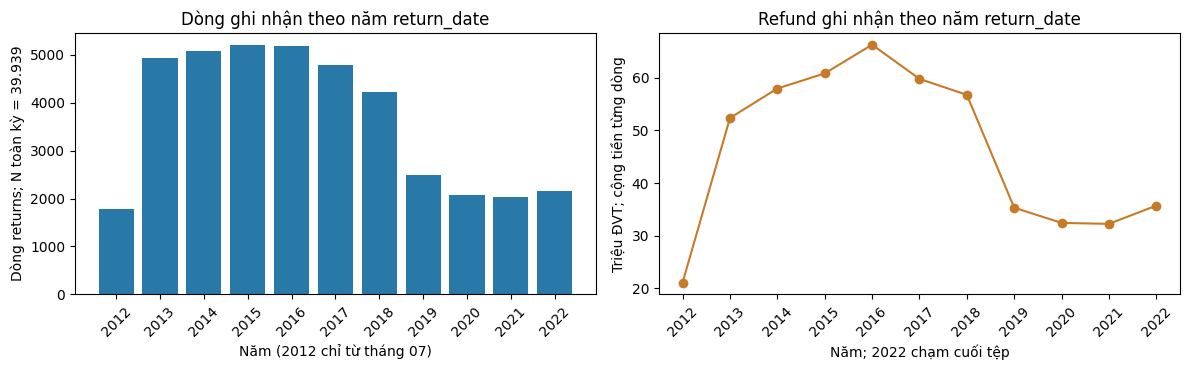

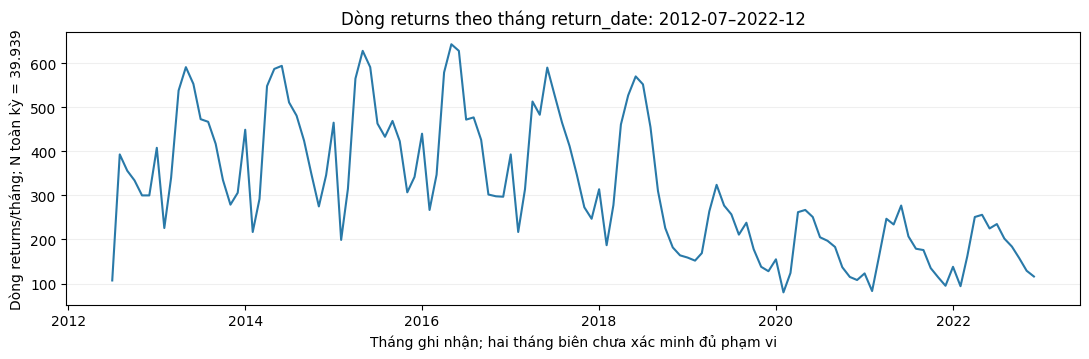

**Quan sát/bằng chứng:** năm 2015 nhiều dòng nhất (5.200); năm 2016 nhiều Refund nhất (66.237.094,66 ĐVT). 2022 ghi 2.150 dòng và 35.712.235,83 ĐVT; toàn kỳ có 126 tháng lịch. **Ý nghĩa:** số dòng và tổng tiền không nhất thiết đạt đỉnh cùng năm; biến động phải đọc cùng quy mô đặt và cơ cấu giá trị. **Giới hạn:** chưa chứng minh thời vụ hay thay đổi tiền thực chi; 2012 không so như một năm đủ lịch. **Câu hỏi tiếp:** thay đổi quy mô mua, cơ cấu hàng và độ phủ ghi nhận góp phần thế nào?

In [38]:
def return_summary044(key):
    out=line044.groupby(key,sort=True).agg(rows=("return_id","size"),orders=("order_id","nunique"),
        quantity=("quantity","sum"),refund=("refund","sum"))
    out["mean"]=[r/int(n) for r,n in zip(out.refund,out.rows)]
    out["median"]=line044.groupby(key)["refund"].apply(lambda s:q042(list(s),.5))
    out["share"]=[100*r/refund_total for r in out.refund]
    return out
return_year044=return_summary044("return_year")
return_month044=return_summary044("return_month")
return_labels044={"return_year":"Năm return_date","return_month":"Tháng return_date","rows":"Dòng returns (N)",
    "orders":"Đơn phân biệt trong kỳ","quantity":"Lượng trả ghi nhận","refund":"Refund (ĐVT)","mean":"Mean Refund/dòng (ĐVT)",
    "median":"Median Refund/dòng (ĐVT)","share":"% / tổng Refund toàn kỳ"}
year_display044=return_year044.reset_index().rename(columns=return_labels044)
year_display044["Phạm vi"]=np.where(year_display044["Năm return_date"].eq(2012),"Từ tháng 07; năm thiếu phạm vi",
    np.where(year_display044["Năm return_date"].eq(end_return044.year),"Chạm cuối tệp; chưa xác minh chốt dữ liệu","Trong phạm vi lịch quan sát"))
show044("Returns theo năm return_date — toàn kỳ; đơn có thể giao nhau giữa năm",year_display044,
    {c:lambda x:vn(x,2) for c in year_display044 if "(ĐVT)" in c or "%" in c})
assert list(return_month044.index)==[str(p) for p in pd.period_range(return_month044.index.min(),return_month044.index.max(),freq="M")]
prior_rows044=return_month044.rows.shift(1)
month_eligible044=pd.Series([0<i<len(return_month044)-1 for i in range(len(return_month044))],index=return_month044.index)
month_eligible044 &= prior_rows044.ge(30)&return_month044.rows.ge(30)
return_month044["mom_rows"]=[100*(int(n)-int(p))/int(p) if ok else None for n,p,ok in zip(return_month044.rows,prior_rows044,month_eligible044)]
prior_refund044=return_month044.refund.shift(1)
return_month044["mom_refund"]=[100*(r-p)/p if ok and p>0 else None for r,p,ok in zip(return_month044.refund,prior_refund044,month_eligible044)]
# Tháng sau tháng đầu cũng không so với tháng đầu thiếu phạm vi.
return_month044.loc[return_month044.index[1],["mom_rows","mom_refund"]]=None
valid_changes044=return_month044.loc[return_month044.mom_refund.notna()]
change_top044=valid_changes044.mom_refund.map(abs).sort_values(ascending=False,kind="stable").head(5).index
shown_months044=sorted(set(return_month044.tail(12).index)|set(change_top044))
month_display044=return_month044.loc[shown_months044,["rows","orders","refund","mean","mom_rows","mom_refund"]].reset_index().rename(columns={**return_labels044,"mom_rows":"% thay đổi dòng so tháng trước","mom_refund":"% thay đổi Refund so tháng trước"})
show044("Returns theo tháng return_date — 12 tháng cuối và 5 biến động Refund lớn nhất đủ điều kiện; mẫu số biến động là tháng trước",month_display044,
    {c:lambda x:vn(x,2) for c in month_display044 if "(ĐVT)" in c or "%" in c})
fig,axes=plt.subplots(1,2,figsize=(12,3.8))
axes[0].bar(return_year044.index,return_year044.rows,color="#2979a8")
axes[0].set(title="Dòng ghi nhận theo năm return_date",xlabel="Năm (2012 chỉ từ tháng 07)",ylabel="Dòng returns; N toàn kỳ = "+vn(len(line044)))
axes[1].plot(return_year044.index,[float(x)/1e6 for x in return_year044.refund],"o-",color="#c67b28")
axes[1].set(title="Refund ghi nhận theo năm return_date",xlabel="Năm; 2022 chạm cuối tệp",ylabel="Triệu ĐVT; cộng tiền từng dòng")
for ax in axes:ax.set_xticks(return_year044.index);ax.tick_params(axis="x",rotation=45)
plot_done(fig)
fig,ax=plt.subplots(figsize=(11,3.7))
ax.plot(pd.to_datetime(return_month044.index),return_month044.rows,color="#2979a8")
ax.set(title=f"Dòng returns theo tháng return_date: {return_month044.index.min()}–{return_month044.index.max()}",
    xlabel="Tháng ghi nhận; hai tháng biên chưa xác minh đủ phạm vi",ylabel=f"Dòng returns/tháng; N toàn kỳ = {vn(len(line044))}")
ax.grid(axis="y",alpha=.2);plot_done(fig)
peak_year044=int(return_year044.rows.idxmax());peak_money_year044=int(return_year044.refund.idxmax())
note(f"**Quan sát/bằng chứng:** năm {peak_year044} nhiều dòng nhất ({vn(return_year044.loc[peak_year044,'rows'])}); "
    f"năm {peak_money_year044} nhiều Refund nhất ({vn(return_year044.loc[peak_money_year044,'refund'],2)} ĐVT). "
    f"2022 ghi {vn(return_year044.loc[2022,'rows'])} dòng và {vn(return_year044.loc[2022,'refund'],2)} ĐVT; "
    f"toàn kỳ có {len(return_month044)} tháng lịch. **Ý nghĩa:** số dòng và tổng tiền không nhất thiết đạt đỉnh cùng năm; "
    "biến động phải đọc cùng quy mô đặt và cơ cấu giá trị. **Giới hạn:** chưa chứng minh thời vụ hay thay đổi tiền thực chi; "
    "2012 không so như một năm đủ lịch. **Câu hỏi tiếp:** thay đổi quy mô mua, cơ cấu hàng và độ phủ ghi nhận góp phần thế nào?")
assert return_year044.rows.sum()==return_month044.rows.sum()==len(returns)
assert sum(return_year044.refund,ZERO)==sum(return_month044.refund,ZERO)==refund_total

### NV04.4.3 – Tỷ lệ đơn có returns theo năm/tháng đặt hàng và đối chiếu hai trục

Cờ có returns và Refund đã tổng hợp một lần/đơn trước JOIN. Tỷ lệ dùng tất cả đơn đặt cùng kỳ làm mẫu số; Refund gắn năm/tháng **đặt**, bất kể dòng returns ghi ở kỳ nào. Bảng năm có thêm Net và tỷ số hai tổng. Bảng tháng trình bày 12 tháng cuối cùng với tháng có tỷ lệ lớn/nhỏ nhất (kèm mẫu số); toàn bộ các tháng được kiểm chứng trong bộ nhớ.

Đối chiếu hai trục bằng dòng và tiền theo cùng nhãn năm; chênh lệch có thể do ghi nhận ở kỳ sau. Không diễn giải sự khác nhau giữa số đơn phân biệt theo return_date và cohort order_date thành lỗi. Không cộng đơn phân biệt giữa kỳ return_date; hợp tập mã mới cho tổng toàn kỳ.

**Nhóm đơn theo năm order_date — tỷ lệ đơn đặt trong kỳ có bản ghi returns quan sát được**

Năm đặt,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn
2012,32051,1819,30232,"5,675","741.497.748,02","23.609.396,67","3,184","12.979,33",False
2013,76849,4323,72526,"5,625","1.570.165.168,70","51.996.488,43","3,312","12.027,87",False
2014,80645,4484,76161,"5,560","1.785.342.715,14","58.245.013,52","3,262","12.989,52",False
2015,82622,4621,78001,"5,593","1.792.009.966,56","60.567.497,04","3,380","13.107,01",False
2016,82247,4655,77592,"5,660","2.012.364.465,62","66.336.938,53","3,296","14.250,68",False
2017,76010,4247,71763,"5,587","1.815.546.633,98","59.012.186,53","3,250","13.895,03",False
2018,69510,3803,65707,"5,471","1.769.723.179,62","56.219.259,06","3,177","14.782,87",False
2019,41601,2300,39301,"5,529","1.081.589.581,19","35.130.741,54","3,248","15.274,24",False
2020,34881,1950,32931,"5,590","1.006.108.536,38","32.406.084,31","3,221","16.618,50",False
2021,34525,1918,32607,"5,555","991.214.173,72","32.453.585,40","3,274","16.920,53",False


**Nhóm đơn theo tháng order_date — 12 tháng cuối và cực trị tỷ lệ; mẫu số là mọi đơn đặt cùng tháng**

Tháng đặt,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Refund (ĐVT),Mẫu số dưới 100 đơn
2020-11,1563,108,1455,"6,910","1.842.135,19",False
2022-01,1719,100,1619,"5,817","1.669.121,20",False
2022-02,2182,111,2071,"5,087","2.219.769,57",False
2022-03,4231,223,4008,"5,271","3.842.043,00",False
2022-04,4489,246,4243,"5,480","4.094.854,08",False
2022-05,4076,218,3858,"5,348","3.941.123,44",False
2022-06,4068,212,3856,"5,211","3.731.900,98",False
2022-07,3122,212,2910,"6,791","4.143.248,45",False
2022-08,3274,184,3090,"5,620","3.440.427,76",False
2022-09,2643,165,2478,"6,243","2.966.236,91",False


**Hai trục thời gian theo năm — Refund của dòng ghi trong năm so với Refund gắn đơn đặt trong năm**

return_year,Dòng theo return_date,Đơn phân biệt theo return_date (có giao năm),Refund theo return_date (ĐVT),Mọi đơn theo order_date,Đơn có returns theo order_date,Refund theo order_date (ĐVT),Chênh Refund: return − order (ĐVT),Dòng returns gắn năm đặt
2012,1790,1564,"21.122.057,99",32051,1819,"23.609.396,67","-2.487.338,68",2115
2013,4933,4327,"52.335.590,49",76849,4323,"51.996.488,43","339.102,06",4944
2014,5073,4473,"57.928.041,21",80645,4484,"58.245.013,52","-316.972,31",5105
2015,5200,4657,"60.792.331,98",82622,4621,"60.567.497,04","224.834,94",5168
2016,5176,4684,"66.237.094,66",82247,4655,"66.336.938,53","-99.843,87",5153
2017,4782,4324,"59.752.530,03",76010,4247,"59.012.186,53","740.343,50",4698
2018,4226,3893,"56.725.369,68",69510,3803,"56.219.259,06","506.110,62",4122
2019,2495,2317,"35.316.106,33",41601,2300,"35.130.741,54","185.364,79",2484
2020,2084,1961,"32.430.506,37",34881,1950,"32.406.084,31","24.422,06",2069
2021,2030,1920,"32.246.641,98",34525,1918,"32.453.585,40","-206.943,42",2026


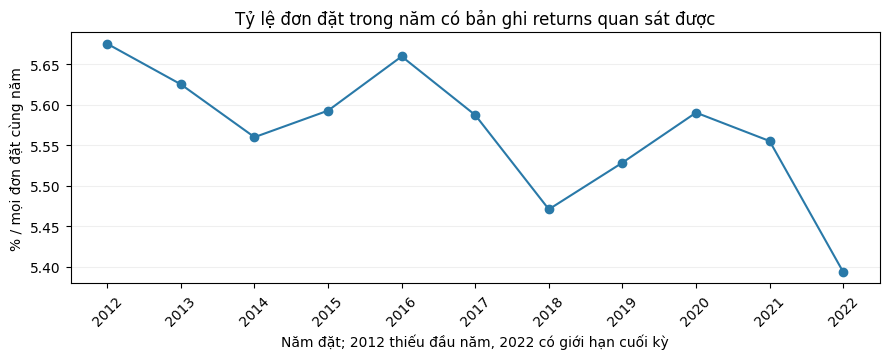

**Quan sát/bằng chứng:** tỷ lệ năm từ 5,394% đến 5,675%; tháng 12/2022 có 43/2.400 đơn (1,792%). Có 25.787 dòng khác tháng đặt và 2.340 dòng khác năm đặt; 677 đơn xuất hiện ở nhiều tháng returns, 88 đơn ở nhiều năm. **Ý nghĩa:** trục ghi nhận phục vụ khối lượng trong kỳ; trục đặt phục vụ tỷ lệ trên cohort đơn. **Giới hạn:** tỷ lệ thấp cuối kỳ chưa chứng minh chất lượng/quy trình tốt hơn hoặc xác suất cuối cùng thấp hơn. **Câu hỏi tiếp:** có metadata cập nhật và theo dõi sau cuối tệp để kiểm tra kết quả của các đơn gần mốc cuối không?

In [39]:
order_year044=summarize044(order044,"order_year")
order_month044=summarize044(order044,"order_month")
view044("Nhóm đơn theo năm order_date — tỷ lệ đơn đặt trong kỳ có bản ghi returns quan sát được",order_year044,group_cols044)
cohort_selected044=sorted(set(order_month044.tail(12).index)|{order_month044.rate.idxmin(),order_month044.rate.idxmax()})
view044("Nhóm đơn theo tháng order_date — 12 tháng cuối và cực trị tỷ lệ; mẫu số là mọi đơn đặt cùng tháng",order_month044.loc[cohort_selected044],["n","has","without","rate","refund","small"])
time_compare044=return_year044[["rows","orders","refund"]].join(order_year044[["n","has","refund"]],how="outer",lsuffix="_return",rsuffix="_order")
time_compare044["refund_delta"]=time_compare044.refund_return-time_compare044.refund_order
time_compare044["return_rows_by_order_year"]=line044.groupby("order_year").size()
show044("Hai trục thời gian theo năm — Refund của dòng ghi trong năm so với Refund gắn đơn đặt trong năm",time_compare044.reset_index().rename(columns={
    "index":"Năm","rows":"Dòng theo return_date","orders":"Đơn phân biệt theo return_date (có giao năm)",
    "refund_return":"Refund theo return_date (ĐVT)","n":"Mọi đơn theo order_date","has":"Đơn có returns theo order_date",
    "refund_order":"Refund theo order_date (ĐVT)","refund_delta":"Chênh Refund: return − order (ĐVT)",
    "return_rows_by_order_year":"Dòng returns gắn năm đặt"}),
    {c:lambda x:vn(x,2) for c in ["Refund theo return_date (ĐVT)","Refund theo order_date (ĐVT)","Chênh Refund: return − order (ĐVT)"]})
periods_per_order044=line044.groupby("order_id").agg(months=("return_month","nunique"),years=("return_year","nunique"))
cross_month_rows044=int(line044.return_month.ne(line044.order_month).sum())
cross_year_rows044=int(line044.return_year.ne(line044.order_year).sum())
fig,ax=plt.subplots(figsize=(9,3.7))
ax.plot(order_year044.index,order_year044.rate,"o-",color="#2979a8")
ax.set(title="Tỷ lệ đơn đặt trong năm có bản ghi returns quan sát được",xlabel="Năm đặt; 2012 thiếu đầu năm, 2022 có giới hạn cuối kỳ",
    ylabel="% / mọi đơn đặt cùng năm",xticks=order_year044.index)
ax.tick_params(axis="x",rotation=45);ax.grid(axis="y",alpha=.2);plot_done(fig)
note(f"**Quan sát/bằng chứng:** tỷ lệ năm từ {vn(order_year044.rate.min(),3)}% đến {vn(order_year044.rate.max(),3)}%; "
    f"tháng 12/2022 có {vn(order_month044.loc['2022-12','has'])}/{vn(order_month044.loc['2022-12','n'])} đơn "
    f"({vn(order_month044.loc['2022-12','rate'],3)}%). Có {vn(cross_month_rows044)} dòng khác tháng đặt và "
    f"{vn(cross_year_rows044)} dòng khác năm đặt; {vn(int(periods_per_order044.months.gt(1).sum()))} đơn xuất hiện ở nhiều tháng returns, "
    f"{vn(int(periods_per_order044.years.gt(1).sum()))} đơn ở nhiều năm. **Ý nghĩa:** trục ghi nhận phục vụ khối lượng trong kỳ; "
    "trục đặt phục vụ tỷ lệ trên cohort đơn. **Giới hạn:** tỷ lệ thấp cuối kỳ chưa chứng minh chất lượng/quy trình tốt hơn hoặc xác suất cuối cùng thấp hơn. "
    "**Câu hỏi tiếp:** có metadata cập nhật và theo dõi sau cuối tệp để kiểm tra kết quả của các đơn gần mốc cuối không?")
assert order_year044.n.sum()==order_month044.n.sum()==len(orders)
assert order_year044.has.sum()==order_month044.has.sum()==n_return_orders
assert sum(order_year044.refund,ZERO)==sum(order_month044.refund,ZERO)==refund_total

### NV04.4.4 – Cửa sổ quan sát cuối kỳ và khảo sát độ nhạy 31 ngày

Mốc tính ngày lịch là **ngày order_date lớn nhất trong tệp**, đối chiếu riêng với ngày return_date lớn nhất. Chưa có timestamp trích xuất được xác minh. Khoảng ngày tới mốc = mốc − order_date; điều kiện khảo sát là **ít nhất 31 ngày**, gồm đúng biên 31, không làm tròn. Ngưỡng 31 dựa trên lag lớn nhất quan sát, không phải chính sách trả hàng và không bảo đảm mọi kết quả đã được quan sát đầy đủ.

Giữ nguyên toàn bộ dữ liệu. Báo cáo song song toàn kỳ và tập thỏa điều kiện; tập sau chỉ là một lát cắt độ nhạy. Bảng ngày tập trung tháng đặt cuối cùng, bảng tuổi quan sát phủ toàn bộ đơn. Đếm riêng đơn trạng thái `returned` chưa có dòng returns và các ngày đặt của chúng.

**Phạm vi ngày thực có trong tệp — không đồng nhất với thời điểm trích xuất**

Nguồn ngày,Ngày đầu,Ngày cuối,Mẫu số,Đơn vị
orders.order_date,2012-07-04,2022-12-31,646945,Đơn
returns.return_date,2012-07-11,2022-12-31,39939,Dòng returns


**Phân bố số ngày lịch từ ngày đặt tới mốc cuối orders — toàn bộ đơn, các khoảng không chồng lấn**

Ngày lịch tới mốc cuối orders,Tổng đơn (mẫu số),Đơn có returns,Tỷ lệ đơn có returns quan sát (%),Đơn nhãn returned
0–4 ngày,595,0,"0,000",26
5–14 ngày,877,10,"1,140",47
15–30 ngày,928,33,"3,556",50
31–60 ngày,1703,96,"5,637",96
Từ 61 ngày,642842,35923,"5,588",35923


**Khảo sát độ nhạy — tỷ lệ và tiền ở toàn bộ đơn so với tập có ít nhất 31 ngày lịch**

Phạm vi độ nhạy,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn
Toàn bộ dữ liệu,646945,36062,610883,"5,574","15.680.869.265,43","510.598.506,55","3,256","14.158,91",False
Ít nhất 31 ngày lịch,644545,36019,608526,"5,588","15.638.780.105,62","510.063.738,27","3,262","14.160,96",False


**Theo ngày đặt trong tháng cuối 12/2022 — tỷ lệ dùng mọi đơn đặt cùng ngày**

Ngày đặt,Mẫu số đơn/ngày,Đơn có returns,Đơn nhãn returned,Returned chưa có returns,Ngày lịch tới mốc cuối,% có returns / đơn cùng ngày
2022-12-01 00:00:00,57,1,1,0,30,"1,754"
2022-12-02 00:00:00,27,0,0,0,29,"0,000"
2022-12-03 00:00:00,38,2,2,0,28,"5,263"
2022-12-04 00:00:00,34,1,1,0,27,"2,941"
2022-12-05 00:00:00,47,3,3,0,26,"6,383"
2022-12-06 00:00:00,61,1,3,2,25,"1,639"
2022-12-07 00:00:00,37,1,1,0,24,"2,703"
2022-12-08 00:00:00,39,3,3,0,23,"7,692"
2022-12-09 00:00:00,57,3,5,2,22,"5,263"
2022-12-10 00:00:00,61,5,6,1,21,"8,197"


**Đơn returned chưa có returns — phân bố ngày đặt của toàn bộ tập thiếu đối ứng**

Ngày đặt,Đơn returned chưa có returns
2022-12-06 00:00:00,2
2022-12-09 00:00:00,2
2022-12-10 00:00:00,1
2022-12-11 00:00:00,3
2022-12-12 00:00:00,2
2022-12-13 00:00:00,2
2022-12-14 00:00:00,2
2022-12-15 00:00:00,1
2022-12-16 00:00:00,2
2022-12-17 00:00:00,1


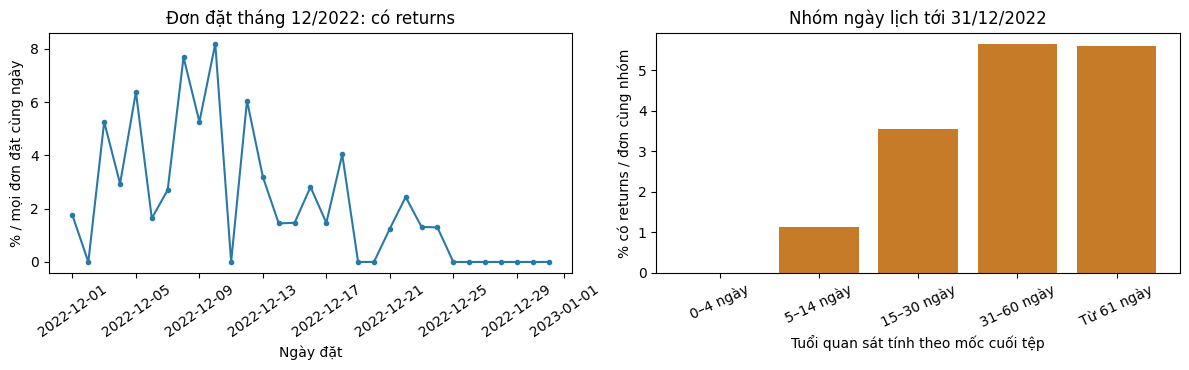

**Quan sát/bằng chứng:** hai mốc cuối là 31/12/2022 và 31/12/2022; 80 đơn returned thiếu returns, đặt từ 06/12/2022 đến 31/12/2022. Tuổi quan sát toàn kỳ min/median/max 0/2.350/3.832 ngày. Toàn bộ: 5,5742%; tập ít nhất 31 ngày: 36.019/644.545 (5,5883%). **Ý nghĩa:** kết quả nhạy với phạm vi ngày đặt, phù hợp với việc cần kiểm tra độ phủ cuối kỳ. **Giới hạn:** chưa xác minh cơ chế cắt/cập nhật, không suy 31 ngày là chính sách hoặc đủ theo dõi. **Câu hỏi tiếp:** dữ liệu bổ sung sau mốc cuối và lịch sử cập nhật có làm thay đổi các cờ và tỷ lệ này không?

In [40]:
date_ends044=pd.DataFrame([{"Nguồn ngày":"orders.order_date","Ngày đầu":str(order044.order_day.min().date()),"Ngày cuối":str(end_order044.date()),"Mẫu số":len(order044),"Đơn vị":"Đơn"},
    {"Nguồn ngày":"returns.return_date","Ngày đầu":str(line044.return_day.min().date()),"Ngày cuối":str(end_return044.date()),"Mẫu số":len(line044),"Đơn vị":"Dòng returns"}])
show044("Phạm vi ngày thực có trong tệp — không đồng nhất với thời điểm trích xuất",date_ends044)
age044=summarize044(order044,"age_band").reindex(age_labels044)
view044("Phân bố số ngày lịch từ ngày đặt tới mốc cuối orders — toàn bộ đơn, các khoảng không chồng lấn",age044,["n","has","rate","returned"])
eligible044=order044.loc[order044.eligible31].copy()
scope044=pd.concat([summarize044(order044.assign(scope="Toàn bộ dữ liệu"),"scope"),
    summarize044(eligible044.assign(scope="Ít nhất 31 ngày lịch"),"scope")])
scope044.index.name="Phạm vi độ nhạy"
view044("Khảo sát độ nhạy — tỷ lệ và tiền ở toàn bộ đơn so với tập có ít nhất 31 ngày lịch",scope044,group_cols044)
tail044=order044.loc[order044.order_month.eq(end_order044.strftime("%Y-%m"))].copy()
tail044["missing_returned"]=tail044.status_returned & ~tail044.has_return
tail_daily044=tail044.groupby("order_day").agg(n=("order_id","size"),has=("has_return","sum"),returned=("status_returned","sum"),
    missing=("missing_returned","sum"),days=("calendar_days_to_end","first"))
tail_daily044["rate"]=100*tail_daily044.has/tail_daily044.n
show044(f"Theo ngày đặt trong tháng cuối {end_order044:%m/%Y} — tỷ lệ dùng mọi đơn đặt cùng ngày",tail_daily044.reset_index().rename(columns={
    "order_day":"Ngày đặt","n":"Mẫu số đơn/ngày","has":"Đơn có returns","returned":"Đơn nhãn returned",
    "missing":"Returned chưa có returns","days":"Ngày lịch tới mốc cuối","rate":"% có returns / đơn cùng ngày"}),
    {"% có returns / đơn cùng ngày":lambda x:vn(x,3)})
missing_returned044=order044.loc[order044.status_returned & ~order044.has_return].copy()
missing_days044=missing_returned044.groupby("order_day").size()
show044("Đơn returned chưa có returns — phân bố ngày đặt của toàn bộ tập thiếu đối ứng",missing_days044.rename_axis("Ngày đặt").reset_index(name="Đơn returned chưa có returns"))
age_stats044=order044.calendar_days_to_end.describe(percentiles=[.25,.5,.75,.9,.95])
fig,axes=plt.subplots(1,2,figsize=(12,3.8))
axes[0].plot(tail_daily044.index,tail_daily044.rate,"o-",markersize=3,color="#2979a8")
axes[0].set(title=f"Đơn đặt tháng {end_order044:%m/%Y}: có returns",xlabel="Ngày đặt",ylabel="% / mọi đơn đặt cùng ngày")
axes[0].tick_params(axis="x",rotation=35)
axes[1].bar(age044.index,age044.rate,color="#c67b28")
axes[1].set(title=f"Nhóm ngày lịch tới {end_order044:%d/%m/%Y}",xlabel="Tuổi quan sát tính theo mốc cuối tệp",ylabel="% có returns / đơn cùng nhóm")
axes[1].tick_params(axis="x",rotation=25);plot_done(fig)
note(f"**Quan sát/bằng chứng:** hai mốc cuối là {end_order044:%d/%m/%Y} và {end_return044:%d/%m/%Y}; "
    f"{vn(len(missing_returned044))} đơn returned thiếu returns, đặt từ {missing_returned044.order_day.min():%d/%m/%Y} "
    f"đến {missing_returned044.order_day.max():%d/%m/%Y}. Tuổi quan sát toàn kỳ min/median/max "
    f"{vn(age_stats044['min'])}/{vn(age_stats044['50%'])}/{vn(age_stats044['max'])} ngày. "
    f"Toàn bộ: {vn(pct(n_return_orders,len(order044)),4)}%; tập ít nhất 31 ngày: "
    f"{vn(int(eligible044.has_return.sum()))}/{vn(len(eligible044))} ({vn(pct(int(eligible044.has_return.sum()),len(eligible044)),4)}%). "
    "**Ý nghĩa:** kết quả nhạy với phạm vi ngày đặt, phù hợp với việc cần kiểm tra độ phủ cuối kỳ. "
    "**Giới hạn:** chưa xác minh cơ chế cắt/cập nhật, không suy 31 ngày là chính sách hoặc đủ theo dõi. "
    "**Câu hỏi tiếp:** dữ liệu bổ sung sau mốc cuối và lịch sử cập nhật có làm thay đổi các cờ và tỷ lệ này không?")
assert set(missing_returned044.order_id)==set_B and len(missing_returned044)==80
assert eligible044.calendar_days_to_end.ge(31).all() and len(eligible044)+int(order044.recent.sum())==len(order044)

### NV04.4.5 – Khoảng ngày lịch từ đặt đến returns ghi nhận

`RecordedReturnLagDays = return_date − order_date` dùng ngày lịch, đúng thứ tự. Cấp dòng giữ mọi return_date; cấp đơn dùng **ngày returns nhỏ nhất** làm mốc đầu tiên, được nêu rõ thay vì chọn một ngày tùy ý. Đơn không có returns không được điền lag bằng 0.

Báo cáo toàn kỳ và theo năm **đặt** ở cả hai cấp: N, min/max, mean/median, P25/P75/P90/P95, nội suy tuyến tính `(N−1)×p`. Bảng phân bố toàn kỳ đếm riêng dòng và đơn tới lần ghi nhận đầu tiên. Đây không phải thời gian xử lý yêu cầu, thời gian giao chậm hay thời gian quyết toán hoàn tiền; mẫu chỉ gồm các cặp ngày đã quan sát.

In [41]:
def lag_stats044(values):
    vals=[int(v) for v in values]
    return {"N":len(vals),"Min (ngày)":min(vals),"Max (ngày)":max(vals),"Mean (ngày)":statistics.mean(vals),
        "Median (ngày)":statistics.median(vals),**{f"P{p} (ngày)":float(q042([Decimal(v) for v in vals],p/100)) for p in [25,75,90,95]}}
lag_records044=[]
for level,frame,col in [("Dòng returns",line044,"lag_days"),("Đơn: return đầu tiên",order044.loc[order044.has_return],"first_lag")]:
    lag_records044.append({"Cấp":level,"Nhóm năm đặt":"Toàn kỳ",**lag_stats044(frame[col])})
    for year,part in frame.groupby("order_year"):
        lag_records044.append({"Cấp":level,"Nhóm năm đặt":str(year),**lag_stats044(part[col])})
lag_statistics044=pd.DataFrame(lag_records044)
show044("Lag ghi nhận theo cấp quan sát và năm order_date — N là số cặp ngày hợp lệ ở đúng cấp",lag_statistics044,
    {c:lambda x:vn(x,3) for c in lag_statistics044 if "(ngày)" in c})
lag_row_counts044=Counter(map(int,line044.lag_days));lag_first_counts044=Counter(map(int,order044.loc[order044.has_return,"first_lag"]))
lag_distribution044=pd.DataFrame([{"Khoảng ngày lịch":d,"Dòng returns":lag_row_counts044[d],"Mẫu số dòng":len(line044),
    "% / dòng returns":pct(lag_row_counts044[d],len(line044)),"Đơn tới return đầu tiên":lag_first_counts044[d],
    "Mẫu số đơn có returns":n_return_orders,"% / đơn có returns":pct(lag_first_counts044[d],n_return_orders)}
    for d in sorted(set(lag_row_counts044)|set(lag_first_counts044))])
show044("Phân bố lag toàn kỳ — phân biệt dòng và đơn tới return đầu tiên",lag_distribution044,
    {"% / dòng returns":lambda x:vn(x,3),"% / đơn có returns":lambda x:vn(x,3)})
lag_bad044={"Dòng thiếu/sai cặp ngày":int(line044.lag_days.isna().sum()),"Dòng âm":int(line044.lag_days.lt(0).sum()),
    "Dòng bằng 0":int(line044.lag_days.eq(0).sum()),"Đơn có returns thiếu ngày đầu":int(order044.loc[order044.has_return,"first_lag"].isna().sum())}
note(f"**Quan sát/bằng chứng:** {lag_bad044}; lag dòng {int(line044.lag_days.min())}–{int(line044.lag_days.max())} ngày, "
    f"mean/median {vn(line044.lag_days.mean(),3)}/{vn(line044.lag_days.median())}; mean tới return đầu tiên "
    f"{vn(order044.loc[order044.has_return,'first_lag'].mean(),3)} ngày. "
    "**Ý nghĩa:** tách khối lượng bản ghi khỏi thời điểm ghi nhận đầu tiên của mỗi đơn; đối chiếu theo cùng năm đặt. "
    "**Giới hạn:** cuối kỳ chỉ thấy các returns đã có trong tệp, nên phân bố lag có thể chịu lựa chọn; nhãn late_delivery chưa xác nhận giao trễ. "
    "**Câu hỏi tiếp:** có ngày yêu cầu, nhận hàng và quyết toán để đo đúng các giai đoạn xử lý không?")
assert not any(lag_bad044.values())
assert sum(lag_row_counts044.values())==len(returns) and sum(lag_first_counts044.values())==n_return_orders

**Lag ghi nhận theo cấp quan sát và năm order_date — N là số cặp ngày hợp lệ ở đúng cấp**

Cấp,Nhóm năm đặt,N,Min (ngày),Max (ngày),Mean (ngày),Median (ngày),P25 (ngày),P75 (ngày),P90 (ngày),P95 (ngày)
Dòng returns,Toàn kỳ,39939,"5,000","31,000","17,966","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2012,2115,"5,000","31,000","18,001","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2013,4944,"5,000","31,000","17,809","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2014,5105,"5,000","31,000","17,859","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2015,5168,"5,000","31,000","18,119","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2016,5153,"5,000","31,000","18,014","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2017,4698,"5,000","31,000","18,017","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2018,4122,"5,000","31,000","17,970","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2019,2484,"5,000","31,000","18,064","18,000","13,000","23,000","26,000","27,000"
Dòng returns,2020,2069,"5,000","31,000","17,913","18,000","13,000","23,000","26,000","27,000"


**Phân bố lag toàn kỳ — phân biệt dòng và đơn tới return đầu tiên**

Khoảng ngày lịch,Dòng returns,Mẫu số dòng,% / dòng returns,Đơn tới return đầu tiên,Mẫu số đơn có returns,% / đơn có returns
5,68,39939,"0,170",68,36062,"0,189"
6,289,39939,"0,724",287,36062,"0,796"
7,523,39939,"1,309",513,36062,"1,423"
8,868,39939,"2,173",853,36062,"2,365"
9,1274,39939,"3,190",1252,36062,"3,472"
10,1602,39939,"4,011",1557,36062,"4,318"
11,1884,39939,"4,717",1828,36062,"5,069"
12,2040,39939,"5,108",1967,36062,"5,454"
13,2081,39939,"5,210",1986,36062,"5,507"
14,2080,39939,"5,208",1969,36062,"5,460"


**Quan sát/bằng chứng:** {'Dòng thiếu/sai cặp ngày': 0, 'Dòng âm': 0, 'Dòng bằng 0': 0, 'Đơn có returns thiếu ngày đầu': 0}; lag dòng 5–31 ngày, mean/median 17,966/18; mean tới return đầu tiên 17,616 ngày. **Ý nghĩa:** tách khối lượng bản ghi khỏi thời điểm ghi nhận đầu tiên của mỗi đơn; đối chiếu theo cùng năm đặt. **Giới hạn:** cuối kỳ chỉ thấy các returns đã có trong tệp, nên phân bố lag có thể chịu lựa chọn; nhãn late_delivery chưa xác nhận giao trễ. **Câu hỏi tiếp:** có ngày yêu cầu, nhận hàng và quyết toán để đo đúng các giai đoạn xử lý không?

### NV04.4.6 – Phương thức thanh toán và COD/non-COD

Dùng `orders.payment_method`; đã kiểm tra khớp nhãn trong payments theo order_id. COD = nhãn `cod`, non-COD = mọi phương thức nguồn còn lại, chưa đồng nghĩa trả trước hay đã thanh toán. Tỷ lệ có returns dùng mọi đơn của nhóm, phân biệt với tỷ trọng nhãn `returned` từng mô tả ở NV03.

Bảng phương thức có số đơn, có/không returns, Net, Refund, tỷ số hai tổng, Refund/đơn có returns và lag đầu tiên. So COD/non-COD toàn kỳ và từng năm đặt, nêu cả số đơn và tỷ trọng năm trong mỗi nhóm; chênh tính bằng điểm phần trăm. Không suy COD gây ra hoàn trả.

**Phương thức thanh toán — toàn kỳ theo order_date; tỷ lệ dùng mọi đơn trong phương thức**

Phương thức nguồn,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn,Mean ngày tới return đầu tiên (ngày)
apple_pay,64763,3256,61507,"5,028","1.564.269.610,50","46.516.773,44","2,974","14.286,48",False,"17,844"
bank_transfer,32131,1599,30532,"4,977","775.902.511,08","22.950.393,53","2,958","14.352,97",False,"17,771"
cod,96681,8607,88074,"8,902","2.346.947.592,93","121.469.953,66","5,176","14.112,93",False,"17,490"
credit_card,356352,17766,338586,"4,986","8.630.069.413,19","251.417.957,14","2,913","14.151,64",False,"17,622"
paypal,97018,4834,92184,"4,983","2.363.680.137,73","68.243.428,78","2,887","14.117,38",False,"17,609"


**COD/non-COD — toàn kỳ; đối chiếu cờ returns với nhãn returned**

Nhóm phương thức,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn,Đơn nhãn returned,% nhãn returned / tổng đơn,Mean ngày tới return đầu tiên (ngày)
COD,96681,8607,88074,"8,902","2.346.947.592,93","121.469.953,66","5,176","14.112,93",False,8620,"8,916","17,490"
non-COD,550264,27455,522809,"4,989","13.333.921.672,50","389.128.552,89","2,918","14.173,32",False,27522,"5,002","17,655"


**COD/non-COD từng năm order_date — tỷ lệ trong nhóm/năm và cơ cấu năm trong mỗi nhóm**

Năm đặt,N COD,COD có returns,% có returns COD,N non-COD,non-COD có returns,% có returns non-COD,Δ COD − non-COD (đpt),% năm / mọi đơn COD,% năm / mọi đơn non-COD,Mẫu đủ ≥100/nhóm
2012,4740,444,"9,367",27311,1375,"5,035","4,332","4,903","4,963",True
2013,11494,1019,"8,865",65355,3304,"5,055","3,810","11,889","11,877",True
2014,11976,1039,"8,676",68669,3445,"5,017","3,659","12,387","12,479",True
2015,12411,1138,"9,169",70211,3483,"4,961","4,209","12,837","12,760",True
2016,12197,1122,"9,199",70050,3533,"5,044","4,155","12,616","12,730",True
2017,11320,1017,"8,984",64690,3230,"4,993","3,991","11,709","11,756",True
2018,10527,896,"8,511",58983,2907,"4,929","3,583","10,888","10,719",True
2019,6250,548,"8,768",35351,1752,"4,956","3,812","6,465","6,424",True
2020,5164,472,"9,140",29717,1478,"4,974","4,167","5,341","5,400",True
2021,5226,455,"8,706",29299,1463,"4,993","3,713","5,405","5,325",True


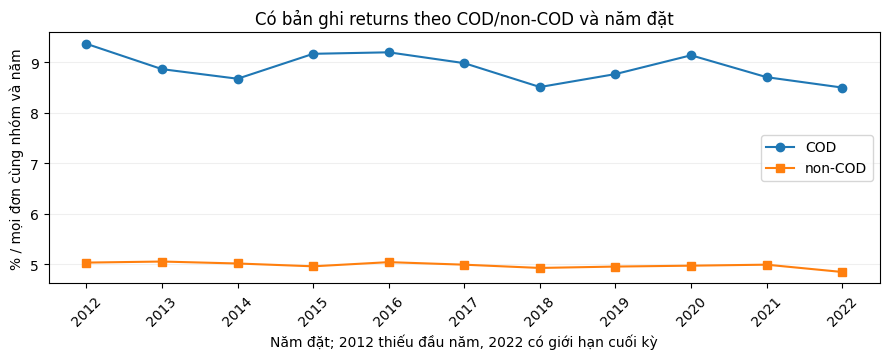

**Quan sát/bằng chứng:** COD 8.607/96.681 (8,902%); non-COD 27.455/550.264 (4,989%), chênh 3,913 đpt; cùng dấu dương ở 11/11 năm. Nhãn returned nhiều hơn cờ returns 13 đơn COD và 67 đơn non-COD; bảng NV03 đã lưu được đối chiếu riêng. **Ý nghĩa:** khác biệt mô tả vẫn xuất hiện khi dùng returns thay nhãn trạng thái. **Giới hạn:** chưa kiểm soát cơ cấu khách, giá trị đơn, địa bàn và cửa sổ theo dõi. **Câu hỏi tiếp:** dấu chênh có giữ khi xét cùng cơ cấu năm và bỏ riêng đơn gần cuối kỳ khỏi phép so sánh độ nhạy không?

In [42]:
method044=summarize044(order044,"payment_method")
cod044=summarize044(order044,"cod_group")
cod_year044=summarize044(order044,["order_year","cod_group"])
view044("Phương thức thanh toán — toàn kỳ theo order_date; tỷ lệ dùng mọi đơn trong phương thức",method044,group_cols044+["first_lag_mean"])
view044("COD/non-COD — toàn kỳ; đối chiếu cờ returns với nhãn returned",cod044,group_cols044+["returned","returned_pct","first_lag_mean"])
cod_year_rows044=[]
for year in sorted(order044.order_year.unique()):
    a=cod_year044.loc[(year,"COD")];b=cod_year044.loc[(year,"non-COD")]
    cod_year_rows044.append({"Năm đặt":int(year),"N COD":int(a.n),"COD có returns":int(a.has),"% có returns COD":a.rate,
        "N non-COD":int(b.n),"non-COD có returns":int(b.has),"% có returns non-COD":b.rate,
        "Δ COD − non-COD (đpt)":a.rate-b.rate,"% năm / mọi đơn COD":pct(int(a.n),int(cod044.loc['COD','n'])),
        "% năm / mọi đơn non-COD":pct(int(b.n),int(cod044.loc['non-COD','n'])),"Mẫu đủ ≥100/nhóm":min(a.n,b.n)>=min_group044})
cod_year_table044=pd.DataFrame(cod_year_rows044)
show044("COD/non-COD từng năm order_date — tỷ lệ trong nhóm/năm và cơ cấu năm trong mỗi nhóm",cod_year_table044,
    {c:lambda x:vn(x,3) for c in cod_year_table044 if "%" in c or "đpt" in c})
fig,ax=plt.subplots(figsize=(9,3.7))
for group,style in [("COD","o-"),("non-COD","s-")]:
    block=cod_year044.xs(group,level="cod_group")
    ax.plot(block.index,block.rate,style,label=group)
ax.set(title="Có bản ghi returns theo COD/non-COD và năm đặt",xlabel="Năm đặt; 2012 thiếu đầu năm, 2022 có giới hạn cuối kỳ",
    ylabel="% / mọi đơn cùng nhóm và năm",xticks=sorted(order044.order_year.unique()))
ax.tick_params(axis="x",rotation=45);ax.grid(axis="y",alpha=.2);ax.legend();plot_done(fig)
cod_gap044=cod044.loc["COD","rate"]-cod044.loc["non-COD","rate"]
cod_sign_years044=int(cod_year_table044["Δ COD − non-COD (đpt)"].gt(0).sum())
nv03_cod_expected044={}
class CodTable044(HTMLParser):
    def __init__(self):super().__init__();self.rows=[];self.row=[];self.buffer=[];self.in_td=False
    def handle_starttag(self,tag,attrs):
        if tag=="tr":self.row=[]
        if tag=="td":self.buffer=[];self.in_td=True
    def handle_data(self,data):
        if self.in_td:self.buffer.append(data)
    def handle_endtag(self,tag):
        if tag=="td":self.row.append("".join(self.buffer).strip());self.in_td=False
        if tag=="tr" and self.row:self.rows.append(self.row)
for cell in nv03["cells"]:
    for output in cell.get("outputs",[]):
        html=output.get("data",{}).get("text/html","");html="".join(html) if isinstance(html,list) else html
        if all(text in html for text in ["N đơn nhóm","Returned — đơn (%)","non-COD"]):
            parser=CodTable044();parser.feed(html)
            for row in parser.rows:
                if row[0]=="Toàn kỳ":nv03_cod_expected044[row[1]]=(int(row[2].replace(".","")),int(row[4].split(" (")[0].replace(".","")))
assert set(nv03_cod_expected044)=={"COD","non-COD"}
note(f"**Quan sát/bằng chứng:** COD {vn(int(cod044.loc['COD','has']))}/{vn(int(cod044.loc['COD','n']))} "
    f"({vn(cod044.loc['COD','rate'],3)}%); non-COD {vn(int(cod044.loc['non-COD','has']))}/{vn(int(cod044.loc['non-COD','n']))} "
    f"({vn(cod044.loc['non-COD','rate'],3)}%), chênh {vn(cod_gap044,3)} đpt; cùng dấu dương ở {cod_sign_years044}/{len(cod_year_table044)} năm. "
    f"Nhãn returned nhiều hơn cờ returns {int(cod044.loc['COD','returned']-cod044.loc['COD','has'])} đơn COD và "
    f"{int(cod044.loc['non-COD','returned']-cod044.loc['non-COD','has'])} đơn non-COD; bảng NV03 đã lưu được đối chiếu riêng. "
    "**Ý nghĩa:** khác biệt mô tả vẫn xuất hiện khi dùng returns thay nhãn trạng thái. "
    "**Giới hạn:** chưa kiểm soát cơ cấu khách, giá trị đơn, địa bàn và cửa sổ theo dõi. "
    "**Câu hỏi tiếp:** dấu chênh có giữ khi xét cùng cơ cấu năm và bỏ riêng đơn gần cuối kỳ khỏi phép so sánh độ nhạy không?")
assert all((int(cod044.loc[group,"n"]),int(cod044.loc[group,"returned"]))==values for group,values in nv03_cod_expected044.items())

### NV04.4.7 – Thiết bị đặt hàng

Thiết bị lấy từ `orders.device_type`, không được diễn giải thành thiết bị sở hữu của khách. So sánh theo nhóm đơn: hiển thị N, tử số có returns, tiền và tỷ số hai tổng. Chênh lớn nhất giữa các nhóm là điểm phần trăm trên các mẫu số riêng, chưa là ảnh hưởng của thiết bị. Không thêm khảo sát sản phẩm/lý do đã thực hiện ở NV04.3.

In [43]:
device044=summarize044(order044,"device_type")
view044("Thiết bị nguồn của đơn — toàn kỳ theo order_date; mẫu số là mọi đơn của thiết bị",device044,group_cols044)
device_high044=device044.rate.idxmax();device_low044=device044.rate.idxmin()
device_gap044=device044.rate.max()-device044.rate.min()
note(f"**Quan sát/bằng chứng:** nhóm cao nhất {device_high044}: {vn(int(device044.loc[device_high044,'has']))}/"
    f"{vn(int(device044.loc[device_high044,'n']))} ({vn(device044.loc[device_high044,'rate'],3)}%); thấp nhất {device_low044}: "
    f"{vn(int(device044.loc[device_low044,'has']))}/{vn(int(device044.loc[device_low044,'n']))} "
    f"({vn(device044.loc[device_low044,'rate'],3)}%), chênh {vn(device_gap044,3)} đpt. "
    "**Ý nghĩa:** số đơn có returns tuyệt đối và tỷ lệ nhóm cần được đọc riêng. "
    "**Giới hạn:** khác biệt nhỏ chưa được kiểm định hoặc điều chỉnh cơ cấu; không suy mobile/desktop/tablet gây ra hoàn trả. "
    "**Câu hỏi tiếp:** nhãn thiết bị được ghi ở bước nào và cơ cấu đơn/khách giữa các thiết bị có khác nhau không?")
assert device044.n.sum()==len(order044) and device044.has.sum()==n_return_orders

**Thiết bị nguồn của đơn — toàn kỳ theo order_date; mẫu số là mọi đơn của thiết bị**

Thiết bị nguồn,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn
desktop,258855,14505,244350,"5,604","6.265.041.337,58","206.022.886,67","3,288","14.203,58",False
mobile,291482,16303,275179,"5,593","7.066.788.763,16","229.447.396,59","3,247","14.073,94",False
tablet,96608,5254,91354,"5,438","2.349.039.164,69","75.128.223,29","3,198","14.299,24",False


**Quan sát/bằng chứng:** nhóm cao nhất desktop: 14.505/258.855 (5,604%); thấp nhất tablet: 5.254/96.608 (5,438%), chênh 0,165 đpt. **Ý nghĩa:** số đơn có returns tuyệt đối và tỷ lệ nhóm cần được đọc riêng. **Giới hạn:** khác biệt nhỏ chưa được kiểm định hoặc điều chỉnh cơ cấu; không suy mobile/desktop/tablet gây ra hoàn trả. **Câu hỏi tiếp:** nhãn thiết bị được ghi ở bước nào và cơ cấu đơn/khách giữa các thiết bị có khác nhau không?

### NV04.4.8 – Địa bàn của đơn theo orders.zip

Khóa `geography.zip` đã kiểm tra duy nhất và mọi ZIP đơn có đối ứng. Mỗi đơn nhận đúng một city/region từ orders.zip; không thay bằng ZIP khách. Thành phố được định danh bằng cặp `(region, city)` để tránh gộp nhãn trùng nếu có. East/Central/West là nhãn nguồn, chưa xác minh là phân vùng hành chính chính thức.

Bảng region phủ toàn bộ đơn. Hai top city độc lập: theo số đơn có returns và theo tỷ lệ, chỉ xếp hạng nhóm có ít nhất 1.000 đơn toàn kỳ; đây là ngưỡng quy mô mô tả, không chứng minh đủ lực thống kê. Công bố số nhóm bị loại khỏi top và mẫu số, vẫn giữ chúng trong tổng và dữ liệu.

In [44]:
region044=summarize044(order044,"region")
city044=summarize044(order044,["region","city"])
city_min044=1000
city_eligible044=city044.loc[city044.n.ge(city_min044)]
top_city_parts044=[]
for col,label in [("has","Top số đơn có returns"),("rate","Top tỷ lệ có returns")]:
    part=city_eligible044.reset_index().sort_values([col,"region","city"],ascending=[False,True,True]).head(5)
    part.insert(0,"Tiêu chí",label);part.insert(1,"Hạng",range(1,len(part)+1));top_city_parts044.append(part)
top_city044=pd.concat(top_city_parts044,ignore_index=True)
view044("Region nguồn — toàn kỳ theo địa bàn của đơn; mẫu số là mọi đơn trong region",region044,group_cols044)
top_city_display044=top_city044[["Tiêu chí","Hạng","region","city"]+group_cols044].rename(columns=labels044)
show044(f"Hai top city độc lập — toàn kỳ, chỉ nhóm có ít nhất {vn(city_min044)} đơn; không cộng lại hai top",top_city_display044,
    {**{c:lambda x:vn(x,2) for c in top_city_display044 if "(ĐVT)" in c},
     **{c:lambda x:vn(x,3) for c in top_city_display044 if "%" in c}})
region_high044=region044.rate.idxmax();region_low044=region044.rate.idxmin()
region_gap044=region044.rate.max()-region044.rate.min()
note(f"**Quan sát/bằng chứng:** {region_high044} cao nhất ({vn(int(region044.loc[region_high044,'has']))}/"
    f"{vn(int(region044.loc[region_high044,'n']))}, {vn(region044.loc[region_high044,'rate'],3)}%); "
    f"{region_low044} thấp nhất ({vn(region044.loc[region_low044,'rate'],3)}%), chênh {vn(region_gap044,3)} đpt. "
    f"Có {len(city044)} cặp region–city; {len(city044)-len(city_eligible044)} nhóm không đạt ngưỡng {city_min044} đơn để vào top. "
    f"Top số đơn dẫn đầu {top_city_parts044[0].iloc[0]['city']}; top tỷ lệ dẫn đầu {top_city_parts044[1].iloc[0]['city']}. "
    "**Ý nghĩa:** quy mô tuyệt đối và mức tương đối cho thứ hạng khác nhau. "
    "**Giới hạn:** chưa có bằng chứng về hạ tầng, thu nhập hoặc chất lượng dịch vụ để giải thích chênh lệch. "
    "**Câu hỏi tiếp:** chênh region có ổn định theo năm và khi khảo sát riêng đơn xa mốc cuối tệp không?")
assert region044.n.sum()==city044.n.sum()==len(order044)
assert sum(region044.refund,ZERO)==sum(city044.refund,ZERO)==refund_total

**Region nguồn — toàn kỳ theo địa bàn của đơn; mẫu số là mọi đơn trong region**

Region nguồn,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn
Central,184691,10260,174431,"5,555","4.719.491.267,84","151.387.098,38","3,208","14.755,08",False
East,294612,16307,278305,"5,535","7.291.150.819,12","235.481.747,98","3,230","14.440,53",False
West,167642,9495,158147,"5,664","3.670.227.178,47","123.729.660,19","3,371","13.031,03",False


**Hai top city độc lập — toàn kỳ, chỉ nhóm có ít nhất 1.000 đơn; không cộng lại hai top**

Tiêu chí,Hạng,Region nguồn,City nguồn,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn
Top số đơn có returns,1,East,Son Tay,22473,1252,21221,"5,571","554.795.175,01","17.357.018,77","3,129","13.863,43",False
Top số đơn có returns,2,East,Thai Nguyen,21931,1245,20686,"5,677","539.929.108,57","18.232.432,33","3,377","14.644,52",False
Top số đơn có returns,3,East,Nam Dinh,21764,1202,20562,"5,523","546.781.717,28","16.754.684,78","3,064","13.939,01",False
Top số đơn có returns,4,East,Viet Tri,20889,1192,19697,"5,706","520.904.352,05","16.399.680,07","3,148","13.758,12",False
Top số đơn có returns,5,East,Bac Giang,20848,1185,19663,"5,684","510.589.604,56","16.756.543,76","3,282","14.140,54",False
Top tỷ lệ có returns,1,West,Ca Mau,9800,592,9208,"6,041","211.695.134,18","7.561.951,77","3,572","12.773,57",False
Top tỷ lệ có returns,2,West,Tra Vinh,10113,597,9516,"5,903","221.948.139,41","7.416.405,90","3,342","12.422,79",False
Top tỷ lệ có returns,3,West,Rach Gia,8692,513,8179,"5,902","188.389.628,03","6.728.514,46","3,572","13.116,01",False
Top tỷ lệ có returns,4,West,Ben Tre,10877,639,10238,"5,875","233.873.145,49","8.767.486,22","3,749","13.720,64",False
Top tỷ lệ có returns,5,Central,Phan Rang-Thap Cham,15455,887,14568,"5,739","393.181.569,26","13.196.686,39","3,356","14.877,89",False


**Quan sát/bằng chứng:** West cao nhất (9.495/167.642, 5,664%); East thấp nhất (5,535%), chênh 0,129 đpt. Có 42 cặp region–city; 0 nhóm không đạt ngưỡng 1000 đơn để vào top. Top số đơn dẫn đầu Son Tay; top tỷ lệ dẫn đầu Ca Mau. **Ý nghĩa:** quy mô tuyệt đối và mức tương đối cho thứ hạng khác nhau. **Giới hạn:** chưa có bằng chứng về hạ tầng, thu nhập hoặc chất lượng dịch vụ để giải thích chênh lệch. **Câu hỏi tiếp:** chênh region có ổn định theo năm và khi khảo sát riêng đơn xa mốc cuối tệp không?

### NV04.4.9 – Acquisition channel của khách hàng

Liên kết `orders.customer_id → customers.customer_id` nhiều–một đã xác minh; mỗi đơn được gắn một thuộc tính kênh của khách. Mẫu số là mọi đơn của các khách mang nhãn kênh đó, không phải số khách hoặc lượt truy cập. Một khách có thể có nhiều đơn; các tỷ lệ là mô tả ở cấp đơn và chưa điều chỉnh sự phụ thuộc theo khách.

Acquisition channel chưa được chứng minh là nguồn marketing tạo ra từng đơn. Không nối web_traffic theo ngày/nhãn kênh, không tính ROI, CAC hay hiệu quả marketing, không suy kênh gây ra hoàn trả.

In [45]:
channel044=summarize044(order044,"acquisition_channel")
view044("Kênh thuộc tính khách — toàn kỳ; N là mọi đơn của khách mang nhãn kênh nguồn",channel044,group_cols044)
channel_high044=channel044.rate.idxmax();channel_low044=channel044.rate.idxmin()
channel_gap044=channel044.rate.max()-channel044.rate.min()
note(f"**Quan sát/bằng chứng:** {channel_high044} cao nhất ({vn(int(channel044.loc[channel_high044,'has']))}/"
    f"{vn(int(channel044.loc[channel_high044,'n']))}, {vn(channel044.loc[channel_high044,'rate'],3)}%); "
    f"{channel_low044} thấp nhất ({vn(channel044.loc[channel_low044,'rate'],3)}%), chênh {vn(channel_gap044,3)} đpt. "
    "**Ý nghĩa:** ưu tiên kiểm tra cơ cấu nhóm khách nếu cần giải thích; không dùng số đơn trả tuyệt đối để xếp hạng hiệu quả kênh. "
    "**Giới hạn:** kênh thuộc tính khách có thể khác nguồn từng đơn và chưa có chi phí/attribution; chưa kiểm soát cơ cấu. "
    "**Câu hỏi tiếp:** định nghĩa/thời điểm gán kênh là gì, và cùng một khách có đổi kênh trong lịch sử không?")
assert channel044.n.sum()==len(order044) and channel044.has.sum()==n_return_orders

**Kênh thuộc tính khách — toàn kỳ; N là mọi đơn của khách mang nhãn kênh nguồn**

Kênh thuộc tính khách,Tổng đơn (mẫu số),Đơn có returns,Đơn không có returns,Tỷ lệ đơn có returns quan sát (%),Tổng Net (ĐVT),Tổng Refund (ĐVT),ΣRefund/ΣNet (%),Refund/đơn có returns (ĐVT),Mẫu số dưới 100 đơn
direct,52019,2918,49101,"5,609","1.250.816.307,22","39.582.817,80","3,165","13.565,05",False
email_campaign,77775,4449,73326,"5,720","1.876.906.366,80","62.768.778,44","3,344","14.108,51",False
organic_search,194227,10860,183367,"5,591","4.712.188.230,96","156.244.435,39","3,316","14.387,15",False
paid_search,128953,7182,121771,"5,569","3.122.379.325,11","102.640.469,66","3,287","14.291,35",False
referral,64473,3515,60958,"5,452","1.559.981.529,93","49.782.002,20","3,191","14.162,73",False
social_media,129498,7138,122360,"5,512","3.158.597.505,41","99.580.003,06","3,153","13.950,69",False


**Quan sát/bằng chứng:** email_campaign cao nhất (4.449/77.775, 5,720%); referral thấp nhất (5,452%), chênh 0,268 đpt. **Ý nghĩa:** ưu tiên kiểm tra cơ cấu nhóm khách nếu cần giải thích; không dùng số đơn trả tuyệt đối để xếp hạng hiệu quả kênh. **Giới hạn:** kênh thuộc tính khách có thể khác nguồn từng đơn và chưa có chi phí/attribution; chưa kiểm soát cơ cấu. **Câu hỏi tiếp:** định nghĩa/thời điểm gán kênh là gì, và cùng một khách có đổi kênh trong lịch sử không?

### NV04.4.10 – Độ ổn định của hai khác biệt và cơ cấu năm

Chọn đúng hai đối chiếu: COD − non-COD (khác biệt lớn) và region cao − thấp toàn kỳ (khác biệt nhỏ), ghi rõ đây là lựa chọn mô tả sau khi xem bảng. So theo năm đặt **2013–2022** (bỏ năm 2012 thiếu đầu năm khỏi phép so cùng cơ cấu), rồi lặp lại trên tập có ít nhất 31 ngày lịch.

Trong mỗi phạm vi, đặt hai nhóm vào cùng trọng số năm `w_y = N mọi đơn năm y / N mọi đơn của phạm vi`. Tỷ lệ cùng cơ cấu = Σw_y × tỷ lệ nhóm trong năm y; so với tỷ lệ gộp trên chính phạm vi 2013–2022, không trộn mẫu số với toàn kỳ. Đây là chuẩn hóa mô tả một yếu tố, không là hồi quy hay ước lượng nhân quả. Chỉ tính khi cả hai nhóm mỗi năm có ít nhất 100 đơn; nếu không, ghi chưa đủ cơ sở.

Bảng còn chỉ rõ tỷ trọng đơn gần mốc cuối ở mỗi nhóm để tách quy mô, tỷ lệ và thời gian quan sát. Không triển khai kiểm định hàng loạt, phân khúc hay dự báo.

In [46]:
comparison_specs044=[("COD − non-COD","cod_group","COD","non-COD"),
    (f"{region_high044} − {region_low044}","region",region_high044,region_low044)]
stability_records044=[];stability_year_records044=[];stability_tables044={}
for scope_label,scope in [("2013–2022: mọi đơn",order044),("2013–2022: ít nhất 31 ngày",eligible044)]:
    scope=scope.loc[scope.order_year.between(2013,2022)]
    weights=scope.groupby("order_year").size()/len(scope)
    for label,dim,ga,gb in comparison_specs044:
        by_year=summarize044(scope,["order_year",dim]);whole=summarize044(scope,dim)
        stability_tables044[(scope_label,dim)]=(by_year,whole,weights)
        sufficient=all((year,ga) in by_year.index and (year,gb) in by_year.index and
            min(by_year.loc[(year,ga),"n"],by_year.loc[(year,gb),"n"])>=min_group044 for year in weights.index)
        std_a=sum(float(w)*by_year.loc[(year,ga),"rate"] for year,w in weights.items()) if sufficient else None
        std_b=sum(float(w)*by_year.loc[(year,gb),"rate"] for year,w in weights.items()) if sufficient else None
        stability_records044.append({"So sánh":label,"Phạm vi năm đặt":scope_label,"Nhóm A":ga,"Nhóm B":gb,
            "N A":int(whole.loc[ga,"n"]),"Có returns A":int(whole.loc[ga,"has"]),"N B":int(whole.loc[gb,"n"]),"Có returns B":int(whole.loc[gb,"has"]),
            "% A gộp":whole.loc[ga,"rate"],"% B gộp":whole.loc[gb,"rate"],"Δ gộp (đpt)":whole.loc[ga,"rate"]-whole.loc[gb,"rate"],
            "% A cùng trọng số năm":std_a,"% B cùng trọng số năm":std_b,"Δ cùng trọng số năm (đpt)":std_a-std_b if sufficient else None,
            "% gần cuối A":whole.loc[ga,"recent_pct"],"% gần cuối B":whole.loc[gb,"recent_pct"],"Đủ N ≥100 mỗi nhóm/năm":sufficient})
        for year in weights.index:
            a=by_year.loc[(year,ga)];b=by_year.loc[(year,gb)]
            stability_year_records044.append({"So sánh":label,"Phạm vi":scope_label,"Năm đặt":int(year),"Nhóm A":ga,"Nhóm B":gb,
                "N A":int(a.n),"Có returns A":int(a.has),"% A":a.rate,"N B":int(b.n),"Có returns B":int(b.has),"% B":b.rate,
                "Δ A − B (đpt)":a.rate-b.rate,"Trọng số năm chung":weights.loc[year],"Đủ mẫu":min(a.n,b.n)>=min_group044})
stability044=pd.DataFrame(stability_records044);stability_year044=pd.DataFrame(stability_year_records044)
show044("Hai đối chiếu cùng cơ cấu năm đặt — tỷ lệ gộp, trọng số chung và khảo sát độ nhạy",stability044,
    {c:lambda x:vn(x,4) for c in stability044 if "%" in c or "đpt" in c})
show044("Hai đối chiếu theo từng năm 2013–2022 — tập ít nhất 31 ngày lịch; N là mọi đơn nhóm/năm",stability_year044.loc[stability_year044["Phạm vi"].eq("2013–2022: ít nhất 31 ngày")],
    {c:lambda x:vn(x,4) for c in stability_year044 if "%" in c or "đpt" in c or "Trọng số" in c})
stability_signs044={label:{scope:int((part["Δ A − B (đpt)"]>0).sum()) for scope,part in stability_year044.loc[stability_year044["So sánh"].eq(label)].groupby("Phạm vi")}
    for label,_,_,_ in comparison_specs044}
note(f"**Quan sát/bằng chứng:** số năm chênh dương trong 10 năm: {stability_signs044}. "
    "Bảng cùng trọng số cho biết dấu và độ lớn có đổi giữa hai phạm vi; quy mô từng năm được công bố. "
    "**Ý nghĩa:** một chênh lệch gộp cần được kiểm tra cùng cơ cấu năm và độ gần mốc cuối, nhất là chênh nhỏ. "
    "**Giới hạn:** ngưỡng mẫu không thay kiểm định và chuẩn hóa năm chưa kiểm soát khách, giỏ hàng, giá hay yếu tố khác; "
    "khác biệt vẫn chỉ là liên hệ mô tả. **Câu hỏi tiếp:** cần biến/định nghĩa và chứng từ nào để thiết kế nghiên cứu giải thích chênh lệch?")
assert all(stability044["Đủ N ≥100 mỗi nhóm/năm"])

**Hai đối chiếu cùng cơ cấu năm đặt — tỷ lệ gộp, trọng số chung và khảo sát độ nhạy**

So sánh,Phạm vi năm đặt,Nhóm A,Nhóm B,N A,Có returns A,N B,Có returns B,% A gộp,% B gộp,Δ gộp (đpt),% A cùng trọng số năm,% B cùng trọng số năm,Δ cùng trọng số năm (đpt),% gần cuối A,% gần cuối B,Đủ N ≥100 mỗi nhóm/năm
COD − non-COD,2013–2022: mọi đơn,COD,non-COD,91941,8163,522953,26080,"8,8785","4,9871","3,8915","8,8794","4,9870","3,8923","0,4013","0,3884",True
West − East,2013–2022: mọi đơn,West,East,158964,9002,279757,15453,"5,6629","5,5237","0,1392","5,6595","5,5237","0,1358","0,3561","0,3871",True
COD − non-COD,2013–2022: ít nhất 31 ngày,COD,non-COD,91572,8154,520922,26046,"8,9045","5,0000","3,9045","8,9054","4,9999","3,9054","0,0000","0,0000",True
West − East,2013–2022: ít nhất 31 ngày,West,East,158398,8992,278674,15440,"5,6768","5,5405","0,1363","5,6751","5,5403","0,1348","0,0000","0,0000",True


**Hai đối chiếu theo từng năm 2013–2022 — tập ít nhất 31 ngày lịch; N là mọi đơn nhóm/năm**

So sánh,Phạm vi,Năm đặt,Nhóm A,Nhóm B,N A,Có returns A,% A,N B,Có returns B,% B,Δ A − B (đpt),Trọng số năm chung,Đủ mẫu
COD − non-COD,2013–2022: ít nhất 31 ngày,2013,COD,non-COD,11494,1019,"8,8655",65355,3304,"5,0555","3,8100","0,1255",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2014,COD,non-COD,11976,1039,"8,6757",68669,3445,"5,0168","3,6589","0,1317",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2015,COD,non-COD,12411,1138,"9,1693",70211,3483,"4,9608","4,2085","0,1349",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2016,COD,non-COD,12197,1122,"9,1990",70050,3533,"5,0435","4,1554","0,1343",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2017,COD,non-COD,11320,1017,"8,9841",64690,3230,"4,9930","3,9911","0,1241",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2018,COD,non-COD,10527,896,"8,5114",58983,2907,"4,9285","3,5829","0,1135",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2019,COD,non-COD,6250,548,"8,7680",35351,1752,"4,9560","3,8120","0,0679",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2020,COD,non-COD,5164,472,"9,1402",29717,1478,"4,9736","4,1666","0,0569",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2021,COD,non-COD,5226,455,"8,7065",29299,1463,"4,9933","3,7131","0,0564",True
COD − non-COD,2013–2022: ít nhất 31 ngày,2022,COD,non-COD,5007,448,"8,9475",28597,1451,"5,0740","3,8735","0,0549",True


**Quan sát/bằng chứng:** số năm chênh dương trong 10 năm: {'COD − non-COD': {'2013–2022: mọi đơn': 10, '2013–2022: ít nhất 31 ngày': 10}, 'West − East': {'2013–2022: mọi đơn': 8, '2013–2022: ít nhất 31 ngày': 8}}. Bảng cùng trọng số cho biết dấu và độ lớn có đổi giữa hai phạm vi; quy mô từng năm được công bố. **Ý nghĩa:** một chênh lệch gộp cần được kiểm tra cùng cơ cấu năm và độ gần mốc cuối, nhất là chênh nhỏ. **Giới hạn:** ngưỡng mẫu không thay kiểm định và chuẩn hóa năm chưa kiểm soát khách, giỏ hàng, giá hay yếu tố khác; khác biệt vẫn chỉ là liên hệ mô tả. **Câu hỏi tiếp:** cần biến/định nghĩa và chứng từ nào để thiết kế nghiên cứu giải thích chênh lệch?

### NV04.4.11 – Bảng phát hiện và vấn đề cần nghiên cứu tiếp

Mỗi dòng có mã, bằng chứng, mẫu số/phạm vi, nguồn, ý nghĩa, giới hạn và câu hỏi. “Quan sát đã kiểm chứng” chỉ xác nhận phép tính/đơn vị; “Giả thuyết cần kiểm tra” chưa là nguyên nhân; “Chưa đủ dữ liệu/định nghĩa” không được đổi thành kết luận đã xác minh. Bảng này là đầu vào cho NV04.5, chưa triển khai tổng hợp NV04.5.

In [47]:
findings044=pd.DataFrame([
    {"Mã":"T01","Phân loại":"Quan sát đã kiểm chứng","Hiện tượng":"Đỉnh số dòng khác đỉnh Refund theo năm ghi nhận",
     "Bằng chứng":f"{peak_year044}: {return_year044.loc[peak_year044,'rows']} dòng; {peak_money_year044}: {vn(return_year044.loc[peak_money_year044,'refund'],2)} ĐVT",
     "Mẫu số/phạm vi":"Dòng returns theo năm return_date; 2012 bắt đầu tháng 07","Nguồn":"returns; return_year044/return_month044",
     "Ý nghĩa":"Đọc khối lượng và tiền riêng, cùng quy mô mua","Giới hạn":"Chưa xác minh độ phủ/chi tiền hoặc thời vụ","Câu hỏi tiếp":"Thay đổi mua, giá và cơ cấu hàng có vai trò gì?"},
    {"Mã":"T02","Phân loại":"Quan sát đã kiểm chứng","Hiện tượng":"Hai trục thời gian và đơn giao kỳ",
     "Bằng chứng":f"{cross_month_rows044} dòng khác tháng đặt; {int(periods_per_order044.months.gt(1).sum())} đơn nhiều tháng, {int(periods_per_order044.years.gt(1).sum())} đơn nhiều năm returns",
     "Mẫu số/phạm vi":f"{len(line044)} dòng; {n_return_orders} đơn có returns","Nguồn":"orders + returns; time_compare044",
     "Ý nghĩa":"Phân biệt hoạt động ghi trong kỳ với tỷ lệ cohort đặt","Giới hạn":"Không cộng đơn phân biệt giữa kỳ return_date","Câu hỏi tiếp":"Ngày ghi nhận tương ứng bước nghiệp vụ nào?"},
    {"Mã":"T03","Phân loại":"Giả thuyết cần kiểm tra","Hiện tượng":"Tỷ lệ thấp ở cohort gần cuối tệp và tập returned thiếu returns",
     "Bằng chứng":f"12/2022: {int(order_month044.loc['2022-12','has'])}/{int(order_month044.loc['2022-12','n'])}; {len(missing_returned044)} đơn returned thiếu returns; ≥31 ngày: {int(eligible044.has_return.sum())}/{len(eligible044)}",
     "Mẫu số/phạm vi":"Mọi đơn đặt cùng kỳ; lát cắt ngày lịch tới mốc cuối orders","Nguồn":"orders + returns; tail_daily044/scope044",
     "Ý nghĩa":"Cần theo dõi và xác minh metadata cuối kỳ","Giới hạn":"Chưa chứng minh cắt phải; 31 không là chính sách hay đủ theo dõi","Câu hỏi tiếp":"Bổ sung dữ liệu sau mốc cuối có đổi các cờ không?"},
    {"Mã":"T04","Phân loại":"Quan sát đã kiểm chứng","Hiện tượng":"Lag ghi nhận phải phân biệt dòng và return đầu tiên",
     "Bằng chứng":f"Dòng: {int(line044.lag_days.min())}–{int(line044.lag_days.max())} ngày; mean {vn(line044.lag_days.mean(),3)}; đầu tiên mean {vn(order044.loc[order044.has_return,'first_lag'].mean(),3)}",
     "Mẫu số/phạm vi":"Cặp ngày hợp lệ; năm order_date; không điền lag cho đơn không returns","Nguồn":"orders + returns; lag_statistics044",
     "Ý nghĩa":"Giữ đúng đơn vị khi mô tả khoảng ngày","Giới hạn":"Không là thời gian xử lý/hoàn tiền; lựa chọn cuối kỳ chưa rõ","Câu hỏi tiếp":"Có mốc yêu cầu, nhận lại và quyết toán không?"},
    {"Mã":"G01","Phân loại":"Quan sát đã kiểm chứng","Hiện tượng":"COD có tỷ lệ đơn có returns cao hơn non-COD",
     "Bằng chứng":f"{vn(cod044.loc['COD','rate'],3)}% so {vn(cod044.loc['non-COD','rate'],3)}%; Δ {vn(cod_gap044,3)} đpt; dấu dương {cod_sign_years044}/{len(cod_year_table044)} năm",
     "Mẫu số/phạm vi":"Mọi đơn từng nhóm/năm; kiểm tra thêm cùng cơ cấu năm và ≥31 ngày","Nguồn":"orders.payment_method + returns; cod044/stability044; NV03 đã lưu",
     "Ý nghĩa":"Đầu mối chọn hồ sơ/nghiên cứu nhóm","Giới hạn":"Không suy COD gây hoàn trả hoặc non-COD là trả trước","Câu hỏi tiếp":"Cơ cấu khách/giỏ hàng và chính sách ghi nhận có khác không?"},
    {"Mã":"G02","Phân loại":"Quan sát đã kiểm chứng","Hiện tượng":"Chênh thiết bị nhỏ trong dữ liệu",
     "Bằng chứng":f"{device_high044} − {device_low044}: {vn(device_gap044,3)} đpt",
     "Mẫu số/phạm vi":"Mọi đơn của từng device_type; N hiển thị ở device044","Nguồn":"orders.device_type + returns",
     "Ý nghĩa":"Đọc tỷ lệ cùng quy mô, không xếp chất lượng theo số đơn","Giới hạn":"Chưa điều chỉnh cơ cấu; không là thiết bị sở hữu","Câu hỏi tiếp":"Thiết bị được gắn ở bước nào, nhãn có ổn định không?"},
    {"Mã":"G03","Phân loại":"Quan sát đã kiểm chứng","Hiện tượng":"Thứ hạng quy mô và tỷ lệ địa bàn khác nhau",
     "Bằng chứng":f"Region {region_high044} − {region_low044}: {vn(region_gap044,3)} đpt; top số đơn {top_city_parts044[0].iloc[0]['city']}, top tỷ lệ {top_city_parts044[1].iloc[0]['city']}",
     "Mẫu số/phạm vi":f"orders.zip → geography.zip; top city N ≥{city_min044}; độ nhạy theo năm ở stability044","Nguồn":"orders + geography + returns",
     "Ý nghĩa":"Phân biệt quy mô và mức tương đối","Giới hạn":"Nhãn region chưa là phân vùng hành chính; chưa xác minh hạ tầng/chất lượng dịch vụ","Câu hỏi tiếp":"Dấu chênh có ổn định và cần dữ liệu vận hành gì?"},
    {"Mã":"G04","Phân loại":"Quan sát đã kiểm chứng","Hiện tượng":"Kênh thuộc tính khách có chênh mô tả",
     "Bằng chứng":f"{channel_high044} − {channel_low044}: {vn(channel_gap044,3)} đpt",
     "Mẫu số/phạm vi":"Mọi đơn của khách mang acquisition_channel; không dùng lượt truy cập","Nguồn":"orders.customer_id → customers; returns",
     "Ý nghĩa":"Đầu mối xem cơ cấu nhóm khách","Giới hạn":"Không là attribution từng đơn; không có ROI/CAC; đơn cùng khách phụ thuộc","Câu hỏi tiếp":"Thời điểm gán kênh, lịch sử thay đổi và nguồn từng đơn là gì?"},
    {"Mã":"L01","Phân loại":"Chưa đủ dữ liệu/định nghĩa","Hiện tượng":"Chưa xác nhận kết quả cuối cùng hoặc tiền thực chuyển",
     "Bằng chứng":"Không có timestamp trích xuất được xác minh, chính sách cửa sổ và chứng từ quyết toán trong các nguồn dùng",
     "Mẫu số/phạm vi":"Toàn bộ phân tích NV04.4","Nguồn":"Cấu trúc các nguồn và giới hạn NV04.1–NV04.3",
     "Ý nghĩa":"Giữ mức kết luận phù hợp bằng chứng","Giới hạn":"Không suy nguyên nhân, hoàn thành hay tổn thất","Câu hỏi tiếp":"Bổ sung từ điển, nhật ký và chứng từ nào trước NV04.5?"}])
show044("Phát hiện NV04.4 — bằng chứng, mẫu số, nguồn và câu hỏi; chưa phải kết luận cuối NV04",findings044)
note(f"**Quan sát/bằng chứng:** {len(findings044)} mã phát hiện, phân biệt quan sát, giả thuyết và thiếu định nghĩa. "
    "**Ý nghĩa:** bàn giao đầu mối có thể truy vết thay vì coi chênh lệch mô tả là nguyên nhân. "
    "**Giới hạn:** bảng không xác nhận chính sách, chất lượng dịch vụ hay hiệu quả marketing. "
    "**Câu hỏi tiếp:** ai cung cấp được metadata theo dõi và chứng từ để nâng mức bằng chứng của từng dòng?")
assert findings044["Mã"].is_unique and findings044.notna().all().all()

**Phát hiện NV04.4 — bằng chứng, mẫu số, nguồn và câu hỏi; chưa phải kết luận cuối NV04**

Mã,Phân loại,Hiện tượng,Bằng chứng,Mẫu số/phạm vi,Nguồn,Ý nghĩa,Giới hạn,Câu hỏi tiếp
T01,Quan sát đã kiểm chứng,Đỉnh số dòng khác đỉnh Refund theo năm ghi nhận,"2015: 5200 dòng; 2016: 66.237.094,66 ĐVT",Dòng returns theo năm return_date; 2012 bắt đầu tháng 07,returns; return_year044/return_month044,"Đọc khối lượng và tiền riêng, cùng quy mô mua",Chưa xác minh độ phủ/chi tiền hoặc thời vụ,"Thay đổi mua, giá và cơ cấu hàng có vai trò gì?"
T02,Quan sát đã kiểm chứng,Hai trục thời gian và đơn giao kỳ,"25787 dòng khác tháng đặt; 677 đơn nhiều tháng, 88 đơn nhiều năm returns",39939 dòng; 36062 đơn có returns,orders + returns; time_compare044,Phân biệt hoạt động ghi trong kỳ với tỷ lệ cohort đặt,Không cộng đơn phân biệt giữa kỳ return_date,Ngày ghi nhận tương ứng bước nghiệp vụ nào?
T03,Giả thuyết cần kiểm tra,Tỷ lệ thấp ở cohort gần cuối tệp và tập returned thiếu returns,12/2022: 43/2400; 80 đơn returned thiếu returns; ≥31 ngày: 36019/644545,Mọi đơn đặt cùng kỳ; lát cắt ngày lịch tới mốc cuối orders,orders + returns; tail_daily044/scope044,Cần theo dõi và xác minh metadata cuối kỳ,Chưa chứng minh cắt phải; 31 không là chính sách hay đủ theo dõi,Bổ sung dữ liệu sau mốc cuối có đổi các cờ không?
T04,Quan sát đã kiểm chứng,Lag ghi nhận phải phân biệt dòng và return đầu tiên,"Dòng: 5–31 ngày; mean 17,966; đầu tiên mean 17,616",Cặp ngày hợp lệ; năm order_date; không điền lag cho đơn không returns,orders + returns; lag_statistics044,Giữ đúng đơn vị khi mô tả khoảng ngày,Không là thời gian xử lý/hoàn tiền; lựa chọn cuối kỳ chưa rõ,"Có mốc yêu cầu, nhận lại và quyết toán không?"
G01,Quan sát đã kiểm chứng,COD có tỷ lệ đơn có returns cao hơn non-COD,"8,902% so 4,989%; Δ 3,913 đpt; dấu dương 11/11 năm",Mọi đơn từng nhóm/năm; kiểm tra thêm cùng cơ cấu năm và ≥31 ngày,orders.payment_method + returns; cod044/stability044; NV03 đã lưu,Đầu mối chọn hồ sơ/nghiên cứu nhóm,Không suy COD gây hoàn trả hoặc non-COD là trả trước,Cơ cấu khách/giỏ hàng và chính sách ghi nhận có khác không?
G02,Quan sát đã kiểm chứng,Chênh thiết bị nhỏ trong dữ liệu,"desktop − tablet: 0,165 đpt",Mọi đơn của từng device_type; N hiển thị ở device044,orders.device_type + returns,"Đọc tỷ lệ cùng quy mô, không xếp chất lượng theo số đơn",Chưa điều chỉnh cơ cấu; không là thiết bị sở hữu,"Thiết bị được gắn ở bước nào, nhãn có ổn định không?"
G03,Quan sát đã kiểm chứng,Thứ hạng quy mô và tỷ lệ địa bàn khác nhau,"Region West − East: 0,129 đpt; top số đơn Son Tay, top tỷ lệ Ca Mau",orders.zip → geography.zip; top city N ≥1000; độ nhạy theo năm ở stability044,orders + geography + returns,Phân biệt quy mô và mức tương đối,Nhãn region chưa là phân vùng hành chính; chưa xác minh hạ tầng/chất lượng dịch vụ,Dấu chênh có ổn định và cần dữ liệu vận hành gì?
G04,Quan sát đã kiểm chứng,Kênh thuộc tính khách có chênh mô tả,"email_campaign − referral: 0,268 đpt",Mọi đơn của khách mang acquisition_channel; không dùng lượt truy cập,orders.customer_id → customers; returns,Đầu mối xem cơ cấu nhóm khách,Không là attribution từng đơn; không có ROI/CAC; đơn cùng khách phụ thuộc,"Thời điểm gán kênh, lịch sử thay đổi và nguồn từng đơn là gì?"
L01,Chưa đủ dữ liệu/định nghĩa,Chưa xác nhận kết quả cuối cùng hoặc tiền thực chuyển,"Không có timestamp trích xuất được xác minh, chính sách cửa sổ và chứng từ quyết toán trong các nguồn dùng",Toàn bộ phân tích NV04.4,Cấu trúc các nguồn và giới hạn NV04.1–NV04.3,Giữ mức kết luận phù hợp bằng chứng,"Không suy nguyên nhân, hoàn thành hay tổn thất","Bổ sung từ điển, nhật ký và chứng từ nào trước NV04.5?"


**Quan sát/bằng chứng:** 9 mã phát hiện, phân biệt quan sát, giả thuyết và thiếu định nghĩa. **Ý nghĩa:** bàn giao đầu mối có thể truy vết thay vì coi chênh lệch mô tả là nguyên nhân. **Giới hạn:** bảng không xác nhận chính sách, chất lượng dịch vụ hay hiệu quả marketing. **Câu hỏi tiếp:** ai cung cấp được metadata theo dõi và chứng từ để nâng mức bằng chứng của từng dòng?

### Đối chứng độc lập và tám ví dụ nhỏ

Ví dụ chỉ tồn tại trong bộ nhớ: không thêm vào nguồn. Có đơn hai dòng returns ở hai tháng, hai đơn đặt cùng tháng nhưng returns khác tháng, qua ranh giới tháng, lag 35 ngày (chứng minh mã phân tích không áp chính sách tối đa 31), returned chưa có returns, một khách nhiều phương thức, hai địa bàn khác quy mô và cơ cấu năm có thể đảo dấu tỷ lệ gộp.

Quét lại CSV bằng `csv.DictReader`, `datetime.date`, Counter/tập và Decimal. Đếm từng nhóm độc lập không dùng groupby; Net cấp đơn lấy đối chứng CSV `ind_net` đã tính ở NV04.1. Kết quả mong đợi của ví dụ được ghi cố định; tỷ lệ cùng trọng số năm kiểm tra lại bằng Fraction.

In [48]:
fixture_o044=pd.DataFrame([
    ["O1","2021-01-25","C1","cod","A","returned"],
    ["O2","2021-01-10","C1","credit_card","A","returned"],
    ["O3","2021-12-25","C2","cod","A","returned"],
    ["O4","2021-02-01","C3","credit_card","B","delivered"]],
    columns=["order_id","date","customer","method","region","status"])
fixture_r044=pd.DataFrame([["O1","2021-02-01",20],["O1","2021-03-01",30],["O2","2021-01-31",40]],columns=["order_id","date","refund"])
fixture_r044["return_day"]=pd.to_datetime(fixture_r044.date)
fixture_o044["order_day"]=pd.to_datetime(fixture_o044.date)
fixture_agg044=fixture_r044.groupby("order_id").agg(refund=("refund","sum"),first=("return_day","min"),rows=("date","size"))
fixture_join044=fixture_o044.merge(fixture_agg044,on="order_id",how="left",validate="one_to_one")
fixture_join044["has"]=fixture_join044.rows.notna()
fixture_line044=fixture_r044.merge(fixture_o044[["order_id","order_day"]],on="order_id",validate="many_to_one")
fixture_lags044=(fixture_line044.return_day-fixture_line044.order_day).dt.days.tolist()
fixture_regions044=fixture_join044.groupby("region").agg(n=("order_id","size"),has=("has","sum"))
fixture_mix044={(2019,"A"):(90,45),(2019,"B"):(10,6),(2020,"A"):(10,1),(2020,"B"):(90,18)}
fixture_flags044={
    "Đơn hai dòng returns vẫn một dòng/đơn và tiền không nhân":len(fixture_join044)==4 and fixture_agg044.loc['O1','rows']==2 and fixture_agg044.loc['O1','refund']==50 and fixture_agg044.refund.sum()==90,
    "Hai đơn đặt cùng tháng nhưng ghi returns khác tháng":fixture_join044.loc[fixture_join044.order_day.dt.month.eq(1),'has'].sum()==2 and set(fixture_line044.loc[fixture_line044.order_day.dt.month.eq(1),'return_day'].dt.month)=={1,2,3},
    "Đặt cuối tháng, returns tháng sau: không gắn theo tháng trả vào cohort":fixture_line044.loc[0,'order_day'].strftime('%Y-%m')=='2021-01' and fixture_line044.loc[0,'return_day'].strftime('%Y-%m')=='2021-02',
    "Lag nhiều ngày vẫn hợp lệ; không áp tối đa 31 ngày":fixture_lags044==[7,35,21] and int((fixture_join044.loc[fixture_join044.order_id.eq('O1'),'first']-fixture_join044.loc[fixture_join044.order_id.eq('O1'),'order_day']).dt.days.iloc[0])==7,
    "Returned không returns giữ cờ False, ngày đầu thiếu":set(fixture_join044.loc[fixture_join044.status.eq('returned') & ~fixture_join044.has,'order_id'])=={'O3'} and pd.isna(fixture_join044.loc[fixture_join044.order_id.eq('O3'),'first'].iloc[0]),
    "Một khách nhiều đơn có phương thức khác: nhóm ở cấp đơn":set(fixture_o044.loc[fixture_o044.customer.eq('C1'),'method'])=={'cod','credit_card'},
    "Hai địa bàn khác quy mô, mẫu số gồm đơn không returns":fixture_regions044.n.to_dict()=={'A':3,'B':1} and fixture_regions044.has.to_dict()=={'A':2,'B':0},
    "Cơ cấu năm có thể đảo dấu gộp: cần trọng số chung":45/90<6/10 and 1/10<18/90 and 46/100>24/100 and (.5*45/90+.5*1/10)<(.5*6/10+.5*18/90)}
show044("Tám ví dụ độc lập — dữ liệu tổng hợp trong bộ nhớ, kỳ vọng cố định",pd.DataFrame([{"Ví dụ":label,"Đạt":bool(ok)} for label,ok in fixture_flags044.items()]))
def csv044(name):
    with new_paths044[name].open(encoding="utf-8-sig",newline="") as stream:
        reader=csv.DictReader(stream,strict=True)
        assert len(reader.fieldnames)==len(set(reader.fieldnames))
        for row in reader:
            assert None not in row and None not in row.values()
            yield row
native_customer044={r["customer_id"]:(r["zip"],r["acquisition_channel"]) for r in csv044("customers")}
native_geo044={r["zip"]:(r["city"],r["region"]) for r in csv044("geography")}
native_payment_method044={r["order_id"]:r["payment_method"] for r in csv044("payments")}
native_lag044={};native_first044={};native_ref044=defaultdict(Decimal);native_return_periods044=defaultdict(lambda:[set(),set()])
native_return044=defaultdict(lambda:{"rows":0,"orders":set(),"quantity":ZERO,"refund":ZERO,"values":[]})
native_lag_groups044=defaultdict(list)
for row in csv044("returns"):
    oid=row["order_id"];day=datetime.strptime(row["return_date"],"%Y-%m-%d").date();od=ind_dates[oid]
    amount=Decimal(row["refund_amount"]);quantity=Decimal(row["return_quantity"])
    native_ref044[oid]+=amount
    native_lag044[row["return_id"]]=(day-od).days
    native_first044[oid]=min(day,native_first044.get(oid,day))
    native_return_periods044[oid][0].add(day.strftime("%Y-%m"));native_return_periods044[oid][1].add(day.year)
    native_lag_groups044[("Dòng returns","Toàn kỳ")].append((day-od).days)
    native_lag_groups044[("Dòng returns",str(od.year))].append((day-od).days)
    for dim,key in [("return_year",day.year),("return_month",day.strftime("%Y-%m"))]:
        a=native_return044[(dim,key)];a["rows"]+=1;a["orders"].add(oid);a["quantity"]+=quantity;a["refund"]+=amount;a["values"].append(amount)
native_first_lag044={oid:(day-ind_dates[oid]).days for oid,day in native_first044.items()}
for oid,value in native_first_lag044.items():
    native_lag_groups044[("Đơn: return đầu tiên","Toàn kỳ")].append(value)
    native_lag_groups044[("Đơn: return đầu tiên",str(ind_dates[oid].year))].append(value)
def native_group_acc044():return {"n":0,"has":0,"net":ZERO,"refund":ZERO,"returned":0,"recent":0,"lags":[]}
native_groups044=defaultdict(native_group_acc044);native_order_meta044={};native_missing044=set();native_missing_days044=Counter()
native_end044=max(ind_dates.values())
def add_order044(dim,key,oid,flag,status,recent):
    a=native_groups044[(dim,key)];a["n"]+=1;a["has"]+=flag;a["net"]+=ind_net[oid];a["refund"]+=native_ref044.get(oid,ZERO)
    a["returned"]+=status=="returned";a["recent"]+=recent
    if flag:a["lags"].append(native_first_lag044[oid])
for row in csv044("orders"):
    oid=row["order_id"];day=datetime.strptime(row["order_date"],"%Y-%m-%d").date();days=(native_end044-day).days
    flag=oid in native_ref044;recent=days<31;cod="COD" if row["payment_method"]=="cod" else "non-COD"
    city,region=native_geo044[row["zip"]];customer_zip,channel=native_customer044[row["customer_id"]]
    band="0–4 ngày" if days<=4 else "5–14 ngày" if days<=14 else "15–30 ngày" if days<=30 else "31–60 ngày" if days<=60 else "Từ 61 ngày"
    native_order_meta044[oid]=(day,row["payment_method"],row["device_type"],region,city,channel,cod,row["zip"],customer_zip)
    dimensions={"order_year":day.year,"order_month":day.strftime("%Y-%m"),"payment_method":row["payment_method"],"device_type":row["device_type"],
        "region":region,"city":(region,city),"acquisition_channel":channel,"cod_group":cod,"age_band":band,"eligible31":not recent}
    for dim,key in dimensions.items():add_order044(dim,key,oid,flag,row["order_status"],recent)
    if not recent:add_order044("eligible_year",day.year,oid,flag,row["order_status"],recent)
    if day.strftime("%Y-%m")==native_end044.strftime("%Y-%m"):add_order044("tail_day",day,oid,flag,row["order_status"],recent)
    if row["order_status"]=="returned" and not flag:native_missing044.add(oid);native_missing_days044[day]+=1
    for dim,key in [("cod_group",cod),("region",region)]:
        add_order044("year_"+dim,(day.year,key),oid,flag,row["order_status"],recent)
        if not recent:add_order044("eligible_year_"+dim,(day.year,key),oid,flag,row["order_status"],recent)
note(f"**Quan sát/bằng chứng:** {sum(fixture_flags044.values())}/{len(fixture_flags044)} ví dụ đạt; "
    "đã quét năm nguồn bằng CSV, tạo đối chứng mọi nhóm và từng lag độc lập. "
    "**Ý nghĩa:** kiểm tra lỗi nhân đơn/tiền, nhầm mốc ngày và cơ cấu mẫu. "
    "**Giới hạn:** ví dụ 35 ngày cố ý vượt ngưỡng khảo sát, không mô phỏng chính sách; đối chứng số học không xác minh nghiệp vụ. "
    "**Câu hỏi tiếp:** cần dữ liệu theo dõi bổ sung nào để kiểm tra các giả thuyết cuối kỳ và cơ cấu nhóm?")

**Tám ví dụ độc lập — dữ liệu tổng hợp trong bộ nhớ, kỳ vọng cố định**

Ví dụ,Đạt
Đơn hai dòng returns vẫn một dòng/đơn và tiền không nhân,True
Hai đơn đặt cùng tháng nhưng ghi returns khác tháng,True
"Đặt cuối tháng, returns tháng sau: không gắn theo tháng trả vào cohort",True
Lag nhiều ngày vẫn hợp lệ; không áp tối đa 31 ngày,True
"Returned không returns giữ cờ False, ngày đầu thiếu",True
Một khách nhiều đơn có phương thức khác: nhóm ở cấp đơn,True
"Hai địa bàn khác quy mô, mẫu số gồm đơn không returns",True
Cơ cấu năm có thể đảo dấu gộp: cần trọng số chung,True


**Quan sát/bằng chứng:** 8/8 ví dụ đạt; đã quét năm nguồn bằng CSV, tạo đối chứng mọi nhóm và từng lag độc lập. **Ý nghĩa:** kiểm tra lỗi nhân đơn/tiền, nhầm mốc ngày và cơ cấu mẫu. **Giới hạn:** ví dụ 35 ngày cố ý vượt ngưỡng khảo sát, không mô phỏng chính sách; đối chứng số học không xác minh nghiệp vụ. **Câu hỏi tiếp:** cần dữ liệu theo dõi bổ sung nào để kiểm tra các giả thuyết cuối kỳ và cơ cấu nhóm?

### Kiểm chứng NV04.4 và bảo toàn phần trước

Mốc lịch sử chỉ làm kỳ vọng kiểm chứng, không tạo kết quả. Đối chiếu tất cả nhóm/tháng trong bộ nhớ, không chỉ các hàng hiển thị; số đếm và tiền Decimal khớp chính xác, tỷ lệ float cho phép sai số tuyệt đối `10⁻¹⁰` điểm phần trăm. Kiểm tra riêng tám ví dụ, mọi khóa JOIN, lag và công thức cùng trọng số năm bằng Fraction.

Số “không áp dụng” chỉ dành cho kết luận thiếu dữ liệu/định nghĩa, không cộng vào đạt. Bộ chạy ngoài notebook sẽ chạy Run All trên hai kernel mới, so output 74 ô cũ (chỉ bỏ qua định danh Styler/địa chỉ bộ nhớ và execution_count khi so), rồi giữ lại nguyên bản 74 ô đó. Metadata `nv044_run_all` được ghi sau khi các lượt thực sự hoàn tất.

In [49]:
checks044=[]
def check044(label,condition,detail="CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp"):
    checks044.append({"Kiểm chứng":label,"Trạng thái":"Đạt" if bool(condition) else "Không đạt","Bằng chứng/giới hạn":detail})
def na044(label,detail):checks044.append({"Kiểm chứng":label,"Trạng thái":"Không áp dụng","Bằng chứng/giới hạn":detail})
def close044(a,b):return math.isclose(float(a),float(b),rel_tol=0,abs_tol=1e-10)
def check_group_values044(table,dim):
    for key,row in table.iterrows():
        a=native_groups044[(dim,key)]
        if [int(row.n),int(row.has),row.net,row.refund,int(row.returned),int(row.recent)]!=[a['n'],a['has'],a['net'],a['refund'],a['returned'],a['recent']]:return False
        if int(row.without)!=a['n']-a['has'] or not close044(row.rate,100*a['has']/a['n']):return False
        if row.refund_net!=100*a['refund']/a['net']:return False
        if a['has'] and row.mean_refund!=a['refund']/a['has']:return False
        if a['lags'] and not close044(row.first_lag_mean,statistics.mean(a['lags'])):return False
    return True
check044("Tổng orders 646.945 và khóa cấp đơn duy nhất",len(order044)==646945==len(native_order_meta044) and order044.order_id.is_unique)
check044("Tổng returns 39.939, không nhân dòng",len(line044)==39939==len(native_lag044) and line044.return_id.is_unique)
check044("Có/không returns 36.062/610.883 đúng hợp tập mã",int(order044.has_return.sum())==36062==len(native_ref044) and int((~order044.has_return).sum())==610883 and set(order044.loc[order044.has_return,'order_id'])==set(native_ref044))
check044("Refund đúng 510.598.506,55 ĐVT",sum(order044.refund_total,ZERO)==sum(line044.refund,ZERO)==sum(native_ref044.values(),ZERO)==Decimal('510598506.55'))
check044("Net đúng 15.680.869.265,43 ĐVT",sum(order044.NetOrder,ZERO)==sum(ind_net.values(),ZERO)==Decimal('15680869265.43'))
check044("Nguồn và ID của 74 ô đầu giữ nguyên trong lượt chạy",prefix_hash044()==prefix_sha044)
check044("NV04.1 vẫn 48 đạt và 5 không áp dụng",verification_counts=={'passed':48,'failed':0,'not_applicable':5})
check044("NV04.2 vẫn 52 đạt và 4 không áp dụng",verification_counts042=={'passed':52,'failed':0,'not_applicable':4,'unable_to_run':0})
check044("NV04.3 vẫn 55 đạt và 4 không áp dụng",verification_counts043=={'passed':55,'failed':0,'not_applicable':4,'unable_to_run':0})
check044("Khóa geography/customer/payment duy nhất và không thiếu",geo044.zip.is_unique and customer044.customer_id.is_unique and payment_attrs044.order_id.is_unique and schema044['Ô thiếu theo quy ước'].sum()==0 and not any(orphan044.values()))
check044("Từng JOIN bảo toàn đơn/Net/Refund",all(r['Dòng đơn']==r['Mã đơn phân biệt']==len(orders) and r['Net (ĐVT)']==totals042['NetOrder'] and r['Refund (ĐVT)']==refund_total for r in join_audit044))
check044("Từng địa bàn/kênh/thuộc tính gắn đúng đơn theo CSV",all((r.order_day.date(),r.payment_method,r.device_type,r.region,r.city,r.acquisition_channel,r.cod_group,r.zip,r.customer_zip)==native_order_meta044[r.order_id] for r in order044.itertuples(index=False)))
check044("Phương thức orders/payment khớp từng đơn",method_mismatch044==0 and all(native_order_meta044[oid][1]==method for oid,method in native_payment_method044.items()))
check044("Phạm vi ngày đặt và returns khớp các mốc",order044.order_day.min().date()==datetime(2012,7,4).date() and end_order044.date()==datetime(2022,12,31).date() and line044.return_day.min().date()==datetime(2012,7,11).date() and end_return044.date()==datetime(2022,12,31).date())
check044("Không gán mốc cuối thành timestamp trích xuất",extraction_timestamp044 is None and end_order044.date()==native_end044)
for dim,table in [('order_year',order_year044),('order_month',order_month044),('payment_method',method044),('cod_group',cod044),('device_type',device044),('region',region044),('city',city044),('acquisition_channel',channel044),('age_band',age044)]:
    check044(f"Mọi nhóm {dim}: N/có/không/tiền/tỷ số/lag đúng CSV",check_group_values044(table,dim))
    check044(f"Phân nhóm {dim} bảo toàn đơn, có returns, Net và Refund",table.n.sum()==len(order044) and table.has.sum()==n_return_orders and sum(table.net,ZERO)==totals042['NetOrder'] and sum(table.refund,ZERO)==refund_total)
for dim,table in [('return_year',return_year044),('return_month',return_month044)]:
    check044(f"Mọi kỳ {dim}: dòng/đơn/lượng/tiền/mean/median đúng độc lập",all(
        [int(row.rows),int(row.orders),row.quantity,row.refund]==[a['rows'],len(a['orders']),a['quantity'],a['refund']] and
        row['mean']==statistics.mean(a['values']) and row['median']==statistics.median(a['values']) and row.share==100*a['refund']/refund_total
        for key,row in table.iterrows() for a in [native_return044[(dim,key)]]))
    check044(f"Kỳ {dim} bảo toàn dòng/lượng/Refund, không cộng đơn giao kỳ",table.rows.sum()==len(returns) and sum(table.quantity,ZERO)==sum(rq043,ZERO) and sum(table.refund,ZERO)==refund_total)
check044("Đơn nhiều tháng/năm returns đúng từng mã độc lập",all((int(row.months),int(row.years))==(len(native_return_periods044[oid][0]),len(native_return_periods044[oid][1])) for oid,row in periods_per_order044.iterrows()))
check044("Hợp mã returns toàn kỳ đúng 36.062; không cộng theo kỳ",set().union(*(a['orders'] for (dim,_),a in native_return044.items() if dim=='return_month'))==set(native_ref044) and return_month044.orders.sum()>n_return_orders)
check044("Chênh Refund hai trục theo năm khớp độc lập và cộng bằng 0",all(row.refund_delta==native_return044[('return_year',key)]['refund']-native_groups044[('order_year',key)]['refund'] for key,row in time_compare044.iterrows()) and sum(time_compare044.refund_delta,ZERO)==ZERO)
check044("Biến động tháng chỉ tính đúng kỳ/mẫu số hợp lệ",all((pd.isna(row.mom_refund) and pd.isna(row.mom_rows)) if i in [0,1,len(return_month044)-1] or row.rows<30 or return_month044.iloc[i-1].rows<30 else row.mom_refund==100*(row.refund-return_month044.iloc[i-1].refund)/return_month044.iloc[i-1].refund and close044(row.mom_rows,100*(row.rows-return_month044.iloc[i-1].rows)/return_month044.iloc[i-1].rows) for i,(_,row) in enumerate(return_month044.iterrows())))
check044("Điều kiện ≥31 dùng ngày lịch đúng từng đơn, gồm biên 31",set(eligible044.order_id)=={oid for oid,meta in native_order_meta044.items() if (native_end044-meta[0]).days>=31} and order044.loc[order044.calendar_days_to_end.eq(31),'eligible31'].all())
check044("Hai phạm vi độ nhạy đúng N/có returns/tiền",all([int(row.n),int(row.has),row.net,row.refund]==[sum(a['n'] for a in accs),sum(a['has'] for a in accs),sum((a['net'] for a in accs),ZERO),sum((a['refund'] for a in accs),ZERO)] for key,row in scope044.iterrows() for accs in [[native_groups044[('eligible31',flag)] for flag in ([True,False] if key=='Toàn bộ dữ liệu' else [True])]]))
check044("80 returned thiếu returns đúng mã/ngày, đều tháng 12/2022",set(missing_returned044.order_id)==native_missing044==set_B and len(native_missing044)==80 and set(missing_returned044.order_month)=={'2022-12'} and {d.date():int(n) for d,n in missing_days044.items()}==dict(native_missing_days044))
check044("Từng ngày cuối kỳ: N/tử số/tuổi quan sát đúng CSV",all(int(row.n)==a['n'] and int(row.has)==a['has'] and int(row.returned)==a['returned'] and int(row.missing)==native_missing_days044[day.date()] and row.days==(native_end044-day.date()).days and close044(row.rate,100*a['has']/a['n']) for day,row in tail_daily044.iterrows() for a in [native_groups044[('tail_day',day.date())]]))
check044("Mọi lag dòng đúng phép trừ datetime ngày lịch độc lập",line044.set_index('return_id').lag_days.to_dict()==native_lag044 and min(native_lag044.values())==5 and max(native_lag044.values())==31)
check044("Ngày đầu tiên mỗi đơn đúng min return_date",{r.order_id:r.first_day.date() for r in order044.loc[order044.has_return].itertuples()}==native_first044)
check044("Không điền lag cho đơn không returns; mẫu có returns đầy đủ",order044.loc[~order044.has_return,'first_lag'].isna().all() and len(native_first_lag044)==n_return_orders and not any(lag_bad044.values()))
check044("Mọi thống kê lag toàn kỳ/năm ở hai cấp đúng độc lập",all(row['N']==len(vals) and row['Min (ngày)']==min(vals) and row['Max (ngày)']==max(vals) and close044(row['Mean (ngày)'],statistics.mean(vals)) and close044(row['Median (ngày)'],statistics.median(vals)) and all(close044(row[f'P{p} (ngày)'],statistics.quantiles(vals,n=100,method='inclusive')[p-1]) for p in [25,75,90,95]) for row in lag_statistics044.to_dict('records') for vals in [native_lag_groups044[(row['Cấp'],row['Nhóm năm đặt'])]]))
check044("Hai phân bố lag đúng Counter độc lập",lag_row_counts044==Counter(native_lag044.values()) and lag_first_counts044==Counter(native_first_lag044.values()))
check044("COD/non-COD từng năm đúng số đếm và chênh điểm phần trăm",check_group_values044(cod_year044,'year_cod_group') and all(close044(row['Δ COD − non-COD (đpt)'],100*native_groups044[('year_cod_group',(row['Năm đặt'],'COD'))]['has']/native_groups044[('year_cod_group',(row['Năm đặt'],'COD'))]['n']-100*native_groups044[('year_cod_group',(row['Năm đặt'],'non-COD'))]['has']/native_groups044[('year_cod_group',(row['Năm đặt'],'non-COD'))]['n']) for row in cod_year_table044.to_dict('records')))
check044("COD/non-COD cơ cấu năm dùng đúng mẫu số nhóm",all(close044(row['% năm / mọi đơn COD'],100*row['N COD']/cod044.loc['COD','n']) and close044(row['% năm / mọi đơn non-COD'],100*row['N non-COD']/cod044.loc['non-COD','n']) for row in cod_year_table044.to_dict('records')))
check044("Nhãn returned khác cờ returns, đối chiếu bảng NV03 đã lưu",all((int(cod044.loc[group,'n']),int(cod044.loc[group,'returned']))==expected for group,expected in nv03_cod_expected044.items()) and sum(cod044.returned-cod044.has)==80)
check044("Top city hai tiêu chí đúng thứ tự, đúng ngưỡng mẫu",all(list(zip(part.region,part.city))==sorted([key for (dim,key),a in native_groups044.items() if dim=='city' and a['n']>=city_min044],key=lambda key:(-(native_groups044[('city',key)]['has'] if criterion=='has' else native_groups044[('city',key)]['has']/native_groups044[('city',key)]['n']),*key))[:5] for part,criterion in zip(top_city_parts044,['has','rate'])))
check044("Thiết bị/region/kênh: chênh tuyệt đối là điểm phần trăm",all(close044(gap,table.rate.max()-table.rate.min()) for gap,table in [(device_gap044,device044),(region_gap044,region044),(channel_gap044,channel044)]))
check044("Hai đối chiếu đủ N từng năm, toàn kỳ và ≥31 ngày",stability044['Đủ N ≥100 mỗi nhóm/năm'].all() and stability_year044['Đủ mẫu'].all())
stability_native_ok044=True
for row in stability_year044.to_dict('records'):
    dim='cod_group' if row['So sánh']=='COD − non-COD' else 'region'
    prefix='eligible_year_' if 'ít nhất' in row['Phạm vi'] else 'year_'
    a=native_groups044[(prefix+dim,(row['Năm đặt'],row['Nhóm A']))];b=native_groups044[(prefix+dim,(row['Năm đặt'],row['Nhóm B']))]
    stability_native_ok044 &= [row['N A'],row['Có returns A'],row['N B'],row['Có returns B']]==[a['n'],a['has'],b['n'],b['has']] and close044(row['Δ A − B (đpt)'],100*a['has']/a['n']-100*b['has']/b['n'])
check044("Mọi năm của hai đối chiếu và hai cửa sổ đúng CSV",stability_native_ok044)
std_native_ok044=True
for row in stability044.to_dict('records'):
    dim='cod_group' if row['So sánh']=='COD − non-COD' else 'region'
    cut='ít nhất' in row['Phạm vi năm đặt'];prefix='eligible_year_' if cut else 'year_'
    year_dim='eligible_year' if cut else 'order_year'
    ns={y:native_groups044[(year_dim,y)]['n'] for y in range(2013,2023)};den=sum(ns.values())
    expected={group:sum(Fraction(ns[y],den)*Fraction(native_groups044[(prefix+dim,(y,group))]['has'],native_groups044[(prefix+dim,(y,group))]['n'])*100 for y in ns) for group in [row['Nhóm A'],row['Nhóm B']]}
    std_native_ok044 &= close044(row['% A cùng trọng số năm'],expected[row['Nhóm A']]) and close044(row['% B cùng trọng số năm'],expected[row['Nhóm B']]) and close044(row['Δ cùng trọng số năm (đpt)'],expected[row['Nhóm A']]-expected[row['Nhóm B']])
check044("Trọng số chung và tỷ lệ chuẩn hóa đúng Fraction độc lập",std_native_ok044)
for label,ok in fixture_flags044.items():check044('Ví dụ: '+label,ok,'Kỳ vọng cố định, không thêm vào dữ liệu nguồn')
check044("Bảng phát hiện có mã duy nhất, bằng chứng/mẫu số/nguồn/giới hạn/câu hỏi",findings044['Mã'].is_unique and findings044.notna().all().all() and set(findings044['Phân loại'])=={'Quan sát đã kiểm chứng','Giả thuyết cần kiểm tra','Chưa đủ dữ liệu/định nghĩa'})
check044("Tất cả nguồn và tệp ngoài notebook giữ nguyên SHA-256",hashes044=={name:sha(path) for name,path in new_paths044.items()} and protected_before==protected_snapshot(),'Gồm raw, NV01–03, V01–V09 và tài liệu untracked; không stage/commit/push')
na044('Tỷ lệ hoàn trả cuối cùng hoặc quan sát đầy đủ sau 31 ngày','Thiếu chính sách và theo dõi sau mốc cuối; 31 chỉ là độ nhạy, không xác nhận đủ kết quả.')
na044('Ngày trích xuất/cơ chế cắt dữ liệu được xác minh','Ngày lớn nhất trong tệp không thay timestamp trích xuất và lịch sử cập nhật.')
na044('Thời gian xử lý/hoàn tiền thực tế, tiền thực chuyển hay giao trễ','Thiếu mốc nghiệp vụ và chứng từ; lag/Refund/nhãn late_delivery chỉ là ghi nhận.')
na044('Nguyên nhân COD/thiết bị/địa bàn/kênh và ROI/CAC','Chỉ có liên hệ mô tả; không có thiết kế nhân quả, attribution và chi phí đầy đủ.')
validation044=pd.DataFrame(checks044)
verification_counts044={'passed':int(validation044['Trạng thái'].eq('Đạt').sum()),'failed':int(validation044['Trạng thái'].eq('Không đạt').sum()),'not_applicable':int(validation044['Trạng thái'].eq('Không áp dụng').sum()),'unable_to_run':0}
show044('Kiểm chứng NV04.4 — áp dụng và không áp dụng tách riêng',validation044)
show044('Tổng kiểm chứng NV04.1–NV04.4 — không tính mục không áp dụng là đạt',pd.DataFrame([{'Phạm vi':label,'Đạt':counts['passed'],'Không đạt':counts['failed'],'Không áp dụng':counts['not_applicable'],'Không chạy được':counts.get('unable_to_run',0)} for label,counts in [('NV04.1',verification_counts),('NV04.2',verification_counts042),('NV04.3',verification_counts043),('NV04.4',verification_counts044)]]))
note(f"**Kiểm chứng:** NV04.4 có {verification_counts044['passed']} đạt, {verification_counts044['failed']} không đạt, "
    f"{verification_counts044['not_applicable']} không áp dụng, {verification_counts044['unable_to_run']} không chạy được. "
    "Các kiểm tra số học/khóa không thay thế chứng từ nghiệp vụ. Nhật ký hai kernel mới chỉ ghi sau khi chạy xong. "
    "**Câu hỏi tiếp:** bổ sung bằng chứng cho bốn nhóm giới hạn trước khi kết luận đầy đủ về theo dõi, quyết toán hay nguyên nhân.")
assert verification_counts044['failed']==0,'Có kiểm chứng NV04.4 không đạt.'

**Kiểm chứng NV04.4 — áp dụng và không áp dụng tách riêng**

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
Tổng orders 646.945 và khóa cấp đơn duy nhất,Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
"Tổng returns 39.939, không nhân dòng",Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
Có/không returns 36.062/610.883 đúng hợp tập mã,Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
"Refund đúng 510.598.506,55 ĐVT",Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
"Net đúng 15.680.869.265,43 ĐVT",Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
Nguồn và ID của 74 ô đầu giữ nguyên trong lượt chạy,Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
NV04.1 vẫn 48 đạt và 5 không áp dụng,Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
NV04.2 vẫn 52 đạt và 4 không áp dụng,Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
NV04.3 vẫn 55 đạt và 4 không áp dụng,Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp
Khóa geography/customer/payment duy nhất và không thiếu,Đạt,CSV/Decimal/Counter/datetime hoặc đối chiếu trực tiếp


**Tổng kiểm chứng NV04.1–NV04.4 — không tính mục không áp dụng là đạt**

Phạm vi,Đạt,Không đạt,Không áp dụng,Không chạy được
NV04.1,48,0,5,0
NV04.2,52,0,4,0
NV04.3,55,0,4,0
NV04.4,68,0,4,0


**Kiểm chứng:** NV04.4 có 68 đạt, 0 không đạt, 4 không áp dụng, 0 không chạy được. Các kiểm tra số học/khóa không thay thế chứng từ nghiệp vụ. Nhật ký hai kernel mới chỉ ghi sau khi chạy xong. **Câu hỏi tiếp:** bổ sung bằng chứng cho bốn nhóm giới hạn trước khi kết luận đầy đủ về theo dõi, quyết toán hay nguyên nhân.

### Kết luận NV04.4 và đầu vào cho NV04.5

Kết luận chỉ thuộc NV04.4, chưa là kết luận cuối cùng NV04. Bốn đoạn dưới tổng hợp hai trục thời gian, độ nhạy cuối kỳ, khoảng ngày và khác biệt nhóm; những câu hỏi tiếp theo được ghi trong bảng phát hiện có mã nguồn truy vết. Chưa triển khai NV04.5.

In [50]:
note(f"""
Theo return_date, số dòng cao nhất ở {peak_year044} ({vn(return_year044.loc[peak_year044,'rows'])}), còn tổng Refund cao nhất ở {peak_money_year044} ({vn(return_year044.loc[peak_money_year044,'refund'],2)} ĐVT); các bảng tháng cho thấy biến động phải đọc cùng quy mô và phạm vi. Năm 2012 chỉ từ tháng 07. Tỷ lệ đơn đặt trong kỳ có returns được tính ở cấp đơn bằng cờ có ít nhất một dòng returns chia cho mọi đơn đặt cùng kỳ, giữ tất cả trạng thái; tỷ lệ năm nằm trong {vn(order_year044.rate.min(),3)}%–{vn(order_year044.rate.max(),3)}%. Trục order_date gom đúng cohort, trục return_date đo ghi nhận trong kỳ; {vn(int(periods_per_order044.months.gt(1).sum()))} đơn có returns ở nhiều tháng nên không cộng đơn phân biệt giữa các kỳ ghi nhận.

Tháng 12/2022 có {vn(int(order_month044.loc['2022-12','has']))}/{vn(int(order_month044.loc['2022-12','n']))} đơn có returns ({vn(order_month044.loc['2022-12','rate'],3)}%), cùng {vn(len(missing_returned044))} đơn returned chưa có returns tập trung cuối lịch sử. So toàn bộ dữ liệu {vn(pct(n_return_orders,len(order044)),4)}% với tập ít nhất 31 ngày lịch {vn(pct(int(eligible044.has_return.sum()),len(eligible044)),4)}% cho thấy kết quả phụ thuộc cửa sổ quan sát. Đây là dấu hiệu cần xác minh độ phủ, chưa chứng minh cơ chế cắt dữ liệu hoặc chất lượng tốt hơn. Ngày {end_order044:%d/%m/%Y} chỉ là mốc cuối quan sát; 31 ngày không là thời hạn chính sách hay bảo đảm đủ theo dõi. Lag dòng {int(line044.lag_days.min())}–{int(line044.lag_days.max())} ngày, mean {vn(line044.lag_days.mean(),3)}, median {vn(line044.lag_days.median())}; mean tới return đầu tiên {vn(order044.loc[order044.has_return,'first_lag'].mean(),3)} ngày, không là thời gian xử lý/hoàn tiền thực tế.

COD có {vn(cod044.loc['COD','rate'],3)}% đơn có returns so {vn(cod044.loc['non-COD','rate'],3)}% ở non-COD, chênh {vn(cod_gap044,3)} đpt, cùng dấu dương ở {cod_sign_years044}/{len(cod_year_table044)} năm. Hai phép so COD và region được kiểm tra thêm theo năm, cùng trọng số năm và tập ≥31 ngày ở stability044. Thiết bị chênh lớn nhất {vn(device_gap044,3)} đpt ({device_high044} − {device_low044}); region {vn(region_gap044,3)} đpt ({region_high044} − {region_low044}); kênh thuộc tính khách {vn(channel_gap044,3)} đpt ({channel_high044} − {channel_low044}). N và tử số của mỗi nhóm được công bố; top city theo số đơn và theo tỷ lệ có thể khác nhau. Các kết quả này chưa giải thích nguyên nhân, chất lượng dịch vụ hoặc hiệu quả marketing.

Đầu vào cho NV04.5 là {len(findings044)} phát hiện có bằng chứng, mẫu số, nguồn, giới hạn và câu hỏi; bảng năm/tháng theo cả hai trục, tập thiếu đối ứng, kết quả độ nhạy và đối chiếu nhóm được giữ trong bộ nhớ. Cần xác minh timestamp/cập nhật, chính sách, định nghĩa địa bàn/kênh và chứng từ quyết toán trước khi nâng mức kết luận. Chưa xác nhận tỷ lệ hoàn trả cuối cùng, tiền thực chuyển, giao chậm thực tế hay quan hệ nhân quả. NV04.4 có {verification_counts044['passed']} kiểm chứng đạt, {verification_counts044['failed']} không đạt, {verification_counts044['not_applicable']} không áp dụng, {verification_counts044['unable_to_run']} không chạy được; thêm {table_count-table_start044} bảng và {figure_count-figure_start044} hình, toàn notebook {table_count} bảng và {figure_count} hình. Dừng tại NV04.4.
""")


Theo return_date, số dòng cao nhất ở 2015 (5.200), còn tổng Refund cao nhất ở 2016 (66.237.094,66 ĐVT); các bảng tháng cho thấy biến động phải đọc cùng quy mô và phạm vi. Năm 2012 chỉ từ tháng 07. Tỷ lệ đơn đặt trong kỳ có returns được tính ở cấp đơn bằng cờ có ít nhất một dòng returns chia cho mọi đơn đặt cùng kỳ, giữ tất cả trạng thái; tỷ lệ năm nằm trong 5,394%–5,675%. Trục order_date gom đúng cohort, trục return_date đo ghi nhận trong kỳ; 677 đơn có returns ở nhiều tháng nên không cộng đơn phân biệt giữa các kỳ ghi nhận.

Tháng 12/2022 có 43/2.400 đơn có returns (1,792%), cùng 80 đơn returned chưa có returns tập trung cuối lịch sử. So toàn bộ dữ liệu 5,5742% với tập ít nhất 31 ngày lịch 5,5883% cho thấy kết quả phụ thuộc cửa sổ quan sát. Đây là dấu hiệu cần xác minh độ phủ, chưa chứng minh cơ chế cắt dữ liệu hoặc chất lượng tốt hơn. Ngày 31/12/2022 chỉ là mốc cuối quan sát; 31 ngày không là thời hạn chính sách hay bảo đảm đủ theo dõi. Lag dòng 5–31 ngày, mean 17,966, median 18; mean tới return đầu tiên 17,616 ngày, không là thời gian xử lý/hoàn tiền thực tế.

COD có 8,902% đơn có returns so 4,989% ở non-COD, chênh 3,913 đpt, cùng dấu dương ở 11/11 năm. Hai phép so COD và region được kiểm tra thêm theo năm, cùng trọng số năm và tập ≥31 ngày ở stability044. Thiết bị chênh lớn nhất 0,165 đpt (desktop − tablet); region 0,129 đpt (West − East); kênh thuộc tính khách 0,268 đpt (email_campaign − referral). N và tử số của mỗi nhóm được công bố; top city theo số đơn và theo tỷ lệ có thể khác nhau. Các kết quả này chưa giải thích nguyên nhân, chất lượng dịch vụ hoặc hiệu quả marketing.

Đầu vào cho NV04.5 là 9 phát hiện có bằng chứng, mẫu số, nguồn, giới hạn và câu hỏi; bảng năm/tháng theo cả hai trục, tập thiếu đối ứng, kết quả độ nhạy và đối chiếu nhóm được giữ trong bộ nhớ. Cần xác minh timestamp/cập nhật, chính sách, định nghĩa địa bàn/kênh và chứng từ quyết toán trước khi nâng mức kết luận. Chưa xác nhận tỷ lệ hoàn trả cuối cùng, tiền thực chuyển, giao chậm thực tế hay quan hệ nhân quả. NV04.4 có 68 kiểm chứng đạt, 0 không đạt, 4 không áp dụng, 0 không chạy được; thêm 27 bảng và 5 hình, toàn notebook 106 bảng và 14 hình. Dừng tại NV04.4.


### Kết thúc phạm vi NV04.4

Nhật ký Run All của hai kernel mới nằm ở metadata `nv044_run_all` và `nv044_execution_validation`: thư mục chạy, số ô Python, kiểm chứng, thời lượng và đối chiếu output cũ. 74 ô đầu được bảo toàn nguyên bản; output NV04.4 là lượt chạy cuối. Mỗi lần `show` tính một bảng, mỗi hình nhiều trục tính một biểu đồ; Markdown nhận xét không tính là bảng.

Chỉ NV04.4 được bổ sung; không sửa nguồn, notebook/module khác, không xuất CSV/JSON/Markdown/notebook phụ, không stage/commit/push và chưa triển khai NV04.5.

## NV04.5 – Tổng hợp phát hiện và kết luận nghiệp vụ hoàn trả, hoàn tiền
### NV04.5.1 – Hệ chỉ tiêu tổng hợp và khả năng truy vết

Đây là bước tổng hợp cuối của NV04. Giữ nguyên toàn bộ 103 ô và metadata NV04.1–NV04.4; chỉ nối phần này vào cuối notebook. Không thực hiện lại các phép phân nhóm, xếp hạng hay khảo sát CSV trong NV04.5; dùng bảng và biến đã được kiểm chứng trước đó. Run All vẫn thực thi lại các phần trước theo yêu cầu xác nhận khả năng tái lập. Không tạo biểu đồ hoặc tệp báo cáo phụ, không triển khai NV05, NV06 hoặc Giai đoạn 2.

Mỗi chỉ tiêu có mã, giá trị thô, hàm lấy từ kết quả nguồn, đơn vị, mẫu số/cấp quan sát, vị trí Python nguồn và lưu ý. Số ô nguồn trong bảng tính từ 1. Bốn bảng A–D cùng phủ giai đoạn quan sát của NV04; chỉ tiêu giới hạn phạm vi khác được ghi rõ ở mẫu số. Các mốc trong đề bài chỉ dùng ở phần kiểm chứng, không làm giá trị của bảng.

Số tiền dùng ĐVT, giữ Decimal và chỉ làm tròn khi hiển thị. Tỷ lệ có returns là sự hiện diện trong tệp; Refund/Payment là tỷ số các tổng ghi nhận trên cùng phạm vi, không phải mean các tỷ số đơn, tiền thực hoàn hay doanh thu thực nhận. Số lượng trả chưa xác nhận nhập lại kho; lý do và khác biệt nhóm chỉ là thông tin ghi nhận/liên hệ mô tả.

In [51]:
table_start045,figure_start045=table_count,figure_count
prefix_sha045 = notebook_prefix(initial_notebook['cells'][:103])
def prefix_hash045():
    saved=load_notebook_for_audit(TARGET)
    return notebook_prefix(saved['cells'][:103])
assert prefix_hash045()==prefix_sha045
registry045=[]
def add045(key,group,name,read,unit,den,source,limit,digits=0,kind='number'):
    registry045.append({'key':key,'group':group,'name':name,'read':read,'raw':read(),
        'unit':unit,'den':den,'source':source,'limit':limit,'digits':digits,'kind':kind})
A045='A. Quy mô hoàn trả';B045='B. Refund và đối soát';C045='C. Lý do, số lượng và sản phẩm';D045='D. Thời gian và nhóm nghiệp vụ'
obs045='Chỉ phản ánh bản ghi quan sát; chưa xác nhận hoàn trả hoàn tất.'
money_limit045='Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận.'
add045('orders',A045,'Tổng đơn hàng',lambda:len(orders),'Đơn','Toàn bộ orders','NV04.1 · ô 6 · n_orders',obs045)
add045('return_rows',A045,'Bản ghi returns',lambda:len(returns),'Dòng','Toàn bộ returns','NV04.1 · ô 6 · n_returns','Không gọi là số đơn hoặc số lần trả vật lý.')
add045('has',A045,'Đơn phân biệt có returns',lambda:n_return_orders,'Đơn','Hợp tập order_id trong returns','NV04.1 · ô 6 · n_return_orders',obs045)
add045('without',A045,'Đơn không có returns',lambda:n_without,'Đơn','Mọi đơn orders trừ tập có returns','NV04.1 · ô 6 · n_without','Không chứng minh không có hoàn trả ngoài phạm vi tệp.')
add045('has_pct',A045,'Tỷ lệ đơn có returns quan sát',lambda:order044.has_return.sum()/len(order044)*100,'%','Mọi đơn orders','NV04.4 · ô 80 · order_year044; sổ order044',obs045,4)
add045('pairs',A045,'Cặp đơn–sản phẩm phân biệt có returns',lambda:len(return_pair042),'Cặp','(order_id, product_id) trong returns','NV04.2 · ô 36 · return_pair042','Cặp khác dòng; cặp lặp đã cộng hết các dòng, không xóa.')
add045('multi_rows',A045,'Đơn có nhiều dòng returns',lambda:int(return_counts.gt(1).sum()),'Đơn','Mọi đơn có returns','NV04.1 · ô 6 · return_counts','Nhiều dòng có thể là nhiều sản phẩm/ghi nhận; chưa là nhiều lần hoàn tiền.')
add045('multi_reasons',A045,'Đơn có nhiều lý do',lambda:int(reason_per_order043.gt(1).sum()),'Đơn','Mọi đơn có returns','NV04.3 · ô 53 · reason_per_order043','Số đơn theo các lý do giao nhau; không cộng để suy tổng.')
add045('missing_returned',A045,'Nhãn returned nhưng chưa có returns',lambda:len(missing_returned044),'Đơn','Đơn có order_status=returned','NV04.4 · ô 82 · missing_returned044','Thiếu đối ứng trong nguồn, chưa chứng minh mất dữ liệu hoặc chậm ghi nhận.')
for key,label,column in [('gross','Tổng Gross','GrossOrder'),('discount','Tổng Discount','DiscountOrder'),('net','Tổng Net','NetOrder'),('payment','Tổng Payment','payment_value'),('refund','Tổng Refund','refund_total')]:
    add045(key,B045,label,lambda col=column:totals042[col],'ĐVT','Toàn bộ đơn, giữ mọi trạng thái','NV04.2 · ô 26 · totals042['+column+']',money_limit045,2)
for key,label,index,column in [('mean_line','Refund bình quân/dòng',0,'Mean (ĐVT)'),('median_line','Refund trung vị/dòng',0,'Median (ĐVT)'),('mean_order','Refund bình quân/đơn có returns',1,'Mean (ĐVT)'),('median_order','Refund trung vị/đơn có returns',1,'Median (ĐVT)')]:
    add045(key,B045,label,lambda i=index,c=column:stats_refund042.iloc[i][c],'ĐVT/dòng' if index==0 else 'ĐVT/đơn có returns',
        'Toàn bộ dòng returns' if index==0 else 'Đơn có returns, cộng hết dòng mỗi đơn','NV04.2 · ô 28 · stats_refund042',money_limit045,2)
add045('refund_payment_all',B045,'ΣRefund/ΣPayment toàn kỳ',lambda:scopes042.iloc[0]['ΣRefund/ΣPayment (%)'],'%','ΣPayment của mọi đơn','NV04.2 · ô 38 · scopes042, phạm vi A','Tỷ số hai tổng, không là mean tỷ số đơn hay tỷ lệ tiền đã hoàn.',4)
add045('refund_payment_has',B045,'ΣRefund/ΣPayment ở đơn có returns',lambda:scopes042.iloc[1]['ΣRefund/ΣPayment (%)'],'%','ΣPayment chỉ của đơn có returns','NV04.2 · ô 38 · scopes042, phạm vi B','Cùng tổng Refund nhưng mẫu số khác toàn kỳ; không suy thực hoàn.',4)
add045('over',B045,'Đơn Refund vượt Payment',lambda:len(over042),'Đơn','Đơn có returns; Refund−Payment > TOL','NV04.2 · ô 32 · over042','Dung sai Decimal gốc; không kết luận lỗi hay tổn thất.')
add045('over_pct',B045,'Tỷ trọng đơn vượt / đơn có returns',lambda:pct(len(over042),len(has042)),'%','Mọi đơn có returns','NV04.2 · ô 32 · over_summary042','Tỷ lệ số đơn, khác tỷ trọng tiền.',4)
add045('excess',B045,'Tổng phần vượt dương',lambda:over_total042,'ĐVT','Chỉ đơn Refund−Payment > TOL; không bù phần âm','NV04.2 · ô 32 · over_total042','Chênh lệch số học, chưa là tiền thất thoát.',2)
for index,top in enumerate([1,5,10]):
    add045('top'+str(top),B045,f'Tỷ trọng Refund của top {top}% đơn',lambda i=index:concentration042.iloc[i]['% / tổng Refund'],'%',
        'ΣRefund của mọi đơn có returns; top theo số đơn, dùng ceil','NV04.2 · ô 40 · concentration042','Xếp theo Refund tuyệt đối, chưa là mức tổn thất hay giá trị khách thực tế.',3)
add045('over_single',B045,'Đơn vượt chỉ có một dòng returns',lambda:len(over042)-int(comparison042.iloc[0]['Đơn nhiều dòng returns']),'Đơn','Các đơn vượt Payment','NV04.2 · ô 32 · comparison042, nhóm C','Một dòng không đủ để giải thích cơ chế tính tiền.')
add045('over_single_pct',B045,'Tỷ trọng một dòng trong nhóm vượt',lambda:pct(len(over042)-int(comparison042.iloc[0]['Đơn nhiều dòng returns']),len(over042)),'%','Mọi đơn vượt Payment','NV04.2 · ô 32 · comparison042, nhóm C','Mô tả cấu trúc dòng, không xác minh nguyên nhân.',3)
add045('n_reasons',C045,'Lý do nguồn phân biệt',lambda:len(reason043),'Nhãn','return_reason trong returns','NV04.3 · ô 53 · reason043','Nhãn ghi nhận chưa là nguyên nhân gốc.')
add045('reason_rows_label',C045,'Lý do nhiều dòng nhất',lambda:top_reason_rows043,'Nhãn','Xếp theo số dòng returns','NV04.3 · ô 53 · top_reason_rows043','Không quy trách nhiệm từ tên nhãn.',kind='text')
add045('reason_rows',C045,'Dòng của lý do nhiều nhất',lambda:int(reason043.loc[top_reason_rows043,'rows']),'Dòng','Lý do nhiều dòng nhất','NV04.3 · ô 53 · reason043','Đếm dòng, không đếm đơn.')
add045('reason_pct',C045,'Tỷ trọng dòng của lý do nhiều nhất',lambda:reason043.loc[top_reason_rows043,'row_pct'],'%','Toàn bộ dòng returns','NV04.3 · ô 53 · reason043','Không là xác suất trả của tất cả đơn.',2)
add045('reason_refund_label',C045,'Lý do có tổng Refund lớn nhất',lambda:top_refund_reason043,'Nhãn','Cộng tiền chính dòng mang lý do','NV04.3 · ô 63 · refund_reason043','Không gán tổng tiền cả đơn cho từng lý do.',kind='text')
add045('reason_mean_label',C045,'Lý do có mean Refund/dòng cao nhất',lambda:top_mean_reason043,'Nhãn','Bình quân trên dòng cùng lý do','NV04.3 · ô 63 · refund_reason043','Khác tiêu chí tổng Refund; chưa điều chỉnh cơ cấu giá/lượng.',kind='text')
add045('reason_mean',C045,'Mean Refund/dòng cao nhất theo lý do',lambda:refund_reason043.loc[top_mean_reason043,'mean'],'ĐVT/dòng','Các dòng của lý do có mean cao nhất','NV04.3 · ô 63 · refund_reason043',money_limit045,2)
add045('quantity',C045,'Tổng lượng trả ghi nhận',lambda:sum(quantity_order043.quantity,ZERO),'Đơn vị ghi nhận','Cộng hết dòng returns; khớp cấp đơn/cặp','NV04.3 · ô 55 · quantity_order043','Chưa xác nhận đơn vị vật lý hoặc thực nhập kho.')
add045('pair_net',C045,'Cặp Refund vượt NetPurchased',lambda:int(pairs042.refund_above_net.sum()),'Cặp','Cặp có returns, đối chiếu tổng mua cùng cặp','NV04.2 · ô 36 · pairs042','Không xác minh chính sách giá/giảm giá hoặc lô thực trả.')
add045('pair_gross',C045,'Cặp Refund vượt GrossPurchased',lambda:int(pairs042.refund_above_gross.sum()),'Cặp','Cùng phạm vi cặp và dung sai như đối chiếu Net','NV04.2 · ô 36 · pairs042','Kết quả bằng 0 không chứng minh mọi nghiệp vụ đã đúng.')
add045('category_rows_label',C045,'Danh mục nhiều dòng returns nhất',lambda:category_absolute043,'Nhãn','Xếp số dòng theo category nguồn','NV04.3 · ô 59 · category043','Quy mô tuyệt đối, không là thứ hạng chất lượng.',kind='text')
add045('category_rows',C045,'Số dòng của danh mục dẫn đầu',lambda:int(category043.loc[category_absolute043,'rows']),'Dòng','Danh mục nhiều dòng returns nhất','NV04.3 · ô 59 · category043','Cần đọc cùng số cặp mua.')
add045('category_ratio_label',C045,'Danh mục có tỷ số cặp trả/mua cao nhất',lambda:category_relative043,'Nhãn','Cặp có returns / mọi cặp mua trong danh mục','NV04.3 · ô 59 · category043','Tỷ số quan sát, chưa là tỷ lệ lỗi sản phẩm.',kind='text')
add045('category_ratio',C045,'Tỷ số cặp trả/mua cao nhất',lambda:category043.loc[category_relative043,'pair_pct'],'%','Mọi cặp mua của danh mục có tỷ số cao nhất','NV04.3 · ô 59 · category043','Tử/mẫu cùng cấp cặp, không lấy trung bình tỷ số sản phẩm.',3)
add045('product_orders_label',C045,'Sản phẩm dẫn đầu số đơn có returns',lambda:leader_orders043['product_name'],'Tên nguồn','Top riêng theo đơn phân biệt của sản phẩm','NV04.3 · ô 57 · leader_orders043','Không cộng đơn giữa sản phẩm và không suy chất lượng.',kind='text')
add045('product_orders',C045,'Số đơn trả của sản phẩm dẫn đầu',lambda:int(leader_orders043['orders']),'Đơn','Sản phẩm dẫn đầu số đơn có returns','NV04.3 · ô 57 · leader_orders043','Mẫu số mua có trong top_product043; không là tất cả đơn hoàn trả.')
add045('product_refund_label',C045,'Sản phẩm dẫn đầu tổng Refund',lambda:leader_refund043['product_name'],'Tên nguồn','Top riêng theo tổng tiền của sản phẩm','NV04.3 · ô 57 · leader_refund043',money_limit045,kind='text')
add045('product_refund',C045,'Refund sản phẩm dẫn đầu tổng tiền',lambda:leader_refund043['refund'],'ĐVT','Sản phẩm dẫn đầu tổng Refund','NV04.3 · ô 57 · leader_refund043',money_limit045,2)
add045('order_dates',D045,'Phạm vi order_date',lambda:(order044.order_day.min(),end_order044),'Ngày lịch','Min–max ngày đặt quan sát','NV04.4 · ô 82 · date_ends044','Không đồng nhất ngày cuối với ngày trích xuất.',kind='dates')
add045('return_dates',D045,'Phạm vi return_date',lambda:(line044.return_day.min(),end_return044),'Ngày lịch','Min–max ngày returns ghi nhận','NV04.4 · ô 82 · date_ends044','Chưa là ngày hoàn tiền quyết toán.',kind='dates')
add045('lag_range',D045,'Khoảng ngày đặt → returns ghi nhận',lambda:(int(line044.lag_days.min()),int(line044.lag_days.max())),'Ngày','Cấp dòng returns có cặp ngày hợp lệ','NV04.4 · ô 84 · lag_statistics044','Không là thời gian xử lý; cực đại quan sát không là chính sách.',kind='range')
add045('lag_mean',D045,'Mean khoảng ngày ghi nhận',lambda:lag_statistics044.iloc[0]['Mean (ngày)'],'Ngày/dòng','Cấp dòng returns, toàn kỳ','NV04.4 · ô 84 · lag_statistics044','Không trộn với lag tới return đầu tiên của đơn.',3)
add045('lag_median',D045,'Median khoảng ngày ghi nhận',lambda:lag_statistics044.iloc[0]['Median (ngày)'],'Ngày','Cấp dòng returns, toàn kỳ','NV04.4 · ô 84 · lag_statistics044','Chỉ các kết quả đã có trong tệp; còn giới hạn theo dõi.')
add045('peak_rows_year',D045,'Năm return_date nhiều dòng nhất',lambda:peak_year044,'Năm','Xếp số dòng theo năm ghi nhận','NV04.4 · ô 78 · return_year044','2012 chỉ từ tháng 07; không so như năm đủ lịch.',kind='year')
add045('peak_refund_year',D045,'Năm return_date có Refund lớn nhất',lambda:peak_money_year044,'Năm','Xếp tổng tiền theo năm ghi nhận','NV04.4 · ô 78 · return_year044',money_limit045,kind='year')
add045('cross_month',D045,'Dòng returns khác tháng đặt',lambda:cross_month_rows044,'Dòng','So return_month và order_month của cùng dòng','NV04.4 · ô 80 · cross_month_rows044','Không là lỗi do khác tháng.')
add045('cross_year',D045,'Dòng returns khác năm đặt',lambda:cross_year_rows044,'Dòng','So return_year và order_year của cùng dòng','NV04.4 · ô 80 · cross_year_rows044','Không cộng đơn phân biệt giữa năm return_date.')
add045('dec_pct',D045,'Tỷ lệ có returns: tháng đặt 12/2022',lambda:order_month044.loc['2022-12','rate'],'%','Mọi đơn đặt 12/2022','NV04.4 · ô 80 · order_month044','Gần mốc cuối; chưa chứng minh tỷ lệ cuối cùng thấp hơn.',4)
add045('eligible_pct',D045,'Tỷ lệ có returns: tập ít nhất 31 ngày',lambda:pct(int(eligible044.has_return.sum()),len(eligible044)),'%','Đơn có end_order044−order_day ≥31 ngày lịch','NV04.4 · ô 82 · eligible044/scope044','Lát cắt độ nhạy; không bảo đảm đủ theo dõi hay chính sách 31 ngày.',4)
add045('cod_pct',D045,'Tỷ lệ có returns: COD',lambda:cod044.loc['COD','rate'],'%','Mọi đơn orders.payment_method=cod','NV04.4 · ô 86 · cod044','Không suy COD gây ra hoàn trả.',3)
add045('noncod_pct',D045,'Tỷ lệ có returns: non-COD',lambda:cod044.loc['non-COD','rate'],'%','Mọi phương thức nguồn khác cod','NV04.4 · ô 86 · cod044','Non-COD chưa đồng nghĩa trả trước hoặc đã thanh toán.',3)
add045('cod_gap',D045,'Chênh COD − non-COD',lambda:cod_gap044,'Điểm phần trăm','Hai tỷ lệ có mẫu số nhóm riêng, toàn kỳ','NV04.4 · ô 86 · cod_gap044','Liên hệ mô tả, chưa kiểm soát các yếu tố khác.',3)
add045('cod_sign',D045,'Năm có chênh COD − non-COD dương',lambda:(cod_sign_years044,len(cod_year_table044)),'Năm / năm có dữ liệu','2012–2022; 2012 thiếu đầu năm','NV04.4 · ô 86 · cod_year_table044','Không coi 11 năm này đều đủ lịch.',kind='fraction')
add045('cod_standard_gap',D045,'Chênh COD sau cùng trọng số năm',lambda:stability044.loc[stability044['So sánh'].eq('COD − non-COD') & stability044['Phạm vi năm đặt'].eq('2013–2022: mọi đơn'),'Δ cùng trọng số năm (đpt)'].iloc[0],'Điểm phần trăm','Cùng cơ cấu năm 2013–2022; mọi đơn trong phạm vi','NV04.4 · ô 94 · stability044','Chỉ chuẩn hóa mô tả theo năm, chưa là ước lượng nhân quả.',3)
for key,label,read,scope in [('device_gap','Chênh thiết bị cao nhất − thấp nhất',lambda:device_gap044,'Tỷ lệ từng device_type; '+device_high044+' − '+device_low044),
    ('region_gap','Chênh region cao nhất − thấp nhất',lambda:region_gap044,'Tỷ lệ từng region; '+region_high044+' − '+region_low044),
    ('channel_gap','Chênh kênh thuộc tính khách cao − thấp',lambda:channel_gap044,'Tỷ lệ đơn của khách theo acquisition_channel; '+channel_high044+' − '+channel_low044)]:
    add045(key,D045,label,read,'Điểm phần trăm',scope,'NV04.4 · ô 88/90/92 · device044/region044/channel044','Chưa giải thích nguyên nhân; nhãn thiết bị/địa bàn/kênh có giới hạn.',3)
spec045={s['key']:s for s in registry045};values045={k:s['raw'] for k,s in spec045.items()}
def render045(key):
    s=spec045[key];value=s['raw']
    if s['kind']=='text':return str(value)
    if s['kind']=='year':return str(int(value))
    if s['kind']=='dates':return '–'.join(pd.Timestamp(v).strftime('%d/%m/%Y') for v in value)
    if s['kind']=='range':return '–'.join(str(int(v)) for v in value)
    if s['kind']=='fraction':return '/'.join(str(int(v)) for v in value)
    return vn(value,s['digits'])
def source045(keys):return '; '.join(dict.fromkeys(spec045[k]['source'] for k in keys))
overview045=pd.DataFrame([{'Mã':s['key'],'Nhóm nội dung':s['group'],'Chỉ tiêu':s['name'],'Giá trị':render045(s['key']),
    'Đơn vị':s['unit'],'Mẫu số/cấp quan sát':s['den'],'Nguồn NV04.1–NV04.4':s['source'],'Lưu ý diễn giải':s['limit']} for s in registry045])
for group in [A045,B045,C045,D045]:show044('NV04.5 — '+group+'; toàn kỳ trừ phạm vi ghi riêng trong mẫu số',overview045.loc[overview045['Nhóm nội dung'].eq(group)].reset_index(drop=True))
note(f"Đã tổng hợp **{len(registry045)} chỉ tiêu** bằng hàm lấy từ các kết quả trước. Mã chỉ tiêu được dùng để liên kết bằng chứng với F01–F10; không đọc lại CSV để tạo phân tích mới trong NV04.5.")

**NV04.5 — A. Quy mô hoàn trả; toàn kỳ trừ phạm vi ghi riêng trong mẫu số**

Mã,Nhóm nội dung,Chỉ tiêu,Giá trị,Đơn vị,Mẫu số/cấp quan sát,Nguồn NV04.1–NV04.4,Lưu ý diễn giải
orders,A. Quy mô hoàn trả,Tổng đơn hàng,646.945,Đơn,Toàn bộ orders,NV04.1 · ô 6 · n_orders,Chỉ phản ánh bản ghi quan sát; chưa xác nhận hoàn trả hoàn tất.
return_rows,A. Quy mô hoàn trả,Bản ghi returns,39.939,Dòng,Toàn bộ returns,NV04.1 · ô 6 · n_returns,Không gọi là số đơn hoặc số lần trả vật lý.
has,A. Quy mô hoàn trả,Đơn phân biệt có returns,36.062,Đơn,Hợp tập order_id trong returns,NV04.1 · ô 6 · n_return_orders,Chỉ phản ánh bản ghi quan sát; chưa xác nhận hoàn trả hoàn tất.
without,A. Quy mô hoàn trả,Đơn không có returns,610.883,Đơn,Mọi đơn orders trừ tập có returns,NV04.1 · ô 6 · n_without,Không chứng minh không có hoàn trả ngoài phạm vi tệp.
has_pct,A. Quy mô hoàn trả,Tỷ lệ đơn có returns quan sát,"5,5742",%,Mọi đơn orders,NV04.4 · ô 80 · order_year044; sổ order044,Chỉ phản ánh bản ghi quan sát; chưa xác nhận hoàn trả hoàn tất.
pairs,A. Quy mô hoàn trả,Cặp đơn–sản phẩm phân biệt có returns,39.937,Cặp,"(order_id, product_id) trong returns",NV04.2 · ô 36 · return_pair042,"Cặp khác dòng; cặp lặp đã cộng hết các dòng, không xóa."
multi_rows,A. Quy mô hoàn trả,Đơn có nhiều dòng returns,3.801,Đơn,Mọi đơn có returns,NV04.1 · ô 6 · return_counts,Nhiều dòng có thể là nhiều sản phẩm/ghi nhận; chưa là nhiều lần hoàn tiền.
multi_reasons,A. Quy mô hoàn trả,Đơn có nhiều lý do,2.939,Đơn,Mọi đơn có returns,NV04.3 · ô 53 · reason_per_order043,Số đơn theo các lý do giao nhau; không cộng để suy tổng.
missing_returned,A. Quy mô hoàn trả,Nhãn returned nhưng chưa có returns,80,Đơn,Đơn có order_status=returned,NV04.4 · ô 82 · missing_returned044,"Thiếu đối ứng trong nguồn, chưa chứng minh mất dữ liệu hoặc chậm ghi nhận."


**NV04.5 — B. Refund và đối soát; toàn kỳ trừ phạm vi ghi riêng trong mẫu số**

Mã,Nhóm nội dung,Chỉ tiêu,Giá trị,Đơn vị,Mẫu số/cấp quan sát,Nguồn NV04.1–NV04.4,Lưu ý diễn giải
gross,B. Refund và đối soát,Tổng Gross,"16.430.476.585,53",ĐVT,"Toàn bộ đơn, giữ mọi trạng thái",NV04.2 · ô 26 · totals042[GrossOrder],"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
discount,B. Refund và đối soát,Tổng Discount,"749.607.320,10",ĐVT,"Toàn bộ đơn, giữ mọi trạng thái",NV04.2 · ô 26 · totals042[DiscountOrder],"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
net,B. Refund và đối soát,Tổng Net,"15.680.869.265,43",ĐVT,"Toàn bộ đơn, giữ mọi trạng thái",NV04.2 · ô 26 · totals042[NetOrder],"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
payment,B. Refund và đối soát,Tổng Payment,"15.680.869.265,43",ĐVT,"Toàn bộ đơn, giữ mọi trạng thái",NV04.2 · ô 26 · totals042[payment_value],"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
refund,B. Refund và đối soát,Tổng Refund,"510.598.506,55",ĐVT,"Toàn bộ đơn, giữ mọi trạng thái",NV04.2 · ô 26 · totals042[refund_total],"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
mean_line,B. Refund và đối soát,Refund bình quân/dòng,"12.784,46",ĐVT/dòng,Toàn bộ dòng returns,NV04.2 · ô 28 · stats_refund042,"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
median_line,B. Refund và đối soát,Refund trung vị/dòng,"7.888,88",ĐVT/dòng,Toàn bộ dòng returns,NV04.2 · ô 28 · stats_refund042,"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
mean_order,B. Refund và đối soát,Refund bình quân/đơn có returns,"14.158,91",ĐVT/đơn có returns,"Đơn có returns, cộng hết dòng mỗi đơn",NV04.2 · ô 28 · stats_refund042,"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
median_order,B. Refund và đối soát,Refund trung vị/đơn có returns,"9.201,86",ĐVT/đơn có returns,"Đơn có returns, cộng hết dòng mỗi đơn",NV04.2 · ô 28 · stats_refund042,"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
refund_payment_all,B. Refund và đối soát,ΣRefund/ΣPayment toàn kỳ,"3,2562",%,ΣPayment của mọi đơn,"NV04.2 · ô 38 · scopes042, phạm vi A","Tỷ số hai tổng, không là mean tỷ số đơn hay tỷ lệ tiền đã hoàn."


**NV04.5 — C. Lý do, số lượng và sản phẩm; toàn kỳ trừ phạm vi ghi riêng trong mẫu số**

Mã,Nhóm nội dung,Chỉ tiêu,Giá trị,Đơn vị,Mẫu số/cấp quan sát,Nguồn NV04.1–NV04.4,Lưu ý diễn giải
n_reasons,"C. Lý do, số lượng và sản phẩm",Lý do nguồn phân biệt,5,Nhãn,return_reason trong returns,NV04.3 · ô 53 · reason043,Nhãn ghi nhận chưa là nguyên nhân gốc.
reason_rows_label,"C. Lý do, số lượng và sản phẩm",Lý do nhiều dòng nhất,wrong_size,Nhãn,Xếp theo số dòng returns,NV04.3 · ô 53 · top_reason_rows043,Không quy trách nhiệm từ tên nhãn.
reason_rows,"C. Lý do, số lượng và sản phẩm",Dòng của lý do nhiều nhất,13.967,Dòng,Lý do nhiều dòng nhất,NV04.3 · ô 53 · reason043,"Đếm dòng, không đếm đơn."
reason_pct,"C. Lý do, số lượng và sản phẩm",Tỷ trọng dòng của lý do nhiều nhất,"34,97",%,Toàn bộ dòng returns,NV04.3 · ô 53 · reason043,Không là xác suất trả của tất cả đơn.
reason_refund_label,"C. Lý do, số lượng và sản phẩm",Lý do có tổng Refund lớn nhất,wrong_size,Nhãn,Cộng tiền chính dòng mang lý do,NV04.3 · ô 63 · refund_reason043,Không gán tổng tiền cả đơn cho từng lý do.
reason_mean_label,"C. Lý do, số lượng và sản phẩm",Lý do có mean Refund/dòng cao nhất,changed_mind,Nhãn,Bình quân trên dòng cùng lý do,NV04.3 · ô 63 · refund_reason043,Khác tiêu chí tổng Refund; chưa điều chỉnh cơ cấu giá/lượng.
reason_mean,"C. Lý do, số lượng và sản phẩm",Mean Refund/dòng cao nhất theo lý do,"12.944,99",ĐVT/dòng,Các dòng của lý do có mean cao nhất,NV04.3 · ô 63 · refund_reason043,"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
quantity,"C. Lý do, số lượng và sản phẩm",Tổng lượng trả ghi nhận,109.586,Đơn vị ghi nhận,Cộng hết dòng returns; khớp cấp đơn/cặp,NV04.3 · ô 55 · quantity_order043,Chưa xác nhận đơn vị vật lý hoặc thực nhập kho.
pair_net,"C. Lý do, số lượng và sản phẩm",Cặp Refund vượt NetPurchased,4.423,Cặp,"Cặp có returns, đối chiếu tổng mua cùng cặp",NV04.2 · ô 36 · pairs042,Không xác minh chính sách giá/giảm giá hoặc lô thực trả.
pair_gross,"C. Lý do, số lượng và sản phẩm",Cặp Refund vượt GrossPurchased,0,Cặp,Cùng phạm vi cặp và dung sai như đối chiếu Net,NV04.2 · ô 36 · pairs042,Kết quả bằng 0 không chứng minh mọi nghiệp vụ đã đúng.


**NV04.5 — D. Thời gian và nhóm nghiệp vụ; toàn kỳ trừ phạm vi ghi riêng trong mẫu số**

Mã,Nhóm nội dung,Chỉ tiêu,Giá trị,Đơn vị,Mẫu số/cấp quan sát,Nguồn NV04.1–NV04.4,Lưu ý diễn giải
order_dates,D. Thời gian và nhóm nghiệp vụ,Phạm vi order_date,04/07/2012–31/12/2022,Ngày lịch,Min–max ngày đặt quan sát,NV04.4 · ô 82 · date_ends044,Không đồng nhất ngày cuối với ngày trích xuất.
return_dates,D. Thời gian và nhóm nghiệp vụ,Phạm vi return_date,11/07/2012–31/12/2022,Ngày lịch,Min–max ngày returns ghi nhận,NV04.4 · ô 82 · date_ends044,Chưa là ngày hoàn tiền quyết toán.
lag_range,D. Thời gian và nhóm nghiệp vụ,Khoảng ngày đặt → returns ghi nhận,5–31,Ngày,Cấp dòng returns có cặp ngày hợp lệ,NV04.4 · ô 84 · lag_statistics044,Không là thời gian xử lý; cực đại quan sát không là chính sách.
lag_mean,D. Thời gian và nhóm nghiệp vụ,Mean khoảng ngày ghi nhận,"17,966",Ngày/dòng,"Cấp dòng returns, toàn kỳ",NV04.4 · ô 84 · lag_statistics044,Không trộn với lag tới return đầu tiên của đơn.
lag_median,D. Thời gian và nhóm nghiệp vụ,Median khoảng ngày ghi nhận,18,Ngày,"Cấp dòng returns, toàn kỳ",NV04.4 · ô 84 · lag_statistics044,Chỉ các kết quả đã có trong tệp; còn giới hạn theo dõi.
peak_rows_year,D. Thời gian và nhóm nghiệp vụ,Năm return_date nhiều dòng nhất,2015,Năm,Xếp số dòng theo năm ghi nhận,NV04.4 · ô 78 · return_year044,2012 chỉ từ tháng 07; không so như năm đủ lịch.
peak_refund_year,D. Thời gian và nhóm nghiệp vụ,Năm return_date có Refund lớn nhất,2016,Năm,Xếp tổng tiền theo năm ghi nhận,NV04.4 · ô 78 · return_year044,"Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận."
cross_month,D. Thời gian và nhóm nghiệp vụ,Dòng returns khác tháng đặt,25.787,Dòng,So return_month và order_month của cùng dòng,NV04.4 · ô 80 · cross_month_rows044,Không là lỗi do khác tháng.
cross_year,D. Thời gian và nhóm nghiệp vụ,Dòng returns khác năm đặt,2.340,Dòng,So return_year và order_year của cùng dòng,NV04.4 · ô 80 · cross_year_rows044,Không cộng đơn phân biệt giữa năm return_date.
dec_pct,D. Thời gian và nhóm nghiệp vụ,Tỷ lệ có returns: tháng đặt 12/2022,"1,7917",%,Mọi đơn đặt 12/2022,NV04.4 · ô 80 · order_month044,Gần mốc cuối; chưa chứng minh tỷ lệ cuối cùng thấp hơn.


Đã tổng hợp **65 chỉ tiêu** bằng hàm lấy từ các kết quả trước. Mã chỉ tiêu được dùng để liên kết bằng chứng với F01–F10; không đọc lại CSV để tạo phân tích mới trong NV04.5.

### NV04.5.2 – Mười phát hiện nghiệp vụ có nguồn truy ngược

F01–F10 liên kết tới mã chỉ tiêu ở bảng trên. Cột bằng chứng chỉ dùng kết quả đã kiểm chứng; ý nghĩa nghiệp vụ là cách đọc dữ liệu trong phạm vi quan sát. Giả thuyết và điều chưa được xác minh được giữ ở cột giới hạn/câu hỏi, không chuyển thành kết luận nguyên nhân, lỗi tài chính hay chất lượng sản phẩm.

In [52]:
findings_specs045=[
 ('F01',['has','orders','has_pct'],'Một bộ phận đơn có bản ghi returns trong dữ liệu',
  f"{render045('has')}/{render045('orders')} đơn, {render045('has_pct')}%",'Phản ánh phạm vi đơn liên quan để chọn đúng mẫu số nghiệp vụ.',obs045,'Quy tắc xác định hoàn trả hoàn tất và phạm vi thu thập là gì?'),
 ('F02',['return_rows','has','multi_rows','multi_reasons','quantity'],'Quan hệ một–nhiều làm thay đổi đơn vị phân tích',
  f"{render045('return_rows')} dòng / {render045('has')} đơn; {render045('multi_rows')} đơn nhiều dòng, {render045('multi_reasons')} đơn nhiều lý do; lượng ghi nhận {render045('quantity')}",
  'Tách dòng, đơn, cặp và lượng khi tính tổng, bình quân hoặc tỷ lệ.','Một dòng chưa là một lần xử lý hoặc một vật phẩm thực nhập kho.','Khóa nào gắn dòng returns với sự kiện, dòng bán và lượng thực nhận?'),
 ('F03',['missing_returned','order_dates'],'Nhãn returned không tương ứng hoàn toàn với bảng returns',
  f"{render045('missing_returned')} đơn returned chưa có returns; ngày đặt {missing_returned044.order_day.min():%d/%m/%Y}–{missing_returned044.order_day.max():%d/%m/%Y}",
  'Nhãn trạng thái và hiện diện ở bảng chi tiết cần được đối chiếu riêng.','Chưa xác minh mất dữ liệu, chậm ghi nhận hoặc trạng thái hoàn tất.','Lịch sử cập nhật, định nghĩa returned và timestamp chốt có giải thích được nhóm thiếu đối ứng không?'),
 ('F04',['refund','mean_line','median_line','mean_order','median_order','refund_payment_all','refund_payment_has','top1','top5','top10'],'Refund có phân bố và mức tập trung cần đọc cùng phạm vi tiền',
  f"ΣRefund {render045('refund')} ĐVT; mean/median dòng {render045('mean_line')}/{render045('median_line')}; đơn {render045('mean_order')}/{render045('median_order')}; top 10% giữ {render045('top10')}% Refund",
  'Tách tổng tiền, mức trên quan sát và tỷ số hai tổng trên từng phạm vi.',money_limit045,'refund_amount là khoản tính toán, phê duyệt hay giao dịch đã quyết toán?'),
 ('F05',['over','over_pct','excess','over_single','over_single_pct'],'Một bộ phận đơn có Refund vượt Payment theo phép đối soát',
  f"{render045('over')} đơn ({render045('over_pct')}% / đơn có returns); phần vượt dương {render045('excess')} ĐVT; {render045('over_single')} đơn chỉ một dòng ({render045('over_single_pct')}% / nhóm vượt)",
  'Ưu tiên hồ sơ cần xác minh bằng chứng từ, giữ riêng số đơn và giá trị vượt.','Ngưỡng >0,05 ĐVT là số học; chưa là tổn thất hoặc lỗi nghiệp vụ.','Quy tắc Refund, phạm vi Payment và chứng từ từng đơn có cùng cơ sở ghi nhận không?'),
 ('F06',['pair_net','pair_gross','net','payment'],'Đối soát cặp sản phẩm bổ sung manh mối về cơ sở giá trị',
  f"{render045('pair_net')} cặp vượt NetPurchased, {render045('pair_gross')} cặp vượt GrossPurchased; Net=Payment trên từng đơn theo kiểm tra trước",
  'Khoanh vùng cấp cặp sau tổng hợp, tránh nhân dòng khi ghép.','Chưa có khóa dòng/lô thực trả hoặc quy tắc phân bổ giảm giá; không kết luận discount gây ra chênh lệch.','Chính sách giá trước/sau giảm và quy tắc phân bổ phần hàng trả là gì?'),
 ('F07',['n_reasons','reason_rows_label','reason_rows','reason_pct','reason_refund_label','reason_mean_label'],'Cơ cấu lý do ghi nhận không đồng đều; tiêu chí tổng và mean khác nhau',
  f"{render045('n_reasons')} nhãn; {render045('reason_rows_label')}: {render045('reason_rows')} dòng ({render045('reason_pct')}%), dẫn đầu tổng Refund; {render045('reason_mean_label')} có mean/dòng cao nhất",
  'Dùng nhãn phổ biến để chọn hồ sơ xác minh và kiểm tra định nghĩa.','Tên lý do chưa là nguyên nhân gốc, chất lượng hoặc trách nhiệm đã xác minh.','Ai ghi nhãn, có cho chọn nhiều lý do và có chứng cứ độc lập cho nhãn không?'),
 ('F08',['category_rows_label','category_rows','category_ratio_label','category_ratio','product_orders_label','product_refund_label'],'Quy mô tuyệt đối và tỷ số theo lượng mua cho thứ hạng khác nhau',
  f"{render045('category_rows_label')}: {render045('category_rows')} dòng; {render045('category_ratio_label')}: tỷ số cặp {render045('category_ratio')}%; sản phẩm dẫn đầu đơn và tiền lần lượt {render045('product_orders_label')} / {render045('product_refund_label')}",
  'Đọc số trả cùng quy mô mua và đơn vị ghi nhận, không dùng riêng số lớn để xếp chất lượng.','Tỷ số quan sát chưa là tỷ lệ lỗi hoặc hoàn hàng thành công; mẫu nhỏ đã được cảnh báo.','Đơn vị, cơ cấu hàng, mức giá và cửa sổ quan sát có đồng nhất giữa nhóm không?'),
 ('F09',['cross_month','cross_year','dec_pct','eligible_pct','lag_range'],'Hai trục thời gian và cửa sổ quan sát ảnh hưởng cách đọc tỷ lệ',
  f"{render045('cross_month')} dòng khác tháng đặt, {render045('cross_year')} khác năm; 12/2022 {render045('dec_pct')}%, tập ≥31 ngày {render045('eligible_pct')}%; lag dòng {render045('lag_range')} ngày",
  'Tách hoạt động ghi nhận trong kỳ với tỷ lệ cohort đặt, báo cáo kết quả độ nhạy.','Chưa chứng minh cắt phải; 31 không là thời hạn chính sách, ngày cuối tệp không là ngày trích xuất đã xác minh.','Dữ liệu cập nhật sau mốc cuối và metadata theo dõi có thay đổi kết quả không?'),
 ('F10',['cod_pct','noncod_pct','cod_gap','cod_sign','cod_standard_gap','device_gap','region_gap','channel_gap'],'COD/non-COD và các nhóm có liên hệ mô tả với cờ returns',
  f"COD {render045('cod_pct')}%, non-COD {render045('noncod_pct')}%, Δ {render045('cod_gap')} đpt; dấu dương {render045('cod_sign')} năm có dữ liệu; cùng trọng số 2013–2022 Δ {render045('cod_standard_gap')} đpt",
  'Đối chiếu theo năm, quy mô và thời gian quan sát trước khi thiết kế nghiên cứu giải thích.','2012 thiếu lịch; chuẩn hóa năm chưa kiểm soát khách, giỏ hàng hoặc yếu tố khác; không suy COD gây returns.','Định nghĩa nhóm, cơ cấu khách/hàng và phạm vi theo dõi khác nhau như thế nào?')]
findings045=pd.DataFrame([{'Mã':fid,'Nội dung':text,'Bằng chứng định lượng':evidence,'Mã chỉ tiêu':', '.join(keys),
    'Nguồn':source045(keys),'Mức bằng chứng':'Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh',
    'Ý nghĩa nghiệp vụ':meaning,'Giới hạn':limit,'Câu hỏi nghiên cứu tiếp':question}
    for fid,keys,text,evidence,meaning,limit,question in findings_specs045])
show044('F01–F10 — tổng hợp bằng chứng NV04.1–NV04.4, giữ giới hạn và câu hỏi riêng',findings045)
finding_refs045={fid:tuple(keys) for fid,keys,*_ in findings_specs045}

**F01–F10 — tổng hợp bằng chứng NV04.1–NV04.4, giữ giới hạn và câu hỏi riêng**

Mã,Nội dung,Bằng chứng định lượng,Mã chỉ tiêu,Nguồn,Mức bằng chứng,Ý nghĩa nghiệp vụ,Giới hạn,Câu hỏi nghiên cứu tiếp
F01,Một bộ phận đơn có bản ghi returns trong dữ liệu,"36.062/646.945 đơn, 5,5742%","has, orders, has_pct",NV04.1 · ô 6 · n_return_orders; NV04.1 · ô 6 · n_orders; NV04.4 · ô 80 · order_year044; sổ order044,Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh,Phản ánh phạm vi đơn liên quan để chọn đúng mẫu số nghiệp vụ.,Chỉ phản ánh bản ghi quan sát; chưa xác nhận hoàn trả hoàn tất.,Quy tắc xác định hoàn trả hoàn tất và phạm vi thu thập là gì?
F02,Quan hệ một–nhiều làm thay đổi đơn vị phân tích,"39.939 dòng / 36.062 đơn; 3.801 đơn nhiều dòng, 2.939 đơn nhiều lý do; lượng ghi nhận 109.586","return_rows, has, multi_rows, multi_reasons, quantity",NV04.1 · ô 6 · n_returns; NV04.1 · ô 6 · n_return_orders; NV04.1 · ô 6 · return_counts; NV04.3 · ô 53 · reason_per_order043; NV04.3 · ô 55 · quantity_order043,Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh,"Tách dòng, đơn, cặp và lượng khi tính tổng, bình quân hoặc tỷ lệ.",Một dòng chưa là một lần xử lý hoặc một vật phẩm thực nhập kho.,"Khóa nào gắn dòng returns với sự kiện, dòng bán và lượng thực nhận?"
F03,Nhãn returned không tương ứng hoàn toàn với bảng returns,80 đơn returned chưa có returns; ngày đặt 06/12/2022–31/12/2022,"missing_returned, order_dates",NV04.4 · ô 82 · missing_returned044; NV04.4 · ô 82 · date_ends044,Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh,Nhãn trạng thái và hiện diện ở bảng chi tiết cần được đối chiếu riêng.,"Chưa xác minh mất dữ liệu, chậm ghi nhận hoặc trạng thái hoàn tất.","Lịch sử cập nhật, định nghĩa returned và timestamp chốt có giải thích được nhóm thiếu đối ứng không?"
F04,Refund có phân bố và mức tập trung cần đọc cùng phạm vi tiền,"ΣRefund 510.598.506,55 ĐVT; mean/median dòng 12.784,46/7.888,88; đơn 14.158,91/9.201,86; top 10% giữ 34,526% Refund","refund, mean_line, median_line, mean_order, median_order, refund_payment_all, refund_payment_has, top1, top5, top10","NV04.2 · ô 26 · totals042[refund_total]; NV04.2 · ô 28 · stats_refund042; NV04.2 · ô 38 · scopes042, phạm vi A; NV04.2 · ô 38 · scopes042, phạm vi B; NV04.2 · ô 40 · concentration042",Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh,"Tách tổng tiền, mức trên quan sát và tỷ số hai tổng trên từng phạm vi.","Giá trị ghi nhận, chưa xác minh thực thu, thực hoàn, quyết toán hoặc lợi nhuận.","refund_amount là khoản tính toán, phê duyệt hay giao dịch đã quyết toán?"
F05,Một bộ phận đơn có Refund vượt Payment theo phép đối soát,"3.640 đơn (10,0937% / đơn có returns); phần vượt dương 4.308.810,51 ĐVT; 3.424 đơn chỉ một dòng (94,066% / nhóm vượt)","over, over_pct, excess, over_single, over_single_pct","NV04.2 · ô 32 · over042; NV04.2 · ô 32 · over_summary042; NV04.2 · ô 32 · over_total042; NV04.2 · ô 32 · comparison042, nhóm C",Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh,"Ưu tiên hồ sơ cần xác minh bằng chứng từ, giữ riêng số đơn và giá trị vượt.","Ngưỡng >0,05 ĐVT là số học; chưa là tổn thất hoặc lỗi nghiệp vụ.","Quy tắc Refund, phạm vi Payment và chứng từ từng đơn có cùng cơ sở ghi nhận không?"
F06,Đối soát cặp sản phẩm bổ sung manh mối về cơ sở giá trị,"4.423 cặp vượt NetPurchased, 0 cặp vượt GrossPurchased; Net=Payment trên từng đơn theo kiểm tra trước","pair_net, pair_gross, net, payment",NV04.2 · ô 36 · pairs042; NV04.2 · ô 26 · totals042[NetOrder]; NV04.2 · ô 26 · totals042[payment_value],Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh,"Khoanh vùng cấp cặp sau tổng hợp, tránh nhân dòng khi ghép.",Chưa có khóa dòng/lô thực trả hoặc quy tắc phân bổ giảm giá; không kết luận discount gây ra chênh lệch.,Chính sách giá trước/sau giảm và quy tắc phân bổ phần hàng trả là gì?
F07,Cơ cấu lý do ghi nhận không đồng đều; tiêu chí tổng và mean khác nhau,"5 nhãn; wrong_size: 13.967 dòng (34,97%), dẫn đầu tổng Refund; changed_mind có mean/dòng cao nhất","n_reasons, reason_rows_label, reason_rows, reason_p

### NV04.5.3 – Liên kết phát hiện thành lập luận nghiệp vụ

Các đoạn dưới đi từ cấu trúc bản ghi đến phạm vi tiền, sau đó đến thời gian và nhóm. Đẳng thức số học chỉ được dùng trong phạm vi đã kiểm chứng; cơ chế nghiệp vụ chưa có tài liệu hoặc chứng từ được giữ dưới dạng câu hỏi. Các mã F giúp truy ngược mỗi lập luận về chỉ tiêu, bảng và Python nguồn.

In [53]:
story045=[
 f"Đơn là đối tượng giao dịch để đối chiếu, còn returns là bảng ghi nhận chi tiết có quan hệ một–nhiều: {render045('return_rows')} dòng liên quan {render045('has')} đơn, với {render045('multi_rows')} đơn nhiều dòng và {render045('multi_reasons')} đơn nhiều lý do. Do đó đếm dòng như đếm đơn làm đổi mẫu số; gán tổng Refund của đơn cho từng lý do rồi cộng lại làm nhân tiền. Tổng lượng {render045('quantity')} là một đại lượng khác số đơn và số cặp, chưa là lượng vật lý thực nhập lại kho. Nhãn returned cũng là một thông tin riêng: {render045('missing_returned')} đơn mang nhãn này chưa có dòng returns, nên không thay cờ hiện diện bằng trạng thái. [Nguồn: F01–F03]",
 f"Ở cấp hàng, nhiều bản ghi có thể đi cùng quy mô mua lớn. {render045('category_rows_label')} dẫn đầu số dòng, trong khi {render045('category_ratio_label')} dẫn đầu tỷ số cặp trả/mua {render045('category_ratio')}%; hai tiêu chí không cùng trả lời một câu hỏi. Nhãn {render045('reason_rows_label')} phổ biến và mang tổng Refund lớn nhất, còn {render045('reason_mean_label')} có mean/dòng cao nhất. Điều đó yêu cầu đọc nhãn lý do, số lượng, mức tiền và mẫu số mua cùng nhau; chưa cho phép gọi danh mục kém chất lượng, lý do là nguyên nhân gốc hoặc khách là bên gây lỗi. [Nguồn: F07–F08]",
 f"Về số học, Net=Gross−Discount và Payment=Net ở từng đơn là các quan hệ giữa các giá trị ghi nhận. Chúng không đặt thêm một ràng buộc đã xác minh lên Refund: đẳng thức Difference=Discount−(Gross−Refund) ở NV04.2 chỉ tái biểu diễn chênh lệch, không giải thích cơ chế thực tế. Có {render045('over')} đơn vượt Payment và {render045('pair_net')} cặp vượt NetPurchased, nhưng {render045('pair_gross')} cặp vượt GrossPurchased. Muốn giải thích cần chính sách giá/giảm giá, phạm vi tiền và chứng từ; không được suy giảm giá, phí hoặc bồi hoàn đã gây ra hiện tượng chỉ từ các đẳng thức. [Nguồn: F05–F06]",
 f"Tổng Refund {render045('refund')} ĐVT phải đọc cùng mẫu số: ΣRefund/ΣPayment là {render045('refund_payment_all')}% trên mọi đơn nhưng {render045('refund_payment_has')}% trong các đơn có returns. Hai tỷ số cùng tử số khác phạm vi mẫu số; chúng cũng khác mean không trọng số của Refund/Payment từng đơn. Top 1%, 5%, 10% đơn theo Refund lần lượt giữ {render045('top1')}%, {render045('top5')}%, {render045('top10')}% tổng tiền ghi nhận. Quy mô và độ tập trung giúp chọn hồ sơ đối soát, nhưng Refund lớn và phần vượt dương {render045('excess')} ĐVT chưa xác nhận tiền đã thực chuyển hoặc tổn thất: còn cần đối soát giao dịch, hàng thực nhận, điều chỉnh và nghĩa ghi nhận. [Nguồn: F04–F05]",
 f"Thống kê return_date mô tả dòng/tiền ghi trong kỳ, còn order_date gắn mỗi đơn vào một cohort đặt. {render045('cross_month')} dòng khác tháng đặt, và các đơn giao kỳ đã được xử lý bằng hợp tập thay vì cộng số đơn phân biệt theo kỳ. Tỷ lệ thấp {render045('dec_pct')}% của cohort 12/2022 không đủ chứng minh mức hoàn trả thực tế giảm; tập ít nhất 31 ngày cho {render045('eligible_pct')}% chỉ là độ nhạy dựa trên lag quan sát. COD cao hơn non-COD {render045('cod_gap')} đpt qua nhiều năm và còn chênh sau cùng cơ cấu năm, nhưng các nhóm vẫn khác về khách, hàng và cơ hội theo dõi. Liên hệ mô tả này không là nguyên nhân. [Nguồn: F09–F10]",
 "Các giới hạn trên nối NV04 với NV01–NV03: Revenue/Gross, Net và Monetary là các thước đo ghi nhận có phạm vi trạng thái, giảm giá và thời gian cụ thể; trạng thái đơn không thay chứng từ giao dịch. NV04 bổ sung cờ và câu hỏi đối soát Refund để đọc các kết quả đó đúng mức bằng chứng. Chưa có căn cứ tự sửa Net, tạo Monetary sau Refund rồi gọi là giá trị thực, hoặc gọi Payment−Refund là doanh thu thực nhận. Việc điều chỉnh chỉ có thể đặt ra sau khi thống nhất định nghĩa và phạm vi giao dịch, không thực hiện tại phần tổng hợp này. [Nguồn: F03–F06, F09–F10; liên hệ NV04.5.6]"
]
note('\n\n'.join(story045))

Đơn là đối tượng giao dịch để đối chiếu, còn returns là bảng ghi nhận chi tiết có quan hệ một–nhiều: 39.939 dòng liên quan 36.062 đơn, với 3.801 đơn nhiều dòng và 2.939 đơn nhiều lý do. Do đó đếm dòng như đếm đơn làm đổi mẫu số; gán tổng Refund của đơn cho từng lý do rồi cộng lại làm nhân tiền. Tổng lượng 109.586 là một đại lượng khác số đơn và số cặp, chưa là lượng vật lý thực nhập lại kho. Nhãn returned cũng là một thông tin riêng: 80 đơn mang nhãn này chưa có dòng returns, nên không thay cờ hiện diện bằng trạng thái. [Nguồn: F01–F03]

Ở cấp hàng, nhiều bản ghi có thể đi cùng quy mô mua lớn. Streetwear dẫn đầu số dòng, trong khi GenZ dẫn đầu tỷ số cặp trả/mua 5,719%; hai tiêu chí không cùng trả lời một câu hỏi. Nhãn wrong_size phổ biến và mang tổng Refund lớn nhất, còn changed_mind có mean/dòng cao nhất. Điều đó yêu cầu đọc nhãn lý do, số lượng, mức tiền và mẫu số mua cùng nhau; chưa cho phép gọi danh mục kém chất lượng, lý do là nguyên nhân gốc hoặc khách là bên gây lỗi. [Nguồn: F07–F08]

Về số học, Net=Gross−Discount và Payment=Net ở từng đơn là các quan hệ giữa các giá trị ghi nhận. Chúng không đặt thêm một ràng buộc đã xác minh lên Refund: đẳng thức Difference=Discount−(Gross−Refund) ở NV04.2 chỉ tái biểu diễn chênh lệch, không giải thích cơ chế thực tế. Có 3.640 đơn vượt Payment và 4.423 cặp vượt NetPurchased, nhưng 0 cặp vượt GrossPurchased. Muốn giải thích cần chính sách giá/giảm giá, phạm vi tiền và chứng từ; không được suy giảm giá, phí hoặc bồi hoàn đã gây ra hiện tượng chỉ từ các đẳng thức. [Nguồn: F05–F06]

Tổng Refund 510.598.506,55 ĐVT phải đọc cùng mẫu số: ΣRefund/ΣPayment là 3,2562% trên mọi đơn nhưng 59,0865% trong các đơn có returns. Hai tỷ số cùng tử số khác phạm vi mẫu số; chúng cũng khác mean không trọng số của Refund/Payment từng đơn. Top 1%, 5%, 10% đơn theo Refund lần lượt giữ 5,840%, 21,089%, 34,526% tổng tiền ghi nhận. Quy mô và độ tập trung giúp chọn hồ sơ đối soát, nhưng Refund lớn và phần vượt dương 4.308.810,51 ĐVT chưa xác nhận tiền đã thực chuyển hoặc tổn thất: còn cần đối soát giao dịch, hàng thực nhận, điều chỉnh và nghĩa ghi nhận. [Nguồn: F04–F05]

Thống kê return_date mô tả dòng/tiền ghi trong kỳ, còn order_date gắn mỗi đơn vào một cohort đặt. 25.787 dòng khác tháng đặt, và các đơn giao kỳ đã được xử lý bằng hợp tập thay vì cộng số đơn phân biệt theo kỳ. Tỷ lệ thấp 1,7917% của cohort 12/2022 không đủ chứng minh mức hoàn trả thực tế giảm; tập ít nhất 31 ngày cho 5,5883% chỉ là độ nhạy dựa trên lag quan sát. COD cao hơn non-COD 3,913 đpt qua nhiều năm và còn chênh sau cùng cơ cấu năm, nhưng các nhóm vẫn khác về khách, hàng và cơ hội theo dõi. Liên hệ mô tả này không là nguyên nhân. [Nguồn: F09–F10]

Các giới hạn trên nối NV04 với NV01–NV03: Revenue/Gross, Net và Monetary là các thước đo ghi nhận có phạm vi trạng thái, giảm giá và thời gian cụ thể; trạng thái đơn không thay chứng từ giao dịch. NV04 bổ sung cờ và câu hỏi đối soát Refund để đọc các kết quả đó đúng mức bằng chứng. Chưa có căn cứ tự sửa Net, tạo Monetary sau Refund rồi gọi là giá trị thực, hoặc gọi Payment−Refund là doanh thu thực nhận. Việc điều chỉnh chỉ có thể đặt ra sau khi thống nhất định nghĩa và phạm vi giao dịch, không thực hiện tại phần tổng hợp này. [Nguồn: F03–F06, F09–F10; liên hệ NV04.5.6]

### NV04.5.4 – Ưu tiên nghiên cứu tiếp

Thứ tự dưới đây ưu tiên vấn đề làm thay đổi ý nghĩa của nhiều kết luận trước, rồi mới đến giải thích chênh lệch nhóm. Đây là đề xuất thông tin và phép kiểm tra cần làm sau khi được giao, không là phân tích mới hoặc khuyến nghị đổi chính sách. Phí, bồi hoàn, điều chỉnh và nhiều lần hoàn chỉ là khả năng cần hỏi, chưa xác nhận tồn tại trong từng trường hợp.

In [54]:
priority_specs045=[
 (1,'F04, F05','Ngữ nghĩa và cơ chế ghi nhận/hoàn tiền',
  f"Refund {render045('refund')} ĐVT; Net/Payment {render045('net')} ĐVT",
  'Chi phối việc có thể gọi một giá trị là thực thu/thực hoàn hoặc chỉ là ghi nhận.',
  'Từ điển refund_amount/payment_value, trạng thái giao dịch, ledger/chứng từ và khóa liên kết; hỏi về nhiều đợt hoặc điều chỉnh ngoài returns.',
  'Xác nhận khoản tính toán/phê duyệt/chi tiền; đối soát cùng khóa, đồng tiền, ngày và phạm vi với chứng từ nếu được cung cấp.',
  'Hoàn thiện định nghĩa tài chính trước mọi điều chỉnh Net/Monetary; chưa tính thực thu.'),
 (2,'F05, F06','Làm rõ nhóm Refund vượt Payment và NetPurchased',
  f"{render045('over')} đơn vượt; phần vượt {render045('excess')} ĐVT; {render045('pair_net')} cặp vượt NetPurchased",
  'Tránh diễn giải chênh lệch số học thành lỗi hoặc tổn thất.',
  'Quy tắc giá trước/sau giảm, phân bổ discount, chính sách đổi trả, khóa dòng bán–trả; tài liệu về phí/bồi hoàn/điều chỉnh nếu thực sự có.',
  'Truy vết từng hồ sơ/cặp đã gắn cờ, so công thức và chứng từ; giữ dòng lặp, không áp giả thuyết như cơ chế đã xảy ra.',
  'Ưu tiên đối soát hồ sơ sau thống nhất định nghĩa; không quy tác động promotion.'),
 (3,'F03, F09','Độ phủ thời gian và cập nhật cuối kỳ',
  f"{render045('missing_returned')} returned thiếu returns; 12/2022 {render045('dec_pct')}%; tập ≥31 ngày {render045('eligible_pct')}%",
  'Có thể làm thay đổi cách so tỷ lệ cohort và phân bố lag.',
  'Timestamp trích xuất, chốt/cập nhật, lịch sử trạng thái và khoảng thời gian cho phép ghi nhận; dữ liệu sau mốc cuối nếu có.',
  'Xác minh metadata; theo dõi lại chính tập đơn gần cuối và báo cáo độ nhạy, không xóa chúng.',
  'Thiết kế phạm vi theo dõi được xác nhận trước so sánh tỷ lệ cuối cùng.'),
 (4,'F02, F07, F08','Nhãn lý do, đơn vị và tỷ số theo sản phẩm',
  f"{render045('reason_rows_label')}: {render045('reason_pct')}% dòng; {render045('category_ratio_label')}: {render045('category_ratio')}% cặp",
  'Tránh đồng nhất nhãn với nguyên nhân hoặc tỷ số quan sát với chất lượng.',
  'Từ điển return_reason, quy trình nhập/xác minh nhãn, đơn vị lượng, chính sách theo loại hàng và độ đầy đủ bản ghi.',
  'Đối chiếu hồ sơ lý do độc lập và khóa sự kiện/dòng bán; giữ tử/mẫu cùng phạm vi, công bố mẫu nhỏ.',
  'Cơ sở nghiên cứu sản phẩm và liên hệ kho sau khi xác nhận sự kiện thực nhận.'),
 (5,'F10','Khác biệt nhóm nghiệp vụ và cơ cấu quan sát',
  f"COD − non-COD {render045('cod_gap')} đpt; thiết bị/region/kênh chênh tối đa {render045('device_gap')}/{render045('region_gap')}/{render045('channel_gap')} đpt",
  'Tách quy mô nhóm, cơ cấu năm/hàng/khách và cơ hội theo dõi trước giải thích.',
  'Định nghĩa nhóm, cơ cấu sản phẩm/giá trị đơn, lịch sử khách và cửa sổ quan sát; attribution/chi phí nếu nghiên cứu marketing.',
  'Thiết kế so sánh có điều kiện và độ nhạy trên mẫu đủ lớn; chưa thực hiện phân tích mới, mô hình hoặc suy nhân quả.',
  'Hướng nghiên cứu sau tổng hợp; chưa triển khai NV05, NV06 hay Giai đoạn 2.')]
priorities045=pd.DataFrame([{'Mức ưu tiên':rank,'Phát hiện liên quan':refs,'Vấn đề':issue,'Bằng chứng':evidence,
    'Tác động đến diễn giải':impact,'Thông tin cần bổ sung':need,'Phương án kiểm tra':method,'Liên hệ bước tiếp theo':next_step}
    for rank,refs,issue,evidence,impact,need,method,next_step in priority_specs045])
show044('Năm ưu tiên nghiên cứu tiếp — thứ tự dựa trên tác động tới diễn giải, chưa thực thi các hướng mới',priorities045)

**Năm ưu tiên nghiên cứu tiếp — thứ tự dựa trên tác động tới diễn giải, chưa thực thi các hướng mới**

Mức ưu tiên,Phát hiện liên quan,Vấn đề,Bằng chứng,Tác động đến diễn giải,Thông tin cần bổ sung,Phương án kiểm tra,Liên hệ bước tiếp theo
1,"F04, F05",Ngữ nghĩa và cơ chế ghi nhận/hoàn tiền,"Refund 510.598.506,55 ĐVT; Net/Payment 15.680.869.265,43 ĐVT",Chi phối việc có thể gọi một giá trị là thực thu/thực hoàn hoặc chỉ là ghi nhận.,"Từ điển refund_amount/payment_value, trạng thái giao dịch, ledger/chứng từ và khóa liên kết; hỏi về nhiều đợt hoặc điều chỉnh ngoài returns.","Xác nhận khoản tính toán/phê duyệt/chi tiền; đối soát cùng khóa, đồng tiền, ngày và phạm vi với chứng từ nếu được cung cấp.",Hoàn thiện định nghĩa tài chính trước mọi điều chỉnh Net/Monetary; chưa tính thực thu.
2,"F05, F06",Làm rõ nhóm Refund vượt Payment và NetPurchased,"3.640 đơn vượt; phần vượt 4.308.810,51 ĐVT; 4.423 cặp vượt NetPurchased",Tránh diễn giải chênh lệch số học thành lỗi hoặc tổn thất.,"Quy tắc giá trước/sau giảm, phân bổ discount, chính sách đổi trả, khóa dòng bán–trả; tài liệu về phí/bồi hoàn/điều chỉnh nếu thực sự có.","Truy vết từng hồ sơ/cặp đã gắn cờ, so công thức và chứng từ; giữ dòng lặp, không áp giả thuyết như cơ chế đã xảy ra.",Ưu tiên đối soát hồ sơ sau thống nhất định nghĩa; không quy tác động promotion.
3,"F03, F09",Độ phủ thời gian và cập nhật cuối kỳ,"80 returned thiếu returns; 12/2022 1,7917%; tập ≥31 ngày 5,5883%",Có thể làm thay đổi cách so tỷ lệ cohort và phân bố lag.,"Timestamp trích xuất, chốt/cập nhật, lịch sử trạng thái và khoảng thời gian cho phép ghi nhận; dữ liệu sau mốc cuối nếu có.","Xác minh metadata; theo dõi lại chính tập đơn gần cuối và báo cáo độ nhạy, không xóa chúng.",Thiết kế phạm vi theo dõi được xác nhận trước so sánh tỷ lệ cuối cùng.
4,"F02, F07, F08","Nhãn lý do, đơn vị và tỷ số theo sản phẩm","wrong_size: 34,97% dòng; GenZ: 5,719% cặp",Tránh đồng nhất nhãn với nguyên nhân hoặc tỷ số quan sát với chất lượng.,"Từ điển return_reason, quy trình nhập/xác minh nhãn, đơn vị lượng, chính sách theo loại hàng và độ đầy đủ bản ghi.","Đối chiếu hồ sơ lý do độc lập và khóa sự kiện/dòng bán; giữ tử/mẫu cùng phạm vi, công bố mẫu nhỏ.",Cơ sở nghiên cứu sản phẩm và liên hệ kho sau khi xác nhận sự kiện thực nhận.
5,F10,Khác biệt nhóm nghiệp vụ và cơ cấu quan sát,"COD − non-COD 3,913 đpt; thiết bị/region/kênh chênh tối đa 0,165/0,129/0,268 đpt","Tách quy mô nhóm, cơ cấu năm/hàng/khách và cơ hội theo dõi trước giải thích.","Định nghĩa nhóm, cơ cấu sản phẩm/giá trị đơn, lịch sử khách và cửa sổ quan sát; attribution/chi phí nếu nghiên cứu marketing.","Thiết kế so sánh có điều kiện và độ nhạy trên mẫu đủ lớn; chưa thực hiện phân tích mới, mô hình hoặc suy nhân quả.","Hướng nghiên cứu sau tổng hợp; chưa triển khai NV05, NV06 hay Giai đoạn 2."


### NV04.5.5 – Giới hạn, sai lệch diễn giải và điều kiện tăng độ tin cậy

Nhóm A là hướng có thể kiểm tra sâu hơn bằng dữ liệu hiện có; B cần từ điển/metadata; C có thể cần nguồn bổ sung. Các nhóm có thể hỗ trợ nhau: thêm phép phân nhóm A không thay chứng từ B/C. Những trường hoặc chứng từ chưa được dùng trong các CSV đang xét **có thể tồn tại ở nguồn khác**; bảng không khẳng định chúng không tồn tại ngoài phạm vi phân tích.

In [55]:
limit_specs045=[
 ('A01','A','Cơ cấu Refund và mức tập trung theo đơn/sản phẩm','F04, F08','Tổng và thứ hạng có thể đi cùng quy mô mua, giá hoặc lượng.','Nhầm nhóm nhiều tiền với tổn thất hoặc chất lượng kém.','Có thể khảo sát có điều kiện bằng các bảng hiện có, giữ tử/mẫu và cảnh báo mẫu nhỏ; chưa thực hiện thêm ở NV04.5.'),
 ('A02','A','Độ ổn định COD và nhóm khác ngoài yếu tố năm','F10','Cùng trọng số năm chưa kiểm soát khách, giá trị giỏ và cơ cấu hàng.','Coi khác biệt bền theo năm là bằng chứng nhân quả.','Thiết kế so sánh theo cơ cấu/giá trị và cửa sổ phù hợp trên dữ liệu hiện có; nếu cần nguyên nhân phải có thiết kế nghiên cứu khác.'),
 ('A03','A','Độ nhạy phạm vi thời gian và các cohort cuối kỳ','F03, F09','Chỉ có kết quả đã được ghi nhận tới mốc cuối.','Coi 31 ngày là theo dõi đầy đủ hoặc tỷ lệ cuối kỳ thấp là cải thiện.','Có thể khảo sát thêm cửa sổ bằng dữ liệu hiện có, nhưng phải bổ sung metadata/quan sát sau kỳ để kết luận đầy đủ.'),
 ('A04','A','Cặp Refund vượt NetPurchased và dòng lặp','F02, F06','Tổng theo cặp chưa xác định được dòng/lô bán thực trả.','Gán tùy ý dòng, giá hay discount; xóa dòng lặp như lỗi.','Truy vết cặp và nhiều mức giá trong bảng hiện có; cần khóa/quy tắc B/C để xác minh phần thực trả.'),
 ('B01','B','Nghĩa refund_amount, payment_value và đồng tiền','F04, F05','Không xác định được mức nào đã tính, duyệt, thu hoặc chi.','Gọi giá trị ghi nhận là thực thu, thực hoàn, lợi nhuận.','Có tài liệu định nghĩa, đơn vị tiền, chính sách ghi nhận và đối soát nghiệp vụ.'),
 ('B02','B','Nghĩa return_date, returned và lịch cập nhật','F03, F09','Mốc và trạng thái có thể đại diện các bước khác nhau chưa xác minh.','Gọi lag là thời gian xử lý hoặc kết luận hệ thống mất bản ghi.','Có từ điển mốc/trạng thái, lịch cập nhật và timestamp trích xuất/chốt được xác nhận.'),
 ('B03','B','Chính sách đổi trả và quy tắc discount','F05, F06, F08','Chưa có cơ sở chính thức cho giới hạn Refund hoặc cách phân bổ phần trả.','Khẳng định giảm giá, phí/bồi hoàn gây chênh hoặc chính sách sai.','Có chính sách theo loại hàng, giá trước/sau giảm, đơn vị lượng và khóa dòng bán–trả.'),
 ('B04','B','Nhãn lý do và thuộc tính nhóm','F07, F10','Không biết quy trình xác minh lý do, thời điểm gán kênh/địa bàn/thiết bị.','Quy nguyên nhân, trách nhiệm, chất lượng dịch vụ hoặc nguồn tạo đơn từ nhãn.','Có định nghĩa, thời điểm gán/cập nhật và quy trình xác minh độc lập; không coi region là phân vùng hành chính chính thức khi chưa có tài liệu.'),
 ('C01','C','Giao dịch, phê duyệt, quyết toán và điều chỉnh','F04, F05, F06','CSV đang dùng chưa đủ để đối soát tiền thực chuyển theo cùng phạm vi.','Coi phần vượt dương hoặc Payment−Refund là tổn thất/thực thu.','Có ledger giao dịch, lịch sử hoàn nhiều đợt/điều chỉnh nếu có, chứng từ Payment–Refund và khóa liên kết.'),
 ('C02','C','Lịch sử sau kỳ và các bước hoàn trả','F03, F09','Chưa theo dõi được đầy đủ kết quả của đơn cuối kỳ và tiến trình hoàn.','Khẳng định chắc chắn cắt phải hoặc trạng thái cuối cùng.','Có lịch sử thay đổi, ngày yêu cầu/nhận/duyệt và dữ liệu cập nhật sau kỳ nếu được cung cấp.'),
 ('C03','C','Xác minh lý do, nhập kho và kết quả kinh doanh','F02, F07, F08, F10','Thiếu bằng chứng độc lập về lý do, lượng thực nhập, chi phí/attribution trong phạm vi phân tích.','Coi lượng trả là nhập kho, nhãn là nguyên nhân hoặc Net là lợi nhuận/hiệu quả marketing.','Có hồ sơ lý do được xác minh, sự kiện nhập kho, chi phí và attribution phù hợp nếu nghiên cứu các câu hỏi này.')]
limits045=pd.DataFrame([{'Mã':key,'Nhóm':group,'Giới hạn':issue,'Phát hiện chịu ảnh hưởng':refs,'Ảnh hưởng kết luận':impact,
    'Sai lệch có thể mắc':risk,'Điều kiện để đáng tin cậy hơn':condition} for key,group,issue,refs,impact,risk,condition in limit_specs045])
show044('Giới hạn A/B/C — dữ liệu hiện có, định nghĩa/metadata và nguồn có thể cần bổ sung',limits045)

**Giới hạn A/B/C — dữ liệu hiện có, định nghĩa/metadata và nguồn có thể cần bổ sung**

Mã,Nhóm,Giới hạn,Phát hiện chịu ảnh hưởng,Ảnh hưởng kết luận,Sai lệch có thể mắc,Điều kiện để đáng tin cậy hơn
A01,A,Cơ cấu Refund và mức tập trung theo đơn/sản phẩm,"F04, F08","Tổng và thứ hạng có thể đi cùng quy mô mua, giá hoặc lượng.",Nhầm nhóm nhiều tiền với tổn thất hoặc chất lượng kém.,"Có thể khảo sát có điều kiện bằng các bảng hiện có, giữ tử/mẫu và cảnh báo mẫu nhỏ; chưa thực hiện thêm ở NV04.5."
A02,A,Độ ổn định COD và nhóm khác ngoài yếu tố năm,F10,"Cùng trọng số năm chưa kiểm soát khách, giá trị giỏ và cơ cấu hàng.",Coi khác biệt bền theo năm là bằng chứng nhân quả.,Thiết kế so sánh theo cơ cấu/giá trị và cửa sổ phù hợp trên dữ liệu hiện có; nếu cần nguyên nhân phải có thiết kế nghiên cứu khác.
A03,A,Độ nhạy phạm vi thời gian và các cohort cuối kỳ,"F03, F09",Chỉ có kết quả đã được ghi nhận tới mốc cuối.,Coi 31 ngày là theo dõi đầy đủ hoặc tỷ lệ cuối kỳ thấp là cải thiện.,"Có thể khảo sát thêm cửa sổ bằng dữ liệu hiện có, nhưng phải bổ sung metadata/quan sát sau kỳ để kết luận đầy đủ."
A04,A,Cặp Refund vượt NetPurchased và dòng lặp,"F02, F06",Tổng theo cặp chưa xác định được dòng/lô bán thực trả.,"Gán tùy ý dòng, giá hay discount; xóa dòng lặp như lỗi.",Truy vết cặp và nhiều mức giá trong bảng hiện có; cần khóa/quy tắc B/C để xác minh phần thực trả.
B01,B,"Nghĩa refund_amount, payment_value và đồng tiền","F04, F05","Không xác định được mức nào đã tính, duyệt, thu hoặc chi.","Gọi giá trị ghi nhận là thực thu, thực hoàn, lợi nhuận.","Có tài liệu định nghĩa, đơn vị tiền, chính sách ghi nhận và đối soát nghiệp vụ."
B02,B,"Nghĩa return_date, returned và lịch cập nhật","F03, F09",Mốc và trạng thái có thể đại diện các bước khác nhau chưa xác minh.,Gọi lag là thời gian xử lý hoặc kết luận hệ thống mất bản ghi.,"Có từ điển mốc/trạng thái, lịch cập nhật và timestamp trích xuất/chốt được xác nhận."
B03,B,Chính sách đổi trả và quy tắc discount,"F05, F06, F08",Chưa có cơ sở chính thức cho giới hạn Refund hoặc cách phân bổ phần trả.,"Khẳng định giảm giá, phí/bồi hoàn gây chênh hoặc chính sách sai.","Có chính sách theo loại hàng, giá trước/sau giảm, đơn vị lượng và khóa dòng bán–trả."
B04,B,Nhãn lý do và thuộc tính nhóm,"F07, F10","Không biết quy trình xác minh lý do, thời điểm gán kênh/địa bàn/thiết bị.","Quy nguyên nhân, trách nhiệm, chất lượng dịch vụ hoặc nguồn tạo đơn từ nhãn.","Có định nghĩa, thời điểm gán/cập nhật và quy trình xác minh độc lập; không coi region là phân vùng hành chính chính thức khi chưa có tài liệu."
C01,C,"Giao dịch, phê duyệt, quyết toán và điều chỉnh","F04, F05, F06",CSV đang dùng chưa đủ để đối soát tiền thực chuyển theo cùng phạm vi.,Coi phần vượt dương hoặc Payment−Refund là tổn thất/thực thu.,"Có ledger giao dịch, lịch sử hoàn nhiều đợt/điều chỉnh nếu có, chứng từ Payment–Refund và khóa liên kết."
C02,C,Lịch sử sau kỳ và các bước hoàn trả,"F03, F09",Chưa theo dõi được đầy đủ kết quả của đơn cuối kỳ và tiến trình hoàn.,Khẳng định chắc chắn cắt phải hoặc trạng thái cuối cùng.,"Có lịch sử thay đổi, ngày yêu cầu/nhận/duyệt và dữ liệu cập nhật sau kỳ nếu được cung cấp."


### NV04.5.6 – Liên hệ các nghiệp vụ trước và sau

Đọc lại kết quả đã lưu của NV01–NV03, không thực thi hay chỉnh các notebook đó. Đối chiếu đúng phạm vi: Revenue của NV01 theo V02 là giá trị Gross trước giảm giá; Net/Monetary toàn bộ đơn ở NV02 và Net/Payment trong NV03 dùng cùng nền tổng đã kiểm chứng. Kiểm tra dưới đây xác nhận tính nhất quán của **kết quả đã lưu** và định nghĩa được công bố, không thay một lượt Run All cho NV01–NV03.

In [56]:
linked_paths045={'NV01':ROOT/'notebook/04_phan_tich_kinh_doanh/NV01_phan_tich_ban_hang.ipynb',
    'NV02':ROOT/'notebook/04_phan_tich_kinh_doanh/NV02_phan_tich_khach_hang.ipynb',
    'NV03':ROOT/'notebook/04_phan_tich_kinh_doanh/NV03_phan_tich_don_hang.ipynb'}
linked_hashes045={name:sha(path) for name,path in linked_paths045.items()}
linked045={name:read_notebook(path) for name,path in linked_paths045.items()}
class TableRows045(HTMLParser):
    def __init__(self):super().__init__();self.rows=[];self.row=[];self.parts=[];self.in_td=False
    def handle_starttag(self,tag,attrs):
        if tag=='tr':self.row=[]
        if tag=='td':self.parts=[];self.in_td=True
    def handle_data(self,data):
        if self.in_td:self.parts.append(data)
    def handle_endtag(self,tag):
        if tag=='td':self.row.append(''.join(self.parts).strip());self.in_td=False
        if tag=='tr' and self.row:self.rows.append(self.row)
def saved_rows045(name,index,required_text):
    rows=[]
    for output in linked045[name]['cells'][index].get('outputs',[]):
        html=output.get('data',{}).get('text/html','');html=''.join(html) if isinstance(html,list) else html
        if all(s in html for s in required_text):
            parser=TableRows045();parser.feed(html);rows.extend(parser.rows)
    assert rows,f'Không tìm được bảng đã lưu: {name}, ô {index+1}'
    return rows
def vi_decimal045(s):return Decimal(s.replace('.','').replace(',','.'))
nv01_rows045=saved_rows045('NV01',17,['Revenue toàn kỳ','V02 chính thức'])
nv01_gross045=vi_decimal045(next(r[1] for r in nv01_rows045 if r[0]=='Revenue toàn kỳ'))
nv02_rows045=saved_rows045('NV02',47,['Tính từ nguồn','V02','Sai lệch (ĐVT)','discount','payment','net'])
nv02_money045={r[0]:vi_decimal045(r[1]) for r in nv02_rows045 if r[0] in ['gross','discount','net','payment']}
nv02_definition045=''.join(linked045['NV02']['cells'][89]['source'])
nv01_definition045=''.join(linked045['NV01']['cells'][1]['source'])
links045=pd.DataFrame([
 {'Nghiệp vụ':'NV01 – Bán hàng','Nguồn trước/đầu vào':f"NV01 ô 18: Revenue {vn(nv01_gross045,2)} ĐVT; ô 2: Revenue=Gross trước giảm giá",'Đóng góp của NV04':'Bổ sung Refund và phạm vi đối soát để đọc Gross/Net cùng trạng thái, giảm giá và tiền ghi nhận.',
  'Giới hạn/hành động':'Giữ nguyên Revenue/Gross và Net đã có; chưa gọi doanh thu thực nhận, Revenue−COGS là lợi nhuận hoặc tự điều chỉnh số NV01.'},
 {'Nghiệp vụ':'NV02 – Khách hàng','Nguồn trước/đầu vào':f"NV02 ô 48: Net toàn bộ đơn {vn(nv02_money045['net'],2)} ĐVT; ô 90: Net chưa trừ hoàn tiền",'Đóng góp của NV04':'Cho biết Monetary hiện tại chưa phản ánh điều chỉnh Refund theo chính sách đã xác minh.',
  'Giới hạn/hành động':'Không tự tạo Monetary sau Refund rồi coi là giá trị thực tế; thống nhất phạm vi trạng thái, thời gian và quyết toán trước.'},
 {'Nghiệp vụ':'NV03 – Đơn và xử lý','Nguồn trước/đầu vào':f"NV03 đã lưu: Net {vn(nv03_money['net'],2)} ĐVT; bảng COD/returned được NV04.4 đối chiếu",'Đóng góp của NV04':f"Đối chiếu thêm cờ returns, {render045('missing_returned')} returned thiếu đối ứng, giới hạn của Payment và hai mốc ngày.",
  'Giới hạn/hành động':'Nhãn returned chưa chứng minh quá trình hoàn tất; Payment=Net chưa chứng minh tiền thực thu.'},
 {'Nghiệp vụ':'NV05 – Tồn kho (chưa triển khai)','Nguồn trước/đầu vào':f"NV04.3: {render045('quantity')} đơn vị lượng trả ghi nhận",'Đóng góp của NV04':'Cung cấp cặp khóa và câu hỏi về cách returns phản ánh vào inventory.',
  'Giới hạn/hành động':'Chưa xác nhận thực nhập lại kho; cần sự kiện kho/đơn vị/quy tắc liên kết, chưa phân tích inventory.'},
 {'Nghiệp vụ':'NV06 – Khuyến mãi, marketing (chưa triển khai)','Nguồn trước/đầu vào':f"NV04.2–NV04.4: {render045('pair_net')} cặp vượt NetPurchased và nhãn kênh thuộc tính khách",'Đóng góp của NV04':'Gợi câu hỏi về quy tắc discount/Refund và định nghĩa attribution.',
  'Giới hạn/hành động':'Chưa quy tác động hay hiệu quả promotion/kênh; chưa ROI/CAC, không nối web_traffic theo nhãn/ngày và chưa triển khai NV06.'}])
show044('Liên hệ NV04 với NV01–NV03 và đầu vào NV05–NV06 — không sửa hoặc thực thi các nghiệp vụ khác',links045)

**Liên hệ NV04 với NV01–NV03 và đầu vào NV05–NV06 — không sửa hoặc thực thi các nghiệp vụ khác**

Nghiệp vụ,Nguồn trước/đầu vào,Đóng góp của NV04,Giới hạn/hành động
NV01 – Bán hàng,"NV01 ô 18: Revenue 16.430.476.585,53 ĐVT; ô 2: Revenue=Gross trước giảm giá","Bổ sung Refund và phạm vi đối soát để đọc Gross/Net cùng trạng thái, giảm giá và tiền ghi nhận.","Giữ nguyên Revenue/Gross và Net đã có; chưa gọi doanh thu thực nhận, Revenue−COGS là lợi nhuận hoặc tự điều chỉnh số NV01."
NV02 – Khách hàng,"NV02 ô 48: Net toàn bộ đơn 15.680.869.265,43 ĐVT; ô 90: Net chưa trừ hoàn tiền",Cho biết Monetary hiện tại chưa phản ánh điều chỉnh Refund theo chính sách đã xác minh.,"Không tự tạo Monetary sau Refund rồi coi là giá trị thực tế; thống nhất phạm vi trạng thái, thời gian và quyết toán trước."
NV03 – Đơn và xử lý,"NV03 đã lưu: Net 15.680.869.265,43 ĐVT; bảng COD/returned được NV04.4 đối chiếu","Đối chiếu thêm cờ returns, 80 returned thiếu đối ứng, giới hạn của Payment và hai mốc ngày.",Nhãn returned chưa chứng minh quá trình hoàn tất; Payment=Net chưa chứng minh tiền thực thu.
NV05 – Tồn kho (chưa triển khai),NV04.3: 109.586 đơn vị lượng trả ghi nhận,Cung cấp cặp khóa và câu hỏi về cách returns phản ánh vào inventory.,"Chưa xác nhận thực nhập lại kho; cần sự kiện kho/đơn vị/quy tắc liên kết, chưa phân tích inventory."
"NV06 – Khuyến mãi, marketing (chưa triển khai)",NV04.2–NV04.4: 4.423 cặp vượt NetPurchased và nhãn kênh thuộc tính khách,Gợi câu hỏi về quy tắc discount/Refund và định nghĩa attribution.,"Chưa quy tác động hay hiệu quả promotion/kênh; chưa ROI/CAC, không nối web_traffic theo nhãn/ngày và chưa triển khai NV06."


### NV04.5.7 – Kết luận tổng thể NV04

Sáu đoạn sau tổng hợp kết quả, lập luận và hạn chế của NV04. Các số được lấy từ cùng hệ chỉ tiêu A–D, có mã phát hiện để truy vết; đây là kết luận về dữ liệu quan sát và câu hỏi nghiệp vụ, không là xác nhận quyết toán hoặc hiệu quả kinh doanh thực tế.

In [57]:
conclusions045=[
 f"NV04 xác định {render045('has')} trên {render045('orders')} đơn có ít nhất một bản ghi returns, tương ứng {render045('has_pct')}% trong phạm vi dữ liệu. Quy mô này được ghi nhận qua {render045('return_rows')} dòng và {render045('pairs')} cặp đơn–sản phẩm, không phải cùng một đơn vị với {render045('quantity')} đơn vị lượng trả. Các đơn nhiều dòng và nhiều lý do làm cho cách chọn cấp quan sát ảnh hưởng trực tiếp tới số đếm, tỷ lệ và bình quân; các phép ghép đã được kiểm soát để tránh nhân đơn/tiền. Bởi vậy, kết quả có thể mô tả sự hiện diện của returns một cách nhất quán nhưng chưa xác nhận tỷ lệ hoàn trả hoàn tất hay lượng hàng thực nhập kho. [F01–F02]",
 f"Trên cơ sở đó, tổng Refund ghi nhận {render045('refund')} ĐVT thể hiện một phân bố không đồng đều: mean/median cấp dòng là {render045('mean_line')}/{render045('median_line')} ĐVT, còn cấp đơn có returns là {render045('mean_order')}/{render045('median_order')} ĐVT. Top 1%, 5%, 10% đơn theo Refund giữ lần lượt {render045('top1')}%, {render045('top5')}%, {render045('top10')}% tổng Refund. Mức tập trung giúp xác định tập hồ sơ đáng ưu tiên đối soát; đồng thời, tỷ số Refund/Payment thay đổi từ {render045('refund_payment_all')}% trên mọi đơn lên {render045('refund_payment_has')}% trong nhóm có returns cho thấy mẫu số là một phần thiết yếu của kết luận. Các thước đo này chưa xác minh giao dịch hoàn tiền đã thực hiện hoặc mức tổn thất. [F04]",
 f"Việc Payment bằng Net {render045('net')} ĐVT và khớp trên từng đơn xác nhận tính nhất quán số học, không bổ sung một chính sách bắt buộc Refund nhỏ hơn Payment. Có {render045('over')} đơn vượt Payment hơn dung sai 0,05 ĐVT, với tổng phần vượt dương {render045('excess')} ĐVT; đa số nhóm này chỉ có một dòng returns. Đối chiếu sâu hơn cho thấy {render045('pair_net')} cặp vượt NetPurchased nhưng {render045('pair_gross')} cặp vượt GrossPurchased. Cùng với {render045('missing_returned')} đơn returned chưa có returns, đây là các đầu mối nghiệp vụ quan trọng cần chứng từ và định nghĩa, thay vì kết luận đã có lỗi, thất thoát, cơ chế bồi hoàn hoặc mất dữ liệu. [F03, F05–F06]",
 f"Các nhãn và nhóm hàng bổ sung bối cảnh cho mức tiền nhưng không giải thích nguyên nhân gốc. {render045('reason_rows_label')} chiếm {render045('reason_pct')}% dòng và có tổng Refund lớn nhất, trong khi {render045('reason_mean_label')} có mean Refund/dòng cao nhất. {render045('category_rows_label')} có nhiều dòng nhất, còn {render045('category_ratio_label')} có tỷ số cặp trả/mua cao nhất {render045('category_ratio')}%. Sản phẩm dẫn đầu số đơn là {render045('product_orders_label')}, khác sản phẩm dẫn đầu tiền {render045('product_refund_label')}. Các thứ hạng khác nhau cho thấy phải xét đồng thời quy mô mua, đơn vị lượng, mức giá và phạm vi quan sát; chưa có cơ sở xếp chất lượng sản phẩm hay quy trách nhiệm từ lý do được ghi nhận. [F07–F08]",
 f"Về thời gian, đỉnh số dòng thuộc {render045('peak_rows_year')}, còn đỉnh Refund thuộc {render045('peak_refund_year')}; năm 2012 chỉ bắt đầu tháng 07. Có {render045('cross_month')} dòng returns khác tháng đặt và {render045('cross_year')} dòng khác năm, nên trục ghi nhận và cohort đặt trả lời các câu hỏi khác nhau. Tỷ lệ cohort 12/2022 là {render045('dec_pct')}%, trong khi tập có ít nhất 31 ngày lịch tới mốc cuối cho {render045('eligible_pct')}%; đây là bằng chứng cần xem độ nhạy theo dõi, chưa chứng minh dữ liệu chắc chắn bị cắt hoặc 31 ngày là thời hạn chính sách. COD có tỷ lệ {render045('cod_pct')}% so với {render045('noncod_pct')}% ở non-COD, và chênh còn khoảng {render045('cod_standard_gap')} đpt sau cùng cơ cấu 2013–2022. Dấu bền theo năm chưa tách được khách, hàng và cơ hội quan sát; các chênh thiết bị, địa bàn và kênh cũng chỉ là liên hệ mô tả. [F09–F10]",
 "Đóng góp tổng thể của NV04 là nối cấu trúc đơn–returns, tiền ghi nhận, hàng và thời gian vào một hệ bằng chứng có mẫu số và giới hạn rõ ràng. Hệ này giúp đọc lại Revenue/Gross ở NV01, Net/Monetary ở NV02 và nhãn trạng thái/Payment ở NV03 mà không tự điều chỉnh số cũ; đồng thời xác định điều kiện cần trước khi liên hệ tồn kho hoặc khuyến mãi. Năm ưu tiên nghiên cứu và các giới hạn A/B/C chỉ rõ phần có thể kiểm tra thêm, phần cần định nghĩa và phần có thể cần nguồn bổ sung. Chưa xác minh doanh thu thực nhận, lợi nhuận, tiền hoàn đã quyết toán, tổn thất, tỷ lệ hoàn trả cuối cùng hoặc nguyên nhân; các kết luận đáng tin cậy hơn đòi hỏi tài liệu và chứng từ ngoài phép tổng hợp hiện có. NV04 được hoàn thiện ở mức phân tích mô tả nghiệp vụ, chưa triển khai NV05, NV06 hay Giai đoạn 2. [F01–F10; NV04.5.4–NV04.5.6]"
]
note('\n\n'.join(conclusions045))

NV04 xác định 36.062 trên 646.945 đơn có ít nhất một bản ghi returns, tương ứng 5,5742% trong phạm vi dữ liệu. Quy mô này được ghi nhận qua 39.939 dòng và 39.937 cặp đơn–sản phẩm, không phải cùng một đơn vị với 109.586 đơn vị lượng trả. Các đơn nhiều dòng và nhiều lý do làm cho cách chọn cấp quan sát ảnh hưởng trực tiếp tới số đếm, tỷ lệ và bình quân; các phép ghép đã được kiểm soát để tránh nhân đơn/tiền. Bởi vậy, kết quả có thể mô tả sự hiện diện của returns một cách nhất quán nhưng chưa xác nhận tỷ lệ hoàn trả hoàn tất hay lượng hàng thực nhập kho. [F01–F02]

Trên cơ sở đó, tổng Refund ghi nhận 510.598.506,55 ĐVT thể hiện một phân bố không đồng đều: mean/median cấp dòng là 12.784,46/7.888,88 ĐVT, còn cấp đơn có returns là 14.158,91/9.201,86 ĐVT. Top 1%, 5%, 10% đơn theo Refund giữ lần lượt 5,840%, 21,089%, 34,526% tổng Refund. Mức tập trung giúp xác định tập hồ sơ đáng ưu tiên đối soát; đồng thời, tỷ số Refund/Payment thay đổi từ 3,2562% trên mọi đơn lên 59,0865% trong nhóm có returns cho thấy mẫu số là một phần thiết yếu của kết luận. Các thước đo này chưa xác minh giao dịch hoàn tiền đã thực hiện hoặc mức tổn thất. [F04]

Việc Payment bằng Net 15.680.869.265,43 ĐVT và khớp trên từng đơn xác nhận tính nhất quán số học, không bổ sung một chính sách bắt buộc Refund nhỏ hơn Payment. Có 3.640 đơn vượt Payment hơn dung sai 0,05 ĐVT, với tổng phần vượt dương 4.308.810,51 ĐVT; đa số nhóm này chỉ có một dòng returns. Đối chiếu sâu hơn cho thấy 4.423 cặp vượt NetPurchased nhưng 0 cặp vượt GrossPurchased. Cùng với 80 đơn returned chưa có returns, đây là các đầu mối nghiệp vụ quan trọng cần chứng từ và định nghĩa, thay vì kết luận đã có lỗi, thất thoát, cơ chế bồi hoàn hoặc mất dữ liệu. [F03, F05–F06]

Các nhãn và nhóm hàng bổ sung bối cảnh cho mức tiền nhưng không giải thích nguyên nhân gốc. wrong_size chiếm 34,97% dòng và có tổng Refund lớn nhất, trong khi changed_mind có mean Refund/dòng cao nhất. Streetwear có nhiều dòng nhất, còn GenZ có tỷ số cặp trả/mua cao nhất 5,719%. Sản phẩm dẫn đầu số đơn là HanoiStreet RP-80, khác sản phẩm dẫn đầu tiền SaigonFlex UM-92. Các thứ hạng khác nhau cho thấy phải xét đồng thời quy mô mua, đơn vị lượng, mức giá và phạm vi quan sát; chưa có cơ sở xếp chất lượng sản phẩm hay quy trách nhiệm từ lý do được ghi nhận. [F07–F08]

Về thời gian, đỉnh số dòng thuộc 2015, còn đỉnh Refund thuộc 2016; năm 2012 chỉ bắt đầu tháng 07. Có 25.787 dòng returns khác tháng đặt và 2.340 dòng khác năm, nên trục ghi nhận và cohort đặt trả lời các câu hỏi khác nhau. Tỷ lệ cohort 12/2022 là 1,7917%, trong khi tập có ít nhất 31 ngày lịch tới mốc cuối cho 5,5883%; đây là bằng chứng cần xem độ nhạy theo dõi, chưa chứng minh dữ liệu chắc chắn bị cắt hoặc 31 ngày là thời hạn chính sách. COD có tỷ lệ 8,902% so với 4,989% ở non-COD, và chênh còn khoảng 3,892 đpt sau cùng cơ cấu 2013–2022. Dấu bền theo năm chưa tách được khách, hàng và cơ hội quan sát; các chênh thiết bị, địa bàn và kênh cũng chỉ là liên hệ mô tả. [F09–F10]

Đóng góp tổng thể của NV04 là nối cấu trúc đơn–returns, tiền ghi nhận, hàng và thời gian vào một hệ bằng chứng có mẫu số và giới hạn rõ ràng. Hệ này giúp đọc lại Revenue/Gross ở NV01, Net/Monetary ở NV02 và nhãn trạng thái/Payment ở NV03 mà không tự điều chỉnh số cũ; đồng thời xác định điều kiện cần trước khi liên hệ tồn kho hoặc khuyến mãi. Năm ưu tiên nghiên cứu và các giới hạn A/B/C chỉ rõ phần có thể kiểm tra thêm, phần cần định nghĩa và phần có thể cần nguồn bổ sung. Chưa xác minh doanh thu thực nhận, lợi nhuận, tiền hoàn đã quyết toán, tổn thất, tỷ lệ hoàn trả cuối cùng hoặc nguyên nhân; các kết luận đáng tin cậy hơn đòi hỏi tài liệu và chứng từ ngoài phép tổng hợp hiện có. NV04 được hoàn thiện ở mức phân tích mô tả nghiệp vụ, chưa triển khai NV05, NV06 hay Giai đoạn 2. [F01–F10; NV04.5.4–NV04.5.6]

### NV04.5.8 – Kiểm chứng tổng hợp và bảo toàn notebook

Đối chiếu giá trị thô với hàm lấy nguồn và các đối chứng độc lập đã tạo ở NV04.1–NV04.4; không dựng lại toàn bộ phân tích. Mốc đề bài chỉ xuất hiện trong các kỳ vọng kiểm chứng. Kiểm tra số học, nguồn truy vết, định nghĩa mẫu số và cấu trúc phát hiện/ưu tiên/giới hạn được tách khỏi các vấn đề chưa có tài liệu để xác minh.

Các đoạn lập luận và kết luận đã được rà soát trực tiếp để giữ riêng kết quả, giả thuyết và điều chưa xác minh; kiểm tra tự động về cấu trúc/nguồn không phải kiểm chứng nguyên nhân. Bộ chạy bên ngoài sẽ chạy Run All hai lần trên hai kernel mới, so output cũ (bỏ qua định danh Styler, địa chỉ bộ nhớ và execution_count) rồi giữ nguyên bản 103 ô và metadata cũ. Chỉ sau khi thực sự hoàn tất mới ghi metadata `nv045_run_all` và `nv045_execution_validation`. Không tính mục không áp dụng hoặc phép chưa chạy là đạt.

In [58]:
checks045=[]
def check045(label,condition,detail='Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới'):
    checks045.append({'Kiểm chứng':label,'Trạng thái':'Đạt' if bool(condition) else 'Không đạt','Bằng chứng/giới hạn':detail})
def na045(label,detail):checks045.append({'Kiểm chứng':label,'Trạng thái':'Không áp dụng','Bằng chứng/giới hạn':detail})
def close045(a,b):return math.isclose(float(a),float(b),rel_tol=0,abs_tol=1e-10)
check045('Mã chỉ tiêu duy nhất, có đơn vị/mẫu số/nguồn/giới hạn và getter',len(registry045)==len(spec045) and all(callable(s['read']) and all(s[k] for k in ['group','name','unit','den','source','limit']) for s in registry045))
check045('Tất cả giá trị thô khớp getter, bảng hiển thị cùng dữ liệu',all(s['raw']==s['read']() for s in registry045) and overview045['Giá trị'].tolist()==[render045(s['key']) for s in registry045])
check045('Tổng orders = 646.945',values045['orders']==646945==len(ind_orders))
check045('Tổng dòng returns = 39.939',values045['return_rows']==39939==ind_rows['returns'])
check045('Đơn có returns = 36.062',values045['has']==36062==len(ind_refund))
check045('Đơn không có returns = 610.883, phân hoạch đúng',values045['without']==610883 and values045['has']+values045['without']==values045['orders'])
check045('Tỷ lệ đơn có returns dùng mọi đơn, giữ độ chính xác trước hiển thị',close045(values045['has_pct'],100*values045['has']/values045['orders']))
check045('Cặp phân biệt = 39.937, không nhầm với dòng',values045['pairs']==39937==len(ind_pair_counts))
check045('Nhiều dòng = 3.801 và nhiều lý do = 2.939 đúng đối chứng',values045['multi_rows']==3801==sum(n>1 for n in ind_counts.values()) and values045['multi_reasons']==2939==sum(len(v)>1 for v in ind_order_reasons043.values()))
check045('80 returned thiếu returns đúng tập và phạm vi cuối kỳ',values045['missing_returned']==80==len(native_missing044) and set(missing_returned044.order_id)==set_B==native_missing044 and set(missing_returned044.order_month)=={'2022-12'})
check045('Refund = 510.598.506,55 ĐVT, khớp tổng độc lập',values045['refund']==Decimal('510598506.55')==sum(ind_refund.values(),ZERO))
check045('Net và Payment = 15.680.869.265,43 ĐVT',values045['net']==values045['payment']==Decimal('15680869265.43')==sum(ind_net.values(),ZERO)==sum(ind_payments.values(),ZERO))
check045('Gross−Discount=Net đúng, các tổng giữ Decimal',values045['gross']-values045['discount']==values045['net'] and all(isinstance(values045[k],Decimal) for k in ['gross','discount','net','payment','refund']))
check045('Mean/median Refund hai cấp lấy đúng bảng và mẫu số',values045['mean_line']==statistics.mean(ind_refund_values) and values045['median_line']==statistics.median(ind_refund_values) and values045['mean_order']==statistics.mean(list(ind_refund.values())) and values045['median_order']==statistics.median(ind_refund.values()))
check045('Refund/Payment toàn kỳ và nhóm có returns là tỷ số hai tổng',values045['refund_payment_all']==100*values045['refund']/values045['payment'] and values045['refund_payment_has']==100*values045['refund']/sum((ind_payments[k] for k in ind_refund),ZERO))
check045('Đơn vượt = 3.640, dùng Decimal không làm tròn',values045['over']==3640==len(ind_c042) and set(over042.order_id)==ind_c042 and TOL==Decimal('0.05'))
check045('Phần vượt dương = 4.308.810,51 ĐVT, không bù âm',values045['excess']==Decimal('4308810.51')==ind_excess042)
check045('Tỷ trọng đơn vượt đúng mẫu có returns',close045(values045['over_pct'],100*len(ind_c042)/len(ind_refund)))
check045('Nhóm vượt đa số một dòng, đúng Counter độc lập',values045['over_single']==sum(ind_counts[k]==1 for k in ind_c042) and values045['over_single']>values045['over']/2 and close045(values045['over_single_pct'],100*values045['over_single']/values045['over']))
check045('Top 1/5/10% đúng tỷ trọng tiền và quy tắc ceil kế thừa',all(values045['top'+str(top)]==100*ind_top042[top][1]/values045['refund'] and int(concentration042.iloc[i]['Số đơn (ceil)'])==ind_top042[top][0] for i,top in enumerate([1,5,10])))
check045('Tổng Refund theo lý do khớp toàn kỳ, không nhân tiền đơn',sum(refund_reason043.total,ZERO)==sum(reason043.refund,ZERO)==values045['refund'])
check045('Tổng lượng ghi nhận = 109.586 đúng cấp dòng/đơn/cặp',values045['quantity']==Decimal('109586')==sum(rq043,ZERO)==sum(return_pair042.returned_quantity,ZERO))
check045('Số cặp vượt Net/Gross đúng đối chứng, không suy chính sách',values045['pair_net']==4423==len(ind_pair_net_over042) and values045['pair_gross']==0==len(ind_pair_gross_over042))
check045('Nhãn lý do/top mean/top tổng đúng nguồn xếp hạng trước',values045['n_reasons']==len(ind_reason043) and values045['reason_rows_label']==reason043.rows.idxmax() and values045['reason_refund_label']==refund_reason043.total.idxmax() and values045['reason_mean_label']==refund_reason043['mean'].idxmax())
check045('Tỷ số danh mục đúng tử/mẫu cấp cặp',close045(values045['category_ratio'],100*len(ind_category043[category_relative043]['pairs'])/len(ind_buy_category043[category_relative043]['pairs'])))
check045('Thứ hạng quy mô danh mục/sản phẩm kế thừa đúng tiêu chí',values045['category_rows_label']==category043.rows.idxmax() and values045['product_orders_label']==top_product_parts043[0].iloc[0]['product_name'] and values045['product_refund_label']==top_product_parts043[2].iloc[0]['product_name'])
check045('JOIN trước không nhân đơn hoặc Net/Refund',len(order044)==values045['orders'] and order044.order_id.is_unique and all(r['Dòng đơn']==r['Mã đơn phân biệt']==values045['orders'] and r['Net (ĐVT)']==values045['net'] and r['Refund (ĐVT)']==values045['refund'] for r in join_audit044))
check045('Refund theo cả hai trục thời gian khớp toàn kỳ',sum(return_year044.refund,ZERO)==sum(return_month044.refund,ZERO)==sum(order_year044.refund,ZERO)==sum(order_month044.refund,ZERO)==values045['refund'])
check045('Không cộng trùng đơn giữa kỳ return_date',len(native_return_periods044)==values045['has'] and return_month044.orders.sum()>values045['has'] and periods_per_order044.months.gt(1).sum()==677)
check045('Khác tháng/năm đặt và lag đúng mốc đã kiểm chứng',values045['cross_month']==25787 and values045['cross_year']==2340 and values045['lag_range']==(5,31) and values045['order_dates'][1]==values045['return_dates'][1]==pd.Timestamp('2022-12-31'))
check045('COD/non-COD đúng mẫu số, chênh là điểm phần trăm',close045(values045['cod_pct'],100*cod044.loc['COD','has']/cod044.loc['COD','n']) and close045(values045['noncod_pct'],100*cod044.loc['non-COD','has']/cod044.loc['non-COD','n']) and close045(values045['cod_gap'],values045['cod_pct']-values045['noncod_pct']))
check045('Dấu COD 11/11 gồm 2012 thiếu lịch, cùng trọng số chỉ 2013–2022',values045['cod_sign']==(11,11) and set(stability_tables044[('2013–2022: mọi đơn','cod_group')][2].index)==set(range(2013,2023)) and values045['order_dates'][0]==pd.Timestamp('2012-07-04'))
check045('Độ nhạy ≥31 ngày lấy đúng tập và cờ, không đổi toàn bộ nguồn',len(eligible044)==native_groups044[('eligible31',True)]['n'] and int(eligible044.has_return.sum())==native_groups044[('eligible31',True)]['has'] and eligible044.calendar_days_to_end.ge(31).all() and close045(values045['eligible_pct'],100*native_groups044[('eligible31',True)]['has']/native_groups044[('eligible31',True)]['n']) and extraction_timestamp044 is None)
check045('Tỷ lệ cohort 12/2022 dùng 43/2.400 đơn quan sát',order_month044.loc['2022-12','has']==43 and order_month044.loc['2022-12','n']==2400 and close045(values045['dec_pct'],100*43/2400))
check045('F01–F10 đủ mã duy nhất và nguồn truy ngược từng chỉ tiêu',findings045['Mã'].tolist()==[f'F{i:02d}' for i in range(1,11)] and findings045['Mã'].is_unique and findings045.notna().all().all() and all(key in spec045 for keys in finding_refs045.values() for key in keys) and all(row['Nguồn']==source045(finding_refs045[row['Mã']]) for row in findings045.to_dict('records')))
check045('Phát hiện tách bằng chứng, ý nghĩa, giới hạn và câu hỏi',all(findings045[col].str.len().gt(0).all() for col in ['Bằng chứng định lượng','Ý nghĩa nghiệp vụ','Giới hạn','Câu hỏi nghiên cứu tiếp']) and findings045['Mức bằng chứng'].eq('Quan sát mô tả/số học đã kiểm chứng; nguyên nhân chưa xác minh').all(),'Kiểm tra cấu trúc/mức khai báo; không tự coi đây là kiểm chứng nhân quả')
check045('Năm ưu tiên có bằng chứng, thông tin và phương án chưa triển khai',priorities045['Mức ưu tiên'].tolist()==list(range(1,6)) and priorities045.notna().all().all())
check045('Giới hạn A/B/C có điều kiện, ảnh hưởng kết luận và liên kết F',set(limits045['Nhóm'])=={'A','B','C'} and limits045['Mã'].is_unique and limits045.notna().all().all() and all(ref.strip() in finding_refs045 for refs in limits045['Phát hiện chịu ảnh hưởng'] for ref in refs.split(',')))
check045('Có sáu đoạn kết luận và lập luận liên kết riêng',len(conclusions045)==6 and len(story045)==6 and all(isinstance(s,str) and len(s)>100 for s in conclusions045+story045),'Đếm cấu trúc; nội dung đã được rà soát trực tiếp, không là bằng chứng về nguyên nhân')
check045('NV01: Gross khớp Revenue đã lưu, đúng nghĩa trước giảm',nv01_gross045==values045['gross'] and 'trước giảm giá' in nv01_definition045,'Đọc bảng NV01 ô 18 và định nghĩa ô 2; không thực thi hay sửa NV01')
check045('NV02: các tổng tiền đã lưu khớp và Monetary chưa điều chỉnh Refund',nv02_money045=={k:values045[k] for k in ['gross','discount','net','payment']} and 'Net chưa trừ hoàn tiền' in nv02_definition045,'Đọc bảng NV02 ô 48 và giới hạn ô 90; không tự điều chỉnh Monetary')
check045('NV03: Gross/Discount/Net/Payment cùng nền tiền đã lưu',all(values045[k]==nv03_money[k] for k in ['gross','discount','net','payment']),'Kế thừa đối chiếu NV04.1 với output NV03; không thực thi/sửa NV03')
check045('Liên hệ NV01–NV03 và NV05–NV06 có giới hạn/hành động rõ',len(links045)==5 and links045.notna().all().all())
check045('Nguồn và ID của 103 ô đầu giữ nguyên trong lượt chạy',prefix_hash045()==prefix_sha045)
old_counts045={'NV04.1':verification_counts,'NV04.2':verification_counts042,'NV04.3':verification_counts043,'NV04.4':verification_counts044}
check045('NV04.1–NV04.4 vẫn đủ 223 đạt, 17 không áp dụng, không lỗi',sum(c['passed'] for c in old_counts045.values())==223 and sum(c['not_applicable'] for c in old_counts045.values())==17 and all(c['failed']==0 and c.get('unable_to_run',0)==0 for c in old_counts045.values()))
check045('NV04.5 không thêm biểu đồ, chỉ dùng kết quả tổng hợp',figure_count==figure_start045,'Các 14 hình trước đã đủ minh họa; không vẽ/xếp hạng/phân nhóm mới trong NV04.5')
check045('Các notebook liên hệ giữ nguyên hash',linked_hashes045=={name:sha(path) for name,path in linked_paths045.items()})
check045('Tất cả tệp ngoài notebook giữ nguyên SHA-256',protected_before==protected_snapshot(),'Gồm raw, NV01–NV03, V01–V09, reports và tài liệu untracked; không stage/commit/push')
na045('Xác minh tiền thực thu/thực hoàn, lợi nhuận hay tổn thất','Chưa đủ định nghĩa và chứng từ; không gọi Payment−Refund hoặc phần vượt là kết quả tài chính thực tế.')
na045('Xác minh nguyên nhân gốc, chất lượng danh mục hoặc tác động COD/kênh','Chỉ có quan sát mô tả; chuẩn hóa năm không xác minh nhân quả.')
na045('Xác minh tỷ lệ hoàn trả cuối cùng, thời điểm trích xuất hay chính sách 31 ngày','Thiếu metadata/quan sát sau kỳ và chính sách; mốc cuối/lag tối đa không thay tài liệu.')
na045('Xác minh lượng vật lý thực nhập kho hoặc hiệu quả promotion','Chưa có sự kiện/chứng từ kho và quy tắc/attribution phù hợp trong phân tích hiện tại; chưa triển khai NV05–NV06.')
validation045=pd.DataFrame(checks045)
verification_counts045={'passed':int(validation045['Trạng thái'].eq('Đạt').sum()),'failed':int(validation045['Trạng thái'].eq('Không đạt').sum()),'not_applicable':int(validation045['Trạng thái'].eq('Không áp dụng').sum()),'unable_to_run':0}
show044('Kiểm chứng riêng NV04.5 — không cộng mục chưa áp dụng vào đạt',validation045)
all_counts045={**old_counts045,'NV04.5':verification_counts045}
verification_summary045=pd.DataFrame([{'Phạm vi':label,'Đạt':c['passed'],'Không đạt':c['failed'],'Không áp dụng':c['not_applicable'],'Không thể chạy':c.get('unable_to_run',0)} for label,c in all_counts045.items()])
show044('Tổng kiểm chứng NV04.1–NV04.5 — kết quả mỗi phần và trạng thái tách riêng',verification_summary045)
note(f"NV04.5: **{verification_counts045['passed']} đạt, {verification_counts045['failed']} không đạt, {verification_counts045['not_applicable']} không áp dụng, {verification_counts045['unable_to_run']} không thể chạy**. "
    f"Toàn NV04 có {sum(c['passed'] for c in all_counts045.values())} kiểm chứng áp dụng đạt và {sum(c['not_applicable'] for c in all_counts045.values())} mục không áp dụng. "
    f"NV04.5 bổ sung {table_count-table_start045} bảng, {figure_count-figure_start045} biểu đồ; toàn notebook {table_count} bảng và {figure_count} biểu đồ. "
    "Số bảng tính theo lần show, biểu đồ theo hình (một hình nhiều trục vẫn là một); Markdown lập luận không tính là bảng. "
    "Nhật ký hai lượt Run All nằm trong metadata sau khi hoàn tất; giữ nguyên 103 ô và metadata cũ, output mới là lượt cuối. Dừng ở NV04.5; chưa triển khai NV05, NV06 hoặc Giai đoạn 2.")
assert verification_counts045['failed']==0,'Có kiểm chứng NV04.5 không đạt.'

**Kiểm chứng riêng NV04.5 — không cộng mục chưa áp dụng vào đạt**

Kiểm chứng,Trạng thái,Bằng chứng/giới hạn
"Mã chỉ tiêu duy nhất, có đơn vị/mẫu số/nguồn/giới hạn và getter",Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
"Tất cả giá trị thô khớp getter, bảng hiển thị cùng dữ liệu",Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
Tổng orders = 646.945,Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
Tổng dòng returns = 39.939,Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
Đơn có returns = 36.062,Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
"Đơn không có returns = 610.883, phân hoạch đúng",Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
"Tỷ lệ đơn có returns dùng mọi đơn, giữ độ chính xác trước hiển thị",Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
"Cặp phân biệt = 39.937, không nhầm với dòng",Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
Nhiều dòng = 3.801 và nhiều lý do = 2.939 đúng đối chứng,Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới
80 returned thiếu returns đúng tập và phạm vi cuối kỳ,Đạt,Đối chiếu kết quả đã kiểm chứng; không phân tích nguồn mới


**Tổng kiểm chứng NV04.1–NV04.5 — kết quả mỗi phần và trạng thái tách riêng**

Phạm vi,Đạt,Không đạt,Không áp dụng,Không thể chạy
NV04.1,48,0,5,0
NV04.2,52,0,4,0
NV04.3,55,0,4,0
NV04.4,68,0,4,0
NV04.5,48,0,4,0


NV04.5: **48 đạt, 0 không đạt, 4 không áp dụng, 0 không thể chạy**. Toàn NV04 có 271 kiểm chứng áp dụng đạt và 21 mục không áp dụng. NV04.5 bổ sung 10 bảng, 0 biểu đồ; toàn notebook 116 bảng và 14 biểu đồ. Số bảng tính theo lần show, biểu đồ theo hình (một hình nhiều trục vẫn là một); Markdown lập luận không tính là bảng. Nhật ký hai lượt Run All nằm trong metadata sau khi hoàn tất; giữ nguyên 103 ô và metadata cũ, output mới là lượt cuối. Dừng ở NV04.5; chưa triển khai NV05, NV06 hoặc Giai đoạn 2.